Hindi ASR/TTS evaluation: upload audio and matching golden-reference text to compare ASR and TTS models.


In [ ]:
print('Drive is not mounted. Research intermediates stay in the temporary Colab session.')


Drive is not mounted. Research intermediates stay in the temporary Colab session.


Sanskrit uses IndicConformer CTC, then RNNT if unavailable, for the TTS source. Selection never uses reference WER. This is a language-support policy, not a guarantee of the best transcript. Parler uses the Sanskrit voice Aryan. Unsupported engines remain visible.

Language mixing is reported as possible or undetermined, with visible lexical evidence. English loanwords and names do not establish a language switch; script mixing is reported separately. The lexical evidence set is configurable and is not a trained classifier.

Original/generated aligned metrics require matching text. Descriptive voice signatures remain available for unmatched recordings. No second reference synthesis is enabled automatically.

Additional Sanskrit candidates (not integrated or GPU-validated here): [AI4Bharat Sanskrit IndicConformer](https://huggingface.co/ai4bharat/indicconformer_stt_sa_hybrid_ctc_rnnt_large), a separate monolingual ASR checkpoint; [Vāgdhenu](https://huggingface.co/prathoshap/vagdhenu), a specialized classical-chant TTS requiring its reference-conditioned inference setup. Existing [Indic Parler](https://huggingface.co/ai4bharat/indic-parler-tts) officially supports Sanskrit.


In [ ]:
from dataclasses import dataclass, field

@dataclass(frozen=True)
class EvaluationConfig:
    mode: str = "evaluation"
    language: str = "auto"
    asr_models: tuple = ("sarvam-saaras-v3", "whisper-large-v3-turbo", "indic-conformer-600m-ctc", "indic-conformer-600m-rnnt", "koyal-hi-120m", "sravaani-1.0")
    tts_models: tuple = ("sarvam-bulbul-v3", "indic-parler-tts", "meta-mms-tts")
    enable_alignment: bool = True
    enable_signature_features: bool = True
    enable_source_analysis: bool = False
    full_transcript_tts: bool = False
    maximum_audio_seconds: float = 300.0
    temporary_session_only: bool = True

EVALUATION = EvaluationConfig()
RUN_MODE = EVALUATION.mode
SELECTED_LANGUAGE = EVALUATION.language
RESEARCH_MODE = False
RUN_DETECTOR_RESEARCH = False
RUN_DETECTOR_SCORING = False
SAVE_FIGURES = False
SAVE_INTERMEDIATE_AUDIO = False
SECTION_EXPORT = False
SHOW_LOGS = False
LOG_LEVEL = "minimal"
INPUT_SOURCE = "uploads"
FLEURS_SAMPLES = 0
FILE_LANGUAGE_OVERRIDES = {}
FILE_VARIETY = {}
REFERENCE_PROVENANCE = {}
SETTINGS_OVERRIDES = {"reference_text_tts": True, "phonetic_probes": False, "clean_bundle": False,
                      "speaker_similarity": False, "benchmark_original_vs_generated": True}
ENABLE_PARLER_RESEARCH = False
FULL_TRANSCRIPT_TTS = EVALUATION.full_transcript_tts
TTS_TEXT_PROTOCOL = "gold_reference"
SHRUTILIPI_SAMPLE_COUNT = 5
SHRUTILIPI_MAX_SCAN_ROWS = 5000
SHRUTILIPI_TRANSCRIPT_REPO = "coremantle-ai-labs/shrutilipi-hindi-corrected"
SHRUTILIPI_TRANSCRIPT_REVISION = "bdfae20a7aa7587df5119b7e1d97ca40f0d9bba7"
SHRUTILIPI_AUDIO_REVISION = "f4beb2f2cfaeae5a8fc28808f85165fec1cb19b3"
print("Evaluation mode only. Upload audio and matching UTF-8 golden-reference TXT files.")


Evaluation mode only. Upload audio and matching UTF-8 golden-reference TXT files.


In [ ]:
import os

os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"
os.environ["TRANSFORMERS_NO_TF"] = "1"

In [ ]:
import os
os.environ.setdefault("USE_TF", "0")
os.environ.setdefault("USE_FLAX", "0")
os.environ.setdefault("TRANSFORMERS_NO_TF", "1")
import importlib.metadata as metadata
import subprocess
import sys

REQUIRED_PACKAGES = {
    "transformers": "transformers>=4.46,<4.47",
    "accelerate": "accelerate>=0.33,<2",
    "jiwer": "jiwer>=4,<5",
    "sentencepiece": "sentencepiece>=0.2",
    "safetensors": "safetensors>=0.4",
    "soundfile": "soundfile>=0.12",
    "librosa": "librosa>=0.10",
    "speechbrain": "speechbrain>=1,<2",
    "sarvamai": "sarvamai",
    "silero-vad": "silero-vad>=5.1",
    "noisereduce": "noisereduce>=3",
    "praat-parselmouth": "praat-parselmouth>=0.4",
    "scikit-learn": "scikit-learn>=1.4",
}

def _installed(name):
    try:
        metadata.version(name)
        return True
    except metadata.PackageNotFoundError:
        return False

def _pip_install(specs, *, no_deps=False, timeout=1800, **_):
    pending = [spec for spec in specs if not _installed(spec.split("=", 1)[0].split(">", 1)[0].split("<", 1)[0].split("[", 1)[0])]
    if not pending:
        return
    command = [sys.executable, "-m", "pip", "install", "--disable-pip-version-check", "--upgrade-strategy", "only-if-needed"]
    if no_deps:
        command.append("--no-deps")
    result = subprocess.run(command + pending, capture_output=True, text=True, timeout=timeout)
    if result.returncode:
        raise RuntimeError("Package installation failed: " + result.stderr[-1500:])

_pip_install(list(REQUIRED_PACKAGES.values()))

def _protobuf_runtime_ready():
    try:
        import google.protobuf
        import importlib.util
        return importlib.util.find_spec('google.protobuf.runtime_version') is not None
    except Exception:
        return False

if not _protobuf_runtime_ready():
    command = [sys.executable, '-m', 'pip', 'install', '--disable-pip-version-check', '--upgrade', 'protobuf>=5.28,<7']
    result = subprocess.run(command, capture_output=True, text=True, timeout=900)
    if result.returncode:
        raise RuntimeError('Could not repair protobuf for local ASR models: ' + (result.stderr or result.stdout)[-1200:])
    for _module in list(sys.modules):
        if _module == 'google.protobuf' or _module.startswith('google.protobuf.'):
            del sys.modules[_module]
    if not _protobuf_runtime_ready():
        raise RuntimeError('Protobuf repair completed but runtime_version is still unavailable in this process.')

OPTIONAL_RUNTIME_REQUIREMENTS = {
    'onnxruntime': {'spec': 'onnxruntime-gpu>=1.22', 'import_name': 'onnxruntime',
                    'models': 'IndicConformer CTC/RNNT and optional Bulbul chunk diagnostics'},
    'parler_tts': {'spec': 'git+https://github.com/huggingface/parler-tts.git', 'import_name': 'parler_tts',
                   'models': 'AI4Bharat Indic Parler-TTS'},
}
RUNTIME_CAPABILITIES = {}

def _optional_importable(import_name):
    try:
        __import__(import_name)
        return True, ''
    except Exception as exc:
        return False, f'{type(exc).__name__}: {exc}'

def _install_optional_runtime(key, item):
    ready, detail = _optional_importable(item['import_name'])
    if ready:
        return {'ready': True, 'detail': 'already available', 'models': item['models']}
    command = [sys.executable, '-m', 'pip', 'install', '--disable-pip-version-check', '--upgrade-strategy', 'only-if-needed', item['spec']]
    try:
        result = subprocess.run(command, capture_output=True, text=True, timeout=1800)
        if result.returncode:
            detail = (result.stderr or result.stdout)[-800:].strip()
            return {'ready': False, 'detail': f'installation failed: {detail}', 'models': item['models']}
    except Exception as exc:
        return {'ready': False, 'detail': f'installation failed: {type(exc).__name__}: {exc}', 'models': item['models']}
    ready, detail = _optional_importable(item['import_name'])
    return {'ready': ready, 'detail': 'installed' if ready else f'installed but import failed: {detail}', 'models': item['models']}

for _key, _item in OPTIONAL_RUNTIME_REQUIREMENTS.items():
    RUNTIME_CAPABILITIES[_key] = _install_optional_runtime(_key, _item)
print('Optional runtime capability:', {key: value['ready'] for key, value in RUNTIME_CAPABILITIES.items()})
import torch
if not torch.cuda.is_available():
    raise RuntimeError("Select a GPU runtime, then rerun this notebook.")
from transformers import AutoModel, AutoModelForSpeechSeq2Seq, AutoProcessor
_SETUP_READY = True
print(f"Setup ready: Python {sys.version.split()[0]}, Torch {torch.__version__}, CUDA {torch.version.cuda}")


Optional runtime capability: {'onnxruntime': True, 'parler_tts': True}
Setup ready: Python 3.13.15, Torch 2.11.0+cu130, CUDA 13.0


## 1B) Optional research dependencies


In [ ]:
"""1B — Optional research dependencies."""
import shutil
import subprocess
import sys
import tempfile
from pathlib import Path

import pandas as pd
from IPython.display import display

if '_pip_install' not in globals():
    def _pip_install(specs, *, no_deps=False, **_ignored):
        """Fallback installer: reuses Cell 1's frozen-version constraints when the file exists."""
        cmd = [sys.executable, '-m', 'pip', 'install', '--disable-pip-version-check',
               '--upgrade-strategy', 'only-if-needed']
        frozen = Path(tempfile.gettempdir()) / 'hindi_speech_v12_loaded_pins.txt'
        if frozen.exists():
            cmd += ['--constraint', str(frozen)]
        if no_deps:
            cmd.append('--no-deps')
        result = subprocess.run(cmd + list(specs), capture_output=True, text=True, timeout=1800)
        if result.returncode != 0:
            raise RuntimeError(result.stderr[-1500:])

V13_OPTIONAL_PACKAGES = [
    ('DNSMOS quality estimator', ['speechmos==0.0.1.1'], True),
    ('Loudness normalization (LUFS)', ['pyloudnorm>=0.1.1'], False),
    ('Devanagari romanization', ['indic-transliteration>=2.3'], False),
]
if sys.version_info < (3, 12):
    V13_OPTIONAL_PACKAGES += [('DeepFilterNet3 runtime', ['deepfilterlib==0.5.6', 'loguru>=0.5', 'appdirs>=1.4'], False),
                              ('DeepFilterNet3', ['deepfilternet==0.5.6'], True)]
if INPUT_SOURCE == 'shrutilipi_corrected':
    V13_OPTIONAL_PACKAGES.append(('Shrutilipi dataset loader', ['datasets>=3,<5', 'pyarrow>=15'], False))
V13_DEPENDENCY_STATUS = []
for _label, _specs, _no_deps in V13_OPTIONAL_PACKAGES:
    try:
        _pip_install(_specs, no_deps=_no_deps)
        V13_DEPENDENCY_STATUS.append({'feature': _label, 'packages': ', '.join(_specs), 'status': 'ready'})
    except Exception as _exc:
        V13_DEPENDENCY_STATUS.append({'feature': _label, 'packages': ', '.join(_specs),
                                      'status': f'unavailable ({type(_exc).__name__}); feature skipped'})
if sys.version_info >= (3, 12):
    V13_DEPENDENCY_STATUS.append({'feature': 'DeepFilterNet3', 'packages': 'deepfilternet',
                                  'status': f'skipped: no deepfilterlib wheel for Python {sys.version_info.major}.{sys.version_info.minor}; '
                                            'SepFormer-DNS4 and RNNoise are used instead'})
V13_DEPENDENCY_STATUS.append({'feature': 'RNNoise (ffmpeg arnndn)', 'packages': 'ffmpeg',
                              'status': 'ready' if shutil.which('ffmpeg') else 'unavailable: ffmpeg missing'})
display(pd.DataFrame(V13_DEPENDENCY_STATUS))


,feature,packages,status
0,DNSMOS quality estimator,speechmos==0.0.1.1,ready
1,Loudness normalization (LUFS),pyloudnorm>=0.1.1,ready
2,Devanagari romanization,indic-transliteration>=2.3,ready
3,DeepFilterNet3,deepfilternet,skipped: no deepfilterlib wheel for Python 3.1...
4,RNNoise (ffmpeg arnndn),ffmpeg,ready


In [ ]:
"""Imports libraries, defines multilingual configuration, and prepares persistent folders."""

import os
import re
import io
import gc
import json
import time
import shutil
import hashlib
import base64
import csv
import unicodedata
import subprocess
import traceback
from pathlib import Path
from dataclasses import dataclass, asdict
from datetime import datetime, timezone
from itertools import zip_longest

def _require_active_local_model_runtime():
    if not globals().get("_SETUP_READY", False):
        raise RuntimeError("Run Cell 1 successfully and allow the automatic kernel restart when dependencies change before continuing.")
    try:
        import google.protobuf
        import transformers
        from transformers import AutoModel, AutoModelForSpeechSeq2Seq, AutoProcessor

        import transformers.modeling_utils
        import transformers.models.auto.processing_auto
    except Exception as exc:
        raise RuntimeError(
            "LOCAL MODEL RUNTIME IS NOT READY after the automatic setup repair. "
            "Rerun the setup cell once; no manual runtime restart is required. Root error: "
            f"{type(exc).__name__}: {exc}"
        ) from exc
    return {
        'protobuf': google.protobuf.__version__,
        'protobuf_file': str(getattr(google.protobuf, '__file__', '')),
        'protobuf_runtime_api': 'available' if __import__('importlib').util.find_spec('google.protobuf.runtime_version') else 'legacy-compatible',
        'transformers': transformers.__version__,
    }

ACTIVE_LOCAL_MODEL_RUNTIME = _require_active_local_model_runtime()
print('Active local-model runtime verified:', ACTIVE_LOCAL_MODEL_RUNTIME)

import numpy as np
import pandas as pd
import torch
import librosa
import librosa.display
import soundfile as sf
import matplotlib.pyplot as plt
import jiwer

from IPython.display import display, Audio, HTML, Image

def _model_load_error(model_label, exc):
    message = f"{type(exc).__name__}: {exc}"
    lowered = message.casefold()
    if 'google.protobuf' in lowered or 'runtime_version' in lowered:
        return RuntimeError(
            f"{model_label} dependency import failed before checkpoint access. "
            "This is not an HF_TOKEN/repository-approval failure. Run dependency "
            f"cell 1 and restart as instructed. {message[:1000]}"
        )
    auth_markers = (
        '401', '403', 'gated repo', 'gated repository', 'restricted repository',
        'access to model', 'repository not found', 'unauthorized', 'forbidden',
    )
    if any(marker in lowered for marker in auth_markers):
        return RuntimeError(
            f"{model_label} Hugging Face access failed. Accept the repository "
            f"conditions and provide HF_TOKEN in Colab Secrets. {message[:1000]}"
        )
    return RuntimeError(
        f"{model_label} load failed for a non-authentication reason. {message[:1200]}"
    )

_TABLE_CSS_EMITTED = False
_TABLE_CSS = (
    "<style>"
    ".indic-table-wrap{max-width:100%;overflow-x:auto;margin:6px 0 14px;}"
    ".indic-static-table{border-collapse:collapse;width:100%;table-layout:auto;}"
    ".indic-static-table th,.indic-static-table td{border:1px solid #ddd;"
    "padding:7px 9px;text-align:left;vertical-align:top;white-space:normal;"
    "overflow-wrap:anywhere;max-width:420px;}"
    ".indic-static-table th{background:#f5f5f5;font-weight:600;}"
    "</style>"
)


CONSTANT_DOC_COLUMNS = (
    'audio_lid_score_type',
    'audio_lid_interpretation',
    'audio_lid_scope',
    'raw_f0_cross_speaker_note',
    'acoustic_feature_scope',
    'f0_source',
    'f0_method',
    'comparison_scope',
    'script_policy',
    'voice_quality_note',
    'metric_note',
    'latency_scope',
    'ttfa_scope',
    'confidence_type',
    'loopback_language_policy',
)


SCRIPT_RATIO_COLUMNS = (
    'devanagari_ratio', 'latin_ratio', 'bengali_ratio', 'gurmukhi_ratio',
    'gujarati_ratio', 'odia_ratio', 'tamil_ratio', 'telugu_ratio',
    'kannada_ratio', 'malayalam_ratio', 'arabic_ratio', 'ol_chiki_ratio',
    'meetei_mayek_ratio',
)

SHOW_ALL_COLUMNS = True

def compact_report_frame(frame, show_all=None):
    """Hide constant-documentation and all-zero script columns from a table.

    Returns (frame, notes). Nothing is deleted from disk — this only affects
    what the report renders. Set SHOW_ALL_COLUMNS=True to disable.
    """
    notes = []
    if frame is None or not hasattr(frame, 'columns') or not len(frame):
        return frame, notes
    if show_all is None:
        show_all = bool(globals().get('SHOW_ALL_COLUMNS', False))
    if show_all:
        return frame, notes

    drop = []
    for column in frame.columns:
        if column in CONSTANT_DOC_COLUMNS:
            values = frame[column].dropna().unique()
            if len(values) == 1:
                drop.append(column)
                notes.append(f'{column} = {values[0]}')
            elif len(values) == 0:
                drop.append(column)
        elif column in SCRIPT_RATIO_COLUMNS:
            try:
                if float(pd.to_numeric(frame[column], errors='coerce').fillna(0).abs().max()) == 0.0:
                    drop.append(column)
            except Exception:
                pass
        else:
            if frame[column].isna().all():
                drop.append(column)
            elif frame[column].astype(str).str.strip().eq('').all():
                drop.append(column)

    if not drop:
        return frame, notes
    zeroed = [d for d in drop if d in SCRIPT_RATIO_COLUMNS]
    if zeroed:
        notes.append(f'{len(zeroed)} script-ratio columns omitted (all zero)')
    return frame[[c for c in frame.columns if c not in drop]], notes

def _display_static_table(frame, index=False, notes=None):
    """Persist every table row as static HTML; never clear another section's output."""
    if frame is None:
        return
    import html
    style = _TABLE_CSS + '<style>.indic-table-wrap{max-height:560px;overflow:auto}.indic-static-table thead th{position:sticky;top:0}</style>'
    display(HTML(style + '<div class="indic-table-wrap">' +
                 frame.to_html(index=index,escape=True,na_rep='',border=0,classes='indic-static-table') + '</div>'))
    if len(frame)>50:
        print(f'All {len(frame)} rows retained. Scroll within the visible table.')
    for note in (notes or []):
        print('Note:',note)


LANGUAGE_REGISTRY = {
    'as':  {'name':'Assamese',   'sarvam':'as-IN',  'script':'Bengali',      'mms_iso3':'asm', 'sarvam_tts':False},
    'bn':  {'name':'Bengali',    'sarvam':'bn-IN',  'script':'Bengali',      'mms_iso3':'ben', 'sarvam_tts':True},
    'brx': {'name':'Bodo',       'sarvam':'brx-IN', 'script':'Devanagari',   'mms_iso3':'brx', 'sarvam_tts':False},
    'doi': {'name':'Dogri',      'sarvam':'doi-IN', 'script':'Devanagari',   'mms_iso3':'doi', 'sarvam_tts':False},
    'en':  {'name':'English',    'sarvam':'en-IN',  'script':'Latin',        'mms_iso3':'eng', 'sarvam_tts':True},
    'gu':  {'name':'Gujarati',   'sarvam':'gu-IN',  'script':'Gujarati',     'mms_iso3':'guj', 'sarvam_tts':True},
    'hi':  {'name':'Hindi',      'sarvam':'hi-IN',  'script':'Devanagari',   'mms_iso3':'hin', 'sarvam_tts':True},
    'kn':  {'name':'Kannada',    'sarvam':'kn-IN',  'script':'Kannada',      'mms_iso3':'kan', 'sarvam_tts':True},
    'kok': {'name':'Konkani',    'sarvam':'kok-IN', 'script':'Devanagari',   'mms_iso3':'kok', 'sarvam_tts':False},
    'ks':  {'name':'Kashmiri',   'sarvam':'ks-IN',  'script':'Arabic',       'mms_iso3':'kas', 'sarvam_tts':False},
    'mai': {'name':'Maithili',   'sarvam':'mai-IN', 'script':'Devanagari',   'mms_iso3':'mai', 'sarvam_tts':False},
    'ml':  {'name':'Malayalam',  'sarvam':'ml-IN',  'script':'Malayalam',    'mms_iso3':'mal', 'sarvam_tts':True},
    'mni': {'name':'Manipuri',   'sarvam':'mni-IN', 'script':'Meetei/Bengali','mms_iso3':'mni','sarvam_tts':False},
    'mr':  {'name':'Marathi',    'sarvam':'mr-IN',  'script':'Devanagari',   'mms_iso3':'mar', 'sarvam_tts':True},
    'ne':  {'name':'Nepali',     'sarvam':'ne-IN',  'script':'Devanagari',   'mms_iso3':'nep', 'sarvam_tts':False},
    'or':  {'name':'Odia',       'sarvam':'od-IN',  'script':'Odia',         'mms_iso3':'ory', 'sarvam_tts':True},
    'pa':  {'name':'Punjabi',    'sarvam':'pa-IN',  'script':'Gurmukhi',     'mms_iso3':'pan', 'sarvam_tts':True},
    'sa':  {'name':'Sanskrit',   'sarvam':'sa-IN',  'script':'Devanagari',   'mms_iso3':None, 'sarvam_tts':False},
    'sat': {'name':'Santali',    'sarvam':'sat-IN', 'script':'Ol Chiki',     'mms_iso3':'sat', 'sarvam_tts':False},
    'sd':  {'name':'Sindhi',     'sarvam':'sd-IN',  'script':'Arabic',       'mms_iso3':'snd', 'sarvam_tts':False},
    'ta':  {'name':'Tamil',      'sarvam':'ta-IN',  'script':'Tamil',        'mms_iso3':'tam', 'sarvam_tts':True},
    'te':  {'name':'Telugu',     'sarvam':'te-IN',  'script':'Telugu',       'mms_iso3':'tel', 'sarvam_tts':True},
    'ur':  {'name':'Urdu',       'sarvam':'ur-IN',  'script':'Arabic',       'mms_iso3':'urd', 'sarvam_tts':False},
}

SARVAM_TO_INTERNAL = {v['sarvam'].casefold(): k for k, v in LANGUAGE_REGISTRY.items()}

def language_name(code):
    if code == 'auto':
        return 'Auto detect'
    return LANGUAGE_REGISTRY.get(code, {}).get('name', str(code))

def sarvam_code_for(code):
    if code in (None, '', 'auto', 'unknown'):
        return 'unknown'
    info = LANGUAGE_REGISTRY.get(code)
    if not info:
        raise ValueError(f'Unsupported language code: {code}')
    return info['sarvam']

def internal_code_from_sarvam(code):
    if not code:
        return None
    return SARVAM_TO_INTERNAL.get(str(code).casefold())

def internal_code_from_audio_lid_label(label):
    """Parse SpeechBrain/VoxLingua labels such as ``hi: Hindi``."""
    raw = str(label or '').strip().casefold()
    if not raw or raw in {'disabled', 'unavailable', 'unknown'}:
        return None
    candidates = [raw.split(':', 1)[0].strip()]
    candidates.extend(re.findall(r'(?<![a-z])([a-z]{2,3})(?![a-z])', raw))
    aliases = {'od': 'or'}
    for candidate in candidates:
        candidate = aliases.get(candidate, candidate)
        if candidate in LANGUAGE_REGISTRY:
            return candidate
    return None

def language_matches_script(language, dominant_script):
    """Whether a language's configured writing system permits this script."""
    if not language or not dominant_script or dominant_script == 'Unknown':
        return True
    configured = str(LANGUAGE_REGISTRY.get(language, {}).get('script', ''))
    allowed = {part.strip() for part in configured.split('/') if part.strip()}
    return dominant_script in allowed

def mms_tts_model_id(code):
    override = globals().get('MMS_CHECKPOINT_OVERRIDES', {}).get(code)
    if override:
        return override
    info = LANGUAGE_REGISTRY.get(code, {})
    iso3 = info.get('mms_iso3')
    return f"facebook/mms-tts-{iso3}" if iso3 else None

def supports_mms_tts(code):
    return bool(mms_tts_model_id(code))

def supports_sarvam_tts(code):
    return bool(LANGUAGE_REGISTRY.get(code, {}).get('sarvam_tts'))

INDIC_CONFORMER_LANGUAGES = {
    'as','bn','brx','doi','gu','hi','kn','kok','ks','mai','ml','mni',
    'mr','ne','or','pa','sa','sat','sd','ta','te','ur'
}
INDIC_PARLER_LANGUAGES = {
    'as','bn','brx','doi','en','gu','hi','kn','kok','mai','ml','mni',
    'mr','ne','or','sa','sat','sd','ta','te','ur'
}

def supports_indic_conformer(code):
    return code in INDIC_CONFORMER_LANGUAGES

def supports_indic_parler(code):
    return code in INDIC_PARLER_LANGUAGES

@dataclass
class PipelineConfig:
    pipeline_version: str = '12.0'
    require_cuda_for_neural_inference: bool = True
    target_sr: int = 16000
    target_rms_dbfs: float = -20.0
    normalization_peak_ceiling_dbfs: float = -1.0
    clipping_threshold: float = 0.999
    audio_preview_max_s: float = 60.0

    vad_threshold: float = 0.50
    vad_min_speech_ms: int = 250
    vad_min_silence_ms: int = 150
    vad_pad_ms: int = 120

    denoise_snr_threshold_db: float = 20.0
    denoise_strength: float = 0.60
    denoise_min_required_improvement_db: float = 1.0
    min_noise_seconds_for_snr: float = 0.50

    default_language: str = 'hi'
    default_sarvam_mode: str = 'codemix'
    strict_devanagari_output: bool = False


    wer_nasal_normalization: str = 'do_nothing'
    devanagari_output_languages: tuple = ('hi',)
    max_asr_window_s: float = 28.0

    enable_whisper: bool = True
    enable_koyal: bool = True
    koyal_model_id: str = 'adalat-ai/koyal-hi-120m-1.0'
    koyal_checkpoint_file: str = 'koyal-hi-120m-1.0.nemo'
    koyal_revision: str = '7f2cb579598ba607b7ebb78a1b523fbcb83f4cf9'
    koyal_nemo_spec: str = 'nemo_toolkit[asr]>=3.0,<4'
    koyal_timeout_s: int = 3600
    whisper_model_id: str = 'openai/whisper-large-v3-turbo'
    whisper_max_new_tokens: int = 384
    whisper_decoder_safety_tokens: int = 48
    whisper_use_sdpa: bool = True

    whisper_code_mix_mode: bool = True
    long_audio_review_threshold_s: float = 300.0
    high_wer_review_threshold: float = 0.75
    corpus_dominance_review_ratio: float = 0.70
    auto_language_script_guard: bool = True
    auto_language_use_acoustic_lid_hint: bool = True

    enable_sarvam_asr: bool = True

    enable_indic_conformer: bool = True
    indic_conformer_model_id: str = 'ai4bharat/indic-conformer-600m-multilingual'
    indic_conformer_decoders: tuple = ('ctc', 'rnnt')
    indic_conformer_trust_remote_code: bool = True


    indic_conformer_gpu_policy: str = 'cuda_first'
    indic_conformer_audit_node_placement: bool = True
    indic_conformer_placement_probe_s: float = 1.0


    indic_conformer_max_cpu_kernel_time_ratio: float = 1.0
    sarvam_endpoint: str = 'https://api.sarvam.ai/speech-to-text'
    sarvam_model: str = 'saaras:v3'
    sarvam_with_timestamps: bool = False
    sarvam_timeout_s: float = 120.0
    sarvam_rest_max_audio_s: float = 29.5
    sarvam_batch_poll_interval_s: int = 10
    sarvam_batch_timeout_s: int = 1800
    sarvam_max_logical_calls_per_file: int = 2

    enable_sarvam_tts: bool = True
    sarvam_tts_endpoint: str = 'https://api.sarvam.ai/text-to-speech'
    sarvam_tts_model: str = 'bulbul:v3'
    sarvam_tts_speaker: str = 'priya'   # female; Sarvam's recommended Hindi female voice
    sarvam_tts_pace: float = 1.0
    sarvam_tts_temperature: float = 0.6
    sarvam_tts_sample_rate: int = 24000
    sarvam_tts_max_chars: int = 2500

    enable_audio_lid: bool = True
    lid_model_id: str = 'speechbrain/lang-id-voxlingua107-ecapa'
    lid_device: str = 'cuda:0'
    lid_probe_seconds: float = 18.0
    lid_probe_segments: int = 3
    release_lid_after_inference: bool = True

    enable_tts: bool = True
    enable_mms_tts: bool = True
    enable_indic_parler_tts: bool = True
    parler_precision: str = "float32"
    parler_attention: str = "sdpa"
    indic_parler_model_id: str = 'ai4bharat/indic-parler-tts'
    indic_parler_speaker: str = 'Divya'
    indic_parler_description: str = (
        "Divya, a female speaker, speaks Hindi at a moderate pace with balanced pitch and slight "
        "expressiveness. The recording is very clear, close-sounding, and has "
        "almost no background noise."
    )
    indic_parler_max_new_tokens: int = 2048
    mms_tts_chunk_chars: int = 220
    mms_tts_silence_ms: int = 180
    tts_comparison_max_chars: int = 650
    live_tts_source_key: str = 'sarvam-saaras-v3'
    run_tts_loopback: bool = True
    tts_loopback_asr_key: str = 'whisper-large-v3-turbo'
    enable_utmos: bool = True
    release_local_tts_after_synthesis: bool = True

    enable_prosody: bool = True
    prosody_fmin_hz: float = 60.0
    prosody_fmax_hz: float = 500.0
    prosody_frame_length: int = 1024
    prosody_hop_length: int = 160
    prosody_pitch_backend: str = "praat"
    prosody_min_pause_s: float = 0.15
    prosody_pitch_transition_threshold_st: float = 0.25
    prosody_contour_points: int = 200
    prosody_show_plots: bool = True
    prosody_wer_min_files_per_model: int = 10


    tts_random_seed: int = 20260906
    tts_synthesis_repeats: int = 1


    prosody_wer_min_files_for_correlation: int = 20
    tts_contour_duration_ratio_min: float = 0.70
    tts_contour_duration_ratio_max: float = 1.30

    enable_voice_quality: bool = True
    voice_quality_min_segment_s: float = 0.50
    voice_quality_max_segment_s: float = 5.0

    project_root: str = ''

config = PipelineConfig()
ACTIVE_LANGUAGE = config.default_language

def set_active_language(language):
    global ACTIVE_LANGUAGE
    if language and language != 'auto':
        ACTIVE_LANGUAGE = language
    return ACTIVE_LANGUAGE


def _resolve_persistent_project_root():
    return Path('/content/indic-asr-tts-session')

ROOT = _resolve_persistent_project_root()
config.project_root = str(ROOT)
INPUT_DIR = ROOT / 'inputs'
AUDIO_DIR = ROOT / 'audio'
RESULTS_DIR = ROOT / 'results'
FIGURES_DIR = ROOT / 'figures'

CACHE_DIR = ROOT / 'cache'

HF_CACHE_DIR = CACHE_DIR / 'huggingface'
TORCH_CACHE_DIR = CACHE_DIR / 'torch'

for p in [
    ROOT, INPUT_DIR, AUDIO_DIR, RESULTS_DIR, FIGURES_DIR,
    CACHE_DIR, HF_CACHE_DIR, TORCH_CACHE_DIR,
]:
    p.mkdir(parents=True, exist_ok=True)

LATEST_BATCH_POINTER = RESULTS_DIR / 'latest_batch.json'
LATEST_SUCCESSFUL_BATCH_POINTER = RESULTS_DIR / 'latest_successful_batch.json'

os.environ['HF_HOME'] = str(HF_CACHE_DIR)
os.environ['HF_HUB_CACHE'] = str(HF_CACHE_DIR)
os.environ['HUGGINGFACE_HUB_CACHE'] = str(HF_CACHE_DIR)
os.environ['TORCH_HOME'] = str(TORCH_CACHE_DIR)
os.environ['HF_HUB_DISABLE_TELEMETRY'] = '1'
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'
os.environ['TQDM_DISABLE'] = '1'

if config.require_cuda_for_neural_inference and not torch.cuda.is_available():
    raise RuntimeError(
        'CUDA GPU is required for local neural inference, but '
        'torch.cuda.is_available() is False. In Colab choose '
        'Runtime > Change runtime type > T4 GPU, then restart and Run all.'
    )
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
DTYPE = torch.float16 if DEVICE == 'cuda' else torch.float32
if config.require_cuda_for_neural_inference and DEVICE != 'cuda':
    raise RuntimeError('GPU-only neural inference policy was not satisfied.')

print('Pipeline version:', config.pipeline_version)
print('Project root:', ROOT)
print('Outputs and models use temporary Colab storage:', ROOT)
print('No Google Drive mount or output export. Runtime reset removes temporary files.')
print('Device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '')
_enabled_asr_labels = []
if config.enable_sarvam_asr:
    _enabled_asr_labels.append('Saaras v3')
if config.enable_whisper:
    _enabled_asr_labels.append('Whisper Large-v3-Turbo')
if config.enable_indic_conformer:
    _enabled_asr_labels.append('IndicConformer 600M [' + '/'.join(config.indic_conformer_decoders).upper() + ']')
if config.enable_koyal:
    _enabled_asr_labels.append('Koyal Hindi 120M')
print('ASR comparison:', ' + '.join(_enabled_asr_labels) or 'No models enabled')
if config.enable_koyal:
    print('Koyal: enabled for resolved Hindi; isolated NeMo installation and repository access checked on first use.')
print('Unsupported language/model pairs are retained as explicit rows and never treated as model failures.')
print('Default language:', language_name(config.default_language))
print('Default Saaras mode:', config.default_sarvam_mode)
print('Sarvam call budget:', config.sarvam_max_logical_calls_per_file,
      'full-file jobs/file (1 ASR + 1 TTS); TTS chunks billed separately')
print('Prosody analysis:', 'enabled' if config.enable_prosody else 'disabled')

import logging
logging.getLogger('parler_tts').setLevel(logging.ERROR)
logging.getLogger('parler_tts.modeling_parler_tts').setLevel(logging.ERROR)
try:
    from huggingface_hub.utils import disable_progress_bars
    disable_progress_bars()
except ImportError:
    pass


Active local-model runtime verified: {'protobuf': '6.33.6', 'protobuf_file': '/usr/local/lib/python3.13/dist-packages/google/protobuf/__init__.py', 'protobuf_runtime_api': 'legacy-compatible', 'transformers': '4.46.1'}
Pipeline version: 12.0
Project root: /content/indic-asr-tts-session
Outputs and models use temporary Colab storage: /content/indic-asr-tts-session
No Google Drive mount or output export. Runtime reset removes temporary files.
Device: cuda NVIDIA A100-SXM4-80GB
ASR comparison: Saaras v3 + Whisper Large-v3-Turbo + IndicConformer 600M [CTC/RNNT] + Koyal Hindi 120M
Koyal: enabled for resolved Hindi; isolated NeMo installation and repository access checked on first use.
Unsupported language/model pairs are retained as explicit rows and never treated as model failures.
Default language: Hindi
Default Saaras mode: codemix
Sarvam call budget: 2 full-file jobs/file (1 ASR + 1 TTS); TTS chunks billed separately
Prosody analysis: enabled


In [ ]:
"""Loads credentials and defines Sarvam ASR, TTS, and API-usage helpers."""

import requests

SARVAM_USAGE = {
    'logical_asr_jobs': 0,
    'logical_tts_calls': 0,  # Full-text TTS jobs, including chunked synthesis.
    'tts_chunk_requests': 0,
    'known_rest_http_requests': 0,
    'batch_jobs': 0,
    'audio_seconds': 0.0,
    'tts_characters': 0,
    'failures': 0,
}

def _load_secret(name):
    aliases = [name]
    if name == 'HF_TOKEN':
        aliases += ['HUGGING_FACE_HUB_TOKEN', 'HF_ACCESS_TOKEN']
    for key in aliases:
        value = os.environ.get(key, '').strip()
        if value:
            os.environ[name] = value
            return value, 'environment'
    try:
        from google.colab import userdata
        for key in aliases:
            try:
                value = (userdata.get(key) or '').strip()
                if value:
                    os.environ[name] = value
                    return value, 'Colab Secrets'
            except Exception as exc:
                if type(exc).__name__ == 'NotebookAccessError':
                    print(f'{key}: enable Notebook access in the Colab Secrets panel.')
    except ImportError:
        pass
    if name == 'HF_TOKEN':
        try:
            from huggingface_hub import get_token
            value = (get_token() or '').strip()
            if value:
                os.environ[name] = value
                return value, 'Hugging Face login'
        except Exception:
            print('Could not read the Hugging Face login token; enter it below if required.')
    from getpass import getpass
    print(f'{name} is not loaded. Paste it into the private prompt, or leave blank to continue without it.')
    value = getpass(f'{name} (hidden): ').strip()
    if value:
        os.environ[name] = value
        return value, 'private prompt (current runtime only)'
    print(f'{name}: no credential supplied; repository/account access has not been tested.')
    return '', 'not supplied'

SARVAM_API_KEY, SARVAM_KEY_SOURCE = _load_secret('SARVAM_API_KEY')
HF_TOKEN, HF_TOKEN_SOURCE = _load_secret('HF_TOKEN')
if HF_TOKEN:
    os.environ['HF_TOKEN'] = HF_TOKEN
    os.environ['HUGGINGFACE_HUB_TOKEN'] = HF_TOKEN
    os.environ['HUGGING_FACE_HUB_TOKEN'] = HF_TOKEN

def sarvam_key_available():
    return bool(os.environ.get('SARVAM_API_KEY', '').strip())

def hf_token_available():
    return bool(os.environ.get('HF_TOKEN', '').strip())

def sarvam_usage_snapshot():
    return {
        k: (float(v) if k == 'audio_seconds' else int(v))
        for k, v in SARVAM_USAGE.items()
    }

def sarvam_usage_delta(before):
    now = sarvam_usage_snapshot()
    return {k: now[k] - before.get(k, 0) for k in now}

def sarvam_usage_report(usage=None):
    u = usage or SARVAM_USAGE
    logical = int(u.get('logical_asr_jobs', 0)) + int(u.get('logical_tts_calls', 0))
    return (
        f"Sarvam budget: {logical} logical use(s) = "
        f"{int(u.get('logical_asr_jobs', 0))} ASR job(s) + "
        f"{int(u.get('logical_tts_calls', 0))} TTS job(s); "
        f"TTS chunk requests={int(u.get('tts_chunk_requests', 0))}; "
        f"known REST HTTP requests={int(u.get('known_rest_http_requests', 0))}; "
        f"batch jobs={int(u.get('batch_jobs', 0))}; "
        f"audio={float(u.get('audio_seconds', 0.0))/60.0:.2f} min; "
        f"TTS chars={int(u.get('tts_characters', 0))}; "
        f"failures={int(u.get('failures', 0))}"
    )

_SARVAM_FILE_USAGE_START = None

def _begin_sarvam_file_usage():
    """Start a fresh per-file budget without resetting session usage."""
    global _SARVAM_FILE_USAGE_START
    _SARVAM_FILE_USAGE_START = sarvam_usage_snapshot()
    return dict(_SARVAM_FILE_USAGE_START)

def _reserve_sarvam_job(kind):
    """Count full-file jobs; HTTP chunks are tracked separately.

    This is a job limit, not a price or HTTP-request cap. A full-text TTS
    job may send multiple billed requests. Failed attempts also count.
    """
    key = {'asr': 'logical_asr_jobs', 'tts': 'logical_tts_calls'}[kind]
    limit = int(config.sarvam_max_logical_calls_per_file)
    if limit < 0:
        raise ValueError('Sarvam job limit must be nonnegative.')
    if _SARVAM_FILE_USAGE_START is not None:
        used = sarvam_usage_delta(_SARVAM_FILE_USAGE_START)
        jobs = used['logical_asr_jobs'] + used['logical_tts_calls']
        if jobs >= limit:
            raise RuntimeError(
                f'Sarvam {kind.upper()} job not started: per-file job limit '
                f'{limit} reached. Completed model results remain available.'
            )
    SARVAM_USAGE[key] += 1

def audio_to_wav_bytes(audio, sr):
    buf = io.BytesIO()
    sf.write(
        buf, np.asarray(audio, dtype=np.float32), int(sr),
        format='WAV', subtype='PCM_16'
    )
    return buf.getvalue()

def _sarvam_rest_asr_fullfile(audio, sr, engine):
    """Exactly one Sarvam REST STT request for audio under the REST duration cap."""
    key = os.environ.get('SARVAM_API_KEY', '').strip()
    if not key:
        raise RuntimeError('SARVAM_API_KEY is not configured.')

    wav_bytes = audio_to_wav_bytes(audio, sr)
    payload = {
        'model': str(engine['model_id']),
        'mode': str(engine.get('mode') or config.default_sarvam_mode),
        'language_code': str(engine.get('language_code') or 'unknown'),
    }
    if bool(engine.get('with_timestamps', False)):
        payload['with_timestamps'] = 'true'

    _reserve_sarvam_job('asr')
    SARVAM_USAGE['known_rest_http_requests'] += 1
    SARVAM_USAGE['audio_seconds'] += len(audio) / max(float(sr), 1.0)

    t0 = time.perf_counter()
    try:
        r = requests.post(
            config.sarvam_endpoint,
            headers={'api-subscription-key': key},
            files={'file': ('processed.wav', wav_bytes, 'audio/wav')},
            data=payload,
            timeout=float(config.sarvam_timeout_s),
        )
        elapsed = time.perf_counter() - t0
        if r.status_code != 200:
            SARVAM_USAGE['failures'] += 1
            raise RuntimeError(f'HTTP {r.status_code}: {r.text[:500]}')
        body = r.json()
    except Exception:
        if 'r' not in locals() or getattr(r, 'status_code', 200) == 200:
            SARVAM_USAGE['failures'] += 1
        raise

    return body, elapsed, 'rest-single-request'

def _find_batch_output_json(output_dir):
    candidates = sorted(Path(output_dir).rglob('*.json'))
    if not candidates:
        raise RuntimeError('Sarvam Batch completed but no transcript JSON was downloaded.')
    for p in candidates:
        try:
            body = json.loads(p.read_text(encoding='utf-8'))
            if isinstance(body, dict) and 'transcript' in body:
                return body, p
        except Exception:
            continue
    raise RuntimeError(
        'Sarvam Batch output JSON files were found, but none contained a transcript.'
    )

def _sarvam_batch_asr_fullfile(audio, sr, engine, run_tag='sarvam_batch'):
    """One logical Batch STT job for long audio."""
    key = os.environ.get('SARVAM_API_KEY', '').strip()
    if not key:
        raise RuntimeError('SARVAM_API_KEY is not configured.')

    from sarvamai import SarvamAI

    batch_root = CACHE_DIR / 'sarvam_batch' / re.sub(r'[^A-Za-z0-9_.-]+', '_', run_tag)
    batch_root.mkdir(parents=True, exist_ok=True)
    input_wav = batch_root / 'processed_full.wav'
    save_wav(input_wav, audio, sr)
    output_dir = batch_root / 'outputs'
    output_dir.mkdir(parents=True, exist_ok=True)

    _reserve_sarvam_job('asr')
    SARVAM_USAGE['batch_jobs'] += 1
    SARVAM_USAGE['audio_seconds'] += len(audio) / max(float(sr), 1.0)

    t0 = time.perf_counter()
    try:
        client = SarvamAI(api_subscription_key=key)
        job = client.speech_to_text_job.create_job(
            model=engine['model_id'],
            mode=engine.get('mode') or config.default_sarvam_mode,
            language_code=engine.get('language_code') or 'unknown',
            with_diarization=False,
        )
        job.upload_files(file_paths=[str(input_wav)])
        job.start()
        job.wait_until_complete(
            poll_interval=int(config.sarvam_batch_poll_interval_s),
            timeout=int(config.sarvam_batch_timeout_s),
        )
        file_results = job.get_file_results()
        successful = file_results.get('successful', []) if isinstance(file_results, dict) else []
        failed = file_results.get('failed', []) if isinstance(file_results, dict) else []
        if not successful:
            SARVAM_USAGE['failures'] += 1
            raise RuntimeError(f'Sarvam Batch file failed: {failed}')
        job.download_outputs(output_dir=str(output_dir))
        body, json_path = _find_batch_output_json(output_dir)
    except Exception:
        SARVAM_USAGE['failures'] += 1
        raise

    elapsed = time.perf_counter() - t0
    body['_downloaded_json'] = str(json_path)
    return body, elapsed, 'batch-one-logical-job'

def transcribe_sarvam_engine(engine, y, sr, windows=None, run_tag='sarvam'):
    """One full-file Sarvam ASR operation: REST <=29.5 s, otherwise one Batch job."""
    if not sarvam_key_available():
        raise RuntimeError('SARVAM_API_KEY is missing.')

    audio = np.asarray(y, dtype=np.float32)
    duration_s = len(audio) / max(float(sr), 1.0)

    if duration_s <= float(config.sarvam_rest_max_audio_s):
        body, elapsed, transport = _sarvam_rest_asr_fullfile(audio, sr, engine)
        batch_internal_http = False
    else:
        body, elapsed, transport = _sarvam_batch_asr_fullfile(
            audio, sr, engine, run_tag=run_tag
        )
        batch_internal_http = True

    transcript = re.sub(r'\s+', ' ', str(body.get('transcript') or '')).strip()
    if not transcript:
        raise RuntimeError('Sarvam returned an empty transcript.')

    language_probability = body.get('language_probability')
    try:
        language_probability = float(language_probability)
    except Exception:
        language_probability = float('nan')

    detected = body.get('language_code')
    req_id = body.get('request_id')
    return {
        'transcript': transcript,
        'confidence': float('nan'),
        'confidence_type': 'N/A — Saaras does not expose token/acoustic confidence',
        'latency_s': elapsed,
        'rtf': elapsed / duration_s if duration_s else float('nan'),
        'window_rows': [],
        'generated_steps': 0,
        'status': 'ok',
        'coverage_ratio': 1.0,
        'windows_succeeded': 1,
        'windows_total': 1,
        'window_errors': [],
        'request_ids': [str(req_id)] if req_id else [],
        'detected_languages': [detected] if detected else [],
        'language_probability': language_probability,
        'timestamp_blocks': [body.get('timestamps')] if body.get('timestamps') else [],
        'sarvam_model': engine['model_id'],
        'sarvam_mode': engine.get('mode'),
        'sarvam_language_code': engine.get('language_code'),
        'hosted': True,
        'sarvam_transport': transport,
        'batch_internal_http_operations': batch_internal_http,
        'logical_asr_calls': 1,
    }

def sarvam_bulbul_tts(text, output_path, language, speaker=None, pace=None):
    """One Bulbul REST request with dynamic language routing."""
    key = os.environ.get('SARVAM_API_KEY', '').strip()
    if not key:
        raise RuntimeError('SARVAM_API_KEY is not configured.')

    if not supports_sarvam_tts(language):
        raise ValueError(
            f'Bulbul v3 does not officially support {language_name(language)}.'
        )

    text = re.sub(r'\s+', ' ', unicodedata.normalize('NFC', str(text or ''))).strip()
    if not text:
        raise ValueError('No TTS text available.')
    if len(text) > int(config.sarvam_tts_max_chars):
        raise ValueError(
            f'Bulbul input is {len(text)} chars; one REST request supports at most '
            f'{config.sarvam_tts_max_chars}.'
        )

    speaker = str(speaker or config.sarvam_tts_speaker).lower()
    pace = float(config.sarvam_tts_pace if pace is None else pace)
    if not 0.5 <= pace <= 2.0:
        raise ValueError('Bulbul v3 pace must be between 0.5 and 2.0.')

    payload = {
        'text': text,
        'language_code': sarvam_code_for(language),
        'speaker': speaker,
        'model': config.sarvam_tts_model,
        'pace': pace,
        'speech_sample_rate': int(config.sarvam_tts_sample_rate),
        'output_audio_codec': 'wav',
        'temperature': float(config.sarvam_tts_temperature),
    }

    SARVAM_USAGE['tts_chunk_requests'] += 1
    SARVAM_USAGE['known_rest_http_requests'] += 1
    SARVAM_USAGE['tts_characters'] += len(text)

    t0 = time.perf_counter()
    r = requests.post(
        config.sarvam_tts_endpoint,
        headers={
            'api-subscription-key': key,
            'Content-Type': 'application/json',
        },
        json=payload,
        timeout=float(config.sarvam_timeout_s),
    )
    elapsed = time.perf_counter() - t0
    if r.status_code != 200:
        SARVAM_USAGE['failures'] += 1
        raise RuntimeError(f'Bulbul HTTP {r.status_code}: {r.text[:500]}')

    body = r.json()
    audios = body.get('audios') or []
    if not audios:
        SARVAM_USAGE['failures'] += 1
        raise RuntimeError('Bulbul response contained no audio.')

    decoded = []
    sr_out = None
    for encoded in audios:
        part, part_sr = sf.read(io.BytesIO(base64.b64decode(encoded)), dtype='float32', always_2d=False)
        if np.ndim(part) > 1:
            part = np.mean(part, axis=1)
        part = np.asarray(part, dtype=np.float32)
        if not len(part) or not np.isfinite(part).all():
            raise RuntimeError('Bulbul returned empty or nonfinite audio')
        if sr_out is not None and part_sr != sr_out:
            raise RuntimeError('Bulbul response audio sample rates differ')
        sr_out = int(part_sr)
        decoded.append(part)
    wav = np.concatenate(decoded)
    save_wav(output_path, wav, int(sr_out))

    duration_s = len(wav) / max(float(sr_out), 1.0)
    return {
        'engine_key': 'sarvam-bulbul-v3',
        'engine': f'Sarvam Bulbul v3 [{speaker}]',
        'model_id': config.sarvam_tts_model,
        'hosted': True,
        'speaker': speaker,
        'pace': pace,
        'language': language,
        'text': text,
        'source_text': text,
        'waveform': wav,
        'sr': int(sr_out),
        'latency_s': elapsed,
        'ttfa_s': float('nan'),
        'ttfa_scope': 'first completed hosted audio response; not streaming playback',
        'duration_s': duration_s,
        'rtf': elapsed / duration_s if duration_s else float('nan'),
        'wav_path': str(output_path),
        'request_id': body.get('request_id'),
        'response_audio_count': len(audios),
        'logical_tts_calls': 1,
        'code_mix_native': True,
        'success': True,
    }

if config.enable_sarvam_asr or config.enable_sarvam_tts:
    if SARVAM_API_KEY:
        print(f'Sarvam API key configured from {SARVAM_KEY_SOURCE}; credential value hidden.')
        print('Privacy note: enabled Sarvam stages send audio/text to a hosted third-party service.')
    else:
        print('Sarvam key not configured. Hosted ASR/TTS will be marked skipped.')

print('Hugging Face credential:', 'loaded from ' + HF_TOKEN_SOURCE if HF_TOKEN else 'not supplied')
print('Repository permission will be verified when the model loads; a missing token is not an access denial.')


Sarvam API key configured from Colab Secrets; credential value hidden.
Privacy note: enabled Sarvam stages send audio/text to a hosted third-party service.
Hugging Face credential: loaded from Colab Secrets
Repository permission will be verified when the model loads; a missing token is not an access denial.


## 4) Audio loading, normalization, VAD, adaptive denoising

The denoiser is not forced on clean speech. SNR is estimated from VAD speech/non-speech regions. If denoising makes the estimate materially worse, the notebook automatically reverts to the normalized original waveform.


In [ ]:
"""Loads, normalizes, saves, and validates audio waveforms."""

def load_audio_any(path, target_sr=16000):
    path = str(path)
    try:
        y, sr = librosa.load(path, sr=target_sr, mono=True)
        return np.asarray(y, np.float32), int(sr)
    except Exception:
        tmp = AUDIO_DIR / f'ffmpeg_{hashlib.md5(path.encode()).hexdigest()[:10]}.wav'
        cmd = ['ffmpeg', '-y', '-i', path, '-ac', '1', '-ar', str(target_sr), str(tmp)]
        p = subprocess.run(cmd, capture_output=True, text=True)
        if p.returncode != 0:
            raise RuntimeError(f'Could not decode audio with librosa or ffmpeg: {p.stderr[-500:]}')
        y, sr = sf.read(tmp, dtype='float32', always_2d=False)
        if np.ndim(y) > 1:
            y = np.mean(y, axis=1)
        return np.asarray(y, np.float32), int(sr)

def rms_dbfs(y):
    y = np.asarray(y, np.float32)
    rms = float(np.sqrt(np.mean(np.square(y), dtype=np.float64) + 1e-12))
    return 20.0 * np.log10(max(rms, 1e-12))

def peak_dbfs(y):
    peak = float(np.max(np.abs(y))) if len(y) else 0.0
    return 20.0 * np.log10(max(peak, 1e-12))

def normalize_rms(y, target_dbfs=None, peak_ceiling_dbfs=None):
    y = np.asarray(y, np.float32)
    target_dbfs = float(
        config.target_rms_dbfs if target_dbfs is None else target_dbfs
    )
    peak_ceiling_dbfs = float(
        config.normalization_peak_ceiling_dbfs
        if peak_ceiling_dbfs is None else peak_ceiling_dbfs
    )
    peak_ceiling = 10.0 ** (peak_ceiling_dbfs / 20.0)
    current = rms_dbfs(y)
    gain = 10 ** ((target_dbfs - current) / 20.0)
    z = y * gain
    peak = float(np.max(np.abs(z))) if len(z) else 0.0
    if peak > peak_ceiling:
        z = z / peak * peak_ceiling
    return z.astype(np.float32)

def save_wav(path, y, sr):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    sf.write(path, np.asarray(y, np.float32), sr)
    return str(path)


In [ ]:
"""Runs SileroVAD, estimates SNR, and applies conservative adaptive denoising."""

_VAD_MODEL = None

def get_vad_model():
    global _VAD_MODEL
    if _VAD_MODEL is None:
        try:
            from silero_vad import load_silero_vad
            _VAD_MODEL = load_silero_vad()
            if hasattr(_VAD_MODEL, 'to'):
                _VAD_MODEL = _VAD_MODEL.to(DEVICE)
            if hasattr(_VAD_MODEL, 'eval'):
                _VAD_MODEL.eval()
        except ImportError as e:
            msg = str(e)
            if ('numpy' in msg.lower() or '_core' in msg.lower()
                    or '_center' in msg or 'umath' in msg.lower()):
                raise RuntimeError(
                    'SileroVAD could not start because the NumPy/SciPy runtime is inconsistent. '
                    'This is an environment problem, not an audio problem. Use the v3 dependency '
                    'cell from a fresh runtime; if this runtime previously ran v1/v2, choose '
                    'Runtime > Disconnect and delete runtime, then Run all.'
                ) from e
            raise
    return _VAD_MODEL

def run_vad(y, sr):
    from silero_vad import get_speech_timestamps
    if sr != config.target_sr:
        y = librosa.resample(y, orig_sr=sr, target_sr=config.target_sr)
        sr = config.target_sr
    wav = torch.from_numpy(np.asarray(y, np.float32)).to(DEVICE)
    ts = get_speech_timestamps(
        wav,
        get_vad_model(),
        sampling_rate=sr,
        threshold=config.vad_threshold,
        min_speech_duration_ms=config.vad_min_speech_ms,
        min_silence_duration_ms=config.vad_min_silence_ms,
        speech_pad_ms=config.vad_pad_ms,
        return_seconds=False,
    )
    return [{'start': int(x['start']), 'end': int(x['end'])} for x in ts]

def speech_mask_from_vad(n_samples, segments):
    mask = np.zeros(int(n_samples), dtype=bool)
    for seg in segments:
        a = max(0, int(seg['start']))
        b = min(len(mask), int(seg['end']))
        if b > a:
            mask[a:b] = True
    return mask


def adaptive_denoise_stage_9(y, sr, vad_segments):
    """Apply spectral gating only when the candidate passes the ASR safety gate."""
    import noisereduce as nr

    y = np.asarray(y, np.float32)
    mask = speech_mask_from_vad(len(y), vad_segments)
    snr_before = estimate_snr_db(y, mask, sr)
    noise_samples = y[~mask]
    noise_available_s = len(noise_samples) / float(sr)

    threshold_db = float(config.denoise_snr_threshold_db)
    strength = float(config.denoise_strength)
    required_improvement_db = float(
        config.denoise_min_required_improvement_db
    )
    minimum_noise_s = float(config.min_noise_seconds_for_snr)

    decision = 'skipped'
    z = y.copy()
    snr_candidate = float('nan')
    candidate_improvement_db = float('nan')

    if not np.isfinite(snr_before):
        reason = (
            'input SNR not estimable from the VAD speech/non-speech regions'
        )
    elif snr_before >= threshold_db:
        reason = (
            f'input SNR {snr_before:.2f} dB is at/above the '
            f'{threshold_db:.2f} dB denoising threshold'
        )
    elif noise_available_s < minimum_noise_s:
        reason = (
            f'insufficient VAD non-speech audio for noise estimation '
            f'({noise_available_s:.3f}s available; '
            f'{minimum_noise_s:.3f}s required)'
        )
    else:
        z_candidate = nr.reduce_noise(
            y=y,
            sr=sr,
            y_noise=noise_samples,
            stationary=False,
            prop_decrease=strength,
        ).astype(np.float32)
        snr_candidate = estimate_snr_db(z_candidate, mask, sr)

        if not np.isfinite(snr_candidate):
            decision = 'reverted'
            reason = (
                'candidate SNR was not estimable; original normalized audio retained'
            )
        else:
            candidate_improvement_db = float(snr_candidate - snr_before)
            if candidate_improvement_db < required_improvement_db:
                decision = 'reverted'
                reason = (
                    f'candidate SNR improvement {candidate_improvement_db:+.2f} dB '
                    f'is below the required +{required_improvement_db:.2f} dB '
                    f'({snr_before:.2f} -> {snr_candidate:.2f} dB)'
                )
            else:
                decision = 'applied'
                reason = (
                    f'input SNR was below {threshold_db:.2f} dB and candidate '
                    f'improved by {candidate_improvement_db:+.2f} dB '
                    f'({snr_before:.2f} -> {snr_candidate:.2f} dB)'
                )
                z = z_candidate

    selected_rms_before_output_normalization_dbfs = rms_dbfs(z)
    selected_peak_before_output_normalization_dbfs = peak_dbfs(z)
    z = normalize_rms(
        z,
        target_dbfs=config.target_rms_dbfs,
        peak_ceiling_dbfs=config.normalization_peak_ceiling_dbfs,
    )
    output_rms_dbfs = rms_dbfs(z)
    output_peak_dbfs = peak_dbfs(z)
    output_level_gain_db = float(
        output_rms_dbfs - selected_rms_before_output_normalization_dbfs
    )
    output_level_normalization_applied = bool(
        abs(output_level_gain_db) > 0.05
    )

    snr_after = estimate_snr_db(z, mask, sr)
    accepted_improvement_db = (
        float(snr_after - snr_before)
        if np.isfinite(snr_after) and np.isfinite(snr_before)
        else float('nan')
    )

    return {
        'audio': z,
        'speech_mask': mask,
        'snr_before_db': snr_before,
        'snr_candidate_db': snr_candidate,
        'snr_after_db': snr_after,
        'candidate_snr_improvement_db': candidate_improvement_db,
        'accepted_snr_improvement_db': accepted_improvement_db,
        'noise_available_s': noise_available_s,
        'denoise_snr_threshold_db': threshold_db,
        'denoise_strength': strength,
        'denoise_min_required_improvement_db': required_improvement_db,
        'min_noise_seconds_for_snr': minimum_noise_s,
        'selected_rms_before_output_normalization_dbfs': (
            selected_rms_before_output_normalization_dbfs
        ),
        'selected_peak_before_output_normalization_dbfs': (
            selected_peak_before_output_normalization_dbfs
        ),
        'output_rms_dbfs': output_rms_dbfs,
        'output_peak_dbfs': output_peak_dbfs,
        'output_level_gain_db': output_level_gain_db,
        'output_level_normalization_applied': (
            output_level_normalization_applied
        ),
        'denoise_decision': decision,
        'denoise_reason': reason,
    }

adaptive_denoise = adaptive_denoise_stage_9


In [ ]:
"""Creates waveform, VAD, and before-and-after spectrogram figures."""

def plot_audio_diagnostics(y_original, y_processed, sr, vad_segments, run_id):
    t = np.arange(len(y_original)) / sr
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(t, y_original, linewidth=0.6, label='Normalized input')
    for i, seg in enumerate(vad_segments):
        ax.axvspan(seg['start'] / sr, seg['end'] / sr, alpha=0.18,
                   label='SileroVAD speech' if i == 0 else None)
    ax.set_title('Waveform with SileroVAD speech regions')
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Amplitude')
    ax.legend(loc='upper right')
    fig.tight_layout()
    p1 = FIGURES_DIR / f'{run_id}_waveform_vad.png'
    if SAVE_FIGURES:
        fig.savefig(p1, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

    mel_orig = librosa.feature.melspectrogram(y=y_original, sr=sr, n_mels=128, n_fft=512, hop_length=160, fmax=sr/2)
    mel_proc = librosa.feature.melspectrogram(y=y_processed, sr=sr, n_mels=128, n_fft=512, hop_length=160, fmax=sr/2)
    shared_ref = max(float(mel_orig.max()), float(mel_proc.max()), 1e-10)
    db_orig = librosa.power_to_db(mel_orig, ref=shared_ref, top_db=80)
    db_proc = librosa.power_to_db(mel_proc, ref=shared_ref, top_db=80)

    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    librosa.display.specshow(db_orig, sr=sr, hop_length=160, x_axis='time', y_axis='mel', ax=axes[0], vmin=-80, vmax=0)
    axes[0].set_title('Log-Mel spectrogram — normalized input')
    librosa.display.specshow(db_proc, sr=sr, hop_length=160, x_axis='time', y_axis='mel', ax=axes[1], vmin=-80, vmax=0)
    axes[1].set_title('Log-Mel spectrogram — processed (shared dB reference and colour scale)')
    fig.tight_layout()
    p2 = FIGURES_DIR / f'{run_id}_logmel_before_after.png'
    if SAVE_FIGURES:
        fig.savefig(p2, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    return [str(p1), str(p2)]


## 5) Measured acoustic, prosodic, and multilingual linguistic features


In [ ]:
"""Extracts descriptive acoustic features from processed speech."""

def extract_acoustic_features(y, sr, vad_segments, snr_before, snr_after):
    y = np.asarray(y, np.float32)
    mask = speech_mask_from_vad(len(y), vad_segments)
    duration = len(y) / sr
    speech_seconds = float(mask.sum() / sr)
    silence_seconds = max(0.0, duration - speech_seconds)

    hop = int(config.prosody_hop_length)
    zcr = librosa.feature.zero_crossing_rate(y, hop_length=hop)[0]
    centroid = librosa.feature.spectral_centroid(
        y=y, sr=sr, n_fft=512, hop_length=hop
    )[0]
    bandwidth = librosa.feature.spectral_bandwidth(
        y=y, sr=sr, n_fft=512, hop_length=hop
    )[0]
    rolloff = librosa.feature.spectral_rolloff(
        y=y, sr=sr, n_fft=512, hop_length=hop, roll_percent=0.85
    )[0]

    descriptive_only = bool(duration < 10.0 or len(vad_segments) < 3)
    rhythm_reliability = (
        'descriptive_only: short recording or fewer than 3 VAD segments'
        if descriptive_only
        else 'descriptive_multi-segment_recording'
    )

    return {
        'duration_s': float(duration),
        'acoustic_feature_scope': (
            'descriptive_only' if descriptive_only else 'descriptive'
        ),
        'rhythm_reliability': rhythm_reliability,
        'raw_f0_cross_speaker_note': (
            'speaker-dependent; use semitone-normalized prosody metrics for '
            'cross-speaker comparison'
        ),
        'speech_s': float(speech_seconds),
        'silence_s': float(silence_seconds),
        'speech_ratio': float(speech_seconds / duration) if duration else float('nan'),
        'pause_ratio': float(silence_seconds / duration) if duration else float('nan'),
        'vad_segments': int(len(vad_segments)),
        'rms_dbfs': float(rms_dbfs(y)),
        'peak_dbfs': float(peak_dbfs(y)),
        'clipping_ratio': float(np.mean(np.abs(y) >= config.clipping_threshold)),
        'snr_before_db': float(snr_before),
        'snr_after_db': float(snr_after),
        'zcr_mean': float(np.nanmean(zcr)),
        'spectral_centroid_hz': float(np.nanmean(centroid)),
        'spectral_bandwidth_hz': float(np.nanmean(bandwidth)),
        'spectral_rolloff_hz': float(np.nanmean(rolloff)),
    }


In [ ]:
"""Measures pitch, energy, rhythm, and exploratory voice-quality features."""

def _safe_float(x):
    try:
        x = float(x)
        return x if np.isfinite(x) else float('nan')
    except Exception:
        return float('nan')

def _frame_vad_mask(times_s, vad_segments, sr):
    times_s = np.asarray(times_s, dtype=float)

    if vad_segments is None:
        return np.ones(len(times_s), dtype=bool)
    if len(vad_segments) == 0:
        return np.zeros(len(times_s), dtype=bool)
    mask = np.zeros(len(times_s), dtype=bool)
    for seg in vad_segments:
        start_s = float(seg['start']) / sr
        end_s = float(seg['end']) / sr
        mask |= (times_s >= start_s) & (times_s <= end_s)
    return mask

def _segment_pause_statistics(vad_segments, sr, duration_s):
    segments = sorted(vad_segments or [], key=lambda x: x['start'])
    speech_durations = np.array([
        max(0.0, (s['end'] - s['start']) / sr) for s in segments
    ], dtype=float)

    pauses = []
    for left, right in zip(segments[:-1], segments[1:]):
        gap = (right['start'] - left['end']) / sr
        if gap >= float(config.prosody_min_pause_s):
            pauses.append(gap)
    pauses = np.asarray(pauses, dtype=float)

    speech_total = float(speech_durations.sum()) if len(speech_durations) else 0.0
    silence_total = max(0.0, float(duration_s) - speech_total)
    internal_pause_total = float(pauses.sum()) if len(pauses) else 0.0

    def cv(arr):
        return (
            float(np.std(arr) / np.mean(arr))
            if len(arr) > 1 and np.mean(arr) > 0 else float('nan')
        )

    npvi = float('nan')
    if len(speech_durations) > 1:
        a = speech_durations[:-1]
        b = speech_durations[1:]
        denom = (a + b) / 2.0
        valid = denom > 0
        if valid.any():
            npvi = float(
                100.0 * np.mean(np.abs(a[valid] - b[valid]) / denom[valid])
            )

    return {
        'speech_segment_count': int(len(speech_durations)),
        'speech_segment_mean_s': (
            float(np.mean(speech_durations)) if len(speech_durations)
            else float('nan')
        ),
        'speech_segment_std_s': (
            float(np.std(speech_durations)) if len(speech_durations)
            else float('nan')
        ),
        'speech_segment_cv': cv(speech_durations),
        'speech_segment_npvi': npvi,
        'speech_duration_s': speech_total,
        'silence_duration_s': silence_total,
        'silence_ratio': silence_total / duration_s if duration_s > 0 else float('nan'),
        'pause_count': int(len(pauses)),
        'pause_total_s': internal_pause_total,
        'pause_mean_s': float(np.mean(pauses)) if len(pauses) else 0.0,
        'pause_median_s': float(np.median(pauses)) if len(pauses) else 0.0,
        'pause_max_s': float(np.max(pauses)) if len(pauses) else 0.0,
        'pause_std_s': float(np.std(pauses)) if len(pauses) else 0.0,
        'pause_cv': cv(pauses),
        'internal_pause_ratio': (
            internal_pause_total / duration_s if duration_s > 0 else float('nan')
        ),
    }

def _longest_vad_clip(y, sr, vad_segments):
    y = np.asarray(y, dtype=np.float64)

    if vad_segments is not None and len(vad_segments) == 0:
        return np.array([], dtype=np.float64), 0.0, 0.0

    candidates = []
    for seg in vad_segments or []:
        start = max(0, int(seg['start']))
        end = min(len(y), int(seg['end']))
        dur = (end - start) / sr
        if dur >= float(config.voice_quality_min_segment_s):
            candidates.append((dur, start, end))

    if candidates:
        _, start, end = max(candidates, key=lambda x: x[0])
    else:
        start, end = 0, len(y)

    max_n = int(float(config.voice_quality_max_segment_s) * sr)
    if end - start > max_n:
        center = (start + end) // 2
        start = max(0, center - max_n // 2)
        end = min(len(y), start + max_n)

    return y[start:end], start / sr, end / sr

def _praat_voice_quality(y, sr, vad_segments):
    result = {
        'jitter_local_pct': float('nan'),
        'shimmer_local_pct': float('nan'),
        'shimmer_local_db': float('nan'),
        'hnr_mean_db': float('nan'),
        'voice_quality_scope_start_s': float('nan'),
        'voice_quality_scope_end_s': float('nan'),
        'voice_quality_scope_s': float('nan'),
        'voice_quality_method': 'unavailable',
        'voice_quality_note': (
            'Exploratory continuous-speech estimate; not a clinical measurement.'
        ),
    }
    if not config.enable_voice_quality:
        result['voice_quality_method'] = 'disabled'
        return result

    clip, start_s, end_s = _longest_vad_clip(y, sr, vad_segments)
    result['voice_quality_scope_start_s'] = start_s
    result['voice_quality_scope_end_s'] = end_s
    result['voice_quality_scope_s'] = end_s - start_s

    if (
        len(clip) < int(config.voice_quality_min_segment_s * sr)
        or not np.isfinite(clip).any()
        or float(np.max(np.abs(clip))) < 1e-5
    ):
        result['voice_quality_method'] = 'insufficient-speech'
        return result

    try:
        import parselmouth
        from parselmouth.praat import call

        snd = parselmouth.Sound(clip, sampling_frequency=sr)
        fmin = float(config.prosody_fmin_hz)
        fmax = float(config.prosody_fmax_hz)
        pp = call(snd, 'To PointProcess (periodic, cc)', fmin, fmax)

        shortest = 1.0 / fmax
        longest = 1.0 / fmin

        result['jitter_local_pct'] = _safe_float(
            100.0 * call(
                pp, 'Get jitter (local)',
                0.0, 0.0, shortest, longest, 1.3
            )
        )
        result['shimmer_local_pct'] = _safe_float(
            100.0 * call(
                [snd, pp], 'Get shimmer (local)',
                0.0, 0.0, shortest, longest, 1.3, 1.6
            )
        )
        try:
            result['shimmer_local_db'] = _safe_float(
                call(
                    [snd, pp], 'Get shimmer (local_dB)',
                    0.0, 0.0, shortest, longest, 1.3, 1.6
                )
            )
        except Exception:
            pass

        harmonicity = call(
            snd, 'To Harmonicity (cc)', 0.01, fmin, 0.1, 1.0
        )
        result['hnr_mean_db'] = _safe_float(
            call(harmonicity, 'Get mean', 0.0, 0.0)
        )
        result['voice_quality_method'] = 'Praat/Parselmouth'
    except Exception as exc:
        result['voice_quality_method'] = (
            f'Praat unavailable/failed: {type(exc).__name__}'
        )
    return result

_PITCH_METHOD = 'not run'


def _robust_pyin(y, sr):
    global _PITCH_METHOD
    _PITCH_METHOD = 'librosa.pyin_with_yin_fallback'
    if getattr(config, 'prosody_pitch_backend', 'praat') == 'praat' and len(y) >= sr * 0.25:
        try:
            import parselmouth
            pitch = parselmouth.Sound(np.asarray(y, dtype=np.float64), sampling_frequency=sr).to_pitch_ac(
                time_step=float(config.prosody_hop_length) / sr,
                pitch_floor=float(config.prosody_fmin_hz), pitch_ceiling=float(config.prosody_fmax_hz))
            hz = np.asarray(pitch.selected_array['frequency'], dtype=float)
            voiced = np.isfinite(hz) & (hz > 0)
            _PITCH_METHOD = 'Praat autocorrelation; full recording; CPU acoustic analysis'
            return np.where(voiced, hz, np.nan), voiced, np.full(len(hz), np.nan), np.asarray(pitch.xs())
        except Exception as exc:
            print(f'Praat pitch unavailable; using pYIN: {type(exc).__name__}: {exc}')

    y = np.asarray(y, np.float32)
    hop = int(config.prosody_hop_length)
    frame = int(config.prosody_frame_length)
    if len(y) < max(frame, int(0.25 * sr)):
        return (
            np.array([], dtype=float),
            np.array([], dtype=bool),
            np.array([], dtype=float),
            np.array([], dtype=float),
        )

    try:
        f0, voiced_flag, voiced_prob = librosa.pyin(
            y,
            fmin=float(config.prosody_fmin_hz),
            fmax=float(config.prosody_fmax_hz),
            sr=sr,
            frame_length=frame,
            hop_length=hop,
        )
        times = librosa.frames_to_time(
            np.arange(len(f0)), sr=sr, hop_length=hop
        )
        voiced_flag = (
            np.asarray(voiced_flag, bool)
            if voiced_flag is not None
            else np.isfinite(f0)
        )
        voiced_prob = (
            np.asarray(voiced_prob, float)
            if voiced_prob is not None
            else np.where(voiced_flag, 1.0, 0.0)
        )
        return np.asarray(f0, float), voiced_flag, voiced_prob, times
    except Exception:
        try:
            f0 = librosa.yin(
                y,
                fmin=float(config.prosody_fmin_hz),
                fmax=float(config.prosody_fmax_hz),
                sr=sr,
                frame_length=frame,
                hop_length=hop,
            )
            valid = (
                np.isfinite(f0)
                & (f0 > config.prosody_fmin_hz * 1.05)
                & (f0 < config.prosody_fmax_hz * 0.95)
            )
            f0 = np.where(valid, f0, np.nan)
            times = librosa.frames_to_time(
                np.arange(len(f0)), sr=sr, hop_length=hop
            )
            return (
                np.asarray(f0, float),
                valid.astype(bool),
                np.where(valid, 1.0, 0.0),
                times,
            )
        except Exception:
            return (
                np.array([], dtype=float),
                np.array([], dtype=bool),
                np.array([], dtype=float),
                np.array([], dtype=float),
            )

def add_text_timing_metrics(metrics, transcript):
    words = normalize_for_wer(transcript).split()
    n_words = len(words)
    duration = float(metrics.get('duration_s', float('nan')))
    speech_s = float(metrics.get('speech_duration_s', float('nan')))

    metrics['timing_word_count'] = int(n_words)
    metrics['speaking_rate_wps'] = (
        n_words / duration if n_words and np.isfinite(duration) and duration > 0
        else float('nan')
    )
    metrics['speaking_rate_wpm'] = (
        60.0 * metrics['speaking_rate_wps']
        if np.isfinite(metrics['speaking_rate_wps']) else float('nan')
    )
    metrics['articulation_rate_wps'] = (
        n_words / speech_s if n_words and np.isfinite(speech_s) and speech_s > 0
        else float('nan')
    )
    metrics['articulation_rate_wpm'] = (
        60.0 * metrics['articulation_rate_wps']
        if np.isfinite(metrics['articulation_rate_wps']) else float('nan')
    )
    return metrics

def extract_prosody_analysis(
    y, sr, vad_segments=None, transcript='', source_label='audio'
):
    """Extract scalar prosody metrics plus temporary contours.

    The signal is resampled to the pipeline sample rate so all sources are
    compared on the same analysis grid.
    """
    y = np.asarray(y, np.float32)
    if sr != config.target_sr:
        y = librosa.resample(
            y, orig_sr=sr, target_sr=config.target_sr
        ).astype(np.float32)
        sr = config.target_sr

    duration_s = len(y) / sr
    if not config.enable_prosody:
        metrics = {
            'source_label': source_label,
            'duration_s': float(duration_s),
            'analysis_status': 'disabled',
            'f0_method': 'disabled',
        }
        add_text_timing_metrics(metrics, transcript)
        contours = {
            'f0_time_s': np.array([], dtype=float),
            'f0_hz': np.array([], dtype=float),
            'voiced_flag': np.array([], dtype=int),
            'voiced_probability': np.array([], dtype=float),
            'energy_time_s': np.array([], dtype=float),
            'energy_dbfs': np.array([], dtype=float),
            'energy_speech_flag': np.array([], dtype=int),
            'vad_segments': list(vad_segments or []),
            'sr': sr,
        }
        return {'metrics': metrics, 'contours': contours}

    if vad_segments is None:
        try:
            vad_segments = run_vad(y, sr)
        except Exception:
            vad_segments = []

    f0, voiced_flag, voiced_prob, f0_times = _robust_pyin(y, sr)

    frame_vad = _frame_vad_mask(f0_times, vad_segments, sr)
    voiced = (
        np.isfinite(f0)
        & voiced_flag
        & frame_vad
        if len(f0) else np.array([], dtype=bool)
    )
    f0v = f0[voiced] if len(f0) else np.array([], dtype=float)
    tv = f0_times[voiced] if len(f0_times) else np.array([], dtype=float)

    metrics = {
        'source_label': source_label,
        'duration_s': float(duration_s),
        'f0_method': _PITCH_METHOD,
        'f0_mean_hz': float('nan'),
        'f0_median_hz': float('nan'),
        'f0_std_hz': float('nan'),
        'f0_min_hz': float('nan'),
        'f0_max_hz': float('nan'),
        'f0_p05_hz': float('nan'),
        'f0_p25_hz': float('nan'),
        'f0_p75_hz': float('nan'),
        'f0_p95_hz': float('nan'),
        'f0_range_hz': float('nan'),
        'f0_iqr_hz': float('nan'),
        'f0_std_semitones': float('nan'),
        'f0_range_semitones': float('nan'),
        'f0_slope_semitones_per_s': float('nan'),
        'pitch_change_rate_st_per_s': float('nan'),
        'pitch_change_median_abs_st_per_s': float('nan'),
        'rising_transition_fraction': float('nan'),
        'falling_transition_fraction': float('nan'),
        'level_transition_fraction': float('nan'),
        'voiced_frame_ratio_all': float('nan'),
        'voiced_frame_ratio_speech': float('nan'),
        'unvoiced_frame_ratio_speech': float('nan'),
        'voiced_probability_mean': float('nan'),
    }

    if len(f0):
        speech_frame_count = int(frame_vad.sum())
        voiced_count = int(voiced.sum())
        metrics['voiced_frame_ratio_all'] = voiced_count / max(len(f0), 1)
        metrics['voiced_frame_ratio_speech'] = (
            voiced_count / speech_frame_count if speech_frame_count else float('nan')
        )
        metrics['unvoiced_frame_ratio_speech'] = (
            1.0 - metrics['voiced_frame_ratio_speech']
            if np.isfinite(metrics['voiced_frame_ratio_speech'])
            else float('nan')
        )
        if len(voiced_prob):
            vp = voiced_prob[frame_vad] if len(frame_vad) == len(voiced_prob) else voiced_prob
            vp = vp[np.isfinite(vp)]
            metrics['voiced_probability_mean'] = (
                float(np.mean(vp)) if len(vp) else float('nan')
            )

    if len(f0v):
        p05, p25, p75, p95 = np.percentile(f0v, [5, 25, 75, 95])
        med = float(np.median(f0v))
        metrics.update({
            'f0_mean_hz': float(np.mean(f0v)),
            'f0_median_hz': med,
            'f0_std_hz': float(np.std(f0v)),
            'f0_min_hz': float(np.min(f0v)),
            'f0_max_hz': float(np.max(f0v)),
            'f0_p05_hz': float(p05),
            'f0_p25_hz': float(p25),
            'f0_p75_hz': float(p75),
            'f0_p95_hz': float(p95),
            'f0_range_hz': float(p95 - p05),
            'f0_iqr_hz': float(p75 - p25),
        })

        if med > 0:
            st = 12.0 * np.log2(f0v / med)
            metrics['f0_std_semitones'] = float(np.std(st))
            metrics['f0_range_semitones'] = float(
                12.0 * np.log2(p95 / p05)
            ) if p05 > 0 else float('nan')
            if len(st) >= 3 and np.ptp(tv) > 0:
                metrics['f0_slope_semitones_per_s'] = float(
                    np.polyfit(tv, st, 1)[0]
                )

        voiced_indices = np.flatnonzero(voiced)
        if len(voiced_indices) > 1:
            consecutive = np.diff(voiced_indices) == 1
            if consecutive.any():
                f_prev = f0[voiced_indices[:-1][consecutive]]
                f_next = f0[voiced_indices[1:][consecutive]]
                diff_st = 12.0 * np.log2(f_next / f_prev)
                frame_dt = float(config.prosody_hop_length) / sr
                velocity = diff_st / max(frame_dt, 1e-9)
                thr = float(config.prosody_pitch_transition_threshold_st)
                metrics['pitch_change_rate_st_per_s'] = float(np.mean(np.abs(velocity)))
                metrics['pitch_change_median_abs_st_per_s'] = float(
                    np.median(np.abs(velocity))
                )
                metrics['rising_transition_fraction'] = float(np.mean(diff_st > thr))
                metrics['falling_transition_fraction'] = float(np.mean(diff_st < -thr))
                metrics['level_transition_fraction'] = float(np.mean(np.abs(diff_st) <= thr))

    hop = int(config.prosody_hop_length)
    frame = int(config.prosody_frame_length)
    rms = librosa.feature.rms(
        y=y, frame_length=frame, hop_length=hop, center=True
    )[0]
    energy_times = librosa.frames_to_time(
        np.arange(len(rms)), sr=sr, hop_length=hop
    )
    energy_db = 20.0 * np.log10(np.maximum(rms, 1e-10))
    energy_vad = _frame_vad_mask(energy_times, vad_segments, sr)

    speech_energy = (
        energy_db[energy_vad]
        if energy_vad.any()
        else np.array([], dtype=float)
    )
    finite_energy = speech_energy[np.isfinite(speech_energy)]

    if len(finite_energy):
        ep05, ep95 = np.percentile(finite_energy, [5, 95])
        metrics.update({
            'energy_mean_dbfs': float(np.mean(finite_energy)),
            'energy_std_db': float(np.std(finite_energy)),
            'energy_min_dbfs': float(np.min(finite_energy)),
            'energy_max_dbfs': float(np.max(finite_energy)),
            'energy_p05_dbfs': float(ep05),
            'energy_p95_dbfs': float(ep95),
            'energy_dynamic_range_db': float(ep95 - ep05),
        })
        et = energy_times[energy_vad] if energy_vad.any() else energy_times
        if len(et) == len(finite_energy) and len(et) >= 3 and np.ptp(et) > 0:
            metrics['energy_slope_db_per_s'] = float(
                np.polyfit(et, finite_energy, 1)[0]
            )
        else:
            metrics['energy_slope_db_per_s'] = float('nan')
    else:
        for k in [
            'energy_mean_dbfs','energy_std_db','energy_min_dbfs',
            'energy_max_dbfs','energy_p05_dbfs','energy_p95_dbfs',
            'energy_dynamic_range_db','energy_slope_db_per_s'
        ]:
            metrics[k] = float('nan')

    metrics.update(_segment_pause_statistics(vad_segments, sr, duration_s))
    metrics.update(_praat_voice_quality(y, sr, vad_segments))
    metrics['analysis_status'] = (
        'ok' if metrics.get('speech_duration_s', 0.0) > 0 else 'no-speech-detected'
    )
    add_text_timing_metrics(metrics, transcript)

    contours = {
        'f0_time_s': f0_times,
        'f0_hz': f0,
        'voiced_flag': voiced.astype(int) if len(f0) else np.array([], dtype=int),
        'voiced_probability': voiced_prob,
        'energy_time_s': energy_times,
        'energy_dbfs': energy_db,
        'energy_speech_flag': energy_vad.astype(int),
        'vad_segments': list(vad_segments or []),
        'sr': sr,
    }
    return {'metrics': metrics, 'contours': contours}

def save_prosody_contours(analysis, path):
    c = analysis.get('contours', {})
    f0_t = np.asarray(c.get('f0_time_s', []), float)
    f0 = np.asarray(c.get('f0_hz', []), float)
    vf = np.asarray(c.get('voiced_flag', []), int)
    vp = np.asarray(c.get('voiced_probability', []), float)

    e_t = np.asarray(c.get('energy_time_s', []), float)
    e_db = np.asarray(c.get('energy_dbfs', []), float)
    ef = np.asarray(c.get('energy_speech_flag', []), int)

    rows = []
    for i in range(len(f0_t)):
        rows.append({
            'stream': 'f0',
            'time_s': f0_t[i],
            'value': f0[i] if i < len(f0) else np.nan,
            'flag': vf[i] if i < len(vf) else np.nan,
            'probability': vp[i] if i < len(vp) else np.nan,
        })
    for i in range(len(e_t)):
        rows.append({
            'stream': 'energy_dbfs',
            'time_s': e_t[i],
            'value': e_db[i] if i < len(e_db) else np.nan,
            'flag': ef[i] if i < len(ef) else np.nan,
            'probability': np.nan,
        })
    pd.DataFrame(rows).to_csv(path, index=False)
    return str(path)

def _add_vad_spans(ax, vad_segments, sr):
    for seg in vad_segments or []:
        ax.axvspan(
            seg['start'] / sr,
            seg['end'] / sr,
            alpha=0.08
        )

def plot_prosody_analysis(analysis, run_id, source_key, title=None):
    if (
        not config.enable_prosody
        or not config.prosody_show_plots
        or analysis.get('metrics', {}).get('analysis_status') == 'disabled'
    ):
        return []

    c = analysis['contours']
    m = analysis['metrics']
    source_key = re.sub(r'[^A-Za-z0-9_-]+', '_', str(source_key))
    title = title or m.get('source_label', source_key)
    paths = []

    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(c['f0_time_s'], c['f0_hz'], linewidth=0.9)
    _add_vad_spans(ax, c['vad_segments'], c['sr'])
    ax.set_title(f'{title} — F0 / pitch contour')
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('F0 (Hz)')
    fig.tight_layout()
    p = FIGURES_DIR / f'{run_id}_{source_key}_f0_contour.png'
    if SAVE_FIGURES:
        fig.savefig(p, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    paths.append(str(p))

    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(c['energy_time_s'], c['energy_dbfs'], linewidth=0.9)
    _add_vad_spans(ax, c['vad_segments'], c['sr'])
    ax.set_title(f'{title} — frame-energy contour')
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Energy (dBFS)')
    fig.tight_layout()
    p = FIGURES_DIR / f'{run_id}_{source_key}_energy_contour.png'
    if SAVE_FIGURES:
        fig.savefig(p, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    paths.append(str(p))

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(c['f0_time_s'], c['f0_hz'], linewidth=1.0, color='tab:blue', label='F0 (Hz)')
    _add_vad_spans(ax, c['vad_segments'], c['sr'])
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('F0 (Hz)')
    ax2 = ax.twinx()
    ax2.plot(
        c['energy_time_s'], c['energy_dbfs'],
        linewidth=0.8, alpha=0.9, color='tab:orange', label='Energy (dBFS)'
    )
    ax2.set_ylabel('Energy (dBFS)', color='tab:orange')
    ax.legend(loc='upper left'); ax2.legend(loc='upper right')
    ax.set_title(f'{title} — F0 + energy + VAD speech regions')
    fig.tight_layout()
    p = FIGURES_DIR / f'{run_id}_{source_key}_combined_prosody.png'
    if SAVE_FIGURES:
        fig.savefig(p, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    paths.append(str(p))

    return paths

def _resample_normalized_contour(times, values, n_points=None):
    """Resample a contour while preserving its normalized time positions."""
    times = np.asarray(times, float)
    values = np.asarray(values, float)
    n = min(len(times), len(values))
    if n < 5:
        return None
    times, values = times[:n], values[:n]
    valid = np.isfinite(times) & np.isfinite(values)
    times, values = times[valid], values[valid]
    if len(values) < 5 or np.std(values) < 1e-8 or np.ptp(times) <= 0:
        return None
    order = np.argsort(times)
    times, values = times[order], values[order]
    unique_times, unique_index = np.unique(times, return_index=True)
    values = values[unique_index]
    if len(values) < 5:
        return None
    x = (unique_times - unique_times[0]) / (unique_times[-1] - unique_times[0])
    z = (values - np.mean(values)) / np.std(values)
    grid = np.linspace(0.0, 1.0, int(n_points or config.prosody_contour_points))
    return np.interp(grid, x, z)

def _normalized_contour_corr(time_a, value_a, time_b, value_b):
    aa = _resample_normalized_contour(time_a, value_a)
    bb = _resample_normalized_contour(time_b, value_b)
    if aa is None or bb is None:
        return float('nan')
    return float(np.corrcoef(aa, bb)[0, 1])

def compare_prosody(reference, candidate, cross_speaker=False, comparable_duration=True):
    rm, cm = reference['metrics'], candidate['metrics']
    rc, cc = reference['contours'], candidate['contours']

    contour_match = bool(comparable_duration)
    f0_corr = float('nan')
    energy_corr = float('nan')
    if contour_match:
        f0_corr = _normalized_contour_corr(
            rc.get('f0_time_s', []), rc.get('f0_hz', []),
            cc.get('f0_time_s', []), cc.get('f0_hz', []),
        )
        energy_corr = _normalized_contour_corr(
            rc.get('energy_time_s', []), rc.get('energy_dbfs', []),
            cc.get('energy_time_s', []), cc.get('energy_dbfs', []),
        )

    out = {
        'normalized_f0_shape_corr': f0_corr,
        'normalized_energy_contour_corr': energy_corr,
        'pitch_range_ratio': float('nan'),
        'pause_ratio_abs_diff': float('nan'),
        'voiced_ratio_abs_diff': float('nan'),
        'duration_ratio': float('nan'),
        'contour_comparison_valid': contour_match,
        'comparison_scope': (
            ('cross-speaker normalized prosody on matched content'
             if cross_speaker else 'same-speaker preprocessing preservation')
            if contour_match
            else 'distribution-only comparison; contour correlation omitted because content is unmatched'
        ),
    }

    rr = _safe_float(rm.get('f0_range_semitones'))
    cr = _safe_float(cm.get('f0_range_semitones'))
    if np.isfinite(rr) and rr > 0 and np.isfinite(cr):
        out['pitch_range_ratio'] = cr / rr

    rp = _safe_float(rm.get('internal_pause_ratio'))
    cp = _safe_float(cm.get('internal_pause_ratio'))
    if np.isfinite(rp) and np.isfinite(cp):
        out['pause_ratio_abs_diff'] = abs(cp - rp)

    rv = _safe_float(rm.get('voiced_frame_ratio_speech'))
    cv = _safe_float(cm.get('voiced_frame_ratio_speech'))
    if np.isfinite(rv) and np.isfinite(cv):
        out['voiced_ratio_abs_diff'] = abs(cv - rv)

    if comparable_duration:
        rd = _safe_float(rm.get('duration_s'))
        cd = _safe_float(cm.get('duration_s'))
        if np.isfinite(rd) and rd > 0 and np.isfinite(cd):
            out['duration_ratio'] = cd / rd

    if not cross_speaker:
        rmed = _safe_float(rm.get('f0_median_hz'))
        cmed = _safe_float(cm.get('f0_median_hz'))
        out['f0_median_shift_semitones'] = (
            12.0 * np.log2(cmed / rmed)
            if np.isfinite(rmed) and rmed > 0 and np.isfinite(cmed) and cmed > 0
            else float('nan')
        )
        re = _safe_float(rm.get('energy_mean_dbfs'))
        ce = _safe_float(cm.get('energy_mean_dbfs'))
        out['energy_mean_shift_db'] = (
            ce - re if np.isfinite(re) and np.isfinite(ce) else float('nan')
        )
    else:

        out['f0_median_shift_semitones'] = float('nan')
        out['energy_mean_shift_db'] = float('nan')

    return out

def prosody_metric_table(analyses):
    keys = [
        'f0_mean_hz','f0_median_hz','f0_std_hz','f0_p05_hz','f0_p95_hz',
        'f0_range_hz','f0_iqr_hz','f0_std_semitones','f0_range_semitones',
        'f0_slope_semitones_per_s','pitch_change_rate_st_per_s',
        'rising_transition_fraction','falling_transition_fraction',
        'voiced_frame_ratio_speech','unvoiced_frame_ratio_speech',
        'energy_mean_dbfs','energy_std_db','energy_dynamic_range_db',
        'pause_count','pause_total_s','pause_mean_s','pause_max_s',
        'internal_pause_ratio','speech_segment_mean_s','speech_segment_std_s',
        'speech_segment_cv','speech_segment_npvi',
        'speaking_rate_wps','articulation_rate_wps',
        'jitter_local_pct','shimmer_local_pct','hnr_mean_db',
        'voice_quality_method',
    ]
    rows = []
    for label, analysis in analyses.items():
        m = analysis['metrics']
        row = {'source': label}
        row.update({k: m.get(k, np.nan) for k in keys})
        rows.append(row)
    return pd.DataFrame(rows)


In [ ]:
"""Runs bounded GPU acoustic language identification and releases the model."""

_LID_CACHE = {}


def release_audio_lid_model():
    """Remove SpeechBrain classifier references so its CUDA memory is reusable."""
    global _LID_CACHE
    _LID_CACHE.clear()
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


In [ ]:
"""Normalizes text and measures scripts, code-mixing, and Hindi linguistic features."""

try:
    from indicnlp.normalize.indic_normalize import IndicNormalizerFactory
    _INDIC_NORMALIZER_FACTORY = IndicNormalizerFactory()
except Exception:
    _INDIC_NORMALIZER_FACTORY = None

_NORMALIZER_CACHE = {}
WER_PUNCT = re.compile(r'[।॥!?,.;:"\'`()\[\]{}\-\–—_/\\|<>*&^%$#@+=~]')

def unicode_digits_to_ascii(text):
    """Convert any Unicode decimal digit to ASCII while preserving other text."""
    out = []
    for ch in str(text):
        try:
            out.append(str(unicodedata.decimal(ch)) if ch.isdecimal() else ch)
        except Exception:
            out.append(ch)
    return ''.join(out)

_NASAL_MODES = {
    'do_nothing', 'to_anusvara_strict', 'to_anusvara_relaxed', 'to_nasal_consonants',
}

def get_indic_normalizer(language, nasals_mode=None):
    """Cache one indic-nlp normalizer per (language, nasal policy)."""
    if language in (None, '', 'auto', 'en') or _INDIC_NORMALIZER_FACTORY is None:
        return None
    if nasals_mode is None:
        nasals_mode = str(getattr(config, 'wer_nasal_normalization', 'do_nothing'))
    if nasals_mode not in _NASAL_MODES:
        raise ValueError(
            f'wer_nasal_normalization must be one of {sorted(_NASAL_MODES)}; '
            f'got {nasals_mode!r}.'
        )
    key = (language, nasals_mode)
    if key not in _NORMALIZER_CACHE:
        try:
            _NORMALIZER_CACHE[key] = _INDIC_NORMALIZER_FACTORY.get_normalizer(
                language, nasals_mode=nasals_mode
            )
        except Exception:
            try:

                _NORMALIZER_CACHE[key] = (
                    _INDIC_NORMALIZER_FACTORY.get_normalizer(language)
                    if nasals_mode == 'do_nothing' else None
                )
            except Exception:
                _NORMALIZER_CACHE[key] = None
    return _NORMALIZER_CACHE[key]

def normalize_for_wer(text, language=None, nasals_mode=None):
    """Scoring form of a transcript: NFC, ASCII digits, casefold, no punctuation.

    NFC alone leaves distinct-but-equivalent Devanagari nasal spellings apart.
    Pass nasals_mode, or set config.wer_nasal_normalization, to fold them.
    """
    language = language or ACTIVE_LANGUAGE
    if text is None:
        return ''
    t = unicodedata.normalize('NFC', str(text))
    t = unicode_digits_to_ascii(t).lower()
    normalizer = get_indic_normalizer(language, nasals_mode=nasals_mode)
    if normalizer is not None:
        try:
            t = normalizer.normalize(t)
        except Exception:
            pass
    t = WER_PUNCT.sub(' ', t)
    return ' '.join(t.split())


LATIN_TOKEN_PATTERN = re.compile(
    r"(?<![\w])(?:[A-Za-z\u00C0-\u024F]+(?:['’\-][A-Za-z\u00C0-\u024F]+)*)(?![\w])"
)

def latin_script_tokens(text):
    """Return Latin-script word tokens without changing the source text."""
    return LATIN_TOKEN_PATTERN.findall(str(text or ''))

def devanagari_only_projection(text, language=None):
    """Remove Latin-script words only from the explicit Hindi presentation layer.

    The raw source is always retained separately for audit and WER/CER. This
    function never pretends that deletion is transliteration.
    """
    language = language or ACTIVE_LANGUAGE
    raw = unicodedata.normalize('NFC', str(text or ''))
    enabled = (
        bool(getattr(config, 'strict_devanagari_output', False))
        and language in set(getattr(config, 'devanagari_output_languages', ('hi',)))
    )
    tokens = latin_script_tokens(raw) if enabled else []
    projected = LATIN_TOKEN_PATTERN.sub(' ', raw) if tokens else raw
    projected = re.sub(r'\s+([।!?.,;:])', r'\1', projected)
    projected = re.sub(r'\s+', ' ', projected).strip(' -–—,;:')
    return {
        'text': projected,
        'raw_text': raw,
        'latin_tokens_removed': len(tokens),
        'latin_tokens_present_raw': bool(tokens),
        'content_modified_for_script_policy': bool(tokens),
        'script_policy': (
            'strict Devanagari presentation; Latin words removed and raw text retained'
            if enabled else 'source text preserved'
        ),
    }

SCRIPT_RANGES = {
    'Latin':        [(0x0041,0x024F)],
    'Devanagari':   [(0x0900,0x097F), (0xA8E0,0xA8FF)],
    'Bengali':      [(0x0980,0x09FF)],
    'Gurmukhi':     [(0x0A00,0x0A7F)],
    'Gujarati':     [(0x0A80,0x0AFF)],
    'Odia':         [(0x0B00,0x0B7F)],
    'Tamil':        [(0x0B80,0x0BFF)],
    'Telugu':       [(0x0C00,0x0C7F)],
    'Kannada':      [(0x0C80,0x0CFF)],
    'Malayalam':    [(0x0D00,0x0D7F)],
    'Arabic':       [(0x0600,0x06FF), (0x0750,0x077F), (0x08A0,0x08FF)],
    'Ol Chiki':     [(0x1C50,0x1C7F)],
    'Meetei Mayek': [(0xABC0,0xABFF)],
}

def _script_of_char(ch):
    cp = ord(ch)
    for script, ranges in SCRIPT_RANGES.items():
        for lo, hi in ranges:
            if lo <= cp <= hi:
                return script
    return 'Other'


LANGUAGE_ASR_SOURCE_PRIORITY = {'sa': ('indic-conformer-600m-ctc', 'indic-conformer-600m-rnnt')}
PARLER_LANGUAGE_SPEAKERS = {'sa': 'Aryan'}
# Extensible lexical evidence, not a language classifier or a list of test sentences.
HINDI_ENGLISH_LOANWORD_CANDIDATES = set(
    'मीटिंग मैनेजर प्रोजेक्ट डेडलाइन नेक्स्ट फ्राइडे प्लान बोर्ड टास्क डिवाइड रिपोर्ट ईमेल '
    'कंप्यूटर कम्प्यूटर सॉफ्टवेयर हार्डवेयर डाउनलोड अपलोड फाइल फ़ाइल ऑनलाइन ऑफलाइन '
    'इंटरनेट सर्वर क्लाइंट डेटा मोबाइल फोन फ़ोन ऑफिस ऑफ़िस स्कूल कॉलेज ट्रेन टिकट '
    'बैंक बस डॉक्टर डॉक्‍टर मिशन टीम'.split())


def language_mixing_evidence(text, language=None):
    import re
    tokens = re.findall(r"[A-Za-z]+(?:['’-][A-Za-z]+)*|[\u0900-\u097F]+", str(text or ''))
    latin = sorted(set(t for t in tokens if re.fullmatch(r"[A-Za-z]+(?:['’-][A-Za-z]+)*", t)))
    loans = sorted(set(tokens) & HINDI_ENGLISH_LOANWORD_CANDIDATES) if language == 'hi' else []
    has_deva = any(any('\u0900' <= c <= '\u097f' for c in t) for t in tokens)
    possible = bool(loans or (latin and has_deva))
    return {'language_mix_status': 'possible; review required' if possible else 'undetermined',
            'language_mix_evidence': ', '.join(loans + latin),
            'possible_language_mix': possible,
            'code_mix_detected': None,
            'language_mix_method': 'lexical/script evidence only; loanwords and names do not prove language switching'}


def script_features(text):
    text = str(text or '')
    counts = {k: 0 for k in SCRIPT_RANGES}
    counts['Other'] = 0

    for ch in text:
        if not ch.isalpha():
            continue
        counts[_script_of_char(ch)] += 1

    known_total = sum(v for k, v in counts.items() if k != 'Other')
    denom = max(1, known_total)
    ratios = {
        f'{k.lower().replace(" ", "_")}_ratio': v / denom
        for k, v in counts.items() if k != 'Other'
    }

    present = [k for k, v in counts.items() if k != 'Other' and v > 0]
    dominant = max(present, key=lambda k: counts[k]) if present else 'Unknown'
    mixed = len(present) > 1

    return {
        'script_route': 'mixed-script' if mixed else f'{dominant.lower()}-script',
        'dominant_script': dominant,
        'script_mix': '+'.join(present) if present else 'Unknown',
        'mixed_script': mixed,
        'code_mix_detected': None,
        'language_mix_status': 'undetermined',
        'devanagari_ratio': ratios.get('devanagari_ratio', 0.0),
        'latin_ratio': ratios.get('latin_ratio', 0.0),
        **ratios,
    }

DEVA_CONS = {'क':'k','ख':'kh','ग':'g','घ':'gh','ङ':'N','च':'ch','छ':'chh','ज':'j','झ':'jh','ञ':'n~',
             'ट':'T','ठ':'Th','ड':'D','ढ':'Dh','ण':'N.','त':'t','थ':'th','द':'d','ध':'dh','न':'n',
             'प':'p','फ':'ph','ब':'b','भ':'bh','म':'m','य':'y','र':'r','ल':'l','व':'v','श':'sh','ष':'Sh',
             'स':'s','ह':'h','ज़':'z','फ़':'f','क़':'q','ख़':'G','ड़':'R','ढ़':'Rh','ऱ':'r'}
DEVA_VOWELS = {'अ':'a','आ':'aa','इ':'i','ई':'ii','उ':'u','ऊ':'uu','ऋ':'ri','ए':'e','ऐ':'ai','ओ':'o','औ':'au'}
DEVA_MATRAS = {'ा':'aa','ि':'i','ी':'ii','ु':'u','ू':'uu','ृ':'ri','े':'e','ै':'ai','ो':'o','ौ':'au'}
VIRAMA, ANUSVARA, CHANDRABINDU, SCHWA = '्', 'ं', 'ँ', 'a'

def g2p_schwa(word):
    """Auxiliary Hindi G2P for analysis only."""
    w = unicodedata.normalize('NFC', str(word))
    units, i = [], 0
    while i < len(w):
        ch = w[i]
        nxt = w[i + 1] if i + 1 < len(w) else ''
        if ch in DEVA_CONS:
            units.append((DEVA_CONS[ch], 'C'))
            if nxt in DEVA_MATRAS:
                units.append((DEVA_MATRAS[nxt], 'V'))
                i += 1
            elif nxt == VIRAMA:
                i += 1
            else:
                units.append((SCHWA, 'V'))
        elif ch in DEVA_VOWELS:
            units.append((DEVA_VOWELS[ch], 'V'))
        elif ch in (ANUSVARA, CHANDRABINDU):
            units.append(('~', 'N'))
        i += 1

    if units and units[-1] == (SCHWA, 'V'):
        units = units[:-1]

    k = len(units) - 3
    while k >= 2:
        if (
            units[k] == (SCHWA, 'V')
            and units[k-1][1] == 'C'
            and units[k-2][1] == 'V'
            and k+2 < len(units)
            and units[k+1][1] == 'C'
            and units[k+2][1] == 'V'
        ):
            units.pop(k)
        k -= 1

    return [p for p, _ in units]

def linguistic_features(text, language=None):
    language = language or ACTIVE_LANGUAGE
    text = str(text or '')
    words = normalize_for_wer(text, language).split()
    sf = script_features(text)

    generic = {
        'language': language,
        'language_name': language_name(language),
        'word_count': len(words),
        'character_count': len(text),
        'avg_word_chars': float(np.mean([len(w) for w in words])) if words else 0.0,
        **sf,
        **language_mixing_evidence(text, language),
    }

    if language == 'hi':
        retroflex_chars = set('टठडढणड़ढ़')
        aspirated_chars = set('खघछझठढथधफभ')
        nasal_chars = set('ंँङञणनम')
        schwa_word_count = 0
        phoneme_count = 0
        for w in words:
            if any('\u0900' <= c <= '\u097f' for c in w):
                ph = g2p_schwa(w)
                phoneme_count += len(ph)
                if any(c in DEVA_CONS for c in w):
                    schwa_word_count += 1
        generic.update({
            'retroflex_char_count': sum(c in retroflex_chars for c in text),
            'aspirated_char_count': sum(c in aspirated_chars for c in text),
            'nasal_char_count': sum(c in nasal_chars for c in text),
            'hindi_g2p_phoneme_count': int(phoneme_count),
            'hindi_schwa_analysis_word_count': int(schwa_word_count),
        })
    else:
        generic.update({
            'retroflex_char_count': float('nan'),
            'aspirated_char_count': float('nan'),
            'nasal_char_count': float('nan'),
            'hindi_g2p_phoneme_count': float('nan'),
            'hindi_schwa_analysis_word_count': float('nan'),
        })

    return generic


## 6) ASR comparison
Saaras, Whisper and supported IndicConformer CTC/RNNT runs remain available. Mixed-language or uncertain input is not silently forced through a monolingual IndicConformer route. Timings distinguish adapter wall time from inference-only estimates.


In [ ]:
"""Registers ASR engines and reports model access and cache requirements."""

SRAVAANI_ENABLE_ASR = True          # adds 'sravaani-1.0' to every ASR comparison
SRAVAANI_LOOPBACK_JUDGE = True      # second, independent loopback judge for generated speech
SRAVAANI_MODEL_ID = 'ARTPARK-IISc/SraVaani-1.0'
SRAVAANI_REVISION = None            # pin a commit hash here once a run is final
SRAVAANI_BATCH_FILES = 8
# Model card: 65 Indian languages and dialects; Urdu and Kashmiri are not supported.
SRAVAANI_UNSUPPORTED = {'ur', 'ks'}

_SRAVAANI_CACHE = globals().get("_SRAVAANI_CACHE", {})


def supports_sravaani(language):
    return language not in SRAVAANI_UNSUPPORTED


def sravaani_engine(language=None):
    return {'key': 'sravaani-1.0', 'label': 'ARTPARK-IISc SraVaani-1.0 (TDT)', 'kind': 'sravaani',
            'model_id': SRAVAANI_MODEL_ID, 'language_code': language, 'internal_language': language,
            'hosted': False, 'supported': supports_sravaani(language),
            'model_role': 'comparison_baseline', 'decoder': 'TDT (auto language, no language token)'}



def asr_registry(language=None, sarvam_mode=None, whisper_code_mix_mode=None):
    language = language or config.default_language
    sarvam_mode = sarvam_mode or config.default_sarvam_mode
    if whisper_code_mix_mode is None:
        whisper_code_mix_mode = config.whisper_code_mix_mode

    engines = []

    if config.enable_sarvam_asr:
        engines.append({
            'key': 'sarvam-saaras-v3',
            'label': f'Sarvam Saaras v3 ({sarvam_mode})',
            'kind': 'sarvam',
            'model_id': config.sarvam_model,
            'mode': sarvam_mode,
            'language_code': sarvam_code_for(language),
            'internal_language': None if language == 'auto' else language,
            'with_timestamps': config.sarvam_with_timestamps,
            'hosted': True,
        })

    if config.enable_whisper:
        engines.append({
            'key': 'whisper-large-v3-turbo',
            'label': 'OpenAI Whisper Large-v3-Turbo',
            'kind': 'whisper',
            'model_id': config.whisper_model_id,
            'language_code': None if language == 'auto' else language,
            'code_mix_mode': bool(whisper_code_mix_mode),
            'hosted': False,
        })

    if config.enable_indic_conformer:
        for decoder in config.indic_conformer_decoders:
            engines.append({
                'key': f'indic-conformer-600m-{decoder}',
                'label': f'AI4Bharat IndicConformer 600M ({decoder.upper()})',
                'kind': 'indic_conformer',
                'model_id': config.indic_conformer_model_id,
                'decoder': decoder,
                'language_code': None if language == 'auto' else language,
                'internal_language': None if language == 'auto' else language,
                'supported': language != 'auto' and supports_indic_conformer(language),
                'hosted': False,
                'model_role': 'primary_indic',
            })

    if config.enable_koyal:
        engines.append({'key': 'koyal-hi-120m', 'label': 'Adalat AI Koyal Hindi 120M',
                        'kind': 'koyal', 'model_id': config.koyal_model_id,
                        'language_code': language, 'internal_language': language,
                        'hosted': False, 'supported': language == 'hi',
                        'model_role': 'hindi_rich_orthography', 'decoder': 'TDT'})
    if SRAVAANI_ENABLE_ASR:
        engines.append(sravaani_engine(None if language == "auto" else language))
    return engines

def _hf_model_cache_state(model_id):
    if not model_id:
        return 'N/A'
    model_dir = HF_CACHE_DIR / ('models--' + str(model_id).replace('/', '--'))
    snapshots = model_dir / 'snapshots'
    if model_dir.exists() and snapshots.exists():
        try:
            if any(path.is_dir() for path in snapshots.iterdir()):
                return 'Snapshot directory present in Colab session; completeness not verified'
        except Exception:
            pass
    return 'Downloads on first successful use'

def model_execution_evidence(frame, model_column):
    """Report only evidence in this batch; failed inference does not prove loading failed."""
    rows = []
    for record in frame.to_dict('records'):
        status = str(record.get('status', 'unknown'))
        success = status == 'ok'
        hosted_value = record.get('hosted', False)
        hosted = str(hosted_value).lower() == 'true' or 'sarvam' in str(record.get('model_key', record.get('engine_key', ''))).lower() or 'sarvam' in str(record.get(model_column, '')).lower()
        selected = record.get('selected_for_tts', 'not recorded')
        reason = str(record.get('error', '') or '').strip()
        if reason.lower() in ('nan', 'none'): reason = ''
        if success:
            reason = 'Inference succeeded; inspect accuracy and quality separately'
        elif not reason:
            reason = 'No detailed reason recorded; inspect per-model diagnostics'
        rows.append({'file': record.get('file', ''), 'model': record.get(model_column, ''),
                     'enabled': 'requested in this batch', 'status': status,
                     'access_verified': 'successful request' if success and hosted else 'checkpoint usable' if success else 'not established by this result',
                     'loaded_successfully': 'not applicable: hosted' if hosted else 'yes: successful inference evidence' if success else 'not established by this result',
                     'inference_succeeded': success, 'selected_for_tts': selected,
                     'selection_reason': record.get('tts_selection_reason', 'not applicable / not recorded'),
                     'result_reason': reason})
    return pd.DataFrame(rows)


def model_access_notes():
    hf_loaded = hf_token_available()
    sarvam_loaded = sarvam_key_available()

    notes = pd.DataFrame([
        {'model': 'ARTPARK-IISc SraVaani-1.0 (TDT)', 'role': 'ASR and second TTS loopback judge',
         'enabled': 'Yes' if SRAVAANI_ENABLE_ASR or SRAVAANI_LOOPBACK_JUDGE else 'No',
         'credential': 'HF_TOKEN + repository access', 'credential_loaded': 'Yes' if hf_loaded else 'No',
         'cache': _hf_model_cache_state(SRAVAANI_MODEL_ID),
         'access_state': 'Verified on first model load; CUDA inference'},
        {'model': 'Adalat AI Koyal Hindi 120M', 'role': 'Hindi rich-orthography ASR',
         'enabled': 'Yes' if config.enable_koyal else 'No',
         'credential': 'HF_TOKEN + accepted repository terms',
         'credential_loaded': 'Yes' if hf_loaded else 'No',
         'cache': _hf_model_cache_state(config.koyal_model_id),
         'access_state': 'Verified on first use; isolated NeMo environment'},
        {
            'model': 'Sarvam Saaras v3 / Bulbul v3',
            'role': 'Hosted ASR/TTS baseline',
            'enabled': 'Yes' if (config.enable_sarvam_asr or config.enable_sarvam_tts) else 'No',
            'credential': 'SARVAM_API_KEY',
            'credential_loaded': 'Yes' if sarvam_loaded else 'No',
            'cache': 'Hosted — no local checkpoint',
            'access_state': 'Credential configured' if sarvam_loaded else 'API key not supplied; hosted models will be skipped',
        },
        {
            'model': 'OpenAI Whisper Large-v3-Turbo',
            'role': 'Public ASR baseline',
            'enabled': 'Yes' if config.enable_whisper else 'No',
            'credential': 'None',
            'credential_loaded': 'N/A',
            'cache': _hf_model_cache_state(config.whisper_model_id),
            'access_state': 'Public; verified when checkpoint loads',
        },
        {
            'model': 'AI4Bharat IndicConformer 600M (CTC/RNNT)',
            'role': 'Primary Indic ASR',
            'enabled': 'Yes' if config.enable_indic_conformer else 'No',
            'credential': 'HF_TOKEN + accepted repository terms',
            'credential_loaded': 'Yes' if hf_loaded else 'No',
            'cache': _hf_model_cache_state(config.indic_conformer_model_id),
            'access_state': (
                'Token loaded; repository access verified on first model load'
                if hf_loaded else 'Token not supplied; repository permission not tested'
            ),
        },
        {
            'model': 'AI4Bharat Indic Parler-TTS',
            'role': 'Primary Indic TTS',
            'enabled': 'Yes' if config.enable_indic_parler_tts else 'No',
            'credential': 'HF_TOKEN + accepted repository terms',
            'credential_loaded': 'Yes' if hf_loaded else 'No',
            'cache': _hf_model_cache_state(config.indic_parler_model_id),
            'access_state': (
                'Token loaded; repository access verified on first model load'
                if hf_loaded else 'Token not supplied; repository permission not tested'
            ),
        },
        {
            'model': 'Meta MMS-TTS',
            'role': 'Public TTS baseline',
            'enabled': 'Yes' if config.enable_mms_tts else 'No',
            'credential': 'None',
            'credential_loaded': 'N/A',
            'cache': _hf_model_cache_state(mms_tts_model_id(config.default_language)),
            'access_state': 'Public; language checkpoint verified when loaded',
        },
    ])
    notes['access_verified'] = 'not checked in this setup table'
    notes['loaded_successfully'] = 'not checked in this setup table'
    notes['inference_succeeded'] = 'not checked in this setup table'
    notes = notes.rename(columns={'access_state': 'access_check_policy', 'cache': 'colab_session_cache'})
    return notes

_registry_preview = pd.DataFrame(
    asr_registry(config.default_language, config.default_sarvam_mode)
)

if len(_registry_preview):
    _registry_preview['model_role'] = _registry_preview.get('model_role', pd.Series(index=_registry_preview.index, dtype=object)).fillna('comparison_baseline')
    _registry_preview['supported'] = _registry_preview.get('supported', pd.Series(index=_registry_preview.index, dtype=object)).astype(object)
    _registry_preview['supported'] = _registry_preview['supported'].where(_registry_preview['supported'].notna(), 'checked after per-file language resolution')
    _registry_preview['code_mix_decoding_enabled'] = _registry_preview.apply(
        lambda row: row.get('code_mix_mode') if pd.notna(row.get('code_mix_mode')) else
        ('True' if row.get('mode') == 'codemix' else 'not applicable'), axis=1)
    _registry_preview['enabled'] = True
    _registry_preview = _registry_preview.fillna('not applicable')
    _registry_cols = [
        c for c in [
            'key',
            'label',
            'kind',
            'mode',
            'language_code',
            'code_mix_decoding_enabled',
            'enabled',
            'decoder',
            'supported',
            'model_role',
            'hosted',
        ]
        if c in _registry_preview.columns
    ]
    print('ASR engine registry')
    _display_static_table(_registry_preview[_registry_cols], index=False)

print('Model configuration, credentials and Colab session cache')
_display_static_table(model_access_notes(), index=False)
print('Credential loaded means the secret is available to Python; gated repository access is confirmed only when the model loads.')

print('Colab session model-cache directory:', CACHE_DIR)
print('Cache policy: reuse session files; cache is lost when this runtime is deleted. Snapshot presence does not prove a complete checkpoint.')
print('HF_TOKEN/SARVAM_API_KEY are credentials, not model files, and must remain in Colab Secrets.')

print('Runtime installation is attempted in the setup cell. The runtime dependency table determines whether IndicConformer and Indic Parler are enabled for this batch.')


ASR engine registry


key,label,kind,mode,language_code,code_mix_decoding_enabled,enabled,decoder,supported,model_role,hosted
sarvam-saaras-v3,Sarvam Saaras v3 (codemix),sarvam,codemix,hi-IN,True,True,not applicable,checked after per-file language resolution,comparison_baseline,True
whisper-large-v3-turbo,OpenAI Whisper Large-v3-Turbo,whisper,not applicable,hi,True,True,not applicable,checked after per-file language resolution,comparison_baseline,False
indic-conformer-600m-ctc,AI4Bharat IndicConformer 600M (CTC),indic_conformer,not applicable,hi,not applicable,True,ctc,True,primary_indic,False
indic-conformer-600m-rnnt,AI4Bharat IndicConformer 600M (RNNT),indic_conformer,not applicable,hi,not applicable,True,rnnt,True,primary_indic,False
koyal-hi-120m,Adalat AI Koyal Hindi 120M,koyal,not applicable,hi,not applicable,True,TDT,True,hindi_rich_orthography,False
sravaani-1.0,ARTPARK-IISc SraVaani-1.0 (TDT),sravaani,not applicable,hi,not applicable,True,"TDT (auto language, no language token)",True,comparison_baseline,False


Model configuration, credentials and Colab session cache


model,role,enabled,credential,credential_loaded,colab_session_cache,access_check_policy,access_verified,loaded_successfully,inference_succeeded
ARTPARK-IISc SraVaani-1.0 (TDT),ASR and second TTS loopback judge,Yes,HF_TOKEN + repository access,Yes,Downloads on first successful use,Verified on first model load; CUDA inference,not checked in this setup table,not checked in this setup table,not checked in this setup table
Adalat AI Koyal Hindi 120M,Hindi rich-orthography ASR,Yes,HF_TOKEN + accepted repository terms,Yes,Downloads on first successful use,Verified on first use; isolated NeMo environment,not checked in this setup table,not checked in this setup table,not checked in this setup table
Sarvam Saaras v3 / Bulbul v3,Hosted ASR/TTS baseline,Yes,SARVAM_API_KEY,Yes,Hosted — no local checkpoint,Credential configured,not checked in this setup table,not checked in this setup table,not checked in this setup table
OpenAI Whisper Large-v3-Turbo,Public ASR baseline,Yes,None,N/A,Downloads on first successful use,Public; verified when checkpoint loads,not checked in this setup table,not checked in this setup table,not checked in this setup table
AI4Bharat IndicConformer 600M (CTC/RNNT),Primary Indic ASR,Yes,HF_TOKEN + accepted repository terms,Yes,Downloads on first successful use,Token loaded; repository access verified on first model load,not checked in this setup table,not checked in this setup table,not checked in this setup table
AI4Bharat Indic Parler-TTS,Primary Indic TTS,Yes,HF_TOKEN + accepted repository terms,Yes,Downloads on first successful use,Token loaded; repository access verified on first model load,not checked in this setup table,not checked in this setup table,not checked in this setup table
Meta MMS-TTS,Public TTS baseline,Yes,None,N/A,Downloads on first successful use,Public; language checkpoint verified when loaded,not checked in this setup table,not checked in this setup table,not checked in this setup table


Credential loaded means the secret is available to Python; gated repository access is confirmed only when the model loads.
Colab session model-cache directory: /content/indic-asr-tts-session/cache
Cache policy: reuse session files; cache is lost when this runtime is deleted. Snapshot presence does not prove a complete checkpoint.
HF_TOKEN/SARVAM_API_KEY are credentials, not model files, and must remain in Colab Secrets.
Runtime installation is attempted in the setup cell. The runtime dependency table determines whether IndicConformer and Indic Parler are enabled for this batch.


In [ ]:
"""Builds shared non-overlapping VAD-aware windows for every ASR engine."""

def build_asr_windows(y, sr, vad_segments, max_window_s=None):
    max_window_s = float(max_window_s or config.max_asr_window_s)
    max_len = int(max_window_s * sr)
    n = len(y)
    if n == 0:
        return []

    vad_ends = sorted({min(n, int(s['end'])) for s in vad_segments if 0 < int(s['end']) <= n})
    windows = []
    start = 0
    while start < n:
        hard_end = min(n, start + max_len)
        if hard_end >= n:
            end = n
        else:
            legal = [b for b in vad_ends if start + int(2.0 * sr) <= b <= hard_end]
            end = max(legal) if legal else hard_end
        if end <= start:
            end = min(n, start + max_len)
        windows.append({'start': start, 'end': end, 'start_s': start/sr, 'end_s': end/sr})
        start = end
    return windows


### Koyal Hindi ASR
Koyal is enabled for resolved Hindi audio. Accept the model terms at https://huggingface.co/adalat-ai/koyal-hi-120m-1.0 and add HF_TOKEN to Colab Secrets. NeMo installs in a separate environment on first use. The raw transcript retains punctuation and formatted numerals; existing normalized WER/CER are not WER_SCRIBE. Koyal uses the existing per-file ASR comparisons and plots. First-use installation and model loading are included in adapter wall time, but excluded from inference latency.


In [ ]:
"""Runs Koyal Hindi in a separate NeMo environment with GPU-only inference."""
KOYAL_WORKER = r'''
import os
os.environ['USE_TF'] = '0'
os.environ['USE_FLAX'] = '0'
import json, sys, time, gc
import torch
import nemo.collections.asr as nemo_asr
job = json.load(open(sys.argv[1], encoding='utf-8'))
if not torch.cuda.is_available():
    raise RuntimeError('Koyal requires CUDA; CPU fallback is disabled.')
model = nemo_asr.models.ASRModel.restore_from(job['checkpoint'], map_location='cuda')
model.eval()
rows = []
torch.cuda.synchronize()
started = time.perf_counter()
for item in job['items']:
    with torch.inference_mode():
        predictions = model.transcribe([item['path']], batch_size=1)
    if isinstance(predictions, tuple):
        predictions = predictions[0]
    value = predictions[0]
    text = value if isinstance(value, str) else getattr(value, 'text', None)
    if not isinstance(text, str):
        raise TypeError('Unsupported NeMo transcript return type: ' + type(value).__name__)
    rows.append({**item, 'transcript': text.strip()})
    print('Koyal completed chunk', len(rows), '/', len(job['items']), flush=True)
torch.cuda.synchronize()
result = {'segments': rows, 'latency_s': time.perf_counter() - started,
          'transcript': ' '.join(r['transcript'] for r in rows).strip()}
with open(job['output'], 'w', encoding='utf-8') as stream:
    json.dump(result, stream, ensure_ascii=False)
'''


def _koyal_python():
    import subprocess, sys
    directory = ROOT / 'koyal_env'
    python = directory / 'bin' / 'python'
    marker = directory / 'ready.json'
    spec = config.koyal_nemo_spec
    if marker.exists() and python.exists():
        if json.loads(marker.read_text()).get('spec') == spec:
            return python
    print('Preparing isolated Koyal NeMo environment; first use may take several minutes.')
    made = subprocess.run([sys.executable, '-m', 'venv', '--without-pip', str(directory)],
                          capture_output=True, text=True, timeout=180)
    if made.returncode:
        raise RuntimeError('Koyal environment creation failed: ' + (made.stdout + made.stderr)[-2500:])
    log_path = directory / 'installation.log'
    with log_path.open('w') as log:
        result = subprocess.run([sys.executable, '-m', 'pip', '--python', str(python), 'install', spec, 'soundfile'],
                                stdout=log, stderr=log, timeout=config.koyal_timeout_s)
    if result.returncode:
        raise RuntimeError('Koyal dependency installation failed: ' + log_path.read_text()[-2000:])
    probe = subprocess.run([str(python), '-c',
        'import nemo.collections.asr; import torch; assert torch.cuda.is_available(), "CUDA unavailable"'],
        capture_output=True, text=True, timeout=180,
        env={**os.environ, 'USE_TF': '0', 'USE_FLAX': '0'})
    if probe.returncode:
        raise RuntimeError('Koyal environment check failed: ' + probe.stderr[-2000:])
    marker.write_text(json.dumps({'spec': spec}), encoding='utf-8')
    return python


def transcribe_koyal_engine(engine, y, sr, windows):
    import subprocess, tempfile, soundfile as sf
    from huggingface_hub import hf_hub_download
    if engine.get('language_code') != 'hi':
        raise ValueError('Koyal Hindi requires resolved Hindi input.')
    if sr != 16000:
        raise ValueError('Koyal expects 16 kHz mono audio.')
    if not torch.cuda.is_available():
        raise RuntimeError('Koyal requires CUDA; CPU fallback is disabled.')
    try:
        checkpoint = hf_hub_download(engine['model_id'], config.koyal_checkpoint_file,
            revision=config.koyal_revision, token=os.environ.get('HF_TOKEN') or None,
            cache_dir=str(HF_CACHE_DIR))
    except Exception as exc:
        raise RuntimeError('Koyal checkpoint unavailable. Accept the model repository terms and set HF_TOKEN '
                           'in Colab Secrets; also check connectivity. ' + type(exc).__name__) from exc
    python = _koyal_python()
    release_all_local_model_caches()
    if 'v13_release_all' in globals():
        v13_release_all()
    with tempfile.TemporaryDirectory(prefix='koyal_', dir=str(ROOT)) as work:
        directory = Path(work)
        items = []
        for i, window in enumerate(windows):
            start, end = int(window['start']), int(window['end'])
            path = directory / f'chunk_{i:06d}.wav'
            sf.write(path, np.asarray(y[start:end], dtype=np.float32), sr, subtype='FLOAT')
            items.append(dict(path=str(path), window_index=i, start_sample=start, end_sample=end,
                              start_s=start/sr, end_s=end/sr))
        if not items:
            raise ValueError('No speech windows available for Koyal.')
        output = directory / 'result.json'
        job = directory / 'job.json'
        job.write_text(json.dumps(dict(checkpoint=checkpoint, items=items, output=str(output))), encoding='utf-8')
        worker = directory / 'worker.py'
        worker.write_text(KOYAL_WORKER, encoding='utf-8')
        with (directory / 'worker.log').open('w') as log:
            result = subprocess.run([str(python), str(worker), str(job)], stdout=log, stderr=log,
                                    timeout=config.koyal_timeout_s, env=dict(os.environ))
        if result.returncode:
            tail = (directory / 'worker.log').read_text()[-3000:]
            raise RuntimeError('Koyal worker failed: ' + tail)
        data = json.loads(output.read_text(encoding='utf-8'))
    if not data['transcript']:
        raise RuntimeError('Koyal returned an empty transcript.')
    duration = len(y) / sr
    for row in data['segments']:
        row.pop('path', None)
    return {**data, 'status': 'ok', 'rtf': data['latency_s']/duration,
            'windows_succeeded': len(items), 'windows_total': len(items),
            'coverage_ratio': sum(w['end']-w['start'] for w in windows)/max(1,len(y)),
            'detected_languages': [], 'confidence': float('nan'),
            'confidence_type': 'not exposed; Hindi is a routing requirement, not a detected language',
            'inference_device': 'cuda:subprocess', 'decoder': 'checkpoint default (TDT)',
            'orthography': 'rich', 'model_revision': config.koyal_revision}


In [ ]:
"""Loads and runs CUDA-first IndicConformer CTC and RNNT with measured node-placement auditing."""

_INDIC_CONFORMER_CACHE = {}
_INDIC_CONFORMER_BACKENDS = {}
_INDIC_CONFORMER_SESSION_AUDIT = {}
_INDIC_CONFORMER_PLACEMENT_AUDIT = {}
_INDIC_CONFORMER_GPU_ONLY_PUBLIC_REASON = (
    'ONNX Runtime CUDAExecutionProvider is not available in this runtime, so '
    'IndicConformer cannot be executed on GPU.'
)
_INDIC_CONFORMER_GPU_ONLY_STATE = {
    'status': 'untested',
    'model_id': '',
    'language': '',
    'reason': '',
    'diagnostic': '',
}

class IndicConformerGPUOnlyUnsupportedError(RuntimeError):
    """CUDA execution is genuinely impossible for this model in this runtime."""

def indic_conformer_gpu_only_state():
    return dict(_INDIC_CONFORMER_GPU_ONLY_STATE)

def reset_indic_conformer_gpu_only_preflight():
    """Start a new batch with one fresh IndicConformer capability probe."""
    _INDIC_CONFORMER_GPU_ONLY_STATE.update({
        'status': 'untested',
        'model_id': config.indic_conformer_model_id,
        'language': '',
        'reason': '',
        'diagnostic': '',
    })
    _INDIC_CONFORMER_PLACEMENT_AUDIT.clear()

_TORCHSCRIPT_COMPLEX_FUSER_DISABLED = False

def _disable_torchscript_complex_fuser():
    """Work around the NVRTC fused-kernel compilation failure on complex tensors.

    IndicConformer is a NeMo Conformer whose audio front-end runs
    STFT -> complex tensor -> abs(). On GPU, PyTorch's TorchScript fuser
    (TensorExpr / nvFuser) tries to fuse that pointwise op into a single NVRTC
    kernel named "default_program" and emits CUDA that references
    c10::complex<float> without the c10 namespace available, so compilation
    fails with:
        error: name followed by "::" must be a class or namespace name
        ... TensorInfo<c10::complex<float>,2> ...
    Both CTC and RNNT hit this because they share the preprocessor.

    Disabling the fuser forces those pointwise ops to run eager (correct, with a
    negligible speed cost for ASR inference). These flags are process-global; the
    other engines here are eager/SDPA Transformers models or a hosted API, so
    none of them rely on this fuser and none are affected.
    """
    global _TORCHSCRIPT_COMPLEX_FUSER_DISABLED
    if _TORCHSCRIPT_COMPLEX_FUSER_DISABLED:
        return

    for setter, arg in (
        ('_jit_set_texpr_fuser_enabled', False),
        ('_jit_set_nvfuser_enabled', False),
        ('_jit_set_profiling_executor', False),
        ('_jit_set_profiling_mode', False),
        ('_jit_override_can_fuse_on_gpu', False),
        ('_jit_override_can_fuse_on_cpu', False),
    ):
        fn = getattr(torch._C, setter, None)
        if fn is None:
            continue
        try:
            fn(arg)
        except Exception:

            pass
    try:

        torch.jit.set_fusion_strategy([('STATIC', 0), ('DYNAMIC', 0)])
    except Exception:
        pass
    _TORCHSCRIPT_COMPLEX_FUSER_DISABLED = True
    print('IndicConformer: TorchScript complex-tensor fuser disabled '
          '(avoids the c10::complex NVRTC compilation error).')

def _available_ort_providers():
    try:
        import onnxruntime as ort
        return list(ort.get_available_providers())
    except Exception as exc:
        raise RuntimeError(
            f'ONNX Runtime is unavailable: {type(exc).__name__}: {exc}'
        ) from exc

def _iter_model_ort_sessions(model):
    """Return every discoverable ONNX InferenceSession in a custom wrapper."""
    sessions = []
    seen = set()

    def visit(value, path='model', depth=0):
        if value is None or id(value) in seen or depth > 4:
            return
        seen.add(id(value))

        getter = getattr(value, 'get_providers', None)
        setter = getattr(value, 'set_providers', None)
        runner = getattr(value, 'run', None)
        if callable(getter) and callable(setter) and callable(runner):
            sessions.append((path, value))
            return

        if isinstance(value, dict):
            for key, item in value.items():
                visit(item, f'{path}[{key!r}]', depth + 1)
        elif isinstance(value, (list, tuple, set)):
            for index, item in enumerate(value):
                visit(item, f'{path}[{index}]', depth + 1)
        elif depth < 4:
            try:
                attributes = vars(value)
            except Exception:
                attributes = {}
            for name, item in attributes.items():
                if name.startswith('__'):
                    continue
                visit(item, f'{path}.{name}', depth + 1)

    visit(model)
    return sessions

def _active_indic_ort_sessions(model, language):
    """Select shared graphs and only the requested language's RNNT post-net."""
    all_sessions = _iter_model_ort_sessions(model)
    active = []
    inactive_language_sessions = []
    language_suffix = f"joint_post_net_{language!s}']"
    for path, session in all_sessions:
        if "joint_post_net_" in path and not path.endswith(language_suffix):
            inactive_language_sessions.append(path)
        else:
            active.append((path, session))
    return active, inactive_language_sessions

_CPU_NODE_PARTITION_MARKERS = (
    'assigned to the default CPU EP',
    'CPU node assignment',
    'fallback to CPU EP has been explicitly disabled',
    'disable_cpu_ep_fallback',
)

def _is_cpu_partition_error(text):
    return any(marker in text for marker in _CPU_NODE_PARTITION_MARKERS)

def _configure_session_providers(session, device_id, strict, enable_profiling=False):
    """Register CUDA on one ORT session.

    Two ONNX Runtime knobs are involved here and they are NOT the same thing:

      1. ``session.disable_fallback()`` — session-level. Guarantees that if the
         CUDA EP cannot be registered at all, session creation raises instead of
         silently degrading to a CPU-only session. This is the guarantee that
         actually protects a GPU benchmark, and it is kept ON in every mode.

      2. ``session.disable_cpu_ep_fallback = '1'`` — node-level. Aborts session
         creation if ANY single node in the graph lacks a CUDA kernel and must be
         placed on the CPU EP. Real ONNX exports almost always contain a handful
         of such nodes (shape arithmetic, mask construction, RNNT greedy-decode
         control flow), so this knob does not mean "run on GPU" — it means
         "refuse to run unless the export is 100% CUDA-covered". IndicConformer's
         published export is not, which is why it was being excluded outright.

    ``strict=True`` reproduces the original all-or-nothing behaviour.
    ``strict=False`` uses ORT's documented CUDA-first partitioning: every node
    with a CUDA kernel runs on the GPU, the residual nodes run on the CPU EP, and
    the split is then measured rather than assumed.
    """
    before = []
    try:
        before = [str(p) for p in session.get_providers()]
    except Exception:
        before = []

    disable_fallback = getattr(session, 'disable_fallback', None)
    if not callable(disable_fallback):
        raise RuntimeError('session does not expose disable_fallback()')
    disable_fallback()

    get_options = getattr(session, 'get_session_options', None)
    if not callable(get_options):
        raise RuntimeError('session does not expose get_session_options()')
    session_options = get_options()

    config_key = 'session.disable_cpu_ep_fallback'
    session_options.add_session_config_entry(config_key, '1' if strict else '0')

    try:
        session_options.enable_profiling = bool(enable_profiling)
    except Exception:
        pass

    if strict:
        providers = [('CUDAExecutionProvider', {'device_id': device_id})]
    else:
        providers = [
            ('CUDAExecutionProvider', {'device_id': device_id}),
            'CPUExecutionProvider',
        ]

    if not hasattr(session, '_sess_options_initial'):
        raise RuntimeError(
            'ONNX Runtime session lacks _sess_options_initial; '
            'the pinned runtime API changed.'
        )
    session._sess_options_initial = session_options
    session.set_providers(providers)

    after = [str(p) for p in session.get_providers()]
    configured_after = (
        session.get_session_options().get_session_config_entry(config_key)
    )
    if not after or after[0] != 'CUDAExecutionProvider':
        raise RuntimeError(
            f'CUDA did not take execution priority: providers={after}'
        )
    return {
        'session_path': None,
        'providers_before': before,
        'registered_providers_after': after,
        'cuda_provider_priority': True,
        'device_id': device_id,
        'runtime_ep_fallback_disabled': True,
        'cpu_ep_fallback_disabled': configured_after == '1',
        'placement_mode': 'strict_cuda_only' if strict else 'cuda_first',
        'profiling_enabled': bool(enable_profiling),
    }

def _force_model_ort_cuda(model, language, enable_profiling=False):
    """Put the active Hindi/Indic inference path on CUDA.

    Tries strict CUDA-only first. If — and only if — ONNX Runtime reports that
    the graph cannot be partitioned without CPU-assigned nodes, it degrades to
    CUDA-first execution with node-level CPU fallback and records that fact.
    A model is excluded only when CUDA cannot be used at all.
    """
    sessions, inactive_paths = _active_indic_ort_sessions(model, language)
    if not sessions:
        raise RuntimeError(
            'IndicConformer loaded, but no active ONNX InferenceSession could '
            'be located for CUDA configuration.'
        )

    device_id = int(torch.cuda.current_device())
    policy = str(getattr(config, 'indic_conformer_gpu_policy', 'cuda_first')).lower()
    strict = policy == 'strict_cuda_only'
    degraded_from_strict = False
    strict_diagnostic = ''

    audit = []
    failures = []
    for path, session in sessions:
        try:
            row = _configure_session_providers(
                session, device_id, strict, enable_profiling
            )
        except Exception as exc:
            text = f'{type(exc).__name__}: {exc}'
            if strict and _is_cpu_partition_error(text):


                strict = False
                degraded_from_strict = True
                strict_diagnostic = text[:900]
                try:
                    row = _configure_session_providers(
                        session, device_id, False, enable_profiling
                    )
                except Exception as retry_exc:
                    failures.append(
                        f'{path}: {type(retry_exc).__name__}: {retry_exc}'
                    )
                    continue
            else:
                failures.append(f'{path}: {text}')
                continue
        row['session_path'] = path
        audit.append(row)

    if failures:
        failure_text = ' | '.join(failures)
        raise RuntimeError(
            'Could not create the active IndicConformer CUDA sessions: '
            + failure_text
        )

    if degraded_from_strict:


        for row, (path, session) in zip(audit, sessions):
            if row.get('placement_mode') == 'strict_cuda_only':
                new_row = _configure_session_providers(
                    session, device_id, False, enable_profiling
                )
                new_row['session_path'] = path
                row.update(new_row)
        print(
            'IndicConformer: strict all-nodes-on-CUDA partitioning is not '
            'possible for this export; switching to CUDA-first execution with '
            'node-level CPU fallback and auditing the split.'
        )

    placement_mode = 'strict_cuda_only' if strict else 'cuda_first'
    return audit, inactive_paths, placement_mode, strict_diagnostic

def _parse_ort_profile(profile_path):
    """Aggregate one ORT profile file into per-provider node and time counts."""
    try:
        events = json.loads(Path(profile_path).read_text())
    except Exception:
        return None
    if not isinstance(events, list):
        return None

    node_time_us = {}
    node_names = {}
    cpu_ops = {}
    for event in events:
        if not isinstance(event, dict) or event.get('cat') != 'Node':
            continue
        args = event.get('args') or {}
        provider = args.get('provider')
        if not provider:
            continue
        duration = float(event.get('dur', 0.0) or 0.0)
        node_time_us[provider] = node_time_us.get(provider, 0.0) + duration
        node_names.setdefault(provider, set()).add(str(event.get('name', '')))
        if provider != 'CUDAExecutionProvider':
            op_name = str(args.get('op_name', 'unknown'))
            cpu_ops[op_name] = cpu_ops.get(op_name, 0) + 1
    if not node_time_us:
        return None
    return {
        'node_time_us': node_time_us,
        'node_counts': {k: len(v) for k, v in node_names.items()},
        'cpu_op_counts': cpu_ops,
    }

def _audit_indic_conformer_placement(model, language, decoder):
    """Measure the real CUDA/CPU node split with one short synthetic probe.

    Profiling is enabled only for this calibration pass. The sessions are then
    rebuilt with profiling off, so the reported latency_s and RTF for the actual
    evaluation windows are never polluted by profiler overhead.
    """
    probe_seconds = float(
        getattr(config, 'indic_conformer_placement_probe_s', 1.0)
    )
    sr = int(config.target_sr)
    rng = np.random.default_rng(0)
    probe = (rng.standard_normal(int(probe_seconds * sr)) * 1e-3).astype(np.float32)
    wav = torch.from_numpy(probe).unsqueeze(0)

    try:
        with torch.inference_mode():
            model(wav, language, decoder)
    except Exception as exc:
        return {
            'status': 'probe_failed',
            'error': f'{type(exc).__name__}: {str(exc)[:300]}',
        }

    sessions, _ = _active_indic_ort_sessions(model, language)
    totals = {}
    counts = {}
    cpu_ops = {}
    parsed_any = False
    for _, session in sessions:
        end_profiling = getattr(session, 'end_profiling', None)
        if not callable(end_profiling):
            continue
        try:
            profile_path = end_profiling()
        except Exception:
            continue
        if not profile_path:
            continue
        parsed = _parse_ort_profile(profile_path)
        try:
            Path(profile_path).unlink()
        except Exception:
            pass
        if not parsed:
            continue
        parsed_any = True
        for provider, value in parsed['node_time_us'].items():
            totals[provider] = totals.get(provider, 0.0) + value
        for provider, value in parsed['node_counts'].items():
            counts[provider] = counts.get(provider, 0) + value
        for op_name, value in parsed['cpu_op_counts'].items():
            cpu_ops[op_name] = cpu_ops.get(op_name, 0) + value

    if not parsed_any:
        return {'status': 'unavailable'}

    total_us = sum(totals.values())
    cuda_us = totals.get('CUDAExecutionProvider', 0.0)
    cpu_us = total_us - cuda_us
    total_nodes = sum(counts.values())
    cuda_nodes = counts.get('CUDAExecutionProvider', 0)
    return {
        'status': 'measured',
        'decoder': decoder,
        'language': language,
        'total_nodes': int(total_nodes),
        'cuda_nodes': int(cuda_nodes),
        'cpu_nodes': int(total_nodes - cuda_nodes),
        'cuda_node_ratio': (cuda_nodes / total_nodes) if total_nodes else float('nan'),
        'cuda_kernel_time_ratio': (cuda_us / total_us) if total_us else float('nan'),
        'cpu_kernel_time_ratio': (cpu_us / total_us) if total_us else float('nan'),
        'total_kernel_time_ms': total_us / 1000.0,
        'top_cpu_ops': sorted(
            cpu_ops.items(), key=lambda kv: kv[1], reverse=True
        )[:12],
    }

def release_indic_conformer_model():
    """Release ONNX/Torch wrapper references after both decoder runs."""
    _INDIC_CONFORMER_CACHE.clear()
    _INDIC_CONFORMER_BACKENDS.clear()
    _INDIC_CONFORMER_SESSION_AUDIT.clear()
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def _indic_conformer_backend_label(placement_mode, placement):
    if placement_mode == 'strict_cuda_only':
        return 'cuda:onnxruntime'
    if isinstance(placement, dict) and placement.get('status') == 'measured':
        ratio = placement.get('cuda_kernel_time_ratio')
        if isinstance(ratio, float) and np.isfinite(ratio):
            return (
                'cuda:onnxruntime(cuda-first, '
                f"{placement.get('cpu_nodes', 0)} cpu nodes, "
                f'{ratio * 100:.1f}% kernel time on CUDA)'
            )
    return 'cuda:onnxruntime(cuda-first, +cpu-fallback nodes)'

def _load_indic_conformer(language, decoder='ctc'):
    model_id = config.indic_conformer_model_id
    audit_enabled = bool(
        getattr(config, 'indic_conformer_audit_node_placement', True)
    )
    cache_key = (model_id, language, decoder)

    if model_id in _INDIC_CONFORMER_CACHE:

        model = _INDIC_CONFORMER_CACHE[model_id]


        needs_audit = audit_enabled and cache_key not in _INDIC_CONFORMER_PLACEMENT_AUDIT
        session_audit, inactive_paths, placement_mode, _ = _force_model_ort_cuda(
            model, language, enable_profiling=needs_audit
        )
        placement = _INDIC_CONFORMER_PLACEMENT_AUDIT.get(
            cache_key, {'status': 'not_audited'}
        )
        if needs_audit:
            placement = _audit_indic_conformer_placement(model, language, decoder)
            _INDIC_CONFORMER_PLACEMENT_AUDIT[cache_key] = placement
            session_audit, inactive_paths, placement_mode, _ = _force_model_ort_cuda(
                model, language, enable_profiling=False
            )
        _INDIC_CONFORMER_BACKENDS[(model_id, decoder)] = (
            _indic_conformer_backend_label(placement_mode, placement)
        )
        _INDIC_CONFORMER_SESSION_AUDIT.setdefault(model_id, {})[language] = session_audit
        print(
            'IndicConformer cached CUDA path ready:', language,
            '| decoder:', decoder,
            '| mode:', placement_mode,
            '| active sessions:', len(session_audit),
        )
        if placement.get('status') == 'measured':
            print(
                f"  measured for {decoder}: {placement['cpu_nodes']} cpu nodes, "
                f"{placement['cuda_kernel_time_ratio'] * 100:.2f}% kernel time on CUDA"
            )
        return model

    _disable_torchscript_complex_fuser()

    import onnxruntime as ort
    preload = getattr(ort, 'preload_dlls', None)
    if callable(preload):
        preload()

    from transformers import AutoModel
    try:
        model = AutoModel.from_pretrained(
            model_id,
            trust_remote_code=config.indic_conformer_trust_remote_code,
            cache_dir=str(HF_CACHE_DIR),
            token=os.environ.get('HF_TOKEN') or None,
        )
    except Exception as exc:
        raise _model_load_error('AI4Bharat IndicConformer 600M', exc) from exc

    available_providers = _available_ort_providers()
    if (
        config.require_cuda_for_neural_inference
        and 'CUDAExecutionProvider' not in available_providers
    ):


        raise IndicConformerGPUOnlyUnsupportedError(
            'IndicConformer GPU execution requires the ONNX Runtime '
            f'CUDAExecutionProvider; available providers={available_providers}. '
            'Install onnxruntime-gpu built against this CUDA/cuDNN version.'
        )
    if hasattr(model, 'to'):
        try:
            model = model.to(DEVICE)
        except Exception:

            pass
    if hasattr(model, 'eval'):
        model.eval()

    placement = {'status': 'not_audited'}
    session_audit, inactive_paths, placement_mode, strict_diagnostic = (
        _force_model_ort_cuda(model, language, enable_profiling=audit_enabled)
    )
    if not all(row['cuda_provider_priority'] for row in session_audit):
        raise RuntimeError('IndicConformer active-session CUDA audit failed.')

    if audit_enabled:
        placement = _audit_indic_conformer_placement(model, language, decoder)

        session_audit, inactive_paths, placement_mode, _ = _force_model_ort_cuda(
            model, language, enable_profiling=False
        )
        _INDIC_CONFORMER_PLACEMENT_AUDIT[cache_key] = placement

    max_cpu_ratio = float(
        getattr(config, 'indic_conformer_max_cpu_kernel_time_ratio', 1.0)
    )
    if (
        placement.get('status') == 'measured'
        and placement.get('cpu_kernel_time_ratio', 0.0) > max_cpu_ratio
    ):
        raise IndicConformerGPUOnlyUnsupportedError(
            'IndicConformer exceeded the configured CPU kernel-time budget: '
            f"{placement['cpu_kernel_time_ratio'] * 100:.1f}% of measured kernel "
            f'time ran on the CPU EP (limit {max_cpu_ratio * 100:.1f}%). '
            f"Dominant CPU ops: {placement.get('top_cpu_ops')}"
        )

    backend = _indic_conformer_backend_label(placement_mode, placement)
    _INDIC_CONFORMER_CACHE[model_id] = model
    _INDIC_CONFORMER_BACKENDS[(model_id, decoder)] = backend
    _INDIC_CONFORMER_SESSION_AUDIT.setdefault(model_id, {})[language] = session_audit
    print('IndicConformer inference backend:', backend)
    print('IndicConformer placement mode:', placement_mode)
    if strict_diagnostic:
        print('  strict-mode partition error (expected, now handled):',
              strict_diagnostic[:300])
    print('IndicConformer active CUDA ONNX sessions:', len(session_audit))
    print('Inactive language-specific sessions not used:', len(inactive_paths))
    if placement.get('status') == 'measured':
        print(
            '  measured node placement: '
            f"{placement['cuda_nodes']}/{placement['total_nodes']} nodes on CUDA "
            f"({placement['cuda_node_ratio'] * 100:.1f}%), "
            f"{placement['cuda_kernel_time_ratio'] * 100:.2f}% of kernel time on CUDA"
        )
        if placement.get('top_cpu_ops'):
            print('  CPU-assigned ops:', placement['top_cpu_ops'])
    elif placement.get('status') not in (None, 'not_audited'):
        print('  node-placement audit unavailable:', placement)
    for row in session_audit:
        print(
            '  ', row['session_path'],
            row['providers_before'], '->', row['registered_providers_after'],
        )
    return model
def _indic_conformer_text(value):
    if isinstance(value, str):
        return value.strip()
    if isinstance(value, (list, tuple)):
        return ' '.join(_indic_conformer_text(v) for v in value).strip()
    if isinstance(value, dict):
        for key in ('text', 'transcript', 'transcription'):
            if key in value:
                return _indic_conformer_text(value[key])
    return str(value or '').strip()

def transcribe_indic_conformer_engine(engine, y, sr, windows):
    state = indic_conformer_gpu_only_state()
    if (
        state.get('status') == 'unsupported_gpu_only_graph'
        and state.get('model_id') == config.indic_conformer_model_id
    ):
        raise IndicConformerGPUOnlyUnsupportedError(
            state.get('diagnostic') or state.get('reason', '')
        )

    _disable_torchscript_complex_fuser()
    if sr != config.target_sr:
        raise ValueError(f'IndicConformer expects {config.target_sr} Hz; got {sr}.')
    language = engine.get('language_code')
    if not language or not supports_indic_conformer(language):
        raise ValueError(
            'IndicConformer requires one supported IN-22 language; '
            f'got {language!r}. Select Hindi instead of Auto for this engine.'
        )

    requested_decoder = str(engine.get('decoder', 'ctc')).lower()
    try:
        model = _load_indic_conformer(language, requested_decoder)
    except IndicConformerGPUOnlyUnsupportedError as exc:
        diagnostic = str(exc)
        _INDIC_CONFORMER_GPU_ONLY_STATE.update({
            'status': 'unsupported_gpu_only_graph',
            'model_id': config.indic_conformer_model_id,
            'language': language,
            'reason': _INDIC_CONFORMER_GPU_ONLY_PUBLIC_REASON,
            'diagnostic': diagnostic,
        })
        _INDIC_CONFORMER_CACHE.clear()
        _INDIC_CONFORMER_BACKENDS.clear()
        _INDIC_CONFORMER_SESSION_AUDIT.clear()
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        raise
    else:
        _INDIC_CONFORMER_GPU_ONLY_STATE.update({
            'status': 'supported',
            'model_id': config.indic_conformer_model_id,
            'language': language,
            'reason': '',
            'diagnostic': '',
        })

    decoder = str(engine.get('decoder', 'ctc')).lower()
    texts, window_rows = [], []
    t0 = time.perf_counter()
    with torch.inference_mode():
        for idx, window in enumerate(windows):
            start, end = int(window['start']), int(window['end'])
            wav = torch.from_numpy(np.asarray(y[start:end], dtype=np.float32)).unsqueeze(0)
            value = model(wav, language, decoder)
            text = _indic_conformer_text(value)
            texts.append(text)
            window_rows.append({
                'window_index': idx, 'start_sample': int(start),
                'end_sample': int(end), 'start_s': float(start / sr),
                'end_s': float(end / sr), 'transcript': text,
            })
    elapsed = time.perf_counter() - t0
    transcript = re.sub(r'\s+', ' ', ' '.join(texts)).strip()
    if not transcript:
        raise RuntimeError('IndicConformer returned an empty transcript.')
    duration_s = len(y) / sr if sr else float('nan')
    return {
        'transcript': transcript, 'segments': window_rows, 'status': 'ok',
        'decoder': decoder, 'latency_s': elapsed,
        'rtf': elapsed / duration_s if duration_s else float('nan'),
        'coverage_ratio': sum(int(w['end']) - int(w['start']) for w in windows) / max(1, len(y)),
        'windows_succeeded': len(window_rows), 'windows_total': len(windows),
        'detected_languages': [], 'confidence': float('nan'),
        'confidence_type': 'not exposed by IndicConformer adapter',
        'inference_device': _INDIC_CONFORMER_BACKENDS.get(
            (config.indic_conformer_model_id, decoder), 'cuda:onnxruntime'
        ),
    }

_WHISPER_CACHE = {}

def _load_whisper():
    if 'model' in _WHISPER_CACHE:
        return (
            _WHISPER_CACHE['model'],
            _WHISPER_CACHE['processor'],
        )

    from transformers import (
        AutoModelForSpeechSeq2Seq,
        AutoProcessor,
    )

    model_kwargs = {
        'torch_dtype': DTYPE,
        'low_cpu_mem_usage': True,
        'use_safetensors': True,
        'cache_dir': str(HF_CACHE_DIR),
    }

    if config.whisper_use_sdpa:
        model_kwargs['attn_implementation'] = 'sdpa'

    try:
        model = AutoModelForSpeechSeq2Seq.from_pretrained(
            config.whisper_model_id,
            **model_kwargs,
        )
    except TypeError:

        model_kwargs.pop('attn_implementation', None)
        model = AutoModelForSpeechSeq2Seq.from_pretrained(
            config.whisper_model_id,
            **model_kwargs,
        )

    processor = AutoProcessor.from_pretrained(
        config.whisper_model_id,
        cache_dir=str(HF_CACHE_DIR),
    )

    model = model.to(DEVICE).eval()

    _WHISPER_CACHE['model'] = model
    _WHISPER_CACHE['processor'] = processor

    return model, processor

def _whisper_generation_language(language):
    if not language or language == 'auto':
        return None
    return language_name(language).lower()

def _parse_whisper_decoder_limit_error(message):
    """
    Extract decoder prompt length / max_target_positions from the Transformers
    Whisper overflow error when possible.
    """
    message = str(message or '')

    prompt_len = None
    max_target = None

    patterns = [
        r"length of `decoder_input_ids`.*?is\s+(\d+)",
        r"decoder_input_ids.*?is\s+(\d+)",
        r"decoder_input_ids.*?equal\s+(\d+)",
    ]
    for pattern in patterns:
        m = re.search(pattern, message, flags=re.I | re.S)
        if m:
            prompt_len = int(m.group(1))
            break

    m = re.search(
        r"max_target_positions.*?(?:of|is|:)\s*(\d+)",
        message,
        flags=re.I | re.S,
    )
    if m:
        max_target = int(m.group(1))

    return prompt_len, max_target

def _whisper_generate_safely(
    model,
    input_features,
    generate_kwargs,
):
    """
    Robust Whisper generation.

    Whisper's decoder has a hard total target length (448 for large--turbo).
    `max_new_tokens` is NOT the total length: special/prompt tokens are added
    first. This helper:
      1) starts with a conservative token budget;
      2) removes an unsupported language prompt if needed;
      3) parses decoder-length errors and recomputes the exact safe budget;
      4) retries without allowing a second retry exception to escape unnoticed.
    """
    kwargs = dict(generate_kwargs)

    model_limit = int(
        getattr(
            model.config,
            'max_target_positions',
            448,
        )
    )

    safety = max(
        16,
        int(
            getattr(
                config,
                'whisper_decoder_safety_tokens',
                48,
            )
        ),
    )

    requested = int(
        kwargs.get(
            'max_new_tokens',
            config.whisper_max_new_tokens,
        )
    )

    kwargs['max_new_tokens'] = max(
        16,
        min(
            requested,
            model_limit - safety,
        ),
    )

    language_forced = bool(
        kwargs.get('language')
    )

    last_error = None

    for attempt in range(4):
        try:
            generated = model.generate(
                input_features=input_features,
                **kwargs,
            )
            return (
                generated,
                kwargs,
                language_forced,
            )

        except (ValueError, KeyError) as exc:
            last_error = exc
            message = str(exc)

            prompt_len, error_limit = (
                _parse_whisper_decoder_limit_error(
                    message
                )
            )

            limit = int(
                error_limit
                or model_limit
            )

            is_length_error = (
                'max_target_positions' in message
                or (
                    'decoder_input_ids' in message
                    and 'max_new_tokens' in message
                )
            )

            if is_length_error:

                if prompt_len is not None:
                    safe_new_tokens = max(
                        16,
                        limit - prompt_len - 2,
                    )
                else:

                    safe_new_tokens = max(
                        16,
                        min(
                            int(
                                kwargs.get(
                                    'max_new_tokens',
                                    384,
                                )
                            ) - 64,
                            limit - safety,
                        ),
                    )

                current = int(
                    kwargs.get(
                        'max_new_tokens',
                        safe_new_tokens,
                    )
                )

                if safe_new_tokens < current:
                    kwargs['max_new_tokens'] = (
                        safe_new_tokens
                    )
                    print(
                        '  Whisper decoder limit: '
                        f'prompt_tokens='
                        f'{prompt_len if prompt_len is not None else "unknown"}, '
                        f'model_limit={limit}; retrying with '
                        f'max_new_tokens={safe_new_tokens}.'
                    )
                    continue

            if 'language' in kwargs:
                bad_language = kwargs.pop(
                    'language',
                    None,
                )
                language_forced = False
                print(
                    '  Whisper language prompt was not accepted '
                    f'({bad_language}); retrying with automatic '
                    'multilingual decoding.'
                )
                continue

            raise

    raise RuntimeError(
        'Whisper generation failed after robust retries: '
        f'{type(last_error).__name__}: {str(last_error)[:700]}'
    )

def transcribe_whisper_engine(
    engine,
    y,
    sr,
    windows,
):
    if sr != config.target_sr:
        raise ValueError(
            f'Whisper expects {config.target_sr} Hz input; got {sr}.'
        )

    model, processor = _load_whisper()
    texts = []
    window_rows = []

    requested_language = engine.get('language_code')
    code_mix_mode = bool(engine.get('code_mix_mode', False))

    force_language = (
        _whisper_generation_language(requested_language)
        if requested_language and not code_mix_mode
        else None
    )

    t0 = time.perf_counter()

    for wi, w in enumerate(windows):
        clip = np.asarray(
            y[w['start']:w['end']],
            dtype=np.float32,
        )

        proc = processor(
            clip,
            sampling_rate=sr,
            return_tensors='pt',
            return_attention_mask=True,
        )

        input_features = proc.input_features.to(
            DEVICE,
            dtype=DTYPE,
        )

        generate_kwargs = {
            'task': 'transcribe',
            'forced_decoder_ids': None,
            'language': force_language,
            'max_new_tokens': int(
                config.whisper_max_new_tokens
            ),
        }

        if force_language:
            generate_kwargs[
                'language'
            ] = force_language

        if hasattr(
            proc,
            'attention_mask',
        ):
            generate_kwargs[
                'attention_mask'
            ] = proc.attention_mask.to(
                DEVICE
            )

        with torch.inference_mode():
            (
                generated,
                used_generate_kwargs,
                language_forced,
            ) = _whisper_generate_safely(
                model,
                input_features,
                generate_kwargs,
            )

        text = processor.batch_decode(
            generated,
            skip_special_tokens=True,
        )[0]

        text = re.sub(
            r'\s+',
            ' ',
            str(text or ''),
        ).strip()

        texts.append(text)

        window_rows.append({
            'window_index': wi,
            'start_s': w['start_s'],
            'end_s': w['end_s'],
            'text': text,
            'generation_confidence': float('nan'),
            'generated_steps': int(
                generated.shape[-1]
            ),
            'language_forced': language_forced,
            'max_new_tokens_used': int(
                used_generate_kwargs[
                    'max_new_tokens'
                ]
            ),
            'max_target_positions': int(
                getattr(
                    model.config,
                    'max_target_positions',
                    448,
                )
            ),
        })

    elapsed = time.perf_counter() - t0

    transcript = re.sub(
        r'\s+',
        ' ',
        ' '.join(
            x for x in texts if x
        ),
    ).strip()

    if not transcript:
        raise RuntimeError(
            'Whisper returned an empty transcript.'
        )

    audio_seconds = (
        len(y) / max(float(sr), 1.0)
    )

    return {
        'transcript': transcript,
        'confidence': float('nan'),
        'confidence_type': (
            'N/A — confidence is not calibrated in this Whisper adapter'
        ),
        'latency_s': elapsed,
        'rtf': (
            elapsed / audio_seconds
            if audio_seconds
            else float('nan')
        ),
        'window_rows': window_rows,
        'generated_steps': int(
            sum(
                r['generated_steps']
                for r in window_rows
            )
        ),
        'status': 'ok',
        'coverage_ratio': 1.0,
        'windows_succeeded': len(window_rows),
        'windows_total': len(windows),
        'window_errors': [],
        'language_forced': bool(force_language),
        'detected_languages': [],
    }

def _transcribe_engine_once(
    engine,
    y,
    sr,
    windows,
    run_tag='asr',
):
    if engine['kind'] == 'koyal':
        return transcribe_koyal_engine(engine, y, sr, windows)

    if engine['kind'] == 'whisper':
        return transcribe_whisper_engine(
            engine,
            y,
            sr,
            windows,
        )

    if engine['kind'] == 'indic_conformer':
        return transcribe_indic_conformer_engine(engine, y, sr, windows)

    if engine['kind'] == 'sarvam':
        return transcribe_sarvam_engine(
            engine,
            y,
            sr,
            windows,
            run_tag=run_tag,
        )

    raise ValueError(
        f"Unsupported ASR engine kind: {engine['kind']}"
    )

def _empty_asr_row(
    engine,
    status,
    requested_language,
    effective_language=None,
    error='',
    error_type='',
):
    return {
        'model_key': engine['key'],
        'model_label': engine['label'],
        'model_id': engine['model_id'],
        'model_kind': engine['kind'],
        'hosted': bool(
            engine.get('hosted', False)
        ),
        'inference_device': (
            'hosted' if engine.get('hosted', False) else DEVICE
        ),
        'status': status,
        'language_requested': requested_language,
        'language_effective': (
            effective_language or ''
        ),
        'language_detected': '',
        'output_mode': engine.get(
            'mode', ''
        ),
        'decoder': engine.get(
            'decoder', 'seq2seq' if engine.get('kind') == 'whisper' else ''
        ),
        'hypothesis': '',
        'hyp_words': 0,
        'confidence': float('nan'),
        'confidence_type': 'unavailable',
        'latency_s': float('nan'),
        'latency_scope': (
            'hosted end-to-end request latency'
            if engine.get('hosted', False)
            else 'local inference latency; model loading excluded'
        ),
        'rtf': float('nan'),
        'coverage_ratio': float('nan'),
        'windows_succeeded': 0,
        'windows_total': (1 if engine['kind'] == 'sarvam' else 0),
        'sarvam_transport': '',
        'sarvam_logical_asr_calls': 0,
        'known_rest_http_requests': 0,
        'detected_languages': '',
        'language_probability': float('nan'),
        'request_ids': '',
        'error_type': error_type,
        'error': error,
        'traceback_tail': '',
        **script_features(''),
    }

def resolve_auto_language(sarvam_candidate, transcript, acoustic_hint=None, acoustic_hint_raw=''):
    acoustic = acoustic_hint if acoustic_hint in LANGUAGE_REGISTRY else None
    candidate = sarvam_candidate if sarvam_candidate in LANGUAGE_REGISTRY else None
    if candidate and acoustic and candidate != acoustic:
        resolved, route = 'unknown', 'conflicting_model_evidence'
    elif candidate:
        resolved, route = candidate, 'hosted_language_provisional'
    elif acoustic:
        resolved, route = acoustic, 'acoustic_language_provisional'
    else:
        resolved, route = 'unknown', 'missing_reliable_evidence'
    return {'effective_language': resolved, 'language_resolution_source': route,
            'language_routing_warning': 'Confirm language before formal evaluation.' if resolved != 'unknown' else 'Unresolved: select a known per-file language; no forced Hindi fallback.',
            'sarvam_language_candidate': candidate or '', 'acoustic_language_hint': acoustic or '',
            'audio_lid_label': acoustic_hint_raw,
            'routing_dominant_script': script_features(transcript).get('dominant_script', 'Unknown')}

def run_asr_models(
    y,
    sr,
    windows,
    run_tag='run',
    requested_language=None,
    sarvam_mode=None,
    whisper_code_mix_mode=None,
    auto_language_hint=None,
    auto_language_hint_raw='',
):
    """
    Run all ASR engines independently on the same processed waveform.
    Saaras can resolve Auto language. Whisper can also run without a forced
    language, so it no longer depends on Saaras succeeding first.
    """
    requested_language = (
        requested_language
        or config.default_language
    )
    sarvam_mode = (
        sarvam_mode
        or config.default_sarvam_mode
    )
    if whisper_code_mix_mode is None:
        whisper_code_mix_mode = config.whisper_code_mix_mode

    effective_language = (
        None
        if requested_language == 'auto'
        else requested_language
    )
    if auto_language_hint not in LANGUAGE_REGISTRY:
        auto_language_hint = None
    auto_resolution = {
        'effective_language': effective_language,
        'language_resolution_source': (
            'user_selected' if requested_language != 'auto' else 'unresolved'
        ),
        'language_routing_warning': '',
        'sarvam_language_candidate': '',
        'acoustic_language_hint': auto_language_hint or '',
        'audio_lid_label': str(auto_language_hint_raw or ''),
        'routing_dominant_script': 'Unknown',
    }
    if requested_language == 'auto' and auto_language_hint:

        effective_language = auto_language_hint
        auto_resolution['effective_language'] = effective_language
        auto_resolution['language_resolution_source'] = 'acoustic_lid_provisional'

    def attach_language_resolution(row):
        row.update({
            key: auto_resolution.get(key, '')
            for key in (
                'language_resolution_source', 'language_routing_warning',
                'sarvam_language_candidate', 'acoustic_language_hint',
                'audio_lid_label', 'routing_dominant_script',
            )
        })
        if effective_language:
            row['language_effective'] = effective_language
        return row

    rows = []
    details = {}

    for original_engine in asr_registry(
        requested_language,
        sarvam_mode,
        whisper_code_mix_mode,
    ):
        engine = dict(original_engine)

        if engine['kind'] == 'koyal':
            engine['language_code'] = effective_language
            if effective_language != 'hi' or _LATEST_LID.get('code_mix_detected', False):
                rows.append(attach_language_resolution(_empty_asr_row(
                    engine, 'unsupported', requested_language, effective_language,
                    error='Koyal Hindi is monolingual; requires resolved Hindi without detected code mixing.',
                    error_type='UnsupportedLanguage')))
                continue

        if engine['kind'] == 'indic_conformer' and effective_language is not None:
            engine['language_code'] = effective_language
            engine['internal_language'] = effective_language
            engine['supported'] = supports_indic_conformer(effective_language) and not _LATEST_LID.get('code_mix_detected', False)

        if (
            engine['kind'] == 'indic_conformer'
            and indic_conformer_gpu_only_state().get('status')
                == 'unsupported_gpu_only_graph'
        ):
            state = indic_conformer_gpu_only_state()
            row = _empty_asr_row(
                engine,
                'unsupported_gpu_only_graph',
                requested_language,
                effective_language,
                error=state.get('reason', ''),
                error_type='UnsupportedGPUOnlyGraph',
            )
            row['decoder'] = engine.get('decoder', '')
            rows.append(attach_language_resolution(row))
            print(
                f"\nASR -> {engine['label']} — UNAVAILABLE IN STRICT GPU-ONLY MODE "
                '(preflight result reused; model was not loaded again)'
            )
            continue

        if engine['kind'] == 'indic_conformer' and not engine.get('supported', True):
            row = _empty_asr_row(
                engine, 'unsupported', requested_language, effective_language,
                error='IndicConformer requires a resolved supported IN-22 language and non-mixed input. Check language evidence or provide a verified per-file language override.',
                error_type='UnsupportedLanguage',
            )
            row['decoder'] = engine.get('decoder', '')
            rows.append(attach_language_resolution(row))
            print(f"\nASR -> {engine['label']} — UNSUPPORTED for {requested_language}")
            continue

        if (
            engine['kind'] == 'whisper'
            and effective_language in LANGUAGE_REGISTRY
        ):
            engine['language_code'] = (
                effective_language
            )

        print(
            f"\nASR -> {engine['label']} "
            f"({engine['model_id']})"
        )

        if (
            engine['kind'] == 'sarvam'
            and not sarvam_key_available()
        ):
            row = _empty_asr_row(
                engine,
                'skipped',
                requested_language,
                effective_language,
                error=(
                    'SARVAM_API_KEY '
                    'is not configured'
                ),
                error_type='MissingCredential',
            )
            rows.append(attach_language_resolution(row))
            print(
                '  SKIPPED: SARVAM_API_KEY '
                'is not configured.'
            )
            continue

        usage_before = (
            sarvam_usage_snapshot()
            if engine['kind'] == 'sarvam'
            else None
        )

        try:
            sync_cuda()
            adapter_start = time.perf_counter()
            out = transcribe_engine(
                engine,
                y,
                sr,
                windows,
                run_tag=(
                    f"{run_tag}_{engine['key']}"
                ),
            )

            sync_cuda()
            adapter_wall_s = time.perf_counter() - adapter_start
            out['adapter_wall_s'] = adapter_wall_s
            detected_values = (
                out.get('detected_languages')
                or []
            )
            detected_bcp47 = (
                detected_values[0]
                if detected_values
                else None
            )
            detected_internal = (
                internal_code_from_sarvam(
                    detected_bcp47
                )
            )

            if (
                engine['kind'] == 'sarvam'
                and requested_language == 'auto'
            ):
                auto_resolution = resolve_auto_language(
                    detected_internal,
                    out.get('transcript', ''),
                    acoustic_hint=auto_language_hint,
                    acoustic_hint_raw=auto_language_hint_raw,
                )
                effective_language = auto_resolution.get('effective_language')
                if effective_language:
                    set_active_language(effective_language)
                print(
                    '  Auto language routing:',
                    auto_resolution.get('language_resolution_source'),
                    '->', effective_language,
                )
                if auto_resolution.get('language_routing_warning'):
                    print(
                        '  Auto language warning:',
                        auto_resolution['language_routing_warning'],
                    )

            row_language = (
                effective_language
                if effective_language is not None
                else (
                    engine.get(
                        'language_code'
                    )
                    or config.default_language
                )
            )

            sftr = script_features(
                out['transcript']
            )

            if usage_before is not None:
                usage = sarvam_usage_delta(
                    usage_before
                )
            else:
                usage = {
                    k: 0
                    for k
                    in sarvam_usage_snapshot()
                }

            normalized_hyp = normalize_for_wer(
                out['transcript'],
                row_language,
            )

            row = {
                'model_key': engine['key'],
                'model_label': engine['label'],
                'model_id': engine['model_id'],
                'model_kind': engine['kind'],
                'hosted': bool(
                    engine.get(
                        'hosted',
                        False,
                    )
                ),
                'status': out.get(
                    'status',
                    'ok',
                ),
                'inference_device': (
                    'hosted' if engine.get('hosted', False)
                    else out.get('inference_device', DEVICE)
                ),
                'language_requested': (
                    requested_language
                ),
                'language_effective': (
                    row_language or ''
                ),
                'language_detected': (
                    detected_internal or ''
                ),
                'output_mode': engine.get(
                    'mode',
                    (
                        'multilingual-auto'
                        if engine['kind'] == 'whisper'
                        else ''
                    ),
                ),
                'decoder': out.get(
                    'decoder',
                    'seq2seq' if engine['kind'] == 'whisper' else engine.get('decoder', '')
                ),
                'hypothesis': out[
                    'transcript'
                ],
                'hyp_words': len(
                    normalized_hyp.split()
                ),
                'confidence': out.get(
                    'confidence',
                    float('nan'),
                ),
                'confidence_type': out.get(
                    'confidence_type',
                    'unavailable',
                ),
                'adapter_wall_s': adapter_wall_s,
                'latency_s': out.get(
                    'latency_s',
                    float('nan'),
                ),
                'latency_scope': (
                    'hosted end-to-end request latency'
                    if engine.get('hosted', False)
                    else 'local inference latency; model loading excluded'
                ),
                'rtf': out.get(
                    'rtf',
                    float('nan'),
                ),
                'coverage_ratio': out.get(
                    'coverage_ratio',
                    1.0,
                ),
                'windows_succeeded': out.get(
                    'windows_succeeded',
                    len(windows),
                ),
                'windows_total': out.get(
                    'windows_total',
                    len(windows),
                ),
                'sarvam_transport': out.get(
                    'sarvam_transport',
                    '',
                ),
                'sarvam_logical_asr_calls': int(
                    usage.get(
                        'logical_asr_jobs',
                        0,
                    )
                ),
                'known_rest_http_requests': int(
                    usage.get(
                        'known_rest_http_requests',
                        0,
                    )
                ),
                'detected_languages': ','.join(
                    detected_values
                ),
                'language_probability': out.get(
                    'language_probability',
                    float('nan'),
                ),
                'request_ids': ','.join(
                    out.get(
                        'request_ids',
                        [],
                    )
                    or []
                ),
                'error_type': '',
                'error': '',
                'traceback_tail': '',
                **sftr,
            }

            if (
                requested_language == 'auto'
                and effective_language in (None, 'unknown')
                and engine['kind'] == 'whisper'
            ):
                auto_resolution = resolve_auto_language(
                    detected_internal,
                    out.get('transcript', ''),
                    acoustic_hint=auto_language_hint,
                    acoustic_hint_raw=auto_language_hint_raw,
                )
                effective_language = auto_resolution.get('effective_language')
                if effective_language:
                    set_active_language(effective_language)
                row['language_effective'] = effective_language or ''

            rows.append(attach_language_resolution(row))
            details[engine['key']] = out

            rtf_text = (
                'N/A'
                if not np.isfinite(
                    row['rtf']
                )
                else f"{row['rtf']:.3f}"
            )

            print(
                f"  status={row['status']} | "
                f"language={row_language} | "
                f"words={row['hyp_words']} | "
                f"RTF={rtf_text}"
            )

            if engine['kind'] == 'sarvam':
                print(
                    '  Saaras '
                    f"transport={row['sarvam_transport']} | "
                    f"mode={engine.get('mode')} | "
                    f"detected={detected_bcp47 or 'not returned'}"
                )

            print(
                '  transcript:',
                out['transcript'][:1000],
            )

        except Exception as exc:
            gpu_only_unsupported = isinstance(
                exc, IndicConformerGPUOnlyUnsupportedError
            )
            if usage_before is not None:
                usage = sarvam_usage_delta(
                    usage_before
                )
            else:
                usage = {
                    k: 0
                    for k
                    in sarvam_usage_snapshot()
                }

            row = _empty_asr_row(
                engine,
                (
                    'unsupported_gpu_only_graph'
                    if gpu_only_unsupported else 'failed'
                ),
                requested_language,
                effective_language,
                error=(
                    _INDIC_CONFORMER_GPU_ONLY_PUBLIC_REASON
                    if gpu_only_unsupported
                    else f'{type(exc).__name__}: {str(exc)[:700]}'
                ),
                error_type=(
                    'UnsupportedGPUOnlyGraph'
                    if gpu_only_unsupported else type(exc).__name__
                ),
            )

            row[
                'sarvam_logical_asr_calls'
            ] = int(
                usage.get(
                    'logical_asr_jobs',
                    0,
                )
            )

            row[
                'known_rest_http_requests'
            ] = int(
                usage.get(
                    'known_rest_http_requests',
                    0,
                )
            )

            row['windows_total'] = (
                1
                if engine['kind'] == 'sarvam'
                else len(windows)
            )

            row['traceback_tail'] = (
                '' if gpu_only_unsupported
                else traceback.format_exc()[-1600:]
            )

            rows.append(attach_language_resolution(row))

            print(
                (
                    '  UNAVAILABLE_GPU_ONLY:'
                    if gpu_only_unsupported else '  FAILED:'
                ),
                row['error'],
            )

    if requested_language == 'auto' and effective_language is None:
        auto_resolution = resolve_auto_language(
            None, '', acoustic_hint=auto_language_hint,
            acoustic_hint_raw=auto_language_hint_raw,
        )
        effective_language = auto_resolution.get('effective_language')

    if effective_language:
        set_active_language(effective_language)
        for row in rows:
            row['language_effective'] = effective_language
            for key in (
                'language_resolution_source', 'language_routing_warning',
                'sarvam_language_candidate', 'acoustic_language_hint',
                'audio_lid_label', 'routing_dominant_script',
            ):
                row[key] = auto_resolution.get(key, row.get(key, ''))

    return (
        pd.DataFrame(rows),
        details,
        effective_language,
    )


def transcribe_engine(engine, y, sr, windows, run_tag='asr'):
    """Retry local ASR with shorter windows; never route GPU failures to CPU."""
    limit = float(globals().get('ASR_MAX_WINDOW_SECONDS', 25.0))
    minimum = float(globals().get('ASR_MIN_WINDOW_SECONDS', 3.0))
    local = engine.get('kind') != 'sarvam'
    for attempt in range(int(globals().get('MAX_MEMORY_RETRIES', 4)) + 1):
        attempt_windows = _bounded_asr_windows(windows, sr, limit) if local else windows
        memory_failure = False
        try:
            try:
                return _transcribe_engine_once(engine, y, sr, attempt_windows, run_tag)
            finally:
                if local:
                    release_all_local_model_caches()
        except Exception as exc:
            if not local or not _is_memory_error(exc):
                raise
            memory_failure = True
        if memory_failure:
            release_all_local_model_caches()
            _clear_unused_cuda()
            if limit <= minimum or attempt == int(globals().get('MAX_MEMORY_RETRIES', 4)):
                raise RuntimeError('ASR GPU memory recovery exhausted; this model is reported failed.')
            limit = max(minimum, limit / 2)
            print(f'ASR memory recovery: retrying windows up to {limit:g}s.')


## 7) True WER/CER evaluator and word-error analysis


In [ ]:
"""Calculates WER, CER, error counts, alignments, and model disagreement."""

def evaluate_asr_against_reference(
    asr_df,
    reference_text,
    language=None,
):
    language = language or ACTIVE_LANGUAGE
    df = asr_df.copy()
    if 'model_role' not in df.columns:
        df['model_role'] = np.where(
            df.model_kind.eq('indic_conformer'), 'primary_indic', 'comparison_baseline'
        )
    ref_n = normalize_for_wer(
        reference_text,
        language,
    )

    for col in [
        'wer',
        'cer',
        'hits',
        'substitutions',
        'deletions',
        'insertions',
        'reference_words',
        'reference_chars',
        'char_substitutions',
        'char_deletions',
        'char_insertions',
    ]:
        df[col] = np.nan

    df['metric_note'] = ''
    df['hypothesis_display'] = ''
    df['latin_tokens_removed_from_display'] = 0
    for idx, row in df[df.status == 'ok'].iterrows():
        display_projection = devanagari_only_projection(row.hypothesis, language)
        df.loc[idx, 'hypothesis_display'] = display_projection['text']
        df.loc[idx, 'latin_tokens_removed_from_display'] = int(
            display_projection['latin_tokens_removed']
        )

    if not ref_n:
        df['metric_note'] = (
            'No gold reference: true WER/CER unavailable.'
        )
        return df

    ref_word_count = len(ref_n.split())
    ref_chars = ref_n.replace(' ', '')
    ref_char_count = len(ref_chars)

    if 'status' in df.columns:
        df.loc[
            df.status == 'partial',
            'metric_note',
        ] = (
            'Incomplete audio coverage: '
            'WER/CER intentionally not scored.'
        )
        df.loc[
            df.status == 'skipped',
            'metric_note',
        ] = 'Engine skipped.'
        df.loc[
            df.status == 'unsupported',
            'metric_note',
        ] = 'Language unsupported by this engine.'
        df.loc[
            df.status == 'failed',
            'metric_note',
        ] = 'Engine failed.'
        df.loc[
            df.status == 'unsupported_gpu_only_graph',
            'metric_note',
        ] = (
            'Excluded: ONNX Runtime CUDAExecutionProvider was unavailable, '
            'so this engine could not run on GPU.'
        )

    for idx, row in df[
        df.status == 'ok'
    ].iterrows():
        hyp_n = normalize_for_wer(
            row.hypothesis,
            language,
        )
        out = jiwer.process_words(
            ref_n,
            hyp_n,
        )

        df.loc[idx, 'wer'] = float(
            out.wer
        )
        hyp_chars = hyp_n.replace(' ', '')
        char_out = jiwer.process_characters(ref_chars, hyp_chars)
        df.loc[idx, 'cer'] = float(char_out.cer)
        df.loc[idx, 'reference_chars'] = int(ref_char_count)
        df.loc[idx, 'char_substitutions'] = int(char_out.substitutions)
        df.loc[idx, 'char_deletions'] = int(char_out.deletions)
        df.loc[idx, 'char_insertions'] = int(char_out.insertions)
        df.loc[idx, 'hits'] = int(
            out.hits
        )
        df.loc[idx, 'substitutions'] = int(
            out.substitutions
        )
        df.loc[idx, 'deletions'] = int(
            out.deletions
        )
        df.loc[idx, 'insertions'] = int(
            out.insertions
        )
        df.loc[idx, 'reference_words'] = int(
            ref_word_count
        )
        df.loc[idx, 'metric_note'] = (
            'True WER/CER against gold reference; '
            f'language={language_name(language)}.'
        )

    return df

def pairwise_model_disagreement(
    asr_df,
    language=None,
):
    language = language or ACTIVE_LANGUAGE
    ok = asr_df[
        asr_df.status == 'ok'
    ]

    rows = []
    recs = list(
        ok.to_dict('records')
    )

    for i in range(len(recs)):
        for j in range(
            i + 1,
            len(recs),
        ):
            a = recs[i]
            b = recs[j]

            ta = normalize_for_wer(
                a['hypothesis'],
                language,
            )
            tb = normalize_for_wer(
                b['hypothesis'],
                language,
            )

            if ta and tb:
                word_disagreement = 0.5 * (
                    float(
                        jiwer.wer(
                            ta,
                            tb,
                        )
                    )
                    + float(
                        jiwer.wer(
                            tb,
                            ta,
                        )
                    )
                )

                char_a = ta.replace(' ', '')
                char_b = tb.replace(' ', '')

                char_disagreement = 0.5 * (
                    float(
                        jiwer.cer(
                            char_a,
                            char_b,
                        )
                    )
                    + float(
                        jiwer.cer(
                            char_b,
                            char_a,
                        )
                    )
                )
            else:
                word_disagreement = float('nan')
                char_disagreement = float('nan')

            rows.append({
                'model_a': a['model_label'],
                'model_b': b['model_label'],
                'language': language,
                'word_disagreement_rate': (
                    word_disagreement
                ),
                'character_disagreement_rate': (
                    char_disagreement
                ),
            })

    return pd.DataFrame(rows)

def alignment_rows(
    reference_text,
    hypothesis,
    language=None,
):
    language = language or ACTIVE_LANGUAGE
    ref_n = normalize_for_wer(
        reference_text,
        language,
    )
    hyp_n = normalize_for_wer(
        hypothesis,
        language,
    )

    if not ref_n:
        return pd.DataFrame()

    out = jiwer.process_words(
        ref_n,
        hyp_n,
    )
    ref_words = out.references[0]
    hyp_words = out.hypotheses[0]

    rows = []

    for chunk in out.alignments[0]:
        r = ref_words[
            chunk.ref_start_idx:
            chunk.ref_end_idx
        ]
        h = hyp_words[
            chunk.hyp_start_idx:
            chunk.hyp_end_idx
        ]

        if chunk.type == 'equal':
            for rw, hw in zip(r, h):
                rows.append({
                    'operation': 'correct',
                    'reference': rw,
                    'hypothesis': hw,
                })

        elif chunk.type == 'substitute':
            for rw, hw in zip_longest(
                r,
                h,
                fillvalue='',
            ):
                rows.append({
                    'operation': 'substitution',
                    'reference': rw,
                    'hypothesis': hw,
                })

        elif chunk.type == 'delete':
            for rw in r:
                rows.append({
                    'operation': 'deletion',
                    'reference': rw,
                    'hypothesis': '',
                })

        elif chunk.type == 'insert':
            for hw in h:
                rows.append({
                    'operation': 'insertion',
                    'reference': '',
                    'hypothesis': hw,
                })

    return pd.DataFrame(rows)


In [ ]:
"""Plots ASR accuracy, error decomposition, speed, and available confidence."""

def _metric_plot(frame, label_column, metrics, title, xlabel, path, scale=1.0):
    """Show measured zeros explicitly and distinguish unavailable values."""
    fig, ax = plt.subplots(figsize=(11, max(3.5, 0.65 * len(frame) + 1.8)))
    y = np.arange(len(frame)); height = 0.72 / max(1, len(metrics))
    maximum = 0.0
    for j, (column, label) in enumerate(metrics):
        values = pd.to_numeric(frame.get(column, pd.Series(np.nan, index=frame.index)), errors='coerce').to_numpy(float) * scale
        finite = np.isfinite(values)
        offset = y + (j - (len(metrics)-1)/2) * height
        ax.barh(offset[finite], values[finite], height=height, label=label)
        for yy, value in zip(offset, values):
            if np.isfinite(value):
                maximum = max(maximum, float(value))
                ax.annotate(f'{value:.3g}', (value, yy), xytext=(5, 0), textcoords='offset points', va='center', fontsize=9)
            else:
                ax.annotate('N/A', (0, yy), xytext=(5, 0), textcoords='offset points', va='center', fontsize=9, color='gray')
    ax.set_yticks(y); ax.set_yticklabels(frame[label_column].astype(str)); ax.set_ylim(len(frame)-0.5,-0.5)
    ax.set_xlim(0, max(maximum * 1.22, 1.0 if scale==100 else 0.1))
    ax.set(title=title, xlabel=xlabel); ax.grid(axis='x', alpha=.2); ax.set_axisbelow(True)
    if len(metrics)>1: ax.legend(loc='upper right')
    fig.tight_layout()
    if SAVE_FIGURES: fig.savefig(path, dpi=150, bbox_inches='tight')
    plt.show(); plt.close(fig)
    return str(path)


def plot_asr_results(asr_df, asr_details, run_id, evaluation_mode):
    paths=[]
    ok=asr_df[asr_df.status.eq('ok')].copy()
    if ok.empty: return paths
    suffix=f' | run {run_id}'
    if evaluation_mode:
        paths.append(_metric_plot(ok,'model_label',[('wer','WER'),('cer','CER')],
            'ASR reference error rates'+suffix,'Error rate (%) — lower is better',FIGURES_DIR/f'{run_id}_asr_wer_cer.png',100))
        cols=['substitutions','deletions','insertions']
        counts=ok.reindex(columns=cols).apply(pd.to_numeric,errors='coerce')
        valid=np.isfinite(counts).all(axis=1)
        fig,ax=plt.subplots(figsize=(11,max(3.5,.65*len(ok)+1.8)))
        y=np.arange(len(ok));bottom=np.zeros(len(ok))
        for col,label in zip(cols,['Substitutions','Deletions','Insertions']):
            vals=counts[col].to_numpy(float)
            ax.barh(y[valid],vals[valid],left=bottom[valid],label=label)
            for i in np.flatnonzero(valid):
                if vals[i]>max(1,counts.sum(axis=1).max()*.045):ax.text(bottom[i]+vals[i]/2,y[i],f'{vals[i]:g}',ha='center',va='center')
            bottom[valid]+=vals[valid]
        for i in range(len(ok)):
            ax.annotate(f'{bottom[i]:g} errors' if valid.iloc[i] else 'N/A — missing counts',
                (bottom[i] if valid.iloc[i] else 0,y[i]),xytext=(5,0),textcoords='offset points',va='center')
        ax.set_yticks(y);ax.set_yticklabels(ok.model_label);ax.set_ylim(len(ok)-0.5,-0.5)
        ax.set_xlim(0,max(1,bottom.max()*1.35));ax.set(xlabel='Word error count (S + D + I), not a percentage',title='ASR word-error counts'+suffix)
        from matplotlib.ticker import MaxNLocator
        ax.xaxis.set_major_locator(MaxNLocator(integer=True));ax.legend(loc='upper center',bbox_to_anchor=(.5,-.16),ncol=3)
        fig.tight_layout();path=FIGURES_DIR/f'{run_id}_asr_sdi.png'
        if SAVE_FIGURES:fig.savefig(path,dpi=150,bbox_inches='tight')
        plt.show();plt.close(fig);paths.append(str(path))
    paths.append(_metric_plot(ok,'model_label',[('rtf','RTF')],'ASR speed'+suffix,
        'RTF — local inference vs hosted request time; see timing table',FIGURES_DIR/f'{run_id}_asr_rtf.png'))
    if 'confidence' in ok and pd.to_numeric(ok.confidence,errors='coerce').notna().any():
        paths.append(_metric_plot(ok,'model_label',[('confidence','Confidence')],'Native confidence — not calibrated across models'+suffix,
            'Native score; N/A = not supplied',FIGURES_DIR/f'{run_id}_asr_confidence.png'))
    return paths



In [ ]:
"""Displays readable word-level reference and hypothesis alignments."""

def show_word_error_alignment(reference_text, asr_df, max_rows=None):
    if not normalize_for_wer(reference_text):
        print('Live mode: no gold reference, so word-level true-error alignment is unavailable.')
        return
    for row in asr_df[asr_df.status == 'ok'].itertuples(index=False):
        align = alignment_rows(reference_text, row.hypothesis)
        if not len(align):
            continue
        shown = len(align) if max_rows is None else min(int(max_rows), len(align))
        print(f'\n{row.model_label} — showing {shown} of {len(align)} aligned word operations')
        _display_static_table(align if max_rows is None else align.head(int(max_rows)), index=False)


## 8) Multilingual TTS text preparation and speech synthesis

All TTS engines receive the same comparison excerpt. Sarvam Bulbul is the Indian-language hosted system. Meta MMS-TTS is the public local baseline and dynamically loads a language-specific VITS checkpoint using the resolved language.


In [ ]:
"""Prepares common TTS text and synthesizes speech with MMS and Indic Parler-TTS."""

_MMS_TTS_CACHE = {}
_INDIC_PARLER_CACHE = {}

def seed_local_tts(engine_key='', seed=None):
    """Seed local synthesis so one run reproduces exactly.

    Parler-TTS generates by sampling and MMS-TTS/VITS adds sampled noise, so
    without this the same sentence yields different audio every run, and the
    loopback WER and UTMOS that follow move with it. Hosted engines cannot be
    seeded from here; their variance stays server-side and is reported as such.
    """
    if seed is None:
        seed = int(getattr(config, 'tts_random_seed', 20260906))
    seed = int(seed) % (2 ** 31)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    return seed

def normalize_for_tts(text):
    """
    Minimal model-neutral cleanup.
    Do not silently translate or transliterate code-mixed text.
    """
    return re.sub(
        r'\s+',
        ' ',
        unicode_digits_to_ascii(
            unicodedata.normalize(
                'NFC',
                str(text or ''),
            )
        ),
    ).strip()

def split_tts_text(
    text,
    max_chars,
):
    max_chars = int(max_chars)
    text = str(text or '').strip()

    if not text:
        return []

    sentences = [
        s.strip()
        for s
        in re.split(
            r'(?<=[।.!?])\s+',
            text,
        )
        if s.strip()
    ]

    chunks = []
    current = ''

    for sentence in sentences or [text]:
        if len(sentence) > max_chars:
            parts = [
                sentence[
                    i:i + max_chars
                ]
                for i
                in range(
                    0,
                    len(sentence),
                    max_chars,
                )
            ]
        else:
            parts = [sentence]

        for part in parts:
            candidate = (
                current
                + ' '
                + part
            ).strip()

            if (
                current
                and len(candidate)
                > max_chars
            ):
                chunks.append(
                    current
                )
                current = part
            else:
                current = candidate

    if current:
        chunks.append(current)

    return chunks

def _mms_forward_fp32(model, model_inputs):
    """Keep VITS weights, generated floating tensors and autocast in FP32."""
    previous_dtype = torch.get_default_dtype()
    try:
        torch.set_default_dtype(torch.float32)
        model = model.to(device=DEVICE, dtype=torch.float32).eval()
        with torch.inference_mode(), torch.autocast(device_type=str(DEVICE).split(':')[0], enabled=False):
            return model(**model_inputs).waveform
    finally:
        torch.set_default_dtype(previous_dtype)


def _load_mms_tts(
    language,
):
    model_id = mms_tts_model_id(
        language
    )

    if not model_id:
        raise ValueError(
            'No MMS-TTS model mapping for '
            f'{language_name(language)}.'
        )

    cached = _MMS_TTS_CACHE.get(
        language
    )

    if cached is not None:
        cached['model'] = cached['model'].to(device=DEVICE, dtype=torch.float32).eval()
        return (
            cached['model'],
            cached['tokenizer'],
            model_id,
        )

    from transformers import (
        VitsTokenizer,
        VitsModel,
    )

    try:
        tokenizer = VitsTokenizer.from_pretrained(
            model_id,
            cache_dir=str(
                HF_CACHE_DIR
            ),
        )

        model = VitsModel.from_pretrained(
            model_id,
            torch_dtype=torch.float32,
            cache_dir=str(
                HF_CACHE_DIR
            ),
        )
    except Exception as exc:
        raise RuntimeError(
            'Could not load public Meta MMS-TTS '
            f'checkpoint {model_id}. '
            f'{type(exc).__name__}: '
            f'{str(exc)[:500]}'
        ) from exc

    model = model.to(device=DEVICE, dtype=torch.float32).eval()

    _MMS_TTS_CACHE[
        language
    ] = {
        'model': model,
        'tokenizer': tokenizer,
    }

    return (
        model,
        tokenizer,
        model_id,
    )

def synthesize_mms_tts(
    text,
    output_path,
    language,
):
    """
    Generate local TTS with a language-specific Meta MMS VITS checkpoint.

    For code-mixed text this is intentionally a direct-input baseline.
    MMS-TTS is language-specific, so English tokens embedded in another
    language may be pronounced poorly or mapped to unknown symbols. That
    behavior is preserved for comparison rather than hidden by translation.
    """
    if not supports_mms_tts(
        language
    ):
        raise ValueError(
            'MMS-TTS has no configured language mapping for '
            f'{language_name(language)}.'
        )

    source_text = normalize_for_tts(
        text
    )

    chunks = split_tts_text(
        source_text,
        config.mms_tts_chunk_chars,
    )

    if not chunks:
        raise ValueError(
            'No TTS text available.'
        )

    (
        model,
        tokenizer,
        model_id,
    ) = _load_mms_tts(
        language
    )

    sr_out = int(
        model.config.sampling_rate
    )

    silence = np.zeros(
        int(
            sr_out
            * config.mms_tts_silence_ms
            / 1000.0
        ),
        dtype=np.float32,
    )

    pieces = []
    t0 = time.perf_counter()

    with torch.inference_mode():
        for chunk in chunks:
            inputs = tokenizer(
                chunk,
                return_tensors='pt',
            )

            if 'input_ids' not in inputs:
                raise RuntimeError('MMS/VITS tokenizer returned no input_ids.')

            ids = inputs['input_ids']
            pad_id = getattr(tokenizer, 'pad_token_id', None)
            unk_id = getattr(tokenizer, 'unk_token_id', None)
            meaningful = ids.numel() > 0
            if meaningful:
                usable = torch.ones_like(ids, dtype=torch.bool)
                for special_id in (pad_id, unk_id):
                    if special_id is not None:
                        usable &= ids.ne(special_id)
                meaningful = bool(usable.any().item())
            if not meaningful:
                raise ValueError(f'MMS tokenizer produced no pronounceable tokens for {model_id}; '
                                 'check the detected language and transcript script. No audio generated.')

            model_inputs = {
                'input_ids': inputs['input_ids'].to(
                    device=DEVICE,
                    dtype=torch.long,
                )
            }
            if 'attention_mask' in inputs:
                model_inputs['attention_mask'] = inputs['attention_mask'].to(
                    device=DEVICE,
                    dtype=torch.long,
                )
            if model_inputs['input_ids'].dtype != torch.long:
                raise RuntimeError(
                    'MMS/VITS input_ids must be torch.long; got '
                    f"{model_inputs['input_ids'].dtype}."
                )

            seed_local_tts('meta-mms-tts')
            output = _mms_forward_fp32(model, model_inputs)

            wav = (
                output
                .detach()
                .float()
                .cpu()
                .numpy()
                .squeeze()
                .astype(np.float32)
            )

            pieces.extend([
                wav,
                silence,
            ])

    if pieces:
        pieces = pieces[:-1]

    audio = (
        np.concatenate(pieces)
        if pieces
        else np.array(
            [],
            dtype=np.float32,
        )
    )

    elapsed = (
        time.perf_counter()
        - t0
    )

    save_wav(
        output_path,
        audio,
        sr_out,
    )

    duration_s = (
        len(audio) / sr_out
        if sr_out
        else float('nan')
    )

    return {
        'engine_key': 'meta-mms-tts',
        'engine': (
            'Meta MMS-TTS '
            f'[{language_name(language)}]'
        ),
        'model_id': model_id,
        'hosted': False,
        'speaker': 'model-default',
        'pace': 1.0,
        'language': language,
        'source_text': source_text,
        'text': source_text,
        'waveform': audio,
        'sr': sr_out,
        'latency_s': elapsed,
        'ttfa_s': float('nan'),
        'ttfa_scope': 'not measured; non-streaming generation',
        'duration_s': duration_s,
        'rtf': (
            elapsed / duration_s
            if duration_s
            else float('nan')
        ),
        'wav_path': str(output_path),
        'code_mix_native': False,
        'language_support_level': 'language-specific baseline',
        'code_mix_mode': (
            'direct mixed-script baseline; '
            'MMS-TTS is language-specific'
        ),
        'success': True,
    }

def _parler_runtime_options():
    mode = str(config.parler_precision).lower()
    if mode not in ('auto', 'float32', 'bfloat16'):
        raise ValueError('parler_precision must be auto, float32, or bfloat16')
    bf16 = str(DEVICE).startswith('cuda') and torch.cuda.is_available() and torch.cuda.is_bf16_supported()
    if mode == 'bfloat16' and not bf16:
        raise RuntimeError('This GPU does not support BF16; use auto or float32')
    dtype = torch.bfloat16 if bf16 and mode != 'float32' else torch.float32
    attention = str(config.parler_attention)
    if attention not in ('sdpa', 'eager'):
        raise ValueError('parler_attention must be sdpa or eager')
    return dtype, attention


def _load_indic_parler_tts():
    model_id = config.indic_parler_model_id
    dtype, attention = _parler_runtime_options()
    runtime_key = (str(dtype), attention, str(DEVICE))
    if model_id in _INDIC_PARLER_CACHE and _INDIC_PARLER_CACHE[model_id].get('runtime_key') != runtime_key:
        del _INDIC_PARLER_CACHE[model_id]
    if model_id in _INDIC_PARLER_CACHE:
        cached = _INDIC_PARLER_CACHE[model_id]
        return cached['model'], cached['prompt_tokenizer'], cached['description_tokenizer']

    from parler_tts import ParlerTTSForConditionalGeneration
    from transformers import AutoTokenizer
    token = os.environ.get('HF_TOKEN') or None
    previous_default_dtype = torch.get_default_dtype()
    try:
        try:
            model = ParlerTTSForConditionalGeneration.from_pretrained(
                model_id, cache_dir=str(HF_CACHE_DIR), token=token,
                torch_dtype=dtype, attn_implementation=attention
            ).to(DEVICE).eval()
        except (ValueError, TypeError, ImportError) as attention_error:
            if attention != 'sdpa' or not any(term in str(attention_error).lower() for term in ('sdpa', 'attention', 'attn_implementation')):
                raise
            print('Parler SDPA unavailable; using eager attention:', str(attention_error)[:180])
            attention = 'eager'
            model = ParlerTTSForConditionalGeneration.from_pretrained(
                model_id, cache_dir=str(HF_CACHE_DIR), token=token,
                torch_dtype=dtype, attn_implementation='eager'
            ).to(DEVICE).eval()
        model._pipeline_attention = attention
        print(f'Parler runtime: {DEVICE}, {dtype}, attention={attention}; full-text synthesis')
        prompt_tokenizer = AutoTokenizer.from_pretrained(
            model_id, cache_dir=str(HF_CACHE_DIR), token=token
        )
        description_tokenizer = AutoTokenizer.from_pretrained(
            model.config.text_encoder._name_or_path,
            cache_dir=str(HF_CACHE_DIR), token=token,
        )
    except Exception as exc:
        raise _model_load_error('AI4Bharat Indic Parler-TTS', exc) from exc
    finally:
        torch.set_default_dtype(previous_default_dtype)
    _INDIC_PARLER_CACHE[model_id] = {
        'model': model, 'runtime_key': runtime_key, 'prompt_tokenizer': prompt_tokenizer,
        'description_tokenizer': description_tokenizer,
    }
    return model, prompt_tokenizer, description_tokenizer

def synthesize_indic_parler_tts(text, output_path, language, description=None):
    if not supports_indic_parler(language):
        raise ValueError(f'Indic Parler-TTS does not officially support {language_name(language)}.')
    source_text = normalize_for_tts(text)
    if not source_text:
        raise ValueError('No TTS text available.')
    description = str(description or config.indic_parler_description).strip()
    model, prompt_tokenizer, description_tokenizer = _load_indic_parler_tts()
    desc = description_tokenizer(description, return_tensors='pt').to(DEVICE)
    prompt = prompt_tokenizer(source_text, return_tensors='pt').to(DEVICE)
    generation_kwargs = {
        'input_ids': desc.input_ids,
        'attention_mask': desc.attention_mask,
        'prompt_input_ids': prompt.input_ids,
        'prompt_attention_mask': prompt.attention_mask,
        'max_new_tokens': int(config.indic_parler_max_new_tokens),
    }
    t0 = time.perf_counter()
    seed_local_tts('indic-parler-tts')
    with torch.inference_mode():
        generation = model.generate(**generation_kwargs)
    elapsed = time.perf_counter() - t0
    audio = generation.detach().float().cpu().numpy().squeeze().astype(np.float32)
    sr_out = int(model.config.sampling_rate)
    save_wav(output_path, audio, sr_out)
    duration_s = len(audio) / sr_out if sr_out else float('nan')
    return {
        'engine_key': 'indic-parler-tts',
        'engine': f'AI4Bharat Indic Parler-TTS [{language_name(language)}]',
        'model_id': config.indic_parler_model_id, 'hosted': False,
        'speaker': config.indic_parler_speaker, 'pace': 'description-controlled',
        'voice_description': description, 'language': language,
        'source_text': source_text, 'text': source_text, 'waveform': audio,
        'sr': sr_out, 'latency_s': elapsed, 'ttfa_s': float('nan'),
        'ttfa_scope': 'not measured; non-streaming generation',
        'duration_s': duration_s,
        'rtf': elapsed / duration_s if duration_s else float('nan'),
        'wav_path': str(output_path), 'code_mix_native': True,
        'language_support_level': 'multilingual Indic primary',
        'code_mix_mode': 'direct multilingual prompt; no translation/transliteration',
        'success': True,
    }

def sentence_safe_prefix(
    text,
    max_chars,
):
    text = re.sub(
        r'\s+',
        ' ',
        str(text or ''),
    ).strip()

    max_chars = int(
        max_chars
    )

    if len(text) <= max_chars:
        return text, False

    prefix = text[
        :max_chars
    ]

    floor = int(
        max_chars * 0.65
    )

    candidates = [
        prefix.rfind(mark)
        for mark
        in ('।', '.', '!', '?')
        if prefix.rfind(mark) >= floor
    ]

    if candidates:
        prefix = prefix[
            :max(candidates) + 1
        ].strip()
    else:
        cut = prefix.rfind(
            ' '
        )
        if cut > floor:
            prefix = prefix[
                :cut
            ].strip()

    return prefix, True


def tts_registry_stage_25(
    language,
    speaker=None,
    pace=None,
):
    return [
        {
            'key': 'sarvam-bulbul-v3',
            'label': (
                'Sarvam Bulbul v3 '
                f'[{(speaker or config.sarvam_tts_speaker).lower()}]'
            ),
            'hosted': True,
            'supported': bool(
                config.enable_sarvam_tts
                and supports_sarvam_tts(
                    language
                )
            ),
            'speaker': (
                speaker
                or config.sarvam_tts_speaker
            ).lower(),
            'pace': float(
                config.sarvam_tts_pace
                if pace is None
                else pace
            ),
        },
        {
            'key': 'indic-parler-tts',
            'label': f'AI4Bharat Indic Parler-TTS [{language_name(language)}]',
            'hosted': False,
            'supported': bool(config.enable_indic_parler_tts and supports_indic_parler(language)),
            'speaker': config.indic_parler_speaker,
            'pace': 'description-controlled',
            'description': config.indic_parler_description,
            'model_role': 'primary_indic',
        },
        {
            'key': 'meta-mms-tts',
            'label': (
                'Meta MMS-TTS '
                f'[{language_name(language)}]'
            ),
            'hosted': False,
            'supported': bool(
                config.enable_mms_tts
                and supports_mms_tts(
                    language
                )
            ),
            'speaker': (
                'model-default'
            ),
            'pace': 1.0,
        },
    ]

tts_registry = tts_registry_stage_25

def release_local_tts_engine_model(engine_key, language=None):
    """Release the just-used local synthesis model before GPU quality judges."""
    if engine_key == 'indic-parler-tts':
        _INDIC_PARLER_CACHE.clear()
    elif engine_key == 'meta-mms-tts':
        if language is None:
            _MMS_TTS_CACHE.clear()
        else:
            _MMS_TTS_CACHE.pop(language, None)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


In [ ]:
"""Measures TTS quality, loopback intelligibility, efficiency, and prosody."""

_UTMOS_CACHE = {}

def predicted_utmos(wav, sr):
    global UTMOS_LAST_ERROR
    UTMOS_LAST_ERROR = ''
    if not config.enable_utmos:
        UTMOS_LAST_ERROR = 'disabled in settings'
        return float('nan')

    if 'model' not in _UTMOS_CACHE:
        try:
            _UTMOS_CACHE['model'] = torch.hub.load(
                'tarepan/SpeechMOS:v1.2.0',
                'utmos22_strong',
                trust_repo=True,
            ).to(DEVICE).eval()
        except Exception as e:
            print(
                'UTMOS unavailable:',
                str(e)[:200],
            )
            _UTMOS_CACHE['model'] = None
            _UTMOS_CACHE['error'] = f'{type(e).__name__}: {str(e)[:300]}'

    model = _UTMOS_CACHE['model']

    if model is None:
        UTMOS_LAST_ERROR = _UTMOS_CACHE.get('error', 'model unavailable')
        return float('nan')

    try:
        if sr != 16000:
            a = librosa.resample(
                np.asarray(
                    wav,
                    dtype=np.float32,
                ),
                orig_sr=sr,
                target_sr=16000,
            )
        else:
            a = np.asarray(
                wav,
                dtype=np.float32,
            )

        a = np.ascontiguousarray(a, dtype=np.float32)
        if not len(a) or not np.isfinite(a).all():
            raise ValueError('UTMOS requires nonempty finite audio')
        window = 10 * 16000
        scores, weights = [], []
        with torch.inference_mode():
            for start in range(0, len(a), window):
                chunk = a[start:start + window]
                samples = len(chunk)
                if samples < 16000:
                    chunk = np.pad(chunk, (0, 16000-samples))
                tensor = torch.from_numpy(np.ascontiguousarray(chunk)).unsqueeze(0).to(DEVICE).contiguous()
                score = float(model(tensor, 16000))
                if not np.isfinite(score):
                    raise ValueError('UTMOS returned a nonfinite window score')
                scores.append(score); weights.append(samples)
                del tensor
        return float(np.average(scores, weights=weights))
    except Exception as exc:
        UTMOS_LAST_ERROR = f'{type(exc).__name__}: {str(exc)[:300]}'
        print('UTMOS unavailable:', UTMOS_LAST_ERROR)
        return float('nan')

def choose_tts_source_model(
    asr_df,
    evaluation_mode,
):
    ok = asr_df[
        asr_df.status == 'ok'
    ].copy()

    if not len(ok):
        raise RuntimeError(
            'No successful ASR output is available.'
        )

    if (
        evaluation_mode
        and 'wer' in ok.columns
        and ok.wer.notna().any()
    ):
        return ok.sort_values(
            ['wer', 'cer', 'rtf'],
            na_position='last',
        ).iloc[0]

    preferred = ok[
        ok.model_key
        == config.live_tts_source_key
    ]
    if len(preferred):
        return preferred.iloc[0]

    return ok.iloc[0]

def _local_loopback_engine(
    language,
    code_mix_mode=False,
):
    """Use the configured public local judge; never call Sarvam ASR."""
    if config.tts_loopback_asr_key != 'whisper-large-v3-turbo':
        raise ValueError(
            'Unsupported TTS loopback ASR key: '
            f'{config.tts_loopback_asr_key}'
        )
    return {
        'key': config.tts_loopback_asr_key,
        'label': 'OpenAI Whisper Large-v3-Turbo',
        'kind': 'whisper',
        'model_id': config.whisper_model_id,
        'language_code': language,

        'code_mix_mode': bool(code_mix_mode),
        'hosted': False,
    }

def run_tts_metrics(
    tts_result,
    language,
):
    metrics = {
        'predicted_utmos': predicted_utmos(
            tts_result['waveform'],
            tts_result['sr'],
        ),
        'utmos_error': globals().get('UTMOS_LAST_ERROR', ''),
        'utmos_scope': 'Duration-weighted mean over consecutive 10s windows covering full audio; tails under 1s zero-padded. Not full-utterance MOS.',
        'utmos_inference_device': DEVICE,
        'loopback_inference_device': DEVICE,
        'loopback_wer': float('nan'),
        'loopback_cer': float('nan'),
        'loopback_hypothesis': '',
        'loopback_hypothesis_display': '',
        'loopback_latin_tokens_removed_from_display': 0,
        'loopback_asr_model': '',
        'loopback_code_mix_mode': False,
        'loopback_language_policy': '',
        'mcd_db': float('nan'),
        'mcd_note': (
            'Not reported as TTS quality: generated voice is not guaranteed '
            'to be the same speaker as the uploaded natural recording.'
        ),
    }

    if not config.run_tts_loopback:
        return metrics

    loopback_script = script_features(tts_result.get('text', ''))
    loopback_code_mix = bool(loopback_script.get('mixed_script', False))
    engine = _local_loopback_engine(
        language,
        code_mix_mode=loopback_code_mix,
    )
    metrics['loopback_code_mix_mode'] = loopback_code_mix
    metrics['loopback_language_policy'] = (
        'automatic multilingual decoding'
        if loopback_code_mix
        else f'forced {language_name(language)} decoder'
    )

    if engine is None:
        metrics['loopback_error'] = (
            'No supported local Whisper '
            f'loopback for {language_name(language)}.'
        )
        return metrics

    try:
        if tts_result['sr'] != config.target_sr:
            wav16 = librosa.resample(
                np.asarray(
                    tts_result['waveform'],
                    dtype=np.float32,
                ),
                orig_sr=tts_result['sr'],
                target_sr=config.target_sr,
            )
        else:
            wav16 = np.asarray(
                tts_result['waveform'],
                dtype=np.float32,
            )

        windows = build_asr_windows(
            wav16,
            config.target_sr,
            [],
            config.max_asr_window_s,
        )

        out = transcribe_engine(
            engine,
            wav16,
            config.target_sr,
            windows,
            run_tag='tts_loopback_local',
        )

        ref = normalize_for_wer(
            tts_result['text'],
            language,
        )
        hyp = normalize_for_wer(
            out['transcript'],
            language,
        )

        metrics['loopback_asr_model'] = (
            engine['label']
        )
        metrics['loopback_hypothesis'] = out['transcript']
        loopback_projection = devanagari_only_projection(
            out['transcript'], language
        )
        metrics['loopback_hypothesis_display'] = loopback_projection['text']
        metrics['loopback_latin_tokens_removed_from_display'] = int(
            loopback_projection['latin_tokens_removed']
        )

        if ref:
            metrics['loopback_wer'] = float(
                jiwer.wer(
                    ref,
                    hyp,
                )
            )
            metrics['loopback_cer'] = float(
                jiwer.cer(
                    ref.replace(' ', ''),
                    hyp.replace(' ', ''),
                )
            )

    except Exception as e:
        metrics['loopback_error'] = (
            f'{type(e).__name__}: '
            f'{str(e)[:500]}'
        )

    return metrics

def _tts_row(
    result,
    metrics,
    comparison_meta,
    error='',
):
    return {
        'engine_key': result.get(
            'engine_key'
        ),
        'model_role': (
            'primary_indic'
            if result.get('engine_key') == 'indic-parler-tts'
            else 'comparison_baseline'
        ),
        'engine': result.get(
            'engine'
        ),
        'model_id': result.get(
            'model_id'
        ),
        'hosted': result.get(
            'hosted',
            False,
        ),
        'inference_device': (
            'hosted' if result.get('hosted', False) else DEVICE
        ),
        'utmos_inference_device': metrics.get(
            'utmos_inference_device', ''
        ),
        'loopback_inference_device': metrics.get(
            'loopback_inference_device', ''
        ),
        'status': (
            'ok'
            if result.get(
                'success',
                True,
            )
            else 'failed'
        ),
        'language': comparison_meta.get(
            'language'
        ),
        'language_name': comparison_meta.get(
            'language_name'
        ),
        'speaker': result.get(
            'speaker',
            '',
        ),
        'pace': result.get(
            'pace',
            float('nan'),
        ),
        'voice_description': result.get(
            'voice_description',
            '',
        ),
        'source_text_type': comparison_meta[
            'source'
        ],
        'source_chars': comparison_meta[
            'original_chars'
        ],
        'comparison_chars': comparison_meta[
            'comparison_chars'
        ],
        'truncated_to_limit': comparison_meta['truncated_to_limit'],
        'projected_source_chars': comparison_meta.get('projected_source_chars'),
        'latin_tokens_removed': comparison_meta.get('latin_tokens_removed', 0),
        'content_modified_for_script_policy': comparison_meta.get(
            'content_modified_for_script_policy', False
        ),
        'script_policy': comparison_meta.get('script_policy', ''),
        'code_mix_detected': comparison_meta.get(
            'code_mix_detected',
            False,
        ),
        'code_mix_native': result.get(
            'code_mix_native',
            False,
        ),
        'language_support_level': result.get(
            'language_support_level',
            (
                'official'
                if result.get('engine_key') == 'sarvam-bulbul-v3'
                else ''
            ),
        ),
        'code_mix_mode': result.get(
            'code_mix_mode',
            '',
        ),
        'duration_s': result.get(
            'duration_s',
            float('nan'),
        ),
        'latency_s': result.get(
            'latency_s',
            float('nan'),
        ),
        'latency_scope': (
            'hosted end-to-end request latency'
            if result.get('hosted', False)
            else 'local inference latency; model loading excluded'
        ),
        'ttfa_s': result.get('ttfa_s', float('nan')),
        'ttfa_scope': result.get(
            'ttfa_scope', 'not measured; non-streaming generation'
        ),
        'rtf': result.get(
            'rtf',
            float('nan'),
        ),
        'utmos_error': metrics.get('utmos_error', ''),
        'predicted_utmos': metrics.get(
            'predicted_utmos',
            float('nan'),
        ),
        'loopback_wer': metrics.get(
            'loopback_wer',
            float('nan'),
        ),
        'loopback_cer': metrics.get(
            'loopback_cer',
            float('nan'),
        ),
        'loopback_asr_model': metrics.get(
            'loopback_asr_model',
            '',
        ),
        'tts_input_text': metrics.get('tts_input_text', ''),
        'loopback_script_mix_detected': metrics.get('loopback_script_mix_detected', False),
        'utmos_scope': metrics.get('utmos_scope', ''),
        'loopback_code_mix_evidence': metrics.get('loopback_code_mix_evidence', ''),
        'loopback_code_mix_mode': metrics.get(
            'loopback_code_mix_mode',
            False,
        ),
        'loopback_language_policy': metrics.get(
            'loopback_language_policy',
            '',
        ),
        'loopback_hypothesis': metrics.get('loopback_hypothesis', ''),
        'loopback_hypothesis_display': metrics.get(
            'loopback_hypothesis_display', ''
        ),
        'loopback_latin_tokens_removed_from_display': metrics.get(
            'loopback_latin_tokens_removed_from_display', 0
        ),
        'mcd_db': float('nan'),
        'mcd_note': metrics.get(
            'mcd_note',
            '',
        ),
        'wav_path': result.get(
            'wav_path',
            '',
        ),
        'request_id': result.get(
            'request_id'
        ),
        'error': (
            error
            or metrics.get(
                'loopback_error',
                '',
            )
        ),
    }

def plot_tts_signal(tts_result, run_id):
    wav, sr = tts_result['waveform'], tts_result['sr']
    safe = re.sub(r'[^A-Za-z0-9_-]+', '_', tts_result['engine_key'])

    t = np.arange(len(wav)) / sr
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(t, wav, linewidth=0.6)
    ax.set_title(f"{tts_result['engine']} — generated waveform")
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Amplitude')
    fig.tight_layout()
    p1 = FIGURES_DIR / f'{run_id}_{safe}_waveform.png'
    if SAVE_FIGURES:
        fig.savefig(p1, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

    mel = librosa.feature.melspectrogram(y=wav, sr=sr, n_mels=128)
    db = librosa.power_to_db(mel, ref=np.max)
    fig, ax = plt.subplots(figsize=(14, 5))
    librosa.display.specshow(db, sr=sr, x_axis='time', y_axis='mel', ax=ax)
    ax.set_title(f"{tts_result['engine']} — Log-Mel spectrogram")
    fig.tight_layout()
    p2 = FIGURES_DIR / f'{run_id}_{safe}_logmel.png'
    if SAVE_FIGURES:
        fig.savefig(p2, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    paths = [str(p1), str(p2)]
    offsets = np.unique(np.linspace(0, max(0, len(wav)/sr-10), 3))
    fig, axes = plt.subplots(len(offsets), 1, figsize=(10, 2.7*len(offsets)), squeeze=False)
    for ax, offset in zip(axes[:, 0], offsets):
        excerpt = wav[int(offset*sr):int((offset+10)*sr)]
        if not len(excerpt): continue
        detail = librosa.power_to_db(librosa.feature.melspectrogram(y=excerpt, sr=sr, n_mels=80), ref=np.max)
        im = librosa.display.specshow(detail, sr=sr, x_axis='time', y_axis='mel', ax=ax, vmin=-80, vmax=0)
        ax.set_title(f"{tts_result['engine']} — excerpt starts at {offset:.1f}s")
        fig.colorbar(im, ax=ax, label='dB relative to excerpt peak')
    path = FIGURES_DIR / f'{run_id}_{safe}_logmel_detail.png'
    fig.tight_layout()
    if SAVE_FIGURES: fig.savefig(path, dpi=120)
    plt.show(); plt.close(fig); paths.append(str(path))
    return paths

def plot_tts_comparison(tts_df, run_id):
    ok=tts_df[tts_df.status.eq('ok')].copy();paths=[]
    if ok.empty:return paths
    for column,title,xlabel,scale,tag in [
        ('loopback_wer','TTS loopback recognition error','WER (%) — includes ASR errors; see loopback judge in table',100,'loopback_wer'),
        ('predicted_utmos','Predicted speech quality','Predicted UTMOS — not human MOS',1,'utmos'),
        ('rtf','TTS generation speed','RTF — lower is faster; 1 = real time',1,'rtf'),
        ('latency_s','TTS latency','Seconds — timing scopes differ; see table',1,'latency')]:
        paths.append(_metric_plot(ok,'engine',[(column,title)],title+f' | run {run_id}',xlabel,FIGURES_DIR/f'{run_id}_tts_{tag}.png',scale))
    return paths


def _prosody_columns_for_tts(analysis, comparison):
    m = analysis['metrics']
    out = {
        'f0_mean_hz': m.get('f0_mean_hz'),
        'f0_median_hz': m.get('f0_median_hz'),
        'f0_std_hz': m.get('f0_std_hz'),
        'f0_p05_hz': m.get('f0_p05_hz'),
        'f0_p95_hz': m.get('f0_p95_hz'),
        'f0_range_hz': m.get('f0_range_hz'),
        'f0_iqr_hz': m.get('f0_iqr_hz'),
        'f0_std_semitones': m.get('f0_std_semitones'),
        'f0_range_semitones': m.get('f0_range_semitones'),
        'f0_slope_semitones_per_s': m.get('f0_slope_semitones_per_s'),
        'pitch_change_rate_st_per_s': m.get('pitch_change_rate_st_per_s'),
        'voiced_frame_ratio_speech': m.get('voiced_frame_ratio_speech'),
        'energy_mean_dbfs': m.get('energy_mean_dbfs'),
        'energy_std_db': m.get('energy_std_db'),
        'energy_dynamic_range_db': m.get('energy_dynamic_range_db'),
        'pause_count': m.get('pause_count'),
        'pause_total_s': m.get('pause_total_s'),
        'pause_mean_s': m.get('pause_mean_s'),
        'pause_max_s': m.get('pause_max_s'),
        'internal_pause_ratio': m.get('internal_pause_ratio'),
        'speech_segment_mean_s': m.get('speech_segment_mean_s'),
        'speech_segment_cv': m.get('speech_segment_cv'),
        'speech_segment_npvi': m.get('speech_segment_npvi'),
        'speaking_rate_wps': m.get('speaking_rate_wps'),
        'articulation_rate_wps': m.get('articulation_rate_wps'),
        'jitter_local_pct': m.get('jitter_local_pct'),
        'shimmer_local_pct': m.get('shimmer_local_pct'),
        'hnr_mean_db': m.get('hnr_mean_db'),
        'voice_quality_method': m.get('voice_quality_method'),
    }
    out.update({
        'normalized_f0_shape_corr': comparison.get('normalized_f0_shape_corr'),
        'normalized_energy_contour_corr': comparison.get(
            'normalized_energy_contour_corr'
        ),
        'pitch_range_ratio_to_natural': comparison.get('pitch_range_ratio'),
        'pause_ratio_abs_diff_from_natural': comparison.get(
            'pause_ratio_abs_diff'
        ),
        'voiced_ratio_abs_diff_from_natural': comparison.get(
            'voiced_ratio_abs_diff'
        ),
        'duration_ratio_to_natural': comparison.get('duration_ratio'),
        'prosody_comparison_scope': comparison.get('comparison_scope'),
    })
    return out

def run_tts_comparison_stage_26(
    text_meta,
    run_id,
    language,
    speaker=None,
    pace=None,
    natural_prosody=None,
):
    """Run Bulbul, Indic Parler-TTS, and MMS on identical comparison text."""
    text = text_meta['text']
    rows = []
    audio_paths = {}
    tts_analyses = {}

    print(
        '  Common TTS comparison source:',
        text_meta['source'],
    )
    print(
        '  Language:',
        language_name(language),
        f'({language})',
    )
    print(
        f"  characters: "
        f"{text_meta['comparison_chars']}/"
        f"{text_meta['original_chars']} | "
        f"common cap applied: "
        f"{text_meta['truncated_to_limit']}"
    )

    for engine in tts_registry(
        language,
        speaker=speaker,
        pace=pace,
    ):
        print(
            f"\n  TTS -> {engine['label']}"
        )

        if not engine.get(
            'supported',
            False,
        ):
            rows.append({
                'engine_key': engine['key'],
                'engine': engine['label'],
                'model_id': (
                    config.sarvam_tts_model
                    if engine['key'] == 'sarvam-bulbul-v3'
                    else (config.indic_parler_model_id if engine['key'] == 'indic-parler-tts'
                          else mms_tts_model_id(language))
                ),
                'hosted': bool(
                    engine.get(
                        'hosted',
                        False,
                    )
                ),
                'status': engine.get('availability_status', 'unsupported'),
                'language': language,
                'language_name': language_name(
                    language
                ),
                'speaker': engine.get(
                    'speaker',
                    '',
                ),
                'pace': engine.get(
                    'pace',
                    float('nan'),
                ),
                'source_text_type': text_meta[
                    'source'
                ],
                'source_chars': text_meta[
                    'original_chars'
                ],
                'comparison_chars': text_meta[
                    'comparison_chars'
                ],
                'truncated_to_limit': text_meta[
                    'truncated_to_limit'
                ],
                'code_mix_detected': text_meta.get(
                    'code_mix_detected',
                    False,
                ),
                'code_mix_native': False,
                'duration_s': float('nan'),
                'latency_s': float('nan'),
                'ttfa_s': float('nan'),
                'rtf': float('nan'),
                'predicted_utmos': float('nan'),
                'loopback_wer': float('nan'),
                'loopback_cer': float('nan'),
                'loopback_asr_model': '',
                'loopback_code_mix_mode': False,
                'loopback_language_policy': '',
                'loopback_hypothesis': '',
        'loopback_hypothesis_display': '',
        'loopback_latin_tokens_removed_from_display': 0,
                'mcd_db': float('nan'),
                'mcd_note': (
                    'Not applicable: language '
                    'unsupported by this TTS engine.'
                ),
                'wav_path': '',
                'request_id': None,
                'error': (
                    engine.get('routing_note') or f'No configured support for {language_name(language)} in {engine["label"]}'
                ),
            })
            print(
                '    UNSUPPORTED for this language.'
            )
            continue

        if (
            engine['key']
            == 'sarvam-bulbul-v3'
            and not sarvam_key_available()
        ):
            rows.append({
                'engine_key': engine['key'],
                'engine': engine['label'],
                'model_id': config.sarvam_tts_model,
                'hosted': True,
                'status': 'skipped',
                'language': language,
                'language_name': language_name(
                    language
                ),
                'speaker': engine.get(
                    'speaker',
                    '',
                ),
                'pace': engine.get(
                    'pace',
                    float('nan'),
                ),
                'source_text_type': text_meta[
                    'source'
                ],
                'source_chars': text_meta[
                    'original_chars'
                ],
                'comparison_chars': text_meta[
                    'comparison_chars'
                ],
                'truncated_to_limit': text_meta[
                    'truncated_to_limit'
                ],
                'code_mix_detected': text_meta.get(
                    'code_mix_detected',
                    False,
                ),
                'code_mix_native': True,
                'duration_s': float('nan'),
                'latency_s': float('nan'),
                'ttfa_s': float('nan'),
                'rtf': float('nan'),
                'predicted_utmos': float('nan'),
                'loopback_wer': float('nan'),
                'loopback_cer': float('nan'),
                'loopback_asr_model': '',
                'loopback_code_mix_mode': False,
                'loopback_language_policy': '',
                'loopback_hypothesis': '',
        'loopback_hypothesis_display': '',
        'loopback_latin_tokens_removed_from_display': 0,
                'mcd_db': float('nan'),
                'mcd_note': (
                    'Not applicable: hosted '
                    'synthesis skipped.'
                ),
                'wav_path': '',
                'request_id': None,
                'error': (
                    'SARVAM_API_KEY '
                    'is not configured'
                ),
            })
            print(
                '    SKIPPED: SARVAM_API_KEY '
                'is not configured.'
            )
            continue

        try:
            if (
                engine['key']
                == 'sarvam-bulbul-v3'
            ):
                result = sarvam_bulbul_tts(
                    text,
                    AUDIO_DIR
                    / (
                        f'{run_id}_tts_'
                        'sarvam_bulbul.wav'
                    ),
                    language=language,
                    speaker=engine['speaker'],
                    pace=engine['pace'],
                )

            elif engine['key'] == 'indic-parler-tts':
                result = synthesize_indic_parler_tts(
                    text, AUDIO_DIR / f'{run_id}_tts_indic_parler.wav',
                    language=language, description=engine.get('description'),
                )

            elif (
                engine['key']
                == 'meta-mms-tts'
            ):
                result = (
                    synthesize_mms_tts(
                        text,
                        AUDIO_DIR
                        / (
                            f'{run_id}_tts_'
                            'meta_mms.wav'
                        ),
                        language=language,
                    )
                )

            else:
                raise ValueError(
                    'Unsupported TTS engine: '
                    f"{engine['key']}"
                )

            if config.release_local_tts_after_synthesis:
                release_local_tts_engine_model(engine['key'], language)

            metrics = run_tts_metrics(
                result,
                language,
            )

            tts_analysis = (
                extract_prosody_analysis(
                    result['waveform'],
                    result['sr'],
                    vad_segments=None,
                    transcript=result['text'],
                    source_label=(
                        result['engine']
                    ),
                )
            )

            tts_analyses[
                engine['key']
            ] = tts_analysis

            natural_duration = _safe_float(
                (natural_prosody or {}).get('metrics', {}).get('duration_s')
            )
            generated_duration = _safe_float(
                tts_analysis.get('metrics', {}).get('duration_s')
            )
            duration_ratio_for_contours = (
                generated_duration / natural_duration
                if np.isfinite(natural_duration) and natural_duration > 0
                and np.isfinite(generated_duration)
                else float('nan')
            )
            comparable_duration = (
                not bool(text_meta.get('truncated_to_limit'))
                and not bool(text_meta.get('content_modified_for_script_policy'))
                and np.isfinite(duration_ratio_for_contours)
                and config.tts_contour_duration_ratio_min
                <= duration_ratio_for_contours
                <= config.tts_contour_duration_ratio_max
            )

            if natural_prosody is not None:
                prosody_cmp = (
                    compare_prosody(
                        natural_prosody,
                        tts_analysis,
                        cross_speaker=True,
                        comparable_duration=(
                            comparable_duration
                        ),
                    )
                )
            else:
                prosody_cmp = {
                    'normalized_f0_shape_corr': (
                        float('nan')
                    ),
                    'normalized_energy_contour_corr': (
                        float('nan')
                    ),
                    'pitch_range_ratio': float('nan'),
                    'pause_ratio_abs_diff': float('nan'),
                    'voiced_ratio_abs_diff': float('nan'),
                    'duration_ratio': float('nan'),
                    'comparison_scope': (
                        'no natural source available'
                    ),
                }

            row = _tts_row(
                result,
                metrics,
                text_meta,
            )
            row.update(
                _prosody_columns_for_tts(
                    tts_analysis,
                    prosody_cmp,
                )
            )

            rows.append(row)
            audio_paths[
                engine['key']
            ] = result['wav_path']

            print(
                f"    duration="
                f"{result['duration_s']:.2f}s | "
                f"latency="
                f"{result['latency_s']:.2f}s | "
                f"RTF={result['rtf']:.3f}"
            )

            utmos_text = (
                'N/A'
                if not np.isfinite(
                    metrics['predicted_utmos']
                )
                else (
                    f"{metrics['predicted_utmos']:.3f}"
                )
            )

            loop_wer_text = (
                'N/A'
                if not np.isfinite(
                    metrics['loopback_wer']
                )
                else (
                    f"{metrics['loopback_wer']:.2%}"
                )
            )

            loop_cer_text = (
                'N/A'
                if not np.isfinite(
                    metrics['loopback_cer']
                )
                else (
                    f"{metrics['loopback_cer']:.2%}"
                )
            )

            print(
                '    UTMOS:',
                utmos_text,
                '| loopback WER:',
                loop_wer_text,
                '| loopback CER:',
                loop_cer_text,
            )

            print(
                '    Synthesized audio:'
            )
            display(
                Audio(
                    result['waveform'],
                    rate=result['sr'],
                )
            )

            plot_tts_signal(
                result,
                run_id,
            )

            plot_prosody_analysis(
                tts_analysis,
                run_id,
                engine['key'],
                title=(
                    f"{result['engine']} prosody"
                ),
            )

            run_dir = (
                RESULTS_DIR / run_id
            )

            save_prosody_contours(
                tts_analysis,
                run_dir
                / (
                    'prosody_contours_'
                    f'{engine["key"]}.csv'
                ),
            )

            pd.DataFrame([
                tts_analysis['metrics']
            ]).to_csv(
                run_dir
                / (
                    'prosody_metrics_'
                    f'{engine["key"]}.csv'
                ),
                index=False,
            )

            result.pop(
                'waveform',
                None,
            )

        except Exception as exc:
            if config.release_local_tts_after_synthesis:
                release_local_tts_engine_model(engine['key'], language)
            print(
                '    FAILED:',
                f'{type(exc).__name__}: '
                f'{str(exc)[:500]}',
            )

            rows.append({
                'engine_key': engine['key'],
                'engine': engine['label'],
                'model_id': (
                    config.sarvam_tts_model
                    if engine['key'] == 'sarvam-bulbul-v3'
                    else (config.indic_parler_model_id if engine['key'] == 'indic-parler-tts'
                          else mms_tts_model_id(language))
                ),
                'hosted': bool(
                    engine.get(
                        'hosted',
                        False,
                    )
                ),
                'status': 'failed',
                'language': language,
                'language_name': language_name(
                    language
                ),
                'speaker': engine.get(
                    'speaker',
                    '',
                ),
                'pace': engine.get(
                    'pace',
                    float('nan'),
                ),
                'source_text_type': text_meta[
                    'source'
                ],
                'source_chars': text_meta[
                    'original_chars'
                ],
                'comparison_chars': text_meta[
                    'comparison_chars'
                ],
                'truncated_to_limit': text_meta[
                    'truncated_to_limit'
                ],
                'code_mix_detected': text_meta.get(
                    'code_mix_detected',
                    False,
                ),
                'code_mix_native': (
                    engine['key']
                    == 'sarvam-bulbul-v3'
                ),
                'duration_s': float('nan'),
                'latency_s': float('nan'),
                'ttfa_s': float('nan'),
                'rtf': float('nan'),
                'predicted_utmos': float('nan'),
                'loopback_wer': float('nan'),
                'loopback_cer': float('nan'),
                'loopback_asr_model': '',
                'loopback_code_mix_mode': False,
                'loopback_language_policy': '',
                'loopback_hypothesis': '',
        'loopback_hypothesis_display': '',
        'loopback_latin_tokens_removed_from_display': 0,
                'mcd_db': float('nan'),
                'mcd_note': '',
                'wav_path': '',
                'request_id': None,
                'error': (
                    f'{type(exc).__name__}: '
                    f'{str(exc)[:700]}'
                ),
                'traceback_tail': (
                    traceback.format_exc()[-1600:]
                ),
            })

    df = pd.DataFrame(
        rows
    )

    if len(df):
        print(
            '\n  TTS comparison metrics'
        )

        cols = [
            c
            for c
            in [
                'engine',
                'status',
                'language_name',
                'language_support_level',
                'speaker',
                'pace',
                'comparison_chars',
                'code_mix_detected',
                'code_mix_native',
                'duration_s',
                'latency_s',
                'ttfa_s',
                'rtf',
                'predicted_utmos',
                'loopback_wer',
                'loopback_cer',
                'f0_median_hz',
                'f0_range_semitones',
                'f0_std_semitones',
                'voiced_frame_ratio_speech',
                'energy_std_db',
                'energy_dynamic_range_db',
                'internal_pause_ratio',
                'speaking_rate_wps',
                'articulation_rate_wps',
                'normalized_f0_shape_corr',
                'normalized_energy_contour_corr',
                'pitch_range_ratio_to_natural',
                'pause_ratio_abs_diff_from_natural',
                'duration_ratio_to_natural',
                'jitter_local_pct',
                'shimmer_local_pct',
                'hnr_mean_db',
                'loopback_asr_model',
                'error',
            ]
            if c in df.columns
        ]

        display(
            df[cols]
        )

        plot_tts_comparison(
            df,
            run_id,
        )

        if (
            natural_prosody is not None
            and tts_analyses
        ):
            print(
                '\n  Natural vs synthesized '
                'prosody summary'
            )

            analyses = {
                'Natural/original': (
                    natural_prosody
                )
            }

            for key, analysis in (
                tts_analyses.items()
            ):
                label = next(
                    (
                        r.get('engine')
                        for r
                        in rows
                        if r.get(
                            'engine_key'
                        ) == key
                    ),
                    key,
                )
                analyses[
                    label
                ] = analysis

            display(
                prosody_metric_table(
                    analyses
                )
            )

    return (
        df,
        audio_paths,
    )

run_tts_comparison = run_tts_comparison_stage_26

def release_all_local_model_caches():
    """Release every local neural model after the complete batch is saved."""
    global _VAD_MODEL
    release_audio_lid_model()
    release_indic_conformer_model()
    _WHISPER_CACHE.clear()
    _MMS_TTS_CACHE.clear()
    _INDIC_PARLER_CACHE.clear()
    _UTMOS_CACHE.clear()
    _VAD_MODEL = None
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


## 10) End-to-end multilingual orchestrator


In [ ]:
"""Builds compact saved-result summaries for each pipeline section."""

def _compact_scalar(v):
    if v is None:
        return None
    if isinstance(v, (np.floating, float)):
        return None if not np.isfinite(v) else float(v)
    if isinstance(v, (np.integer, int)):
        return int(v)
    if isinstance(v, (np.bool_, bool)):
        return bool(v)
    return v

def _df_records(df):
    if not isinstance(df, pd.DataFrame):
        return []
    out = []
    for row in df.to_dict('records'):
        clean = {}
        for k, v in row.items():
            if isinstance(v, (list, dict)):
                clean[k] = v
            else:
                try:
                    clean[k] = None if pd.isna(v) else _compact_scalar(v)
                except Exception:
                    clean[k] = _compact_scalar(v)
        out.append(clean)
    return out

def _compact_mapping(d):
    out = {}
    for k, v in (d or {}).items():
        if isinstance(v, (str, bool)) or np.isscalar(v):
            out[k] = _compact_scalar(v)
    return out

def _compact_result(res):
    if not res:
        return {}

    return {
        'run_id': res.get('run_id'),
        'input_content_id': res.get('input_content_id'),
        'pipeline_version': res.get('pipeline_version', config.pipeline_version),
        'file': res.get('original_filename'),
        'mode': res.get('mode'),
        'reference_present': bool(res.get('reference_present')),
        'language_requested': res.get('language_requested'),
        'language_effective': res.get('language_effective'),
        'sarvam_mode': res.get('sarvam_mode'),
        'run_dir': res.get('run_dir'),
        'sections': {
            '01_audio_input': {
                **_compact_mapping(res.get('input_metrics')),
                'original_audio_path': res.get('audio_paths', {}).get('original'),
                'normalized_audio_path': res.get('audio_paths', {}).get('normalized'),
            },
            '02_vad_denoise': {
                **_compact_mapping(res.get('preprocess_metrics')),
                'denoised_audio_path': res.get('audio_paths', {}).get('denoised'),
            },
            '03_language_id': res.get('audio_lid') or {},
            '04_acoustic_features': _compact_mapping(res.get('audio_features')),
            '05_prosody_original': _compact_mapping(res.get('prosody_original')),
            '06_prosody_denoised': _compact_mapping(res.get('prosody_denoised')),
            '07_prosody_preservation': _compact_mapping(
                res.get('prosody_preservation')
            ),
            '08_asr_models': _df_records(res.get('asr_results')),
            '09_cross_model_disagreement': _df_records(
                res.get('cross_model_disagreement')
            ),
            '10_text_processing': _compact_mapping(res.get('linguistic_features')),
            '11_tts_models_and_prosody': _df_records(res.get('tts_results')),
            '12_sarvam_budget': res.get('sarvam_usage') or {},
        },
        'selected_asr_model': res.get('selected_asr_model'),
        'tts_text_meta': res.get('tts_text_meta') or {},
        'audio_paths': res.get('audio_paths') or {},
        'tts_audio_paths': res.get('tts_audio_paths') or {},
        'prosody_paths': res.get('prosody_paths') or {},
        'metric_semantics': {
            'asr_wer_cer': (
                'True only in Evaluation mode against the gold transcript and '
                'only for a complete successful decode.'
            ),
            'prosody_pitch': (
                'pYIN voiced-only F0 is primary; YIN is fallback.'
            ),
            'voice_quality': (
                'Jitter/shimmer/HNR are exploratory continuous-speech features '
                'from the longest usable VAD region, not clinical diagnostics.'
            ),
            'speech_segment_npvi': (
                'nPVI is computed over Silero-VAD speech-segment durations. It is '
                'an exploratory segmentation-rhythm descriptor, not canonical '
                'vowel-interval nPVI.'
            ),
            'preprocessing_preservation': (
                'Original-vs-processed comparison includes RMS normalization plus '
                'adaptive denoising; it is not a denoising-only causal estimate.'
            ),
            'tts_prosody': (
                'Cross-speaker comparison uses normalized F0/energy shape, '
                'relative pitch range and timing, not absolute F0 error.'
            ),
            'sarvam_asr_calls': (
                'One logical ASR job/file. Batch uses multiple internal HTTP '
                'operations for long audio.'
            ),
            'sarvam_tts_calls': 'At most one Bulbul REST request/file.',
            'sarvam_confidence': 'N/A: token/acoustic confidence is not exposed.',
            'language_probability': 'Language-ID probability, not ASR confidence.',
            'cross_model_disagreement': 'Reference-free disagreement, not WER.',
            'tts_loopback': (
                'WER/CER against each TTS engine input, decoded by the same local '
                'ASR model; never adds a Sarvam ASR call.'
            ),
            'predicted_utmos': 'Automatic MOS proxy, not human MOS.',
            'mcd': 'Not used for cross-speaker TTS quality.',
        },
    }

def display_compact_result(res):
    """Persist compact JSON; rendering is performed by the split saved-section cells."""
    return _compact_result(res)


In [ ]:
"""Runs the complete per-file audio, ASR, text-analysis, and TTS workflow."""

def run_pipeline_stage_31(
    run_input=None,
    show_history=False,
):
    run_input = (
        run_input
        or globals().get('RUN_INPUT')
    )

    if not run_input:
        print(
            'WAITING FOR AUDIO UPLOAD — '
            'no processing stage was started.'
        )
        return None

    sync_cuda()
    pipeline_started = time.perf_counter()
    torch.cuda.reset_peak_memory_stats()
    evaluation_mode = (
        run_input['mode']
        == 'evaluation'
    )

    reference_text = (
        run_input.get(
            'reference_text',
            '',
        )
        if evaluation_mode
        else ''
    )

    requested_language = (
        run_input.get(
            'language',
            config.default_language,
        )
    )

    sarvam_mode = (
        run_input.get(
            'sarvam_mode',
            config.default_sarvam_mode,
        )
    )
    whisper_code_mix_mode = bool(
        run_input.get(
            'whisper_code_mix_mode',
            config.whisper_code_mix_mode,
        )
    )

    if requested_language != 'auto':
        set_active_language(
            requested_language
        )

    sarvam_usage_before_run = (
        _begin_sarvam_file_usage()
    )

    run_id = (
        datetime.now(timezone.utc)
        .strftime(
            '%Y%m%dT%H%M%S%fZ'
        )
        + '_'
        + hashlib.md5(
            (
                run_input['audio_path']
                + run_input['original_filename']
            ).encode()
        ).hexdigest()[:8]
    )

    run_dir = (
        RESULTS_DIR / run_id
    )
    run_dir.mkdir(parents=True, exist_ok=True)
    run_input['_run_dir'] = str(run_dir)
    run_input['_run_id'] = run_id
    run_input['_stage'] = 'audio_decode'

    print(
        '\n' + '=' * 96
    )
    print(
        'FILE:',
        run_input['original_filename'],
    )
    print(
        'RUN :',
        run_id,
    )
    print(
        'MODE:',
        (
            'EVALUATION — true WER/CER enabled'
            if evaluation_mode
            else 'LIVE — true WER/CER N/A'
        ),
    )
    print(
        'LANGUAGE REQUEST:',
        language_name(
            requested_language
        ),
    )
    print(
        'SAARAS OUTPUT MODE:',
        sarvam_mode,
    )
    print(
        '=' * 96
    )

    print(
        '\nSECTION 1 — '
        'ORIGINAL AUDIO / NORMALIZATION'
    )

    y_raw, sr = load_audio_any(
        run_input['audio_path'],
        config.target_sr,
    )

    if len(y_raw) == 0 or not np.isfinite(y_raw).all():
        raise ValueError('Decoded audio is empty or contains nonfinite samples')
    original_path = save_wav(
        AUDIO_DIR
        / f'{run_id}_original_decoded.wav',
        y_raw,
        sr,
    )

    y_norm = normalize_rms(
        y_raw,
        config.target_rms_dbfs,
    )

    normalized_path = (save_wav(AUDIO_DIR/f'{run_id}_normalized.wav', y_norm, sr) if SAVE_INTERMEDIATE_AUDIO else None)

    input_metrics = {
        'duration_s': len(y_raw) / sr,
        'sample_rate_hz': sr,
        'original_rms_dbfs': rms_dbfs(
            y_raw
        ),
        'normalized_rms_dbfs': rms_dbfs(
            y_norm
        ),
        'original_peak_dbfs': peak_dbfs(
            y_raw
        ),
        'normalized_peak_dbfs': peak_dbfs(
            y_norm
        ),
        'language_requested': (
            requested_language
        ),
        'sarvam_mode': sarvam_mode,
        'whisper_code_mix_mode': whisper_code_mix_mode,
        'local_neural_inference_device': DEVICE,
        'cuda_device_name': (
            torch.cuda.get_device_name(0) if DEVICE == 'cuda' else ''
        ),
    }

    display(
        pd.DataFrame([
            input_metrics
        ]).T.rename(
            columns={0: 'value'}
        )
    )

    preview_n = min(len(y_raw), int(config.audio_preview_max_s * sr))
    print(
        f'Original audio preview — first {preview_n / sr:.1f}s:'
    )
    display(
        Audio(
            y_raw[:preview_n],
            rate=sr,
        )
    )

    print(
        '\nSECTION 2 — '
        'SILEROVAD / ADAPTIVE DENOISING'
    )

    pd.DataFrame([input_metrics]).to_csv(run_dir/'input_metrics.csv', index=False)
    run_input['_stage'] = 'vad_enhancement'
    vad = run_vad(
        y_norm,
        sr,
    )

    if not vad:
        raise ValueError('No speech detected; original audio retained. ASR/TTS not run.')
    condition = audio_condition_report(y_raw, sr, vad)
    pd.DataFrame([condition]).to_csv(run_dir/'audio_condition.csv', index=False)
    den = adaptive_denoise(
        y_norm,
        sr,
        vad,
    )

    y_proc = np.asarray(
        den['audio'],
        dtype=np.float32,
    )

    denoised_path = save_wav(
        AUDIO_DIR
        / (
            f'{run_id}_'
            'denoised_asr_input.wav'
        ),
        y_proc,
        sr,
    )

    speech_s = (
        sum(
            (
                s['end']
                - s['start']
            )
            for s
            in vad
        ) / sr
        if vad
        else 0.0
    )

    preprocess_metrics = {
        'output_label': den.get('output_label', 'normalized'),
        'enhancement_wall_s': den.get('enhancement_wall_s'),
        'snr_scope': 'VAD/frame power estimate; not clean-reference SNR',
        'vad_segments': len(vad),
        'speech_s': speech_s,
        'silence_s': max(
            0.0,
            len(y_proc) / sr - speech_s,
        ),
        'snr_before_db': (
            den['snr_before_db']
        ),
        'snr_after_db': (
            den['snr_after_db']
        ),
        'denoise_candidate_snr_db': (
            den['snr_candidate_db']
        ),
        'candidate_snr_improvement_db': (
            den['candidate_snr_improvement_db']
        ),
        'accepted_snr_improvement_db': (
            den['accepted_snr_improvement_db']
        ),
        'noise_available_s': (
            den['noise_available_s']
        ),
        'denoise_snr_threshold_db': (
            den['denoise_snr_threshold_db']
        ),
        'denoise_strength': (
            den['denoise_strength']
        ),
        'denoise_min_required_improvement_db': (
            den['denoise_min_required_improvement_db']
        ),
        'min_noise_seconds_for_snr': (
            den['min_noise_seconds_for_snr']
        ),
        'selected_rms_before_output_normalization_dbfs': (
            den['selected_rms_before_output_normalization_dbfs']
        ),
        'selected_peak_before_output_normalization_dbfs': (
            den['selected_peak_before_output_normalization_dbfs']
        ),
        'output_rms_dbfs': den['output_rms_dbfs'],
        'output_peak_dbfs': den['output_peak_dbfs'],
        'output_level_gain_db': den['output_level_gain_db'],
        'output_level_normalization_applied': (
            den['output_level_normalization_applied']
        ),
        'denoise_decision': (
            den['denoise_decision']
        ),
        'denoise_reason': (
            den['denoise_reason']
        ),
    }

    display(
        pd.DataFrame([
            preprocess_metrics
        ]).T.rename(
            columns={0: 'value'}
        )
    )

    preview_n = min(len(y_proc), int(config.audio_preview_max_s * sr))
    print(
        f'Denoised / processed preview — first {preview_n / sr:.1f}s:'
    )
    display(
        Audio(
            y_proc[:preview_n],
            rate=sr,
        )
    )

    plot_audio_diagnostics(
        y_norm,
        y_proc,
        sr,
        vad,
        run_id,
    )

    print(
        '\nSECTION 3 — '
        'ACOUSTIC LANGUAGE-ID DIAGNOSTIC'
    )

    pd.DataFrame([preprocess_metrics]).to_csv(run_dir/'preprocess_metrics.csv', index=False)
    pd.DataFrame(den.get('enhancement_audits', [])).to_csv(run_dir/'enhancement_audit.csv', index=False)
    run_input['_stage'] = 'language_detection'
    lid = detect_audio_language(
        original_path
    )
    audio_lid_hint = internal_code_from_audio_lid_label(
        lid.get('audio_lid')
    )
    lid['audio_lid_internal_code'] = audio_lid_hint or ''
    input_metrics['audio_lid_internal_code'] = audio_lid_hint or ''

    display(
        pd.DataFrame([
            lid
        ]).T.rename(
            columns={0: 'value'}
        )
    )

    if config.release_lid_after_inference:
        release_audio_lid_model()
        lid['audio_lid_model_released_after_inference'] = True

    print(
        'Routing note: Auto mode validates Saaras detection against the '
        'transcript script, then uses the acoustic-LID hint or configured '
        'default when the label and script conflict.'
    )

    print(
        '\nSECTION 4 — '
        'ACOUSTIC FEATURES'
    )

    run_input['_stage'] = 'acoustic_features'
    audio_features = (
        extract_acoustic_features(
            y_proc,
            sr,
            vad,
            den['snr_before_db'],
            den['snr_after_db'],
        )
    )

    display(
        pd.DataFrame([
            audio_features
        ]).T.rename(
            columns={0: 'value'}
        )
    )

    print(
        '\nSECTION 5 — '
        'PROSODY / PITCH / RHYTHM / '
        'VOICE QUALITY'
    )

    pd.DataFrame([audio_features]).to_csv(run_dir/'audio_features.csv', index=False)
    run_input['_stage'] = 'prosody'
    preliminary_text = (
        reference_text
        if evaluation_mode
        else ''
    )

    prosody_original_analysis = (
        extract_prosody_analysis(
            y_raw,
            sr,
            vad_segments=vad,
            transcript=preliminary_text,
            source_label=(
                'Original/natural audio'
            ),
        )
    )

    prosody_denoised_analysis = (
        extract_prosody_analysis(
            y_proc,
            sr,
            vad_segments=vad,
            transcript=preliminary_text,
            source_label=(
                'Denoised/processed audio'
            ),
        )
    )

    prosody_preservation = (
        compare_prosody(
            prosody_original_analysis,
            prosody_denoised_analysis,
            cross_speaker=False,
            comparable_duration=True,
        )
    )

    audio_features['f0_mean_hz'] = (
        prosody_denoised_analysis[
            'metrics'
        ].get(
            'f0_mean_hz',
            float('nan'),
        )
    )

    audio_features['f0_std_hz'] = (
        prosody_denoised_analysis[
            'metrics'
        ].get(
            'f0_std_hz',
            float('nan'),
        )
    )

    audio_features['f0_source'] = (
        'dedicated_prosody_pyin'
    )

    print(
        '\nProsody metrics — '
        'original vs processed'
    )

    display(
        prosody_metric_table({
            'Original/natural': (
                prosody_original_analysis
            ),
            'Denoised/processed': (
                prosody_denoised_analysis
            ),
        })
    )

    print(
        '\nProsody preservation '
        'after preprocessing'
    )

    display(
        pd.DataFrame([
            prosody_preservation
        ]).T.rename(
            columns={0: 'value'}
        )
    )

    prosody_paths = {
        'original_contours': (
            save_prosody_contours(
                prosody_original_analysis,
                run_dir
                / (
                    'prosody_contours_'
                    'original.csv'
                ),
            )
        ),
        'denoised_contours': (
            save_prosody_contours(
                prosody_denoised_analysis,
                run_dir
                / (
                    'prosody_contours_'
                    'denoised.csv'
                ),
            )
        ),
    }

    pd.DataFrame([
        prosody_original_analysis[
            'metrics'
        ]
    ]).to_csv(
        run_dir
        / 'prosody_metrics_original.csv',
        index=False,
    )

    pd.DataFrame([
        prosody_denoised_analysis[
            'metrics'
        ]
    ]).to_csv(
        run_dir
        / 'prosody_metrics_denoised.csv',
        index=False,
    )

    pd.DataFrame([
        prosody_preservation
    ]).to_csv(
        run_dir
        / (
            'prosody_preservation_'
            'original_vs_processed.csv'
        ),
        index=False,
    )

    prosody_paths[
        'original_figures'
    ] = plot_prosody_analysis(
        prosody_original_analysis,
        run_id,
        'original',
        title=(
            'Original/natural audio'
        ),
    )

    prosody_paths[
        'denoised_figures'
    ] = plot_prosody_analysis(
        prosody_denoised_analysis,
        run_id,
        'denoised',
        title=(
            'Denoised/processed audio'
        ),
    )

    print(
        '\nSECTION 6 — '
        'MULTI-MODEL MULTILINGUAL ASR — SIDE BY SIDE'
    )

    run_input['_stage'] = 'asr'
    windows = build_asr_windows(
        y_proc,
        sr,
        vad,
    )

    print(
        'Whisper + IndicConformer shared local windows:',
        len(windows),
    )

    print(
        'Sarvam policy: one full-file REST '
        f'request if <= '
        f'{config.sarvam_rest_max_audio_s:.1f}s; '
        'otherwise one Batch job.'
    )

    (
        asr_df,
        asr_details,
        effective_language,
    ) = run_asr_models(
        y_proc,
        sr,
        windows,
        run_tag=run_id,
        requested_language=(
            requested_language
        ),
        sarvam_mode=sarvam_mode,
        whisper_code_mix_mode=whisper_code_mix_mode,
        auto_language_hint=audio_lid_hint,
        auto_language_hint_raw=lid.get('audio_lid', ''),
    )

    if effective_language is None:
        if requested_language != 'auto':
            effective_language = (
                requested_language
            )
        else:
            effective_language = (
                config.default_language
            )
            print(
                'WARNING: Auto language was '
                'unresolved. Falling back to '
                f'{language_name(effective_language)} '
                'for downstream text analysis only.'
            )

    set_active_language(
        effective_language
    )

    input_metrics[
        'language_effective'
    ] = effective_language

    print(
        '\nResolved pipeline language:',
        language_name(
            effective_language
        ),
        f'({effective_language})',
    )

    print(
        '\nSECTION 7 — ASR METRICS'
    )

    asr_df = (
        evaluate_asr_against_reference(
            asr_df,
            reference_text,
            effective_language,
        )
    )

    audio_duration_s = float(len(y_proc) / sr) if sr else float('nan')
    asr_df['audio_duration_s'] = audio_duration_s
    asr_df['long_audio'] = bool(
        np.isfinite(audio_duration_s)
        and audio_duration_s >= config.long_audio_review_threshold_s
    )
    asr_df['hypothesis_reference_word_ratio'] = np.where(
        pd.to_numeric(asr_df.get('reference_words'), errors='coerce').fillna(0) > 0,
        pd.to_numeric(asr_df.get('hyp_words'), errors='coerce')
        / pd.to_numeric(asr_df.get('reference_words'), errors='coerce'),
        np.nan,
    )
    asr_df['metric_review_status'] = 'not_required'
    review_mask = (
        asr_df.status.eq('ok')
        & asr_df.long_audio
        & pd.to_numeric(asr_df.wer, errors='coerce').ge(
            config.high_wer_review_threshold
        )
    )
    asr_df.loc[review_mask, 'metric_review_status'] = (
        'review_long_audio_transcript_and_reference_alignment'
    )
    asr_df.loc[review_mask, 'metric_note'] = (
        asr_df.loc[review_mask, 'metric_note'].astype(str)
        + ' Long recording with high WER: inspect window transcripts, script, '
          'and gold-reference alignment before drawing model conclusions.'
    )

    disagreement_df = (
        pairwise_model_disagreement(
            asr_df,
            effective_language,
        )
    )

    asr_cols = [
        c
        for c
        in [
            'model_label',
            'status',
            'language_requested',
            'language_effective',
            'language_detected',
            'language_resolution_source',
            'sarvam_language_candidate',
            'acoustic_language_hint',
            'routing_dominant_script',
            'language_routing_warning',
            'output_mode',
            'decoder',
            'hyp_words',
            'wer',
            'cer',
            'hits',
            'substitutions',
            'deletions',
            'insertions',
            'confidence',
            'latency_s',
            'rtf',
            'dominant_script',
            'script_mix',
            'latin_ratio',
            'sarvam_transport',
            'sarvam_logical_asr_calls',
            'known_rest_http_requests',
            'metric_note',
            'error',
        ]
        if c in asr_df.columns
    ]

    sort_col = (
        'wer'
        if evaluation_mode
        else 'rtf'
    )

    display(
        asr_df[
            asr_cols
        ].sort_values(
            sort_col,
            na_position='last',
        )
    )

    if evaluation_mode:
        show_word_error_alignment(
            reference_text,
            asr_df,
        )
    else:
        print(
            'No gold reference: '
            'WER/CER are N/A. '
            'Cross-model disagreement:'
        )
        display(
            disagreement_df
        )

    plot_asr_results(
        asr_df,
        asr_details,
        run_id,
        evaluation_mode,
    )

    release_indic_conformer_model()

    print(
        '\nSECTION 8 — '
        'MULTILINGUAL TEXT / SCRIPT / '
        'CODE-MIX ANALYSIS'
    )

    asr_df.to_csv(run_dir/'asr_results.csv', index=False)
    run_input['_stage'] = 'text_and_tts'
    selected = choose_tts_source_model(
        asr_df,
        evaluation_mode,
    )

    selected_text = str(selected.hypothesis)
    asr_df['selected_for_tts'] = asr_df['model_key'].eq(selected.model_key)
    asr_df['tts_selection_reason'] = str(selected.get('selection_reason', 'Configured source'))
    for row_index, row in asr_df.iterrows():
        evidence = language_mixing_evidence(row.get('hypothesis', ''), effective_language)
        for key, value in evidence.items():
            asr_df.loc[row_index, key] = value
    asr_df.to_csv(run_dir / 'asr_results.csv', index=False)
    print('TTS source:', selected.model_key, '|', selected.get('selection_reason', 'Configured source'))
    asr_df['raw_transcript'] = asr_df['hypothesis']
    asr_df['normalized_transcript'] = asr_df['hypothesis'].fillna('').map(lambda text: normalize_for_wer(text, effective_language))
    asr_df['display_transcript'] = asr_df['hypothesis']
    save_research_additions(run_dir, lid, den, asr_df, reference_text, effective_language)
    paired_enhancement_asr(y_norm, y_proc, sr, vad, asr_df, reference_text, effective_language).to_csv(run_dir/'enhancement_asr_ablation.csv', index=False)
    linguistic_raw_text = reference_text if evaluation_mode else selected_text
    linguistic_projection = devanagari_only_projection(
        linguistic_raw_text, effective_language
    )
    linguistic_text = linguistic_projection['text']
    text_features = linguistic_features(
        linguistic_text,
        effective_language,
    )
    text_features['text_source'] = (
        'gold_reference_preserved'
        if evaluation_mode else 'selected_asr_preserved'
    )
    text_features['latin_tokens_removed'] = int(
        linguistic_projection['latin_tokens_removed']
    )
    text_features['script_policy'] = linguistic_projection['script_policy']

    text_features[
        'sarvam_output_mode'
    ] = sarvam_mode

    timing_text = linguistic_text

    add_text_timing_metrics(
        prosody_original_analysis[
            'metrics'
        ],
        timing_text,
    )

    add_text_timing_metrics(
        prosody_denoised_analysis[
            'metrics'
        ],
        timing_text,
    )

    text_features[
        'speaking_rate_wps'
    ] = prosody_denoised_analysis[
        'metrics'
    ].get(
        'speaking_rate_wps'
    )

    text_features[
        'articulation_rate_wps'
    ] = prosody_denoised_analysis[
        'metrics'
    ].get(
        'articulation_rate_wps'
    )

    print(
        'Selected successful ASR model (used for Live-mode TTS only):',
        selected.model_label,
    )

    display(
        pd.DataFrame([
            text_features
        ]).T.rename(
            columns={0: 'value'}
        )
    )

    history_text_features = dict(text_features)

    history_text_features[
        'speaking_rate_wps'
    ] = prosody_denoised_analysis[
        'metrics'
    ].get(
        'speaking_rate_wps'
    )

    history_text_features[
        'articulation_rate_wps'
    ] = prosody_denoised_analysis[
        'metrics'
    ].get(
        'articulation_rate_wps'
    )

    history_text_features[
        'sarvam_output_mode'
    ] = sarvam_mode

    pd.DataFrame([
        prosody_original_analysis[
            'metrics'
        ]
    ]).to_csv(
        run_dir
        / 'prosody_metrics_original.csv',
        index=False,
    )

    pd.DataFrame([
        prosody_denoised_analysis[
            'metrics'
        ]
    ]).to_csv(
        run_dir
        / 'prosody_metrics_denoised.csv',
        index=False,
    )

    print(
        '\nSECTION 9 — '
        'MULTI-MODEL TTS + PROSODY COMPARISON — SIDE BY SIDE'
    )

    tts_text_meta = (
        choose_tts_comparison_text(
            selected_text,
            reference_text,
            evaluation_mode,
            effective_language,
            sarvam_mode,
        )
    )

    if tts_text_meta[
        'truncated_to_limit'
    ]:
        print(
            'NOTE: source text had '
            f"{tts_text_meta['original_chars']} chars. "
            'All TTS engines use the same '
            f"{tts_text_meta['comparison_chars']}-"
            'character sentence-safe excerpt.'
        )

    tts_df = pd.DataFrame()
    tts_audio_paths = {}

    if (
        config.enable_tts
        and tts_text_meta[
            'text'
        ].strip()
    ):
        (
            tts_df,
            tts_audio_paths,
        ) = run_tts_comparison(
            tts_text_meta,
            run_id,
            language=effective_language,
            speaker=run_input.get(
                'sarvam_tts_speaker',
                config.sarvam_tts_speaker,
            ),
            pace=run_input.get(
                'sarvam_tts_pace',
                config.sarvam_tts_pace,
            ),
            natural_prosody=(
                prosody_original_analysis
            ),
        )
    else:
        print(
            'TTS skipped.'
        )

    print(
        '\nSECTION 10 — '
        'SAVE RESULTS / SARVAM BUDGET'
    )

    sarvam_run_usage = (
        sarvam_usage_delta(
            sarvam_usage_before_run
        )
    )

    print(
        sarvam_usage_report(
            sarvam_run_usage
        )
    )

    asr_df.to_csv(
        run_dir / 'asr_results.csv',
        index=False,
    )

    disagreement_df.to_csv(
        run_dir
        / 'cross_model_disagreement.csv',
        index=False,
    )

    pd.DataFrame([
        input_metrics
    ]).to_csv(
        run_dir / 'input_metrics.csv',
        index=False,
    )

    pd.DataFrame([
        preprocess_metrics
    ]).to_csv(
        run_dir / 'preprocess_metrics.csv',
        index=False,
    )

    pd.DataFrame([
        audio_features
    ]).to_csv(
        run_dir / 'audio_features.csv',
        index=False,
    )

    pd.DataFrame([
        text_features
    ]).to_csv(
        run_dir / 'linguistic_features.csv',
        index=False,
    )

    if len(tts_df):
        tts_df.to_csv(
            run_dir / 'tts_comparison.csv',
            index=False,
        )

    pd.DataFrame([
        sarvam_run_usage
    ]).to_csv(
        run_dir / 'sarvam_api_budget.csv',
        index=False,
    )

    if evaluation_mode:
        (
            run_dir / 'reference.txt'
        ).write_text(
            reference_text,
            encoding='utf-8',
        )

        pd.DataFrame([
            history_text_features
        ]).to_csv(
            run_dir
            / (
                'reference_'
                'linguistic_features.csv'
            ),
            index=False,
        )

        for r in asr_df[
            (asr_df.status == 'ok') & bool(SAVE_WORD_ALIGNMENTS)
        ].itertuples(
            index=False
        ):
            alignment_rows(
                reference_text,
                r.hypothesis,
                effective_language,
            ).to_csv(
                run_dir
                / (
                    f'alignment_'
                    f'{r.model_key}.csv'
                ),
                index=False,
            )

    audio_paths = {
        'original': str(
            original_path
        ),
        'normalized': str(normalized_path) if normalized_path else '',
        'denoised': str(
            denoised_path
        ),
    }

    manifest = {
        'run_id': run_id,
        'input_content_id': hashlib.sha256(Path(run_input['audio_path']).read_bytes()).hexdigest(),
        'pipeline_version': config.pipeline_version,
        'mode': run_input['mode'],
        'original_filename': (
            run_input[
                'original_filename'
            ]
        ),
        'reference_present': bool(
            reference_text
        ),
        'language_requested': (
            requested_language
        ),
        'language_effective': (
            effective_language
        ),
        'sarvam_mode': sarvam_mode,
        'audio_paths': audio_paths,
        'tts_audio_paths': (
            tts_audio_paths
        ),
        'prosody_paths': (
            prosody_paths
        ),
        'selected_asr_model': str(
            selected.model_label
        ),
        'tts_text_meta': (
            tts_text_meta
        ),
        'sarvam_usage': (
            sarvam_run_usage
        ),
        'config': asdict(config),
    }

    (
        run_dir / 'manifest.json'
    ).write_text(
        json.dumps(
            manifest,
            ensure_ascii=False,
            indent=2,
            default=str,
        ),
        encoding='utf-8',
    )

    pass

    pass



    result = {
        'run_id': run_id,
        'input_content_id': hashlib.sha256(Path(run_input['audio_path']).read_bytes()).hexdigest(),
        'pipeline_version': config.pipeline_version,
        'original_filename': (
            run_input[
                'original_filename'
            ]
        ),
        'mode': run_input['mode'],
        'reference_present': bool(
            reference_text
        ),
        'language_requested': (
            requested_language
        ),
        'language_effective': (
            effective_language
        ),
        'sarvam_mode': sarvam_mode,
        'run_dir': str(
            run_dir
        ),
        'input_metrics': (
            input_metrics
        ),
        'preprocess_metrics': (
            preprocess_metrics
        ),
        'audio_features': (
            audio_features
        ),
        'audio_lid': lid,
        'prosody_original': dict(
            prosody_original_analysis[
                'metrics'
            ]
        ),
        'prosody_denoised': dict(
            prosody_denoised_analysis[
                'metrics'
            ]
        ),
        'prosody_preservation': dict(
            prosody_preservation
        ),
        'asr_results': asr_df,
        'cross_model_disagreement': (
            disagreement_df
        ),
        'selected_asr_model': (
            selected.model_label
        ),
        'linguistic_features': (
            text_features
        ),
        'history_text_features': (
            history_text_features
        ),
        'tts_results': tts_df,
        'tts_text_meta': (
            tts_text_meta
        ),
        'audio_paths': audio_paths,
        'tts_audio_paths': (
            tts_audio_paths
        ),
        'prosody_paths': (
            prosody_paths
        ),
        'sarvam_usage': (
            sarvam_run_usage
        ),
    }

    sync_cuda()
    runtime_metrics = {'pipeline_wall_s': time.perf_counter()-pipeline_started,
                       'peak_gpu_allocated_mb': torch.cuda.max_memory_allocated()/2**20,
                       'peak_gpu_reserved_mb': torch.cuda.max_memory_reserved()/2**20,
                       'timing_scope': 'whole file including loading, analysis, inference and writes'}
    runtime_metrics['pipeline_rtf'] = runtime_metrics['pipeline_wall_s']/max(len(y_raw)/sr,1e-9)
    pd.DataFrame([runtime_metrics]).to_csv(run_dir/'runtime_metrics.csv',index=False)
    compact = _compact_result(
        result
    )

    (
        run_dir
        / 'compact_result.json'
    ).write_text(
        json.dumps(
            compact,
            ensure_ascii=False,
            indent=2,
            default=str,
        ),
        encoding='utf-8',
    )

    display_compact_result(
        result
    )

    pass

    del (
        asr_details,
        y_raw,
        y_norm,
        y_proc,
        prosody_original_analysis,
        prosody_denoised_analysis,
    )

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

run_pipeline = run_pipeline_stage_31


## 11) Upload-gated multilingual application


## 12) interpretation and evaluation rules

### Evaluation mode
Use human-verified gold transcripts. The notebook reports true WER, CER, substitutions, deletions, insertions, word-level alignments, latency, and RTF for every successful ASR engine.

### Live mode
WER/CER remain N/A because no gold transcript exists. Report the transcript, resolved language, script/code-mix analysis, acoustic/prosodic features, cross-model disagreement, TTS outputs, predicted UTMOS, loopback WER/CER, latency, and RTF.

### Hindi / Hinglish
- Select **Hindi** when Hindi is the known base language.
- Choose Saaras mode **codemix** when English words should remain in Latin script.
- In code-mix mode, Whisper is intentionally not forced to a single decoder language.
- Select **Auto detect** when the language is genuinely unknown or a batch contains multiple Indian languages.

### Other Indian languages
Saaras provides the Indian-language specialist ASR path. Whisper Large-urbo provides a public multilingual comparison. Meta MMS-TTS dynamically loads a language-specific local VITS checkpoint from the resolved language.

### Metric semantics
- `predicted_utmos` is an automatic predicted MOS, not human MOS.
- TTS loopback WER/CER use local Whisper and therefore do not add a Sarvam ASR call.
- Cross-model disagreement is not WER.
- Estimated SNR uses VAD speech/non-speech regions and is not a controlled ground-truth SNR.
- Denoising is accepted only below the configured input-SNR threshold, with sufficient VAD non-speech audio, and when the candidate reaches the configured minimum estimated-SNR improvement.
- Denoising parameters are engineering defaults that must be validated using raw-versus-processed WER/CER; estimated SNR alone does not establish ASR improvement.
- Cross-speaker MCD is intentionally not used as a TTS quality ranking metric.
- Hindi G2P/schwa metrics are analysis-only and run only when the resolved language is Hindi.
- MMS-TTS is a language-specific baseline. For code-mixed text, Latin/English tokens inside an Indic sentence may be pronounced poorly; that is a model limitation and is retained as part of the comparison.

### Access requirements
Whisper and MMS-TTS use public Hugging Face repositories. The primary AI4Bharat IndicConformer and Indic Parler-TTS repositories are gated: accept their repository terms and provide `HF_TOKEN` in Colab Secrets. Hosted Sarvam Saaras/Bulbul require `SARVAM_API_KEY`. Cached model files avoid repeat downloads but do not replace credentials or repository authorization.


### GPU and saved-result policy
- `inference_device` must be `cuda`, `cuda:onnxruntime`, or `hosted`; a local
  neural-model row marked `cpu` is not valid for this GPU-only experiment.
- Signal decoding, NumPy/librosa features, CSV creation and plotting may remain
  CPU-side; they are not neural inference stages.
- Section 15 displays only batches by default. Historical results require
  an explicit `ALLOW_OLDER_VERSION_RESULTS=True` opt-in and must retain their
  original pipeline-version label.
- Raw F0 in hertz is speaker-dependent. Use semitone-normalized prosody fields
  for cross-speaker comparisons, and treat short/single-segment recordings as
  descriptive-only for rhythm analysis.

- IndicConformer runs CUDA-first: the CUDA EP holds execution priority and the
  residual nodes with no CUDA kernel fall back to the CPU EP. The split is
  measured per decoder with an ONNX Runtime profiling pass and reported in
  `inference_device` as a node count plus the share of kernel time on CUDA.
  Node count reflects graph structure; kernel-time share reflects where the work
  happens, and it is the figure to judge GPU execution by. A run is excluded
  only when the CUDA EP is unavailable altogether.

- A provider name in `get_available_providers()` is only capability metadata.
  The dependency cell must pass its real CUDA-only matrix-multiplication smoke
  test, and each active IndicConformer session must report only
  `CUDAExecutionProvider`.

- `get_providers()` lists registered providers and may include CPU. Two ONNX
  Runtime knobs are distinct: `disable_fallback()` is session-level and prevents
  silently degrading to a CPU-only session — it stays on. `disable_cpu_ep_fallback`
  is node-level and aborts if any single node lacks a CUDA kernel; requiring it
  demands 100% CUDA coverage, which no published IndicConformer export provides.
  A row is valid when CUDA has highest priority, session-level fallback is
  disabled, and the measured kernel-time share on CUDA is reported.

### Windowing scope
- Whisper and IndicConformer consume the shared VAD-derived windows
  (`max_asr_window_s`). Sarvam Saaras may instead run as a single batch job over
  the whole file, in which case `windows_total = 1` and it receives full context
  with no boundary effects. Check `windows_total` and `sarvam_transport` before
  describing a run as fully matched across engines.


## 13) Multi-file batch runner and final ASR/TTS/prosody comparison


In [ ]:
"""Runs multi-file batches and creates aggregate ASR, TTS, and prosody comparisons."""

def _pooled_loopback_counts(ok):
    """Corpus-pooled loopback S/D/I; deletion rate = total deletions / total reference words."""
    def total(col):
        return float(pd.to_numeric(ok[col], errors='coerce').sum()) if col in ok and len(ok) else float('nan')
    words, dels = total('loopback_reference_words'), total('loopback_deletions')
    has = 'loopback_deletions' in ok and pd.to_numeric(ok['loopback_deletions'], errors='coerce').notna().any()
    return {
        'loopback_substitutions': total('loopback_substitutions') if has else float('nan'),
        'loopback_deletions': dels if has else float('nan'),
        'loopback_insertions': total('loopback_insertions') if has else float('nan'),
        'loopback_reference_words': words if has else float('nan'),
        'loopback_deletion_rate': dels / words if has and words > 0 else float('nan'),
        **_pooled_second_judge(ok),
    }


def _pooled_second_judge(ok):
    """SraVaani judge, pooled the same way: (S + D + I) / reference words."""
    cols = ['loopback_sravaani_substitutions', 'loopback_sravaani_deletions',
            'loopback_sravaani_insertions', 'loopback_sravaani_reference_words']
    if not len(ok) or not all(c in ok for c in cols):
        return {'loopback_sravaani_wer_pooled': float('nan'), 'loopback_sravaani_deletion_rate': float('nan')}
    vals = {c: pd.to_numeric(ok[c], errors='coerce') for c in cols}
    valid = vals[cols[-1]].notna()
    words = vals[cols[-1]][valid].sum()
    if not valid.any() or words <= 0:
        return {'loopback_sravaani_wer_pooled': float('nan'), 'loopback_sravaani_deletion_rate': float('nan')}
    errors = sum(vals[c][valid].sum() for c in cols[:3])
    return {'loopback_sravaani_wer_pooled': errors / words,
            'loopback_sravaani_deletion_rate': vals[cols[1]][valid].sum() / words}

def _json_write_atomic(path, payload):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(
        json.dumps(payload, ensure_ascii=False, indent=2, default=str),
        encoding='utf-8'
    )
    tmp.replace(path)
    return str(path)

def _concat_result_frames(results, key, file_col='file'):
    frames = []
    for res in results:
        df = res.get(key)
        if not isinstance(df, pd.DataFrame) or not len(df):
            continue
        d = df.copy()
        d.insert(0, file_col, res.get('original_filename', ''))
        d.insert(1, 'run_id', res.get('run_id', ''))
        frames.append(d)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

def build_batch_prosody_frame(results):
    """One compact scalar row per file × natural/denoised source."""
    rows = []
    for res in results:
        base = {
            'file': res.get('original_filename', ''),
            'run_id': res.get('run_id', ''),
            'mode': res.get('mode', ''),
            'reference_present': bool(res.get('reference_present')),
        }
        for source, key in (
            ('original', 'prosody_original'),
            ('denoised', 'prosody_denoised'),
        ):
            metrics = res.get(key) or {}
            rows.append({**base, 'source': source, **metrics})

        preservation = res.get('prosody_preservation') or {}
        if preservation:
            rows.append({
                **base,
                'source': 'original_vs_processed_preservation',
                **preservation,
            })
    return pd.DataFrame(rows)

def build_prosody_wer_frame(results):
    """One row per file × successful ASR model for Evaluation-mode analysis."""
    rows = []
    for res in results:
        if res.get('mode') != 'evaluation' or not res.get('reference_present'):
            continue

        p = res.get('prosody_denoised') or {}
        a = res.get('audio_features') or {}
        l = res.get('history_text_features') or {}
        asr = res.get('asr_results')

        if not isinstance(asr, pd.DataFrame):
            continue

        for row in asr[
            (asr.status == 'ok') & asr.wer.notna()
        ].itertuples(index=False):
            rows.append({
                'file': res.get('original_filename', ''),
                'run_id': res.get('run_id', ''),
                'model': row.model_label,
                'wer': float(row.wer),
                'cer': float(row.cer) if np.isfinite(row.cer) else np.nan,
                'f0_std_semitones': p.get('f0_std_semitones'),
                'f0_range_semitones': p.get('f0_range_semitones'),
                'pitch_change_rate_st_per_s': p.get(
                    'pitch_change_rate_st_per_s'
                ),
                'voiced_frame_ratio_speech': p.get(
                    'voiced_frame_ratio_speech'
                ),
                'energy_std_db': p.get('energy_std_db'),
                'energy_dynamic_range_db': p.get(
                    'energy_dynamic_range_db'
                ),
                'internal_pause_ratio': p.get('internal_pause_ratio'),
                'speech_segment_cv': p.get('speech_segment_cv'),
                'speech_segment_npvi': p.get('speech_segment_npvi'),
                'speaking_rate_wps': p.get('speaking_rate_wps'),
                'articulation_rate_wps': p.get('articulation_rate_wps'),
                'jitter_local_pct': p.get('jitter_local_pct'),
                'shimmer_local_pct': p.get('shimmer_local_pct'),
                'hnr_mean_db': p.get('hnr_mean_db'),
                'snr_after_db': a.get('snr_after_db'),
                'latin_ratio': l.get('latin_ratio'),
                'devanagari_ratio': l.get('devanagari_ratio'),
            })
    return pd.DataFrame(rows)

def plot_prosody_vs_wer(results, batch_dir):
    """Descriptive prosody-vs-WER scatters, with correlations gated on sample size.

    Two thresholds, deliberately different. The scatter plots are descriptive
    and are drawn at the smaller one. Spearman rho is inferential and needs the
    larger one: over three or four files a rank correlation is arithmetic, not
    evidence, and it will happily report rho=1.0 with a tiny p-value.
    """
    df = build_prosody_wer_frame(results)
    if not len(df):
        print(
            'Prosody-vs-WER analytics need multiple Evaluation-mode files '
            'with gold references.'
        )
        return df, pd.DataFrame()

    df.to_csv(batch_dir / 'prosody_vs_wer_data.csv', index=False)

    min_plot_files = max(3, int(config.prosody_wer_min_files_per_model))
    min_corr_files = max(
        min_plot_files, int(config.prosody_wer_min_files_for_correlation)
    )
    file_counts = df.groupby('model')['file'].nunique()

    print('\nPROSODY / ACOUSTIC FEATURES vs TRUE WER')
    print(
        f'  evaluation files per model: {dict(file_counts)} | '
        f'scatter threshold {min_plot_files} | correlation threshold {min_corr_files}'
    )

    eligible_models = [
        model for model, n_files in file_counts.items()
        if n_files >= min_plot_files
    ]
    if not eligible_models:
        print(
            f'  scatter plots skipped: no model reaches {min_plot_files} '
            f'independent Evaluation files (batch has {df["file"].nunique()}).'
        )
        return df, pd.DataFrame()
    analysis_df = df[df['model'].isin(eligible_models)].copy()

    features = {
        'f0_std_semitones': 'F0 variability (semitones)',
        'f0_range_semitones': 'F0 P05-P95 range (semitones)',
        'pitch_change_rate_st_per_s': 'Pitch-change rate (semitones/s)',
        'voiced_frame_ratio_speech': 'Voiced-frame ratio',
        'energy_std_db': 'Energy variation (dB)',
        'energy_dynamic_range_db': 'Energy dynamic range (dB)',
        'internal_pause_ratio': 'Internal pause ratio',
        'speech_segment_npvi': 'Speech-segment nPVI',
        'speaking_rate_wps': 'Speaking rate (words/s)',
        'articulation_rate_wps': 'Articulation rate (words/speech-s)',
        'snr_after_db': 'Processed SNR (dB)',
        'latin_ratio': 'Gold-reference Latin/code-mix ratio',
    }

    corr_rows = []
    correlations_reportable = bool(
        (file_counts.reindex(eligible_models) >= min_corr_files).any()
    )
    try:
        from scipy.stats import spearmanr
    except Exception:
        spearmanr = None

    for feature, label in features.items():
        usable = analysis_df.dropna(subset=[feature, 'wer']).copy()
        if not len(usable):
            continue

        fig, ax = plt.subplots(figsize=(8.5, 5))
        for model, g in usable.groupby('model'):
            ax.scatter(g[feature], g.wer * 100, label=model, alpha=0.8)
        ax.set_xlabel(label)
        ax.set_ylabel('True WER (%)')
        n_points = int(usable['file'].nunique())
        suffix = '' if correlations_reportable else '  [descriptive only]'
        ax.set_title(f'{label} vs ASR WER  (n={n_points} files){suffix}')
        ax.legend(fontsize=8)
        fig.tight_layout()
        path = batch_dir / f'prosody_wer_{feature}.png'
        if SAVE_FIGURES:
            fig.savefig(path, dpi=160, bbox_inches='tight')
        plt.show()
        plt.close(fig)

        if not correlations_reportable:
            continue
        for model, g in usable.groupby('model'):
            if g['file'].nunique() < min_corr_files or g[feature].nunique() < 2:
                continue
            if spearmanr is not None:
                rho, p = spearmanr(g[feature], g.wer, nan_policy='omit')
                corr_rows.append({
                    'model': model,
                    'feature': feature,
                    'n_files': int(g['file'].nunique()),
                    'n': len(g),
                    'spearman_rho': float(rho),
                    'p_value': float(p),
                })

    corr_df = pd.DataFrame(corr_rows)
    if len(corr_df):
        print('\nPer-model Spearman correlations')
        display(corr_df.sort_values(
            ['model', 'spearman_rho'],
            key=lambda s: np.abs(s) if s.name == 'spearman_rho' else s
        ))
        corr_df.to_csv(
            batch_dir / 'prosody_wer_spearman_correlations.csv',
            index=False
        )
    else:
        print(
            f'  Spearman correlations skipped: no model reaches {min_corr_files} '
            'Evaluation files. The scatter plots above stand as descriptive '
            'output only and must not be reported as a relationship.'
        )

    return df, corr_df

def final_model_comparison(results, save=True, batch_dir=None):
    """Final ASR, TTS and TTS-prosody aggregate comparison."""
    asr_all = _concat_result_frames(results, 'asr_results')
    tts_all = _concat_result_frames(results, 'tts_results')
    prosody_all = build_batch_prosody_frame(results)
    rows = []

    if batch_dir is None:
        batch_dir = RESULTS_DIR / (
            'batch_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
        )
    batch_dir = Path(batch_dir)
    batch_dir.mkdir(parents=True, exist_ok=True)
    batch_id = batch_dir.name

    if len(asr_all):
        for model, g in asr_all.groupby('model_label', dropna=False):
            ok = g[g.status == 'ok']
            expected_files = int(g['file'].nunique()) if 'file' in g else int(len(g))
            completed_files = int(ok['file'].nunique()) if 'file' in ok else int(len(ok))
            statuses = sorted(set(str(v) for v in g.status.dropna()))
            if completed_files == expected_files and expected_files:
                result_status = 'complete'
            elif completed_files:
                result_status = 'partial'
            elif statuses == ['unsupported_gpu_only_graph']:
                result_status = 'unsupported_gpu_only_graph'
            else:
                result_status = 'unavailable'

            errors = [
                str(value).strip() for value in g.get('error', pd.Series(dtype=str))
                if str(value).strip() and str(value).strip().lower() != 'nan'
            ]
            exclusion_reason = errors[0] if errors and not len(ok) else ''

            scored = ok[
                pd.to_numeric(ok.get('reference_words'), errors='coerce').fillna(0) > 0
            ].copy() if len(ok) else pd.DataFrame()
            reference_total = (
                float(pd.to_numeric(scored.reference_words, errors='coerce').sum())
                if len(scored) else 0.0
            )
            dominant_file = ''
            dominant_share = float('nan')
            if reference_total > 0 and 'file' in scored:
                reference_by_file = (
                    scored.groupby('file').reference_words.sum().sort_values(ascending=False)
                )
                if len(reference_by_file):
                    dominant_file = str(reference_by_file.index[0])
                    dominant_share = float(reference_by_file.iloc[0] / reference_total)

            notes = []
            if len(ok) and ok.wer.notna().any():
                notes.append('True WER/CER where gold references exist.')
            elif len(ok):
                notes.append('Live-mode rows: accuracy unavailable without gold reference.')
            else:
                notes.append('No successful model-file rows; accuracy intentionally unavailable.')
            if np.isfinite(dominant_share) and dominant_share >= config.corpus_dominance_review_ratio:
                notes.append(
                    f'Corpus metric dominated by {dominant_file} '
                    f'({dominant_share:.1%} of reference words).'
                )
            if 'metric_review_status' in ok and ok.metric_review_status.ne('not_required').any():
                notes.append('At least one long-audio result requires transcript/reference review.')

            corpus_wer = float('nan')
            if reference_total > 0 and len(scored) and scored.wer.notna().any():
                corpus_wer = float(
                    (
                        scored.substitutions.fillna(0).sum()
                        + scored.deletions.fillna(0).sum()
                        + scored.insertions.fillna(0).sum()
                    ) / reference_total
                )

            reference_char_total = (
                float(pd.to_numeric(scored.get('reference_chars'), errors='coerce').sum())
                if len(scored) and 'reference_chars' in scored else 0.0
            )
            corpus_cer = float('nan')
            if reference_char_total > 0:
                corpus_cer = float(
                    (
                        pd.to_numeric(scored.char_substitutions, errors='coerce').fillna(0).sum()
                        + pd.to_numeric(scored.char_deletions, errors='coerce').fillna(0).sum()
                        + pd.to_numeric(scored.char_insertions, errors='coerce').fillna(0).sum()
                    ) / reference_char_total
                )

            audio_total = (
                float(pd.to_numeric(ok.get('audio_duration_s'), errors='coerce').sum())
                if len(ok) and 'audio_duration_s' in ok else 0.0
            )
            aggregate_rtf = (
                float(pd.to_numeric(ok.latency_s, errors='coerce').sum() / audio_total)
                if audio_total > 0 else float('nan')
            )

            rows.append({
                'batch_id': batch_id,
                'pipeline_version': config.pipeline_version,
                'modality': 'ASR',
                'model': model,
                'hosted': bool(g.hosted.iloc[0]) if 'hosted' in g else False,
                'result_status': result_status,
                'completed_files': completed_files,
                'expected_files': expected_files,
                'primary_metric': 'Corpus WER',
                'primary_value': corpus_wer,
                'secondary_metric': 'Corpus CER',
                'secondary_value': corpus_cer,
                'speed_metric': 'Aggregate RTF',
                'speed_value': aggregate_rtf,
                'latency_s': (
                    float(ok.latency_s.mean(skipna=True)) if len(ok) else float('nan')
                ),
                'n': completed_files,
                'dominant_reference_file': dominant_file,
                'dominant_reference_word_share': dominant_share,
                'exclusion_reason': exclusion_reason,
                'notes': ' '.join(notes),
            })

    if len(tts_all):
        for engine, g in tts_all.groupby('engine', dropna=False):
            ok = g[g.status == 'ok']
            expected_files = int(g['file'].nunique()) if 'file' in g else int(len(g))
            completed_files = int(ok['file'].nunique()) if 'file' in ok else int(len(ok))
            result_status = (
                'complete' if expected_files and completed_files == expected_files
                else 'partial' if completed_files else 'unavailable'
            )
            errors = [
                str(value).strip() for value in g.get('error', pd.Series(dtype=str))
                if str(value).strip() and str(value).strip().lower() != 'nan'
            ]
            tts_duration_total = (
                float(pd.to_numeric(ok.get('duration_s'), errors='coerce').sum())
                if len(ok) and 'duration_s' in ok else 0.0
            )
            tts_aggregate_rtf = (
                float(pd.to_numeric(ok.latency_s, errors='coerce').sum() / tts_duration_total)
                if tts_duration_total > 0 else float('nan')
            )
            rows.append({
                'batch_id': batch_id,
                'pipeline_version': config.pipeline_version,
                'modality': 'TTS',
                'model': engine,
                'hosted': bool(g.hosted.iloc[0]) if 'hosted' in g else False,
                'result_status': result_status,
                'completed_files': completed_files,
                'expected_files': expected_files,
                'primary_metric': 'loopback WER',
                'primary_value': (
                    float(ok.loopback_wer.mean(skipna=True))
                    if len(ok) and ok.loopback_wer.notna().any() else float('nan')
                ),
                'secondary_metric': 'UTMOS predicted',
                'secondary_value': (
                    float(ok.predicted_utmos.mean(skipna=True))
                    if len(ok) and ok.predicted_utmos.notna().any() else float('nan')
                ),
                'speed_metric': 'Aggregate RTF',
                'speed_value': tts_aggregate_rtf,
                'latency_s': (
                    float(ok.latency_s.mean(skipna=True)) if len(ok) else float('nan')
                ),
                'n': completed_files,
                'dominant_reference_file': '',
                'dominant_reference_word_share': float('nan'),
                'exclusion_reason': errors[0] if errors and not len(ok) else '',
                'notes': (
                    f"speaker={ok.speaker.iloc[0]}, pace={ok.pace.iloc[0]}"
                    if len(ok) and 'speaker' in ok and 'pace' in ok else ''
                ),
                **_pooled_loopback_counts(ok),
            })

    table = pd.DataFrame(rows)
    print('\n' + '=' * 96)
    print('FINAL MODEL COMPARISON — CURRENT UPLOAD BATCH')
    print('Batch ID:', batch_id)
    print('Pipeline version:', config.pipeline_version)
    print('=' * 96)

    if not len(table):
        print('Nothing successfully scored.')
        return table, asr_all, tts_all, pd.DataFrame(), prosody_all

    for modality in ('ASR', 'TTS'):
        part = table[table.modality == modality]
        if len(part):
            print(f'\n{modality}')
            display(part.reset_index(drop=True))

    tts_prosody_rows = []
    if len(tts_all):
        prosody_cols = [
            'f0_range_semitones','f0_std_semitones',
            'voiced_frame_ratio_speech','energy_std_db',
            'energy_dynamic_range_db','internal_pause_ratio',
            'speaking_rate_wps','articulation_rate_wps',
            'normalized_f0_shape_corr',
            'normalized_energy_contour_corr',
            'pitch_range_ratio_to_natural',
            'pause_ratio_abs_diff_from_natural',
            'duration_ratio_to_natural',
            'jitter_local_pct','shimmer_local_pct','hnr_mean_db',
        ]
        for engine, g in tts_all[tts_all.status == 'ok'].groupby('engine'):
            row = {'engine': engine, 'n_rows': len(g)}
            for col in prosody_cols:
                valid = (
                    pd.to_numeric(g[col], errors='coerce').dropna()
                    if col in g.columns else pd.Series(dtype=float)
                )
                row[f'n_{col}'] = int(len(valid))
                row[f'mean_{col}'] = (
                    float(valid.mean()) if len(valid) else float('nan')
                )
            tts_prosody_rows.append(row)

    tts_prosody_summary = pd.DataFrame(tts_prosody_rows)
    if len(tts_prosody_summary):
        print('\nTTS PROSODY COMPARISON')
        display(tts_prosody_summary)

    if save:
        table.to_csv(batch_dir / 'final_model_comparison.csv', index=False)
        asr_all.to_csv(batch_dir / 'all_files_asr_results.csv', index=False)
        diagnostic_cols = [
            c for c in [
                'file', 'run_id', 'model_label', 'status', 'audio_duration_s',
                'long_audio', 'reference_words', 'hyp_words',
                'hypothesis_reference_word_ratio', 'wer', 'cer',
                'reference_chars', 'char_substitutions',
                'char_deletions', 'char_insertions',
                'metric_review_status', 'metric_note', 'error_type', 'error',
            ] if c in asr_all.columns
        ]
        asr_all[diagnostic_cols].to_csv(
            batch_dir / 'asr_validation_diagnostics.csv', index=False
        )
        tts_all.to_csv(batch_dir / 'all_files_tts_results.csv', index=False)
        if len(prosody_all):
            prosody_all.to_csv(
                batch_dir / 'all_files_prosody_results.csv', index=False
            )
        if len(tts_prosody_summary):
            tts_prosody_summary.to_csv(
                batch_dir / 'final_tts_prosody_comparison.csv',
                index=False
            )

    asr_summary = table[
        (table.modality == 'ASR') & table.primary_value.notna()
    ].copy()
    if len(asr_summary) and SAVE_FIGURES:
        fig, ax = plt.subplots(figsize=(10, 5))
        ax.bar(asr_summary.model, asr_summary.primary_value * 100)
        ax.set_ylabel('Corpus WER (%) — lower is better')
        ax.set_title('ASR corpus WER across current Evaluation-mode files')
        ax.tick_params(axis='x', rotation=15)
        fig.tight_layout()
        if SAVE_FIGURES:
            fig.savefig(
                batch_dir / 'final_asr_wer.png',
                dpi=160, bbox_inches='tight'
            )
        plt.show()
        plt.close(fig)

    tts_summary = table[
        (table.modality == 'TTS') & table.primary_value.notna()
    ].copy()
    if len(tts_summary) and SAVE_FIGURES:
        fig, ax = plt.subplots(figsize=(10, 5))
        x = np.arange(len(tts_summary))
        ax.bar(x, tts_summary.primary_value * 100, alpha=0.75, label='Mean')
        for xpos, model in zip(x, tts_summary.model):
            individual = tts_all[
                (tts_all.engine == model) & (tts_all.status == 'ok')
            ].loopback_wer.dropna().to_numpy(float) * 100
            if len(individual):
                offsets = np.linspace(-0.08, 0.08, len(individual))
                ax.scatter(xpos + offsets, individual, color='black', s=28, zorder=3)
        ax.set_xticks(x)
        ax.set_xticklabels(tts_summary.model)
        ax.set_ylabel('Mean loopback WER (%) — lower is better')
        ax.set_title('TTS intelligibility comparison across current files')
        ax.tick_params(axis='x', rotation=15)
        fig.tight_layout()
        if SAVE_FIGURES:
            fig.savefig(
                batch_dir / 'final_tts_loopback_wer.png',
                dpi=160, bbox_inches='tight'
            )
        plt.show()
        plt.close(fig)

    prosody_wer_df, prosody_corr_df = plot_prosody_vs_wer(
        results, batch_dir
    )

    print('Batch comparison saved:', batch_dir)
    return table, asr_all, tts_all, tts_prosody_summary, prosody_all

def run_batch_pipeline(run_inputs):
    if not run_inputs:
        raise ValueError('No audio inputs prepared. Run 14B and 14C.')
    import traceback
    results, failed, partial_dirs, status_rows = [], [], [], []
    total = len(run_inputs)
    batch_id = 'batch_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
    batch_dir = RESULTS_DIR / batch_id
    batch_dir.mkdir(parents=True, exist_ok=True)
    manifest_path = batch_dir/'batch_manifest.json'
    def checkpoint(state):
        manifest = {'batch_id': batch_id, 'pipeline_version': config.pipeline_version,
            'batch_dir': str(batch_dir), 'state': state,
            'saved_at_utc': datetime.now(timezone.utc).isoformat(),
            'n_requested': total, 'n_succeeded': len(results), 'n_failed': len(failed),
            'requested_files': [x['original_filename'] for x in run_inputs],
            'files': [r.get('original_filename', '') for r in results],
            'run_dirs': [r['run_dir'] for r in results] + partial_dirs,
            'failed_files': failed, 'file_status': status_rows}
        _json_write_atomic(manifest_path, manifest)
        pointer = {'batch_id': batch_id, 'batch_manifest': str(manifest_path)}
        _json_write_atomic(LATEST_BATCH_POINTER, pointer)
        if state == 'complete' and results:
            _json_write_atomic(LATEST_SUCCESSFUL_BATCH_POINTER, pointer)
        pd.DataFrame(status_rows).to_csv(batch_dir/'file_status.csv', index=False)
        return manifest
    checkpoint('running')
    reset_indic_conformer_gpu_only_preflight()
    for index, item in enumerate(run_inputs, 1):
        item.pop('_run_dir', None)
        item.pop('_run_id', None)
        item['_stage'] = 'initialization'
        print(f'FILE {index}/{total}: {item["original_filename"]}')
        try:
            result = run_pipeline(item, show_history=False)
            if result is None:
                raise RuntimeError('Pipeline returned no result')
            results.append(result)
            status_rows.append({'file': item['original_filename'], 'status': 'completed', 'stage': 'complete', 'error': ''})
        except Exception as exc:
            err = f'{type(exc).__name__}: {exc}'
            try:
                _frame = traceback.extract_tb(exc.__traceback__)[-1]
                err += f' [at {_frame.name}(), line {_frame.lineno}: {(_frame.line or "").strip()[:160]}]'
            except Exception:
                pass
            row = {'file': item['original_filename'], 'status': 'failed', 'stage': item.get('_stage'), 'error': err}
            failed.append(row)
            status_rows.append(row)
            print('FILE FAILED:', row)
            diagnostic = batch_dir/f'file_{index:03d}_error.log'
            diagnostic.write_text(traceback.format_exc(), encoding='utf-8')
            if item.get('_run_dir'):
                directory = Path(item['_run_dir'])
                rid = item['_run_id']
                paths = {key: str(AUDIO_DIR/f'{rid}_{suffix}.wav') for key, suffix in
                         [('original','original_decoded'), ('normalized','normalized'), ('denoised','denoised_asr_input')]
                         if (AUDIO_DIR/f'{rid}_{suffix}.wav').exists()}
                partial = {'run_id': rid, 'file': item['original_filename'],
                    'pipeline_version': config.pipeline_version, 'mode': item.get('mode'),
                    'language_requested': item.get('language'), 'language_effective': 'unknown',
                    'audio_paths': paths, 'tts_audio_paths': {}, 'sections': {}, 'partial': True,
                    'error': err, 'failed_stage': item.get('_stage')}
                _json_write_atomic(directory/'compact_result.json', partial)
                partial_dirs.append(str(directory))
        finally:
            checkpoint('running')
            release_all_local_model_caches()
            if 'v13_release_all' in globals():
                v13_release_all()
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            plt.close('all')
    final_tbl = asr_all = tts_all = tts_prosody = prosody_all = pd.DataFrame()
    if results:
        try:
            final_tbl, asr_all, tts_all, tts_prosody, prosody_all = final_model_comparison(results, batch_dir=batch_dir)
        except Exception:
            (batch_dir/'aggregation_error.log').write_text(traceback.format_exc(), encoding='utf-8')
            print('WARNING: aggregate report failed; per-file results are retained.')
    pd.DataFrame(failed, columns=['file','status','stage','error']).to_csv(batch_dir/'failed_files.csv', index=False)
    checkpoint('complete')
    print(f'BATCH FINISHED: {len(results)}/{total} completed; {len(failed)} failed.')
    release_all_local_model_caches()
    return {'results': [_compact_result(r) for r in results], 'failed_files': failed,
            'final_comparison': final_tbl, 'all_files_asr': asr_all, 'all_files_tts': tts_all,
            'all_files_prosody': prosody_all, 'tts_prosody_summary': tts_prosody,
            'batch_id': batch_id, 'batch_dir': str(batch_dir), 'batch_manifest': str(manifest_path)}



## Research controls
Full outputs are enabled. Detailed logs are collapsed. Configure optional per-file language overrides and provenance CSV here before running 14A.


In [ ]:
"""Research controls, guarded enhancement, segment language evidence and evaluation."""

from collections import Counter
import functools

LOG_LEVEL = globals().get('LOG_LEVEL', 'minimal')
SHOW_ALL_COLUMNS = True
SHOW_LOGS = False
FILE_LANGUAGE_OVERRIDES = {}
PROVENANCE_CSV = ''
SAVE_FIGURES = True
SAVE_WORD_ALIGNMENTS = True
SAVE_INTERMEDIATE_AUDIO = True
KEEP_LAST_N_RUNS = 3
RUN_DETECTOR_RESEARCH = False
RUN_DETECTOR_SCORING = False
VERIFIED_HUMAN_FILES = set()
DETECTOR_SPEAKER_IDS = {}
ENABLE_NEURAL_ENHANCEMENT = True
ENABLE_ENHANCEMENT_ASR_GATE = True
ENABLE_SEGMENT_WHISPER = True
RUN_PAIRED_ASR_EVALUATION = RESEARCH_MODE
LID_WINDOW_S = 4.0
LID_HOP_S = 2.0
LID_MAX_WINDOWS = 180
LID_MIN_SCORE = 0.70
LID_MIN_MARGIN = 0.20
ENHANCEMENT_MAX_TRANSCRIPT_CHANGE = 0.15
ENHANCEMENT_MIN_SPEECH_CORRELATION = 0.85
ENHANCEMENT_MIN_SPEECH_RETENTION = 0.90
ENHANCEMENT_MAX_LEVEL_CHANGE_DB = 6.0
_LATEST_LID = {}
_ENHANCER_CACHE = {}

class BoundedTextLog:
    def __init__(self, max_chars=40000):
        self.max_chars = max_chars
        self.value = ''
    def write(self, text):
        self.value = (self.value + str(text))[-self.max_chars:]
        return len(text)
    def flush(self):
        pass
    def getvalue(self):
        return self.value

def sync_cuda():
    if torch.cuda.is_available():
        torch.cuda.synchronize()

def segment_windows(y, sr, vad):
    mask = speech_mask_from_vad(len(y), vad)
    window = max(1, round(LID_WINDOW_S * sr))
    hop = max(1, round(LID_HOP_S * sr))
    starts = list(range(0, max(1, len(y) - window + 1), hop))
    starts.append(max(0, len(y) - window))
    spans = [(s, min(s + window, len(y))) for s in sorted(set(starts))]
    spans = [(s, e) for s, e in spans if e > s and mask[s:e].sum() >= sr * 0.5]
    if len(spans) > LID_MAX_WINDOWS:
        spans = [spans[i] for i in np.linspace(0, len(spans)-1, LID_MAX_WINDOWS, dtype=int)]
    return spans

def token_script_evidence(text):
    rows = []
    candidates = {'Devanagari': 'hi|mr|ne|sa|other', 'Latin': 'en|romanized|other',
                  'Bengali': 'bn|as', 'Arabic': 'ur|ar|other', 'Tamil': 'ta',
                  'Telugu': 'te', 'Kannada': 'kn', 'Malayalam': 'ml',
                  'Gujarati': 'gu', 'Gurmukhi': 'pa', 'Odia': 'or'}
    for m in re.finditer(r'\S+', str(text)):
        script = script_features(m.group())['dominant_script']
        rows.append({'token': m.group(), 'char_start': m.start(), 'char_end': m.end(),
                     'script': script, 'language_candidates': candidates.get(script, 'unknown'),
                     'evidence_type': 'script only; not a word-language prediction'})
    return rows

def whisper_probe(y, sr):
    model, processor = _load_whisper()
    inputs = processor(np.asarray(y, np.float32), sampling_rate=sr,
                       return_tensors='pt', return_attention_mask=True)
    kwargs = {'task': 'transcribe', 'max_new_tokens': 160, 'language': None,
              'forced_decoder_ids': None}
    if hasattr(inputs, 'attention_mask'):
        kwargs['attention_mask'] = inputs.attention_mask.to(DEVICE)
    with torch.inference_mode():
        generated = model.generate(inputs.input_features.to(DEVICE, dtype=DTYPE), **kwargs)
    tokens = processor.tokenizer.convert_ids_to_tokens(generated[0].tolist())
    language = next((t[2:-2] for t in tokens if re.fullmatch(r'<\|[a-z]{2,3}\|>', t)), 'unknown')
    return processor.batch_decode(generated, skip_special_tokens=True)[0].strip(), language


def estimate_snr_db(y, speech_mask, sr):
    frame = max(1, int(0.025 * sr))
    speech_power, noise_power = [], []
    for start in range(0, len(y)-frame+1, frame):
        part = np.asarray(y[start:start+frame], np.float64)
        fraction = float(speech_mask[start:start+frame].mean())
        power = float(np.mean(part*part))
        if fraction >= 0.9:
            speech_power.append(power)
        elif fraction <= 0.1 and power > 1e-10:
            noise_power.append(power)
    if len(noise_power)*frame/sr < config.min_noise_seconds_for_snr or not speech_power:
        return float('nan')
    noise = float(np.median(noise_power))
    speech_plus_noise = float(np.median(speech_power))
    return float(10*np.log10(max(speech_plus_noise-noise, 1e-12)/max(noise, 1e-12)))


def audio_condition_report(y, sr, vad):
    mask = speech_mask_from_vad(len(y), vad)
    spectrum = np.abs(np.fft.rfft(y[:min(len(y), sr*20)]))**2
    frequencies = np.fft.rfftfreq(min(len(y), sr*20), 1/sr)
    cutoff = frequencies[min(np.searchsorted(np.cumsum(spectrum), spectrum.sum()*0.95), len(frequencies)-1)]
    return {'duration_s': len(y)/sr, 'speech_fraction': float(mask.mean()),
            'clipping_fraction': float(np.mean(np.abs(y)>=0.999)), 'rms_dbfs': rms_dbfs(y),
            'spectral_95_percent_hz': float(cutoff),
            'bandwidth_note': 'descriptive spectral energy cutoff; not a codec/sample-rate diagnosis',
            'reverberation': 'not estimated', 'overlapping_speakers': 'not estimated',
            'source_authenticity': 'unknown unless verified independently'}

def save_research_additions(run_dir, lid, den, asr_df, reference, language):
    (run_dir/'language_evidence.json').write_text(
        json.dumps(lid, ensure_ascii=False, default=str, indent=2), encoding='utf-8'
    )
    language_columns = [
        'start_s', 'end_s', 'language', 'acoustic_language', 'whisper_language',
        'model_score', 'text', 'warning',
    ]
    language_frame = pd.DataFrame(lid.get('segments', []))
    if language_frame.empty:
        language_frame = pd.DataFrame(columns=language_columns)
    language_frame.to_csv(run_dir/'language_segments.csv', index=False)

    audit_columns = [
        'method', 'status', 'accepted', 'snr_before_db', 'snr_after_db',
        'snr_improvement_db', 'speech_correlation', 'speech_retention',
        'level_change_db', 'reason',
    ]
    audit_frame = pd.DataFrame(den.get('enhancement_audits', []))
    if audit_frame.empty:
        audit_frame = pd.DataFrame(columns=audit_columns)
    audit_frame.to_csv(run_dir/'enhancement_audit.csv', index=False)

    rows, features = [], []
    for _, row in asr_df[asr_df.status.eq('ok')].iterrows():
        raw = str(row.hypothesis)
        for token in token_script_evidence(raw):
            rows.append({'model': row.model_key, **token})
        features.append({'source': row.model_key, **linguistic_features(raw, language)})
    if reference:
        features.append({'source': 'gold_reference', **linguistic_features(reference, language)})
    pd.DataFrame(rows).to_csv(run_dir/'token_script_evidence.csv', index=False)
    pd.DataFrame(features).to_csv(run_dir/'text_features_by_source.csv', index=False)
def paired_enhancement_asr(y_original, y_processed, sr, vad, asr_df, reference, language):
    if not reference or not RUN_PAIRED_ASR_EVALUATION:
        return pd.DataFrame()
    processed = asr_df[asr_df.model_key.eq('whisper-large-v3-turbo') & asr_df.status.eq('ok')]
    if processed.empty:
        return pd.DataFrame()
    if np.allclose(y_original, y_processed, atol=1e-6):
        original_text = str(processed.iloc[0].hypothesis)
        scope = 'unchanged waveform; reused inference'
    else:
        engine = {'language_code': None, 'code_mix_mode': True}
        original_text = transcribe_whisper_engine(engine, y_original, sr,
                          build_asr_windows(y_original, sr, vad))['transcript']
        scope = 'additional original-audio Whisper pass; no hosted call'
    ref = normalize_for_wer(reference, language)
    if not ref:
        return pd.DataFrame()
    before = jiwer.wer(ref, normalize_for_wer(original_text, language))
    after = float(processed.iloc[0].wer)
    return pd.DataFrame([{'model':'whisper-large-v3-turbo', 'original_wer':before,
                         'processed_wer':after, 'wer_change':after-before, 'scope':scope}])


_base_choose_tts_source = getattr(choose_tts_source_model, "_pipeline_base", choose_tts_source_model)
def choose_tts_source_model(asr_df, evaluation_mode):
    """Select by declared language support; never use gold-reference error rates."""
    ok = asr_df.loc[(asr_df['status'] == 'ok') &
                    asr_df['hypothesis'].fillna('').astype(str).str.strip().ne('')].copy()
    if ok.empty:
        raise RuntimeError('No successful nonempty ASR transcript is available for synthesis.')
    languages = ok.get('language_effective', pd.Series(dtype=str)).dropna().unique()
    language = str(languages[0]) if len(languages) == 1 else globals().get('ACTIVE_LANGUAGE')
    for key in LANGUAGE_ASR_SOURCE_PRIORITY.get(language, ()):
        candidates = ok.loc[ok['model_key'] == key]
        if not candidates.empty:
            selected = candidates.iloc[0].copy()
            selected['selection_reason'] = f'Language-supported priority for {language}; no reference scores used'
            return selected
    selected = _base_choose_tts_source(ok, False).copy()
    selected['selection_reason'] = 'Configured source or first available transcript; no reference scores used'
    if language == 'sa':
        selected['selection_reason'] += '; Sanskrit specialist unavailable: review transcript before synthesis'
    return selected

def _optional_plot(fn):
    @functools.wraps(fn)
    def wrapped(*args, **kwargs):
        if not SAVE_FIGURES:
            return (pd.DataFrame(), pd.DataFrame()) if fn.__name__ == 'plot_prosody_vs_wer' else []
        return fn(*args, **kwargs)
    return wrapped

for _name in ('plot_audio_diagnostics', 'plot_asr_results', 'plot_prosody_analysis',
              'plot_tts_signal', 'plot_tts_comparison',
              'plot_prosody_vs_wer'):
    if _name in globals():
        globals()[_name] = _optional_plot(globals()[_name])


def _research_save_only(fn):
    @functools.wraps(fn)
    def wrapped(*args, **kwargs):
        if not SAVE_WORD_ALIGNMENTS:
            return ''
        return fn(*args, **kwargs)
    return wrapped

for _name in ('save_prosody_contours',):
    if _name in globals():
        globals()[_name] = _research_save_only(globals()[_name])


print('Audio analysis controls ready. Neural enhancement:', ENABLE_NEURAL_ENHANCEMENT)


choose_tts_source_model._pipeline_base = _base_choose_tts_source



Audio analysis controls ready. Neural enhancement: True


In [ ]:
"""Compare speech prosody without implying cross-speaker alignment."""
_study_compare_prosody = getattr(compare_prosody, "_pipeline_base", compare_prosody)

def compare_prosody(reference, candidate, cross_speaker=False, comparable_duration=True):
    result = _study_compare_prosody(reference, candidate, cross_speaker,
                                   comparable_duration and not cross_speaker)
    if cross_speaker:
        result['comparison_scope'] = 'distribution-only; word/phoneme alignment not established'
        result['contour_comparison_valid'] = False
    return result

compare_prosody._pipeline_base = _study_compare_prosody


## 13B) research library (`cmhss`) and integration

The next cells write a small Python package to `cmhss/` (each `%%writefile` cell is one module), run its unit tests, then connect it to the pipeline. The tests use no models or GPU and stop Run-all early if a module is broken. Edit a module cell and rerun it plus the integration cell to change behaviour; the integration cell reloads the modules.

| module | purpose |
|---|---|
| `textnorm` | Hindi number words, nukta/nasal folding, phonetic keys, raw / normalized / script-tolerant WER, Sanskrit and code-mix heuristics |
| `stats` | common-file-set model comparison, file-level bootstrap CIs, paired differences, MUSHRA post-screening |
| `align` | NumPy CTC forced alignment (free start/end), wav2vec2 character aligner, SRT writers |
| `prosody` | DTW-aligned original-vs-generated metrics, MCD, CPP, spectral tilt, formants, voice signature |
| `phonetics` | retroflex F3, aspiration duration and schwa-deletion probes on aligned characters |
| `quality` | DNSMOS P.835, SQUIM, enhancement decision rule, LUFS loudness, speaker similarity, Fréchet distance |
| `enhance` | SepFormer-DNS4, RNNoise (ffmpeg), DeepFilterNet3 back-ends |


In [ ]:
import os
os.makedirs('cmhss/tests', exist_ok=True)
print('cmhss package folder:', os.path.abspath('cmhss'))


cmhss package folder: /content/cmhss


In [ ]:
%%writefile cmhss/__init__.py
"""CMHSS research library: tested, notebook-independent building blocks."""
__version__ = "13.0"


Writing cmhss/__init__.py


In [ ]:
%%writefile cmhss/config.py
"""Single source of pipeline settings, thresholds and model capabilities."""
from __future__ import annotations

from dataclasses import asdict, dataclass, field, fields, replace

PIPELINE_VERSION = "13.5"

INDIC_22 = {"as", "bn", "brx", "doi", "gu", "hi", "kn", "ks", "kok", "mai", "ml", "mni", "mr", "ne", "or",
            "pa", "sa", "sat", "sd", "ta", "te", "ur"}

MODELS = {
    "sarvam-saaras-v3": {"task": "asr", "hosted": True,
                         "languages": {"hi", "bn", "kn", "ml", "mr", "or", "pa", "ta", "te", "gu", "en"}},
    "indic-conformer-600m": {"task": "asr", "hosted": False, "gated": True,
                             "hf_id": "ai4bharat/indic-conformer-600m-multilingual", "languages": INDIC_22},
    "whisper-large-v3-turbo": {"task": "asr", "hosted": False, "hf_id": "openai/whisper-large-v3-turbo"},
    "sarvam-bulbul-v3": {"task": "tts", "hosted": True},
    "indic-parler-tts": {"task": "tts", "hosted": False, "hf_id": "ai4bharat/indic-parler-tts"},
    "meta-mms-tts": {"task": "tts", "hosted": False},
    "indicf5": {"task": "tts-clone", "hosted": False, "gated": True, "hf_id": "ai4bharat/IndicF5",
                "languages": {"as", "bn", "gu", "hi", "kn", "ml", "mr", "or", "pa", "ta", "te"}},
}

ALIGNERS = {
    "hi": ("Harveenchadha/vakyansh-wav2vec2-hindi-him-4200", "native Hindi aligner"),
    "sa": ("Harveenchadha/vakyansh-wav2vec2-hindi-him-4200", "approximate: Hindi aligner on Sanskrit"),
    "mr": ("Harveenchadha/vakyansh-wav2vec2-hindi-him-4200", "approximate: Hindi aligner on Marathi"),
    "ne": ("Harveenchadha/vakyansh-wav2vec2-hindi-him-4200", "approximate: Hindi aligner on Nepali"),
    "mai": ("Harveenchadha/vakyansh-wav2vec2-hindi-him-4200", "approximate: Hindi aligner on Maithili"),
}

LOCAL_ASR_PRIORITY = ("indic-conformer-600m-rnnt", "indic-conformer-600m-ctc", "sarvam-saaras-v3",
                      "whisper-large-v3-turbo")


@dataclass(frozen=True)
class Settings:
    research_mode: bool = True
    hindustani_merge: bool = True
    run_and_flag: bool = True
    whisper_force_resolved_language: bool = True
    score_normalized_wer: bool = True
    exclude_cer_primary_from_wer: bool = True
    lid_min_score: float = 0.70
    lid_min_margin: float = 0.20
    lid_strong_score: float = 0.90
    lid_whisper_probe_below: float = 0.90
    enhancers: tuple = ("sepformer_dns4", "rnnoise", "deepfilternet3")
    enhance_if_snr_below_db: float = 20.0
    enhance_if_dnsmos_bak_below: float = 3.0
    enhance_min_ovrl_gain: float = 0.20
    enhance_min_sisdr_gain_db: float = 1.0
    enhance_max_sig_drop: float = 0.10
    enhance_max_sisdr_drop_db: float = 0.5
    enhance_max_content_change: float = 0.15
    enhance_probe_seconds: float = 20.0
    enhance_probe_excerpts: int = 3
    enhance_min_speech_retention: float = 0.90
    enhance_max_level_change_db: float = 6.0
    clean_bundle: bool = True
    clean_target_lufs: float = -23.0
    asr_do_no_harm_gate: bool = True
    do_no_harm_max_wer_increase: float = 0.02
    align_max_seconds: float = 180.0
    loopback_asr_key: str = "indic-conformer-600m-ctc"
    parler_chunk_chars: int = 180
    parler_batch_size: int = 1
    keep_tts_models_loaded_per_file: bool = False
    tts_text_protocol: str = "end_to_end"
    reference_text_tts: bool = False
    skip_reference_tts_when_text_matches: bool = True
    include_hosted_tts_in_extra_passes: bool = True
    benchmark_original_vs_generated: bool = True
    locate_asr_text_passage: bool = True
    speaker_similarity: bool = True
    primary_speaker_metric: str = "speaker_sim_ecapa"
    phonetic_probes: bool = True
    phonetic_min_tokens: int = 10
    voice_clone_indicf5: bool = False
    noise_min_files_for_verdict: int = 5
    noise_max_files: int = 12
    extra: dict = field(default_factory=dict)

    def as_dict(self):
        return asdict(self)


def load(overrides=None, research_mode=True):
    """Build settings from defaults plus a user dict; unknown keys go to `extra`."""
    overrides = dict(overrides or {})
    known = {f.name for f in fields(Settings)}
    base = Settings(research_mode=research_mode)
    if not research_mode:
        base = replace(base, benchmark_original_vs_generated=False, speaker_similarity=False,
                       phonetic_probes=False, voice_clone_indicf5=False, reference_text_tts=False)
    extra = {k: v for k, v in overrides.items() if k not in known}
    values = {k: v for k, v in overrides.items() if k in known}
    return replace(base, extra={**base.extra, **extra}, **values)


def model_languages(key):
    return set(MODELS.get(key, {}).get("languages", set()))


def aligner_for(language):
    return ALIGNERS.get(language)


Writing cmhss/config.py


In [ ]:
%%writefile cmhss/textnorm.py
"""Hindi-aware text normalization, script-tolerant WER and language heuristics."""
from __future__ import annotations

import re
import unicodedata
from dataclasses import dataclass

_HI_0_99 = (
    "शून्य एक दो तीन चार पाँच छह सात आठ नौ "
    "दस ग्यारह बारह तेरह चौदह पंद्रह सोलह सत्रह अठारह उन्नीस "
    "बीस इक्कीस बाईस तेईस चौबीस पच्चीस छब्बीस सत्ताईस अट्ठाईस उनतीस "
    "तीस इकतीस बत्तीस तैंतीस चौंतीस पैंतीस छत्तीस सैंतीस अड़तीस उनतालीस "
    "चालीस इकतालीस बयालीस तैंतालीस चवालीस पैंतालीस छियालीस सैंतालीस अड़तालीस उनचास "
    "पचास इक्यावन बावन तिरपन चौवन पचपन छप्पन सत्तावन अट्ठावन उनसठ "
    "साठ इकसठ बासठ तिरसठ चौंसठ पैंसठ छियासठ सड़सठ अड़सठ उनहत्तर "
    "सत्तर इकहत्तर बहत्तर तिहत्तर चौहत्तर पचहत्तर छिहत्तर सतहत्तर अठहत्तर उन्यासी "
    "अस्सी इक्यासी बयासी तिरासी चौरासी पचासी छियासी सत्तासी अट्ठासी नवासी "
    "नब्बे इक्यानवे बानवे तिरानवे चौरानवे पंचानवे छियानवे सत्तानवे अट्ठानवे निन्यानवे"
).split()
assert len(_HI_0_99) == 100, len(_HI_0_99)


def hindi_number_words(n: int, year_style: bool = True) -> str:
    """Integer -> Hindi words in the Indian system (सौ, हज़ार, लाख, करोड़)."""
    n = int(n)
    if n < 0:
        return "माइनस " + hindi_number_words(-n, year_style)
    if n < 100:
        return _HI_0_99[n]
    if year_style and 1100 <= n <= 1999:
        hundreds, rest = divmod(n, 100)
        return (_HI_0_99[hundreds] + " सौ" + (" " + _HI_0_99[rest] if rest else "")).strip()
    parts = []
    for scale, word in ((10**7, "करोड़"), (10**5, "लाख"), (1000, "हज़ार"), (100, "सौ")):
        if n >= scale:
            q, n = divmod(n, scale)
            parts.append(hindi_number_words(q, False) + " " + word)
    if n:
        parts.append(_HI_0_99[n])
    return " ".join(parts)


_DIGIT_RUN = re.compile(r"(?<![\w.])(\d{1,3}(?:,\d{2,3})+|\d+)(?:\.(\d+))?(?![\w])")


def unicode_digits_to_ascii(text: str) -> str:
    out = []
    for ch in str(text):
        if ch.isdecimal():
            try:
                out.append(str(unicodedata.decimal(ch)))
                continue
            except (TypeError, ValueError):
                pass
        out.append(ch)
    return "".join(out)


def numbers_to_hindi_words(text: str) -> str:
    """Replace digit runs (Unicode or ASCII, with Indian/Western commas) by words."""
    text = unicode_digits_to_ascii(text)

    def repl(m):
        whole = int(m.group(1).replace(",", ""))
        words = hindi_number_words(whole)
        if m.group(2):
            words += " दशमलव " + " ".join(_HI_0_99[int(d)] for d in m.group(2))
        return " " + words + " "

    return _DIGIT_RUN.sub(repl, text)


NUKTA = "\u093c"
_NUKTA_PRECOMPOSED = {"क़": "क", "ख़": "ख", "ग़": "ग", "ज़": "ज", "ड़": "ड़", "ढ़": "ढ़", "फ़": "फ", "य़": "य", "ऱ": "र", "ऩ": "न", "ऴ": "ळ"}
_KEEP_NUKTA_BASES = {"ड", "ढ"}
_PUNCT = re.compile(r"[।॥!?,.;:\"'`’‘“”()\[\]{}\-–—_/\\|<>*&^%$#@+=~…]")
_NASAL_CONS_VIRAMA = re.compile("[ङञणनम]\u094d(?=[\u0915-\u0939])")
_LATIN_WORD = re.compile(r"[A-Za-z][A-Za-z'’]*")


def fold_nukta(text: str) -> str:
    t = unicodedata.normalize("NFD", text)
    out = []
    for i, ch in enumerate(t):
        if ch == NUKTA and i > 0 and t[i - 1] not in _KEEP_NUKTA_BASES:
            continue
        out.append(ch)
    return unicodedata.normalize("NFC", "".join(out))


def fold_nasals(text: str) -> str:
    """Chandrabindu->anusvara; homorganic nasal+virama before consonant->anusvara."""
    text = text.replace("\u0901", "\u0902")
    return _NASAL_CONS_VIRAMA.sub("\u0902", text)


_LETTER_NAMES = {
    "a": "ए", "b": "बी", "c": "सी", "d": "डी", "e": "ई", "f": "एफ", "g": "जी", "h": "एच",
    "i": "आई", "j": "जे", "k": "के", "l": "एल", "m": "एम", "n": "एन", "o": "ओ", "p": "पी",
    "q": "क्यू", "r": "आर", "s": "एस", "t": "टी", "u": "यू", "v": "वी", "w": "डब्ल्यू",
    "x": "एक्स", "y": "वाई", "z": "ज़ेड",
}
_ACRONYM = re.compile(r"\b[A-Z]{2,6}\b")


def spell_acronyms(text: str) -> str:
    """'FLN' -> 'एफएलएन' (one word, the way Hindi references write acronyms)."""
    return _ACRONYM.sub(lambda m: "".join(_LETTER_NAMES[c.lower()] for c in m.group()), text)


LATIN_LEXICON = {
    "radio": "रेडियो", "mission": "मिशन", "meeting": "मीटिंग", "office": "ऑफिस",
    "and": "एंड", "foundational": "फाउंडेशनल", "literacy": "लिटरेसी", "numeracy": "न्यूमरेसी",
    "phone": "फोन", "mobile": "मोबाइल", "school": "स्कूल", "doctor": "डॉक्टर", "bus": "बस",
    "train": "ट्रेन", "station": "स्टेशन", "ticket": "टिकट", "computer": "कंप्यूटर",
}


def normalize_text(text, language: str = "hi", *, numbers=True, nukta=True, nasals=True,
                   acronyms=True, lexicon=True, indic_normalizer=None) -> str:
    """Scoring form used for 'normalized WER'. Returns space-joined tokens."""
    if text is None:
        return ""
    t = unicodedata.normalize("NFC", str(text))
    if language in ("hi", "sa", "mr", "ne", "mai", "kok", "doi", "brx", "ur"):
        if acronyms:
            t = spell_acronyms(t)
        if numbers:
            t = numbers_to_hindi_words(t)
        if indic_normalizer is not None:
            try:
                t = indic_normalizer.normalize(t)
            except Exception:
                pass
        if nukta:
            t = fold_nukta(t)
        if nasals:
            t = fold_nasals(t)
    else:
        t = unicode_digits_to_ascii(t)
    t = t.lower()
    if lexicon and language in ("hi", "sa", "mr", "ne", "mai"):
        t = _LATIN_WORD.sub(lambda m: LATIN_LEXICON.get(m.group().lower(), m.group()), t)
        if nukta:
            t = fold_nukta(t)
        if nasals:
            t = fold_nasals(t)
    t = _PUNCT.sub(" ", t)
    return " ".join(t.split())


def normalize_raw(text) -> str:
    """Legacy-equivalent 'raw' scoring form: NFC, lowercase, no punctuation."""
    if text is None:
        return ""
    t = unicode_digits_to_ascii(unicodedata.normalize("NFC", str(text))).lower()
    return " ".join(_PUNCT.sub(" ", t).split())


_DEVA_KEY = {}
for chars, key in [
    ("कख", "k"), ("गघ", "g"), ("चछ", "c"), ("जझ", "j"), ("टठतथ", "t"),
    ("डढदध", "d"), ("ङञणनं", "n"), ("पफ", "p"), ("बभ", "b"), ("म", "m"),
    ("रऋृ", "r"), ("लळ", "l"), ("शषस", "s"), ("ह", "h"),
]:
    for ch in unicodedata.normalize("NFD", chars):
        if ch != NUKTA:
            _DEVA_KEY[ch] = key
_DEVA_KEY["ः"] = ""

_ARABIC_KEY = {}
for chars, key in [
    ("بپ", "b"), ("تٹطث", "t"), ("سصث", "s"), ("جزذضظژ", "j"), ("چ", "c"), ("حہ", "h"),
    ("خقکك", "k"), ("دڈ", "d"), ("رڑ", "r"), ("ش", "s"), ("غگ", "g"), ("فپ", "p"),
    ("ل", "l"), ("م", "m"), ("نں", "n"),
]:
    for ch in chars:
        _ARABIC_KEY[ch] = key
_ARABIC_KEY["پ"] = "p"
_ARABIC_KEY["ب"] = "b"
_ARABIC_KEY["ث"] = "s"


def _latin_key(word: str) -> str:
    w = word.lower()
    for a, b in (("sch", "sk"), ("tch", "c"), ("sh", "s"), ("ch", "c"), ("th", "t"), ("ph", "p"),
                 ("kh", "k"), ("gh", "g"), ("dh", "d"), ("bh", "b"), ("ck", "k"), ("qu", "k"),
                 ("x", "ks"), ("q", "k"), ("z", "j"), ("f", "p"), ("v", ""), ("w", ""), ("y", "")):
        w = w.replace(a, b)
    w = re.sub(r"c(?=[eiy])", "s", w)
    w = w.replace("c", "k")
    return re.sub(r"[^bdgjklmnprsth]", "", w)


def phonetic_key(word: str) -> str:
    """Coarse, script-independent consonant skeleton ('' when nothing usable)."""
    if not word:
        return ""
    w = unicodedata.normalize("NFC", str(word))
    if re.search(r"[A-Za-z]", w):
        key = _latin_key(re.sub(r"[^A-Za-z]", "", w))
    else:
        chars = []
        arabic = bool(re.search(r"[\u0600-\u06FF]", w))
        table = _ARABIC_KEY if arabic else _DEVA_KEY
        clean = unicodedata.normalize("NFD", w) if not arabic else w
        for i, ch in enumerate(clean):
            if arabic and ch == "ہ" and i == len(clean) - 1:
                continue
            chars.append(table.get(ch, ""))
        key = "".join(chars)
    return re.sub(r"(.)\1+", r"\1", key)


def _levenshtein_table(n, m, eq_row):
    """Vectorized Levenshtein DP."""
    import numpy as np
    prev = np.arange(m + 1, dtype=np.int64)
    back = np.zeros((n + 1, m + 1), dtype=np.int8)
    back[0, 1:] = 2
    idx = np.arange(m + 1, dtype=np.int64)
    for i in range(1, n + 1):
        cost = np.where(eq_row(i - 1), 0, 1)
        diag = prev[:-1] + cost
        up = prev[1:] + 1
        cand = np.empty(m + 1, dtype=np.int64)
        cand[0] = i
        choice = np.empty(m + 1, dtype=np.int8)
        choice[0] = 1
        cand[1:] = np.minimum(diag, up)
        choice[1:] = np.where(diag <= up, 0, 1)
        run = np.minimum.accumulate(cand - idx) + idx
        left = run < cand
        choice[left] = 2
        back[i] = choice
        prev = np.minimum(cand, run)
    return int(prev[-1]), back


def _edit_distance(a, b) -> int:
    import numpy as np
    if not a:
        return len(b)
    if not b:
        return len(a)
    arr = np.array(list(b))
    return _levenshtein_table(len(a), len(b), lambda i: arr == a[i])[0]


def _script_of(word: str) -> str:
    if re.search(r"[A-Za-z]", word):
        return "Latin"
    if re.search(r"[\u0600-\u06FF]", word):
        return "Arabic"
    if re.search(r"[\u0900-\u097F]", word):
        return "Devanagari"
    return "Other"


def keys_equivalent(ref_word: str, hyp_word: str) -> bool:
    """True only for CROSS-script pairs with matching consonant skeletons."""
    if _script_of(ref_word) == _script_of(hyp_word):
        return False
    a, b = phonetic_key(ref_word), phonetic_key(hyp_word)
    if not a or not b:
        return False
    return a == b


@dataclass
class WordScore:
    wer: float
    hits: int
    substitutions: int
    deletions: int
    insertions: int
    reference_words: int
    hypothesis_words: int
    cross_script_matches: int = 0


def align_words(ref, hyp, cross_script=False):
    """Levenshtein alignment -> list of (op, ref_token|None, hyp_token|None)."""
    import numpy as np
    n, m = len(ref), len(hyp)
    if n == 0 or m == 0:
        return [("del", r, None) for r in ref] + [("ins", None, h) for h in hyp]
    h_arr = np.array(hyp, dtype=object)
    if cross_script:
        h_keys = np.array([phonetic_key(h) for h in hyp], dtype=object)
        h_scr = np.array([_script_of(h) for h in hyp], dtype=object)
        r_keys = [phonetic_key(r) for r in ref]
        r_scr = [_script_of(r) for r in ref]

    def eq_row(i):
        same = h_arr == ref[i]
        if cross_script and r_keys[i]:
            same = same | ((h_keys == r_keys[i]) & (h_scr != r_scr[i]))
        return same.astype(bool)

    _, back = _levenshtein_table(n, m, eq_row)
    ops, i, j = [], n, m
    while i > 0 or j > 0:
        c = back[i, j] if i > 0 and j > 0 else (1 if i > 0 else 2)
        if c == 0:
            r, h = ref[i - 1], hyp[j - 1]
            ops.append(("hit" if r == h else "xhit" if cross_script and keys_equivalent(r, h) else "sub", r, h))
            i, j = i - 1, j - 1
        elif c == 1:
            ops.append(("del", ref[i - 1], None)); i -= 1
        else:
            ops.append(("ins", None, hyp[j - 1])); j -= 1
    return ops[::-1]


def _score_from_ops(ops, n_ref, n_hyp, cross=0) -> WordScore:
    h = sum(o[0] in ("hit", "xhit") for o in ops)
    s = sum(o[0] == "sub" for o in ops)
    dl = sum(o[0] == "del" for o in ops)
    ins = sum(o[0] == "ins" for o in ops)
    return WordScore((s + dl + ins) / n_ref if n_ref else float("nan"), h, s, dl, ins, n_ref, n_hyp, cross)


def word_error(ref_text: str, hyp_text: str) -> WordScore:
    ref, hyp = ref_text.split(), hyp_text.split()
    return _score_from_ops(align_words(ref, hyp), len(ref), len(hyp))


def script_tolerant_word_error(ref_text: str, hyp_text: str) -> WordScore:
    """One alignment in which cross-script words with equal phonetic keys count as hits."""
    ref, hyp = ref_text.split(), hyp_text.split()
    ops = align_words(ref, hyp, cross_script=True)
    return _score_from_ops(ops, len(ref), len(hyp), sum(o[0] == "xhit" for o in ops))


def char_error_rate(ref_text: str, hyp_text: str) -> float:
    a, b = ref_text.replace(" ", ""), hyp_text.replace(" ", "")
    return _edit_distance(a, b) / len(a) if a else float("nan")


def score_all(reference: str, hypothesis: str, language: str = "hi", indic_normalizer=None) -> dict:
    """Raw, normalized and script-tolerant WER/CER in one row."""
    r_raw, h_raw = normalize_raw(reference), normalize_raw(hypothesis)
    r_n = normalize_text(reference, language, indic_normalizer=indic_normalizer)
    h_n = normalize_text(hypothesis, language, indic_normalizer=indic_normalizer)
    raw, norm, tol = word_error(r_raw, h_raw), word_error(r_n, h_n), script_tolerant_word_error(r_n, h_n)
    return {
        "wer_raw": raw.wer, "cer_raw": char_error_rate(r_raw, h_raw),
        "wer_norm": norm.wer, "cer_norm": char_error_rate(r_n, h_n),
        "wer_script_tolerant": tol.wer, "cross_script_matches": tol.cross_script_matches,
        "hits_norm": norm.hits, "substitutions_norm": norm.substitutions,
        "deletions_norm": norm.deletions, "insertions_norm": norm.insertions,
        "errors_norm": norm.substitutions + norm.deletions + norm.insertions,
        "errors_script_tolerant": tol.substitutions + tol.deletions + tol.insertions,
        "reference_words_norm": norm.reference_words,
        "reference_chars_norm": len(r_n.replace(" ", "")),
        "char_errors_norm": _edit_distance(r_n.replace(" ", ""), h_n.replace(" ", "")),
    }


SCRIPT_DEFAULT_LANGUAGE = {
    "Devanagari": "hi", "Arabic": "hi", "Latin": "en", "Bengali": "bn", "Gurmukhi": "pa",
    "Gujarati": "gu", "Odia": "or", "Tamil": "ta", "Telugu": "te", "Kannada": "kn", "Malayalam": "ml",
}
HINDUSTANI = {"hi", "ur"}


def merge_hindustani(code, enabled=True):
    """Spoken Hindi and Urdu are one acoustic language; route both to 'hi'."""
    return "hi" if enabled and code in HINDUSTANI else code


def dominant_script(text: str) -> str:
    counts = {}
    for ch in str(text or ""):
        if not ch.isalpha():
            continue
        cp = ord(ch)
        s = ("Devanagari" if 0x0900 <= cp <= 0x097F else "Arabic" if 0x0600 <= cp <= 0x06FF else
             "Latin" if cp < 0x0250 else "Bengali" if 0x0980 <= cp <= 0x09FF else
             "Gurmukhi" if 0x0A00 <= cp <= 0x0A7F else "Gujarati" if 0x0A80 <= cp <= 0x0AFF else
             "Odia" if 0x0B00 <= cp <= 0x0B7F else "Tamil" if 0x0B80 <= cp <= 0x0BFF else
             "Telugu" if 0x0C00 <= cp <= 0x0C7F else "Kannada" if 0x0C80 <= cp <= 0x0CFF else
             "Malayalam" if 0x0D00 <= cp <= 0x0D7F else "Other")
        counts[s] = counts.get(s, 0) + 1
    counts.pop("Other", None)
    return max(counts, key=counts.get) if counts else "Unknown"


def latin_share(text: str) -> tuple:
    words = str(text or "").split()
    latin = [w for w in words if re.search(r"[A-Za-z]", w)]
    return len(latin), (len(latin) / len(words) if words else 0.0)


def is_code_mixed(text: str, min_tokens=2, min_share=0.10) -> bool:
    """Code-mix flag used for routing: one stray Latin token is not code-mixing."""
    n, share = latin_share(text)
    return n >= min_tokens and share >= min_share


_SANSKRIT_MARKERS = re.compile(r"(?:ः|म्(?=\s|$)|स्य\b|ानि\b|ेषु\b|भ्यः|त्वा\b|ात्\b|ाय\b|स्तु\b|ञ्च)")
_HINDI_FUNCTION = set("है हैं का की के में से को और था थी थे यह वह नहीं भी तो पर एक हम आप मैं".split())


def sanskrit_likelihood(text: str) -> dict:
    """Heuristic evidence that Devanagari text is Sanskrit rather than Hindi."""
    words = [w for w in re.split(r"\s+", str(text or "")) if re.search(r"[\u0900-\u097F]", w)]
    if not words:
        return {"sanskrit_score": 0.0, "possible_sanskrit": False}
    avg_len = sum(len(w) for w in words) / len(words)
    markers = len(_SANSKRIT_MARKERS.findall(" ".join(words))) / len(words)
    hindi_fn = sum(w in _HINDI_FUNCTION for w in words) / len(words)
    score = min(1.0, max(0.0, (avg_len - 5.5) / 6)) * 0.4 + min(1.0, markers * 2) * 0.4 + (0.2 if hindi_fn < 0.03 else 0.0)
    return {"sanskrit_score": round(score, 3), "avg_word_chars": round(avg_len, 2),
            "sanskrit_marker_rate": round(markers, 3), "hindi_function_word_rate": round(hindi_fn, 3),
            "possible_sanskrit": score >= 0.5}


CER_PRIMARY_LANGUAGES = {"sa"}


Writing cmhss/textnorm.py


In [ ]:
%%writefile cmhss/stats.py
"""Fair model comparison, bootstrap intervals and listening-test summaries."""
from __future__ import annotations

import numpy as np
import pandas as pd


def bootstrap_ratio_ci(errors, denominators, repetitions=2000, seed=42, alpha=0.05):
    """File-level (cluster) bootstrap CI for a pooled ratio such as corpus WER."""
    e = np.asarray(errors, float)
    n = np.asarray(denominators, float)
    ok = np.isfinite(e) & np.isfinite(n) & (n > 0)
    e, n = e[ok], n[ok]
    if len(e) == 0:
        return dict(value=np.nan, ci_low=np.nan, ci_high=np.nan, files=0)
    value = e.sum() / n.sum()
    if len(e) < 2:
        return dict(value=float(value), ci_low=np.nan, ci_high=np.nan, files=len(e))
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(e), size=(repetitions, len(e)))
    draws = e[idx].sum(1) / np.maximum(n[idx].sum(1), 1e-12)
    return dict(value=float(value), ci_low=float(np.quantile(draws, alpha / 2)),
                ci_high=float(np.quantile(draws, 1 - alpha / 2)), files=int(len(e)))


def bootstrap_mean_ci(values, repetitions=2000, seed=42, alpha=0.05):
    v = np.asarray(values, float)
    v = v[np.isfinite(v)]
    if len(v) == 0:
        return dict(mean=np.nan, ci_low=np.nan, ci_high=np.nan, n=0)
    if len(v) < 2:
        return dict(mean=float(v.mean()), ci_low=np.nan, ci_high=np.nan, n=1)
    rng = np.random.default_rng(seed)
    draws = v[rng.integers(0, len(v), size=(repetitions, len(v)))].mean(1)
    return dict(mean=float(v.mean()), ci_low=float(np.quantile(draws, alpha / 2)),
                ci_high=float(np.quantile(draws, 1 - alpha / 2)), n=int(len(v)))


def paired_bootstrap_delta(frame, model_a, model_b, error_col, denom_col, repetitions=2000, seed=42):
    """P(model_a corpus error < model_b) and CI of the difference, resampling files."""
    a = frame[frame.model == model_a].set_index("file")
    b = frame[frame.model == model_b].set_index("file")
    files = sorted(set(a.index) & set(b.index))
    if len(files) < 2:
        return dict(model_a=model_a, model_b=model_b, files=len(files), delta=np.nan,
                    ci_low=np.nan, ci_high=np.nan, p_a_better=np.nan)
    ea, eb = a.loc[files, error_col].to_numpy(float), b.loc[files, error_col].to_numpy(float)
    n = a.loc[files, denom_col].to_numpy(float)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(files), size=(repetitions, len(files)))
    d = ea[idx].sum(1) / n[idx].sum(1) - eb[idx].sum(1) / n[idx].sum(1)
    return dict(model_a=model_a, model_b=model_b, files=len(files),
                delta=float(ea.sum() / n.sum() - eb.sum() / n.sum()),
                ci_low=float(np.quantile(d, .025)), ci_high=float(np.quantile(d, .975)),
                p_a_better=float((d < 0).mean()))


def fair_asr_comparison(frame, language="hi", error_col="errors_norm", denom_col="reference_words_norm",
                        model_col="model", status_col="status", file_col="file", language_col="language"):
    """Corpus + macro WER on the intersection of files where EVERY model scored."""
    f = frame.rename(columns={model_col: "model", file_col: "file"}).copy()
    if language_col in f:
        other = f[f[language_col].astype(str) != language]
        f = f[f[language_col].astype(str) == language]
    else:
        other = f.iloc[0:0]
    models = sorted(f.model.unique())
    ok = f[(f[status_col] == "ok") & np.isfinite(pd.to_numeric(f[error_col], errors="coerce"))
           & (pd.to_numeric(f[denom_col], errors="coerce") > 0)]
    counts = ok.groupby("file").model.nunique()
    common = sorted(counts[counts == len(models)].index)
    excluded = [{"file": fl, "reason": "not all models produced a scored transcript"}
                for fl in sorted(set(f.file) - set(common))]
    excluded += [{"file": fl, "reason": f"language {lg} != {language}"}
                 for fl, lg in other[[ "file", language_col]].drop_duplicates().itertuples(index=False)]
    data = ok[ok.file.isin(common)].copy()
    data[error_col] = data[error_col].astype(float)
    data[denom_col] = data[denom_col].astype(float)
    rows = []
    for m, g in data.groupby("model"):
        corpus = bootstrap_ratio_ci(g[error_col], g[denom_col])
        macro = bootstrap_mean_ci(g[error_col] / g[denom_col])
        rows.append({"model": m, "files": corpus["files"], "reference_words": int(g[denom_col].sum()),
                     "corpus_wer": corpus["value"], "corpus_ci_low": corpus["ci_low"],
                     "corpus_ci_high": corpus["ci_high"], "macro_wer": macro["mean"],
                     "macro_ci_low": macro["ci_low"], "macro_ci_high": macro["ci_high"],
                     "largest_file_word_share": float(g[denom_col].max() / g[denom_col].sum())})
    summary = pd.DataFrame(rows).sort_values("corpus_wer") if rows else pd.DataFrame()
    pairs = []
    ms = list(summary.model) if len(summary) else []
    for i in range(len(ms)):
        for j in range(i + 1, len(ms)):
            pairs.append(paired_bootstrap_delta(data, ms[i], ms[j], error_col, denom_col))
    per_file = data.pivot_table(index="file", columns="model", values=error_col, aggfunc="sum")
    per_file = per_file.div(data.groupby("file")[denom_col].first(), axis=0)
    return summary, per_file.reset_index(), pd.DataFrame(pairs), pd.DataFrame(excluded)


def summarize_mushra(ratings, hidden_reference="reference", anchor="anchor", reject_threshold=90,
                     reject_fraction=0.15):
    """ITU-R BS.1534-3 style post-screening and per-system means with CIs."""
    need = {"listener_id", "trial_id", "system", "score"}
    if not need.issubset(ratings.columns):
        raise ValueError(f"MUSHRA ratings need columns {sorted(need)}")
    r = ratings.copy()
    r["score"] = pd.to_numeric(r.score, errors="raise")
    if not r.score.between(0, 100).all():
        raise ValueError("MUSHRA scores must be 0-100")
    ref = r[r.system == hidden_reference]
    bad = ref.assign(low=ref.score < reject_threshold).groupby("listener_id").low.mean()
    rejected = sorted(bad[bad > reject_fraction].index)
    kept = r[~r.listener_id.isin(rejected)]
    per_listener = kept.groupby(["system", "listener_id"]).score.mean().reset_index()
    rows = [{"system": s, **bootstrap_mean_ci(g.score)} for s, g in per_listener.groupby("system")]
    return pd.DataFrame(rows).sort_values("mean", ascending=False), rejected


Writing cmhss/stats.py


In [ ]:
%%writefile cmhss/align.py
"""CTC forced alignment (NumPy Viterbi) and subtitle helpers."""
from __future__ import annotations

import numpy as np

NEG = -1e30


def _log_softmax(x):
    x = np.asarray(x, np.float64)
    m = x.max(-1, keepdims=True)
    return x - m - np.log(np.exp(x - m).sum(-1, keepdims=True))


def ctc_viterbi(log_probs, tokens, blank=0, free_start=False, free_end=False):
    """Best CTC path."""
    lp = np.asarray(log_probs, np.float64)
    T = lp.shape[0]
    L = len(tokens)
    if L == 0 or T == 0:
        return [], float("nan")
    ext = np.full(2 * L + 1, blank, dtype=np.int64)
    ext[1::2] = tokens
    S = len(ext)
    skip_ok = np.zeros(S, bool)
    skip_ok[3::2] = ext[3::2] != ext[1:-2:2]
    garbage = lp.max(1)
    prefix = np.concatenate([[0.0], np.cumsum(garbage)])
    suffix = np.concatenate([np.cumsum(garbage[::-1])[::-1], [0.0]])
    alpha = np.full(S, NEG)
    back = np.zeros((T, S), dtype=np.int8)
    alpha[0] = lp[0, ext[0]]
    alpha[1] = lp[0, ext[1]]
    back[0, :2] = 3
    ends = np.full(T, NEG)
    end_state = np.zeros(T, dtype=np.int64)

    def record_end(t, a):
        cands = [a[S - 1], a[S - 2] if S >= 2 else NEG]
        k = int(np.argmax(cands))
        ends[t] = cands[k] + (suffix[t + 1] if free_end else 0.0)
        end_state[t] = S - 1 - k

    record_end(0, alpha)
    for t in range(1, T):
        stay = alpha
        one = np.concatenate([[NEG], alpha[:-1]])
        two = np.concatenate([[NEG, NEG], alpha[:-2]])
        two = np.where(skip_ok, two, NEG)
        stacked = np.stack([stay, one, two])
        choice = stacked.argmax(0)
        best = stacked.max(0)
        if free_start:
            start_score = prefix[t]
            for s in (0, 1):
                if start_score > best[s]:
                    best[s] = start_score
                    choice[s] = 3
        alpha = best + lp[t, ext]
        back[t] = choice
        record_end(t, alpha)
    if free_end:
        t_end = int(np.argmax(ends))
    else:
        t_end = T - 1
    score = float(ends[t_end])
    s = int(end_state[t_end])
    path = np.full(T, -1, dtype=np.int64)
    t = t_end
    while t >= 0:
        path[t] = s
        c = back[t, s]
        if c == 3:
            break
        s -= int(c)
        t -= 1
    spans = []
    for pos in range(L):
        frames = np.flatnonzero(path == 2 * pos + 1)
        if len(frames):
            spans.append((pos, int(frames[0]), int(frames[-1])))
        else:
            spans.append((pos, -1, -1))
    return spans, score


def align_text(log_probs, text, vocab, seconds_per_frame, word_sep="|", blank_token=None,
               free_start=False, free_end=False):
    """Align text (characters) to emissions; returns (char_rows, word_rows, score)."""
    lp = np.asarray(log_probs, np.float64)
    if lp.max() > 0 or not np.allclose(np.exp(lp).sum(-1), 1, atol=1e-3):
        lp = _log_softmax(lp)
    blank = vocab.get(blank_token, 0) if blank_token is not None else 0
    use_sep = word_sep in vocab
    tokens, chars, word_index, w = [], [], [], 0
    for ch in " ".join(str(text).split()):
        if ch == " ":
            if use_sep:
                tokens.append(vocab[word_sep]); chars.append(" "); word_index.append(-1)
            w += 1
            continue
        if ch in vocab:
            tokens.append(vocab[ch]); chars.append(ch); word_index.append(w)
    spans, score = ctc_viterbi(lp, tokens, blank, free_start, free_end)
    char_rows = []
    for (pos, a, b) in spans:
        if chars[pos] == " ":
            continue
        char_rows.append({"char": chars[pos], "word_index": word_index[pos],
                          "start_s": a * seconds_per_frame if a >= 0 else np.nan,
                          "end_s": (b + 1) * seconds_per_frame if b >= 0 else np.nan})
    words = str(text).split()
    word_rows = []
    for i, word in enumerate(words):
        cs = [r for r in char_rows if r["word_index"] == i and np.isfinite(r["start_s"])]
        word_rows.append({"word": word, "start_s": min(r["start_s"] for r in cs) if cs else np.nan,
                          "end_s": max(r["end_s"] for r in cs) if cs else np.nan})
    return char_rows, word_rows, score


def proportional_allocation(words, weights):
    """Split a word list into len(weights) consecutive groups proportional to weights."""
    words = list(words)
    w = np.asarray(weights, float)
    if len(w) == 0:
        return []
    w = np.where(np.isfinite(w) & (w > 0), w, 0)
    if w.sum() == 0:
        w = np.ones_like(w)
    cuts = np.round(np.cumsum(w) / w.sum() * len(words)).astype(int)
    out, start = [], 0
    for c in cuts:
        out.append(words[start:c])
        start = c
    return out


def _fmt(t):
    t = max(0.0, float(t))
    h, r = divmod(t, 3600)
    m, s = divmod(r, 60)
    return f"{int(h):02d}:{int(m):02d}:{int(s):02d},{int(round((s - int(s)) * 1000)):03d}"


def words_to_srt(word_rows, max_words=12, max_seconds=7.0):
    """Group timed words into subtitle cues."""
    rows = [r for r in word_rows if np.isfinite(r.get("start_s", np.nan)) and np.isfinite(r.get("end_s", np.nan))]
    cues, cur = [], []
    for r in rows:
        if cur and (len(cur) >= max_words or r["end_s"] - cur[0]["start_s"] > max_seconds):
            cues.append(cur); cur = []
        cur.append(r)
    if cur:
        cues.append(cur)
    lines = []
    for i, c in enumerate(cues, 1):
        lines += [str(i), f"{_fmt(c[0]['start_s'])} --> {_fmt(c[-1]['end_s'])}",
                  " ".join(x["word"] for x in c), ""]
    return "\n".join(lines)


def segments_to_srt(segments):
    """segments: iterable of (start_s, end_s, text)."""
    lines, i = [], 0
    for a, b, text in segments:
        if not str(text).strip():
            continue
        i += 1
        lines += [str(i), f"{_fmt(a)} --> {_fmt(b)}", str(text).strip(), ""]
    return "\n".join(lines)


class Wav2Vec2CharAligner:
    """Character-level CTC aligner backed by a Devanagari wav2vec2 model."""

    def __init__(self, model_id="Harveenchadha/vakyansh-wav2vec2-hindi-him-4200", device="cuda", chunk_s=30.0):
        import torch
        from transformers import Wav2Vec2ForCTC, Wav2Vec2Processor
        self.torch = torch
        self.processor = Wav2Vec2Processor.from_pretrained(model_id)
        self.model = Wav2Vec2ForCTC.from_pretrained(model_id).to(device).eval()
        self.device, self.chunk_s = device, chunk_s
        self.vocab = self.processor.tokenizer.get_vocab()
        self.blank_token = self.processor.tokenizer.pad_token
        self.word_sep = getattr(self.processor.tokenizer, "word_delimiter_token", "|") or "|"

    def emissions(self, y, sr=16000):
        torch = self.torch
        y = np.asarray(y, np.float32)
        n = int(self.chunk_s * sr)
        outs = []
        for s in range(0, len(y), n):
            chunk = y[s:s + n]
            if len(chunk) < 400:
                chunk = np.pad(chunk, (0, 400 - len(chunk)))
            inp = self.processor(chunk, sampling_rate=sr, return_tensors="pt").input_values.to(self.device)
            with torch.inference_mode():
                outs.append(torch.log_softmax(self.model(inp).logits[0].float(), -1).cpu().numpy())
        lp = np.concatenate(outs, 0)
        return lp, (len(y) / sr) / max(len(lp), 1)

    def greedy_text(self, lp):
        ids = lp.argmax(-1)
        inv = {v: k for k, v in self.vocab.items()}
        blank = self.vocab.get(self.blank_token, 0)
        out, prev = [], None
        for i in ids:
            if i != prev and i != blank:
                out.append(inv.get(int(i), ""))
            prev = i
        return "".join(out).replace(self.word_sep, " ").strip()

    def align(self, y, text, sr=16000, free_start=False, free_end=False, max_seconds=None):
        if max_seconds:
            y = y[: int(max_seconds * sr)]
        lp, spf = self.emissions(y, sr)
        return align_text(lp, text, self.vocab, spf, self.word_sep, self.blank_token, free_start, free_end)

    def release(self):
        del self.model
        if self.torch.cuda.is_available():
            self.torch.cuda.empty_cache()


Writing cmhss/align.py


In [ ]:
%%writefile cmhss/prosody.py
"""Original-vs-generated speech comparison on a DTW time alignment, plus acoustic 'signature' features (formants, spectral tilt, CPP, voice quality)."""
from __future__ import annotations

import numpy as np

SR = 16000
HOP = 160


def _as16(y, sr):
    y = np.asarray(y, np.float32).reshape(-1)
    if sr != SR:
        import librosa
        y = librosa.resample(y, orig_sr=sr, target_sr=SR)
    return y


def f0_track(y, sr=SR, fmin=60.0, fmax=500.0):
    """F0 (Hz, NaN when unvoiced) at 10 ms hop using Praat's autocorrelation."""
    import parselmouth
    snd = parselmouth.Sound(np.asarray(y, np.float64), sampling_frequency=sr)
    pitch = snd.to_pitch(time_step=HOP / sr, pitch_floor=fmin, pitch_ceiling=fmax)
    f0 = pitch.selected_array["frequency"].astype(float)
    f0[f0 <= 0] = np.nan
    times = pitch.xs()
    n = int(np.ceil(len(y) / HOP))
    grid = np.arange(n) * HOP / sr
    out = np.full(n, np.nan)
    idx = np.clip(np.searchsorted(times, grid), 0, len(times) - 1) if len(times) else []
    if len(times):
        close = np.abs(times[idx] - grid) <= HOP / sr
        out[close] = f0[idx[close]]
    return out


def log_energy_db(y):
    import librosa
    rms = librosa.feature.rms(y=y, frame_length=400, hop_length=HOP, center=True)[0]
    return 20 * np.log10(rms + 1e-8)


def mel_cepstrum(y, n_coeffs=25):
    """Mel-cepstral coefficients (librosa MFCC on 80 log-mel bands, no liftering)."""
    import librosa
    m = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=n_coeffs, n_fft=512, hop_length=HOP, win_length=400,
                             n_mels=80, fmin=50, fmax=7600, lifter=0)
    m = m * np.sqrt(2.0 / 80) / (20.0 / np.log(10))
    return m.T


# librosa.sequence.dtw allocates three full N*M matrices (float64 cost, float64
# accumulated cost, int32 steps) and peaks near 28 bytes per frame pair, so at the 10 ms
# HOP an uncapped pair needs ~6.5 GB at 3 minutes a side and ~72 GB at 10 minutes. The
# budget below decides how far the feature grid is decimated before alignment; the path
# is mapped back to the input grid afterwards, so callers keep full-resolution indices.
DTW_MAX_CELLS = 60_000_000
DTW_MAX_STRIDE = 8


def dtw_stride(n_a, n_b, max_cells=DTW_MAX_CELLS, max_stride=DTW_MAX_STRIDE):
    """Smallest frame stride that keeps the DTW cost matrix inside `max_cells`, else 0."""
    for stride in range(1, int(max_stride) + 1):
        if (n_a // stride + 1) * (n_b // stride + 1) <= max_cells:
            return stride
    return 0


def dtw_path(a_feat, b_feat, max_cells=DTW_MAX_CELLS):
    """DTW path on the input frame grid, aligned on a decimated grid when needed."""
    import librosa
    stride = dtw_stride(len(a_feat), len(b_feat), max_cells)
    if not stride:
        raise ValueError(
            f"{len(a_feat)}x{len(b_feat)} frames exceed the DTW budget even at stride "
            f"{DTW_MAX_STRIDE} ({HOP * DTW_MAX_STRIDE * 1000 / SR:.0f} ms grid); "
            "compare a shorter passage or raise DTW_MAX_CELLS")
    a = (a_feat - a_feat.mean(0)) / (a_feat.std(0) + 1e-8)
    b = (b_feat - b_feat.mean(0)) / (b_feat.std(0) + 1e-8)
    _, wp = librosa.sequence.dtw(X=a[::stride].T, Y=b[::stride].T,
                                 metric="euclidean", subseq=False)
    wp = wp[::-1] * stride
    np.clip(wp[:, 0], 0, len(a_feat) - 1, out=wp[:, 0])
    np.clip(wp[:, 1], 0, len(b_feat) - 1, out=wp[:, 1])
    return wp


def _corr(x, y):
    ok = np.isfinite(x) & np.isfinite(y)
    if ok.sum() < 5 or np.std(x[ok]) == 0 or np.std(y[ok]) == 0:
        return np.nan
    return float(np.corrcoef(x[ok], y[ok])[0, 1])


def _semitones(f0, ref_hz):
    return 12 * np.log2(f0 / ref_hz)


def compare_original_generated(y_orig, sr_orig, y_gen, sr_gen, same_speaker=False, silence_db=-40.0):
    """DTW-aligned prosody/spectral comparison. Returns a flat dict of metrics."""
    a, b = _as16(y_orig, sr_orig), _as16(y_gen, sr_gen)
    if len(a) < SR * 0.3 or len(b) < SR * 0.3:
        raise ValueError("Both signals need at least 0.3 s of audio")
    ca, cb = mel_cepstrum(a), mel_cepstrum(b)
    path = dtw_path(ca[:, 1:14], cb[:, 1:14])
    ia, ib = path[:, 0], path[:, 1]
    fa, fb = f0_track(a), f0_track(b)
    ea, eb = log_energy_db(a), log_energy_db(b)
    n = min(len(fa), len(ea), len(ca)); fa, ea = fa[:n], ea[:n]
    m = min(len(fb), len(eb), len(cb)); fb, eb = fb[:m], eb[:m]
    ia, ib = np.clip(ia, 0, n - 1), np.clip(ib, 0, m - 1)
    va, vb = np.isfinite(fa[ia]), np.isfinite(fb[ib])
    med_a, med_b = np.nanmedian(fa), np.nanmedian(fb)
    sa, sb = _semitones(fa[ia], med_a), _semitones(fb[ib], med_b)
    both = va & vb
    rmse_st = float(np.sqrt(np.mean((sa[both] - sb[both]) ** 2))) if both.sum() >= 5 else np.nan
    speech_a = ea > (ea.max() + silence_db)
    speech_b = eb > (eb.max() + silence_db)
    za = (ea - ea[speech_a].mean()) / (ea[speech_a].std() + 1e-8)
    zb = (eb - eb[speech_b].mean()) / (eb[speech_b].std() + 1e-8)
    diff = ca[np.clip(ia, 0, len(ca) - 1), 1:] - cb[np.clip(ib, 0, len(cb) - 1), 1:]
    mcd = float(np.mean((10.0 / np.log(10)) * np.sqrt(2 * np.sum(diff ** 2, axis=1))))
    out = {
        "dtw_frames": int(len(path)),
        "dtw_hop_ms": float(HOP * dtw_stride(len(ca), len(cb)) * 1000 / SR),
        "f0_rmse_semitones": rmse_st,
        "f0_corr_semitones": _corr(sa, sb),
        "vuv_error_rate": float(np.mean(va != vb)),
        "energy_corr": _corr(za[ia], zb[ib]),
        "duration_ratio_gen_to_orig": float(len(b) / len(a)),
        "speech_duration_ratio": float(speech_b.sum() / max(speech_a.sum(), 1)),
        "pause_ratio_orig": float(1 - speech_a.mean()),
        "pause_ratio_gen": float(1 - speech_b.mean()),
        "pause_ratio_abs_diff": float(abs(speech_a.mean() - speech_b.mean())),
        "f0_median_ratio": float(med_b / med_a) if np.isfinite(med_a) and med_a > 0 else np.nan,
        "f0_range_ratio": float(np.nanpercentile(_semitones(fb, med_b), 95) - np.nanpercentile(_semitones(fb, med_b), 5))
        / max(float(np.nanpercentile(_semitones(fa, med_a), 95) - np.nanpercentile(_semitones(fa, med_a), 5)), 1e-6)
        if np.isfinite(fa).sum() > 10 and np.isfinite(fb).sum() > 10 else np.nan,
        "mcd_dtw_db": mcd if same_speaker else np.nan,
        "mcd_dtw_db_cross_speaker": mcd,
        "mcd_scope": ("same-speaker (voice-cloned) pair; approximate mel-cepstrum (80 mel bands, 24 coeffs), DTW; compare within this pipeline only"
                      if same_speaker else "cross-speaker: reported separately, not a quality score"),
        "f0_scope": "per-speaker median-normalized semitones on the DTW path",
    }
    return out


def cepstral_peak_prominence(y, sr=SR, f0_min=60, f0_max=500, frame_s=0.04, hop_s=0.01):
    """Mean CPP (dB) over frames, NumPy implementation (Hillenbrand-style)."""
    y = np.asarray(y, np.float64)
    n, h = int(frame_s * sr), int(hop_s * sr)
    if len(y) < n:
        return np.nan
    win = np.hanning(n)
    qmin, qmax = int(sr / f0_max), int(sr / f0_min)
    vals = []
    for s in range(0, len(y) - n, h):
        fr = y[s:s + n] * win
        if np.sqrt(np.mean(fr ** 2)) < 1e-4:
            continue
        spec = 20 * np.log10(np.abs(np.fft.rfft(fr, 2 * n)) + 1e-10)
        ceps = np.fft.irfft(spec)[: n]
        q = np.arange(len(ceps))
        seg = ceps[qmin:qmax]
        if not len(seg):
            continue
        k = qmin + int(np.argmax(seg))
        slope, icept = np.polyfit(q[qmin:qmax], ceps[qmin:qmax], 1)
        vals.append(ceps[k] - (slope * k + icept))
    return float(np.mean(vals)) if vals else np.nan


def spectral_tilt_db_per_octave(y, sr=SR, fmin=100, fmax=5000):
    spec = np.abs(np.fft.rfft(np.asarray(y, np.float64) * np.hanning(len(y)))) ** 2
    f = np.fft.rfftfreq(len(y), 1 / sr)
    band = (f >= fmin) & (f <= fmax) & (spec > 0)
    if band.sum() < 10:
        return np.nan
    edges = fmin * 2 ** (np.arange(0, np.log2(fmax / fmin) + 1e-9, 1 / 3))
    xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        sel = (f >= lo) & (f < hi)
        if sel.any():
            xs.append(np.log2(np.sqrt(lo * hi)))
            ys.append(10 * np.log10(spec[sel].mean() + 1e-20))
    if len(xs) < 3:
        return np.nan
    return float(np.polyfit(xs, ys, 1)[0])


def formant_means(y, sr=SR, max_formant=5500.0):
    import parselmouth
    snd = parselmouth.Sound(np.asarray(y, np.float64), sampling_frequency=sr)
    formant = snd.to_formant_burg(time_step=0.01, max_number_of_formants=5, maximum_formant=max_formant)
    pitch = snd.to_pitch(time_step=0.01)
    out = {}
    times = [t for t in pitch.xs() if pitch.get_value_at_time(t) and pitch.get_value_at_time(t) > 0]
    for k in (1, 2, 3):
        vals = [formant.get_value_at_time(k, t) for t in times]
        vals = [v for v in vals if v and np.isfinite(v)]
        out[f"f{k}_mean_hz"] = float(np.mean(vals)) if vals else np.nan
    return out


def voice_signature(y, sr=SR):
    """Acoustic 'signature' vector used for cross-system comparison."""
    y = _as16(y, sr)
    f0 = f0_track(y)
    sig = {
        "f0_median_hz": float(np.nanmedian(f0)) if np.isfinite(f0).any() else np.nan,
        "f0_iqr_semitones": float(np.subtract(*np.nanpercentile(_semitones(f0, np.nanmedian(f0)), [75, 25])))
        if np.isfinite(f0).sum() > 10 else np.nan,
        "voiced_fraction": float(np.isfinite(f0).mean()),
        "cpp_db": cepstral_peak_prominence(y),
        "spectral_tilt_db_per_octave": spectral_tilt_db_per_octave(y),
    }
    try:
        sig.update(formant_means(y))
    except Exception:
        sig.update({"f1_mean_hz": np.nan, "f2_mean_hz": np.nan, "f3_mean_hz": np.nan})
    return sig


Writing cmhss/prosody.py


In [ ]:
%%writefile cmhss/phonetics.py
"""Hindi phonetic-fidelity probes on character-aligned audio."""
from __future__ import annotations

import numpy as np

RETROFLEX = set("टठडढण")
DENTAL = set("तथदधन")
ASPIRATED = set("खघछझठढथधफभ")
PLAIN = set("कगचजटडतदपब")
CONSONANTS = set("कखगघङचछजझञटठडढणतथदधनपफबभमयरलवशषसह")
MATRAS = set("ािीुूृेैोौॅॉ")
VIRAMA = "्"


def _f3_after(formant, t0, dur=0.04, step=0.005):
    vals = []
    for t in np.arange(t0, t0 + dur, step):
        v = formant.get_value_at_time(3, t)
        if v and np.isfinite(v):
            vals.append(v)
    return float(np.median(vals)) if vals else np.nan


def schwa_positions(word):
    """Indices (in the word string) of consonants whose inherent schwa the rule deletes."""
    units = []
    i = 0
    while i < len(word):
        ch = word[i]
        nxt = word[i + 1] if i + 1 < len(word) else ""
        if ch in CONSONANTS:
            if nxt in MATRAS:
                units.append((i, "C", False)); units.append((i + 1, "V", False)); i += 2; continue
            if nxt == VIRAMA:
                units.append((i, "C", False)); i += 2; continue
            units.append((i, "C", True)); units.append((i, "a", True))
        elif "अ" <= ch <= "औ":
            units.append((i, "V", False))
        i += 1
    deleted, retained = set(), set()
    if units and units[-1][1] == "a":
        deleted.add(units[-1][0]); units = units[:-1]
    k = len(units) - 3
    while k >= 2:
        u = units[k]
        if (u[1] == "a" and units[k - 1][1] == "C" and units[k - 2][1] in ("V", "a")
                and k + 2 < len(units) and units[k + 1][1] == "C" and units[k + 2][1] in ("V", "a")):
            deleted.add(u[0]); units.pop(k)
        k -= 1
    for u in units:
        if u[1] == "a":
            retained.add(u[0])
    return deleted, retained


MIN_TOKENS = 3


def phonetic_probes(y, sr, char_rows, min_tokens=MIN_TOKENS):
    """Return a dict of probe statistics for one aligned recording."""
    import parselmouth
    snd = parselmouth.Sound(np.asarray(y, np.float64), sampling_frequency=sr)
    formant = snd.to_formant_burg(time_step=0.005, max_number_of_formants=5, maximum_formant=5500)
    retro, dent, asp, plain = [], [], [], []
    for r in char_rows:
        a, b, ch = r.get("start_s"), r.get("end_s"), r.get("char")
        if not (np.isfinite(a) and np.isfinite(b)):
            continue
        if ch in RETROFLEX:
            retro.append(_f3_after(formant, b))
        elif ch in DENTAL:
            dent.append(_f3_after(formant, b))
        if ch in ASPIRATED:
            asp.append(b - a)
        elif ch in PLAIN:
            plain.append(b - a)
    by_word = {}
    for r in char_rows:
        by_word.setdefault(r.get("word_index"), []).append(r)
    del_gap, ret_gap = [], []
    for rows in by_word.values():
        word = "".join(r["char"] for r in rows)
        deleted, retained = schwa_positions(word)
        for idx, r in enumerate(rows):
            if idx + 1 >= len(rows) or r["char"] not in CONSONANTS:
                continue
            nxt = next((x for x in rows[idx + 1:] if x["char"] in CONSONANTS), None)
            if nxt is None or not (np.isfinite(r["start_s"]) and np.isfinite(nxt["start_s"])):
                continue
            gap = nxt["start_s"] - r["start_s"]
            if idx in deleted:
                del_gap.append(gap)
            elif idx in retained:
                ret_gap.append(gap)
    m = lambda v: (float(np.nanmean(v)) if len(v) >= min_tokens and np.isfinite(v).sum() >= min_tokens
                   else np.nan)
    out = {
        "retroflex_tokens": len(retro), "dental_tokens": len(dent),
        "f3_retroflex_hz": m(retro), "f3_dental_hz": m(dent),
        "aspirated_tokens": len(asp), "plain_tokens": len(plain),
        "aspirated_duration_s": m(asp), "plain_duration_s": m(plain),
        "schwa_deleted_positions": len(del_gap), "schwa_retained_positions": len(ret_gap),
        "cc_interval_schwa_deleted_s": m(del_gap), "cc_interval_schwa_retained_s": m(ret_gap),
    }
    out["f3_dental_minus_retroflex_hz"] = out["f3_dental_hz"] - out["f3_retroflex_hz"]
    out["aspiration_duration_ratio"] = (out["aspirated_duration_s"] / out["plain_duration_s"]
                                        if out["plain_duration_s"] and np.isfinite(out["plain_duration_s"]) else np.nan)
    out["schwa_interval_ratio_retained_to_deleted"] = (
        out["cc_interval_schwa_retained_s"] / out["cc_interval_schwa_deleted_s"]
        if out["cc_interval_schwa_deleted_s"] and np.isfinite(out["cc_interval_schwa_deleted_s"]) else np.nan)
    return out


Writing cmhss/phonetics.py


In [ ]:
%%writefile cmhss/quality.py
"""Reference-free speech quality, loudness and speaker-similarity wrappers."""
from __future__ import annotations

import numpy as np

_CACHE = {}


def _resample(y, sr, target=16000):
    y = np.asarray(y, np.float32).reshape(-1)
    if sr == target:
        return y
    import librosa
    return librosa.resample(y, orig_sr=sr, target_sr=target)


def speech_excerpts(y, sr, seconds=10.0, max_excerpts=6):
    """Evenly spaced excerpts so long files are scored in bounded time."""
    n = int(seconds * sr)
    if len(y) <= n * max_excerpts:
        return [y[i:i + n] for i in range(0, len(y), n) if len(y[i:i + n]) >= sr]
    starts = np.linspace(0, len(y) - n, max_excerpts).astype(int)
    return [y[s:s + n] for s in starts]


_DNSMOS_POLY = {
    "ovr": [-0.06766283, 1.11546468, 0.04602535],
    "sig": [-0.08397278, 1.22083953, 0.0052439],
    "bak": [-0.13166888, 1.60915514, -0.39604546],
}


_DNSMOS_DIRECTORY = None

def _dnsmos_model_dir():
    """Resolve installed distribution files independently of imported hub modules."""
    global _DNSMOS_DIRECTORY
    from pathlib import Path
    import importlib.metadata as metadata
    import os
    required = ('sig_bak_ovr.onnx', 'model_v8.onnx')
    roots = []
    if _DNSMOS_DIRECTORY:
        roots.append(Path(_DNSMOS_DIRECTORY))
    if os.environ.get('DNSMOS_MODEL_DIR'):
        roots.append(Path(os.environ['DNSMOS_MODEL_DIR']))
    try:
        dist = metadata.distribution('speechmos')
        for entry in dist.files or []:
            if Path(str(entry)).name == required[0]:
                roots.append(Path(dist.locate_file(entry)).parent)
        roots.append(Path(dist.locate_file('speechmos/dnsmos_models')))
    except metadata.PackageNotFoundError:
        pass
    for root in roots:
        if all((root / name).is_file() for name in required):
            _DNSMOS_DIRECTORY = str(root.resolve())
            return _DNSMOS_DIRECTORY
    raise FileNotFoundError('DNSMOS checkpoints missing from installed distribution; reinstall speechmos or set DNSMOS_MODEL_DIR to a folder containing both ONNX files')


def _dnsmos_sessions():
    if "dnsmos" not in _CACHE:
        import os
        import onnxruntime as ort
        folder = _dnsmos_model_dir()
        opts = ["CPUExecutionProvider"]
        _CACHE["dnsmos"] = (ort.InferenceSession(os.path.join(folder, "sig_bak_ovr.onnx"), providers=opts),
                            ort.InferenceSession(os.path.join(folder, "model_v8.onnx"), providers=opts))
    return _CACHE["dnsmos"]


def _dnsmos_clip(audio, primary, p808):
    import librosa
    sr, win = 16000, int(9.01 * 16000)
    audio = np.asarray(audio, np.float32)
    while len(audio) < win:
        audio = np.concatenate([audio, audio])
    hops = int(np.floor(len(audio) / sr) - 9.01) + 1
    rows = []
    for k in range(max(hops, 1)):
        seg = audio[k * sr:k * sr + win]
        if len(seg) < win:
            continue
        sig_raw, bak_raw, ovr_raw = primary.run(None, {"input_1": seg[None, :]})[0][0]
        mel = librosa.feature.melspectrogram(y=seg[:-160], sr=sr, n_fft=321, hop_length=160, n_mels=120)
        mel = ((librosa.power_to_db(mel, ref=np.max) + 40) / 40).T.astype(np.float32)
        p808_mos = p808.run(None, {"input_1": mel[None, :, :]})[0][0][0]
        rows.append([np.poly1d(_DNSMOS_POLY["ovr"])(ovr_raw), np.poly1d(_DNSMOS_POLY["sig"])(sig_raw),
                     np.poly1d(_DNSMOS_POLY["bak"])(bak_raw), p808_mos])
    return np.mean(np.asarray(rows, float), 0)


def dnsmos(y, sr):
    """Microsoft DNSMOS P.835 (SIG/BAK/OVRL) + P.808, using the ONNX models from `speechmos`."""
    try:
        primary, p808 = _dnsmos_sessions()
        y16 = _resample(y, sr)
        peak = np.abs(y16).max() or 1.0
        y16 = np.clip(y16 / max(peak, 1.0), -1, 1)
        scores = [_dnsmos_clip(ex, primary, p808) for ex in speech_excerpts(y16, 16000)]
        s = np.nanmean(np.asarray(scores, float), 0) if scores else [np.nan] * 4
        out = {"dnsmos_ovrl": float(s[0]), "dnsmos_sig": float(s[1]), "dnsmos_bak": float(s[2]),
               "dnsmos_p808": float(s[3])}
        if len(y16) < 16000 * 9:
            out["dnsmos_note"] = "clip shorter than 9 s: DNSMOS tiles the audio; treat as approximate"
        return out
    except Exception as exc:
        return {"dnsmos_ovrl": np.nan, "dnsmos_sig": np.nan, "dnsmos_bak": np.nan,
                "dnsmos_p808": np.nan, "dnsmos_error": f"{type(exc).__name__}: {str(exc)[:200]}"}


def squim_objective(y, sr, device="cuda"):
    """TorchAudio SQUIM: reference-free STOI, PESQ and SI-SDR estimates."""
    try:
        import torch
        import torchaudio
        if "squim" not in _CACHE:
            _CACHE["squim"] = torchaudio.pipelines.SQUIM_OBJECTIVE.get_model().to(device).eval()
        model = _CACHE["squim"]
        vals = []
        for ex in speech_excerpts(_resample(y, sr), 16000):
            with torch.inference_mode():
                stoi, pesq, sisdr = model(torch.tensor(ex, device=device)[None])
            vals.append([float(stoi), float(pesq), float(sisdr)])
        v = np.nanmean(np.asarray(vals, float), 0) if vals else [np.nan] * 3
        return {"squim_stoi": v[0], "squim_pesq": v[1], "squim_si_sdr_db": v[2]}
    except Exception as exc:
        return {"squim_stoi": np.nan, "squim_pesq": np.nan, "squim_si_sdr_db": np.nan,
                "squim_error": f"{type(exc).__name__}: {str(exc)[:200]}"}


def quality_report(y, sr, device="cuda", use_dnsmos=True, use_squim=True):
    out = {}
    if use_dnsmos:
        out.update(dnsmos(y, sr))
    if use_squim:
        out.update(squim_objective(y, sr, device))
    return out


def enhancement_decision(before, after, *, min_ovrl_gain=0.20, min_sisdr_gain=1.0,
                         max_sig_drop=0.10, max_sisdr_drop=0.5, max_content_change=0.15, content_change=np.nan):
    """Accept an enhanced candidate only if it measurably helps and does no harm."""
    g = lambda k: after.get(k, np.nan) - before.get(k, np.nan)
    ovrl, sisdr, sig = g("dnsmos_ovrl"), g("squim_si_sdr_db"), g("dnsmos_sig")
    improved = (np.isfinite(ovrl) and ovrl >= min_ovrl_gain) or (np.isfinite(sisdr) and sisdr >= min_sisdr_gain)
    no_distortion = ((not np.isfinite(sig) or sig >= -max_sig_drop)
                     and (not np.isfinite(sisdr) or sisdr >= -max_sisdr_drop))
    content_ok = not np.isfinite(content_change) or content_change <= max_content_change
    measured = np.isfinite(ovrl) or np.isfinite(sisdr)
    return {"accepted": bool(measured and improved and no_distortion and content_ok),
            "dnsmos_ovrl_gain": ovrl, "dnsmos_sig_change": sig, "squim_si_sdr_gain_db": sisdr,
            "content_change": content_change, "quality_measured": bool(measured),
            "reason": ("no reference-free quality scorer available" if not measured else
                       "accepted" if improved and no_distortion and content_ok else
                       "no measurable improvement" if not improved else
                       "speech distortion (DNSMOS SIG or SQUIM SI-SDR dropped)" if not no_distortion else
                       "transcript content changed")}


def loudness_normalize(y, sr, target_lufs=-23.0, peak_dbfs=-1.0):
    y = np.asarray(y, np.float64)
    try:
        import pyloudnorm as pyln
        meter = pyln.Meter(sr)
        loud = meter.integrated_loudness(y)
        if np.isfinite(loud):
            y = y * 10 ** ((target_lufs - loud) / 20)
        measured = float(loud)
    except Exception:
        rms = np.sqrt(np.mean(y ** 2)) + 1e-12
        y = y * (10 ** (target_lufs / 20) / rms)
        measured = np.nan
    peak = np.abs(y).max() or 1.0
    limit = 10 ** (peak_dbfs / 20)
    if peak > limit:
        y = y * (limit / peak)
    return y.astype(np.float32), {"input_lufs": measured, "target_lufs": target_lufs}


def speaker_embedding(y, sr, backend="wavlm-sv", device="cuda"):
    import torch
    y16 = _resample(y, sr)
    if backend == "wavlm-sv":
        if backend not in _CACHE:
            from transformers import AutoFeatureExtractor, WavLMForXVector
            _CACHE[backend] = (AutoFeatureExtractor.from_pretrained("microsoft/wavlm-base-plus-sv"),
                               WavLMForXVector.from_pretrained("microsoft/wavlm-base-plus-sv").to(device).eval())
        fe, model = _CACHE[backend]
        inp = fe(y16[: 16000 * 30], sampling_rate=16000, return_tensors="pt").to(device)
        with torch.inference_mode():
            emb = model(**inp).embeddings[0]
        return torch.nn.functional.normalize(emb, dim=-1).float().cpu().numpy()
    if backend == "ecapa":
        if backend not in _CACHE:
            from speechbrain.inference.speaker import EncoderClassifier
            _CACHE[backend] = EncoderClassifier.from_hparams(
                source="speechbrain/spkrec-ecapa-voxceleb", run_opts={"device": "cuda:0" if device == "cuda" else device})
        with torch.inference_mode():
            emb = _CACHE[backend].encode_batch(torch.tensor(y16[: 16000 * 30], device=device)[None])[0, 0]
        return torch.nn.functional.normalize(emb, dim=-1).float().cpu().numpy()
    raise ValueError(backend)


def speaker_similarity(y_a, sr_a, y_b, sr_b, device="cuda"):
    out = {}
    for backend in ("wavlm-sv", "ecapa"):
        try:
            a = speaker_embedding(y_a, sr_a, backend, device)
            b = speaker_embedding(y_b, sr_b, backend, device)
            out[f"speaker_sim_{backend.replace('-', '_')}"] = float(np.dot(a, b))
        except Exception as exc:
            out[f"speaker_sim_{backend.replace('-', '_')}"] = np.nan
            out[f"speaker_sim_{backend.replace('-', '_')}_error"] = f"{type(exc).__name__}: {str(exc)[:160]}"
    return out


def frechet_distance(feats_a, feats_b, eps=1e-6):
    """Fréchet distance between two sets of embedding vectors (rows = clips)."""
    from scipy import linalg
    a, b = np.asarray(feats_a, float), np.asarray(feats_b, float)
    if len(a) < 2 or len(b) < 2:
        return np.nan, "needs >=2 clips per set"
    mu1, mu2 = a.mean(0), b.mean(0)
    if min(len(a), len(b)) <= a.shape[1]:
        v1, v2 = a.var(0) + eps, b.var(0) + eps
        return float(((mu1 - mu2) ** 2).sum() + (v1 + v2 - 2 * np.sqrt(v1 * v2)).sum()), "diagonal covariance (few clips)"
    s1, s2 = np.cov(a, rowvar=False), np.cov(b, rowvar=False)
    covmean, _ = linalg.sqrtm(s1.dot(s2), disp=False)
    covmean = covmean.real
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * covmean)), "full covariance"


def release():
    _CACHE.clear()
    try:
        import gc
        import torch
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    except Exception:
        pass


Writing cmhss/quality.py


In [ ]:
%%writefile cmhss/enhance.py
"""Speech-enhancement backends behind one interface: fn(y, sr) -> y (same sr, length)."""
from __future__ import annotations

import sys
import types
from pathlib import Path

import numpy as np

_MODELS = {}


def _match_length(z, n):
    z = np.asarray(z, np.float32).reshape(-1)
    return z[:n] if len(z) >= n else np.pad(z, (0, n - len(z)))


def _compensate_delay(z, y, sr, max_lag_s=0.05):
    """Remove a constant processing delay (estimated by cross-correlation) so output stays in sync."""
    z, y = np.asarray(z, np.float64), np.asarray(y, np.float64)
    n = min(len(z), len(y), sr * 20)
    if n < sr // 4:
        return z.astype(np.float32)
    max_lag = int(max_lag_s * sr)
    size = 1 << int(np.ceil(np.log2(2 * n)))
    corr = np.fft.irfft(np.fft.rfft(z[:n], size) * np.conj(np.fft.rfft(y[:n], size)), size)
    lags = np.r_[corr[:max_lag + 1], corr[-max_lag:]]
    lag = int(np.argmax(lags))
    lag = lag if lag <= max_lag else lag - len(lags)
    if lag > 0:
        z = np.r_[z[lag:], np.zeros(lag)]
    elif lag < 0:
        z = np.r_[np.zeros(-lag), z[:lag]]
    return z.astype(np.float32)


def _torchaudio_backend_shim():
    """DeepFilterNet 0.5.x imports torchaudio.backend.common, removed in newer torchaudio."""
    try:
        import torchaudio.backend.common
        return
    except Exception:
        pass
    import torchaudio
    backend = types.ModuleType("torchaudio.backend")
    common = types.ModuleType("torchaudio.backend.common")

    class AudioMetaData:
        def __init__(self, *a, **k):
            pass

    common.AudioMetaData = AudioMetaData
    backend.common = common
    sys.modules.setdefault("torchaudio.backend", backend)
    sys.modules["torchaudio.backend.common"] = common
    torchaudio.backend = backend


def deepfilternet3(y, sr, device="cuda"):
    """DeepFilterNet3."""
    import librosa
    import torch
    _torchaudio_backend_shim()
    from df.enhance import enhance, init_df
    if "dfn3" not in _MODELS:
        model, state, _ = init_df(log_level="ERROR", log_file=None)
        _MODELS["dfn3"] = (model, state)
    model, state = _MODELS["dfn3"]
    target = state.sr()
    y48 = librosa.resample(np.asarray(y, np.float32), orig_sr=sr, target_sr=target) if sr != target else y
    out = enhance(model, state, torch.tensor(np.asarray(y48, np.float32))[None])
    z = out.squeeze().detach().cpu().numpy()
    z = librosa.resample(z, orig_sr=target, target_sr=sr) if sr != target else z
    return _match_length(z, len(y))


def sepformer_dns4(y, sr, device="cuda", chunk_s=10.0, hop_s=8.0):
    import librosa
    import torch
    from speechbrain.inference.separation import SepformerSeparation
    if "sepformer" not in _MODELS:
        _MODELS["sepformer"] = SepformerSeparation.from_hparams(
            source="speechbrain/sepformer-dns4-16k-enhancement",
            run_opts={"device": "cuda:0" if device == "cuda" else device})
    m = _MODELS["sepformer"]
    y16 = librosa.resample(np.asarray(y, np.float32), orig_sr=sr, target_sr=16000) if sr != 16000 else np.asarray(y, np.float32)
    out, w = np.zeros(len(y16)), np.zeros(len(y16))
    width, hop = int(chunk_s * 16000), int(hop_s * 16000)
    for s in range(0, len(y16), hop):
        chunk = y16[s:s + width]
        if len(chunk) < 1600:
            chunk = np.pad(chunk, (0, 1600 - len(chunk)))
        with torch.inference_mode():
            est = m.separate_batch(torch.tensor(chunk, device=device)[None])[0, :, 0].float().cpu().numpy()
        cnt = min(len(est), len(y16) - s)
        win = np.maximum(np.hanning(cnt), 0.01)
        out[s:s + cnt] += est[:cnt] * win
        w[s:s + cnt] += win
    z = (out / np.maximum(w, 1e-9)).astype(np.float32)
    z = librosa.resample(z, orig_sr=16000, target_sr=sr) if sr != 16000 else z
    z *= (np.sqrt(np.mean(np.square(y))) + 1e-9) / (np.sqrt(np.mean(np.square(z))) + 1e-9)
    return _match_length(z, len(y))


RNNOISE_MODEL_URL = "https://raw.githubusercontent.com/richardpl/arnndn-models/master/std.rnnn"


def rnnoise_ffmpeg(y, sr, device=None, model_path=None):
    """Classic RNNoise through ffmpeg's `arnndn` filter (CPU, no Python build deps)."""
    import os
    import subprocess
    import tempfile
    import urllib.request
    import soundfile as sf
    model = Path(model_path or Path(tempfile.gettempdir()) / "rnnoise_std.rnnn")
    if not model.exists():
        urllib.request.urlretrieve(RNNOISE_MODEL_URL, model)
    with tempfile.TemporaryDirectory() as tmp:
        src, dst = os.path.join(tmp, "in.wav"), os.path.join(tmp, "out.wav")
        sf.write(src, np.asarray(y, np.float32), sr, subtype="FLOAT")
        subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", src, "-af",
                        f"aresample=48000,arnndn=m={model},aresample={sr}", "-ac", "1", dst], check=True)
        z, _ = sf.read(dst, dtype="float32")
    return _compensate_delay(_match_length(z, len(y)), y, sr)


BACKENDS = {"sepformer_dns4": sepformer_dns4, "rnnoise": rnnoise_ffmpeg, "deepfilternet3": deepfilternet3}


def release():
    _MODELS.clear()
    try:
        import gc
        import torch
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    except Exception:
        pass


Writing cmhss/enhance.py


In [ ]:
%%writefile cmhss/tests/__init__.py


Writing cmhss/tests/__init__.py


In [ ]:
%%writefile cmhss/tests/test_core.py
"""Fast unit tests for the pure-Python parts of cmhss (no models, no GPU)."""
import numpy as np
import pandas as pd

from cmhss import textnorm as tn
from cmhss import stats, align, phonetics


def test_numbers():
    assert tn.hindi_number_words(5) == "पाँच"
    assert tn.hindi_number_words(1975) == "उन्नीस सौ पचहत्तर"
    assert tn.hindi_number_words(2026) == "दो हज़ार छब्बीस"
    assert tn.hindi_number_words(125000) == "एक लाख पच्चीस हज़ार"
    assert "दो घंटे" in tn.normalize_text("मैंने 2 घंटे इंतजार किया")


def test_folding_and_lexicon():
    assert tn.normalize_text("हिन्दी") == tn.normalize_text("हिंदी")
    assert tn.normalize_text("ज़रूर") == tn.normalize_text("जरूर")
    assert tn.normalize_text("पाँच") == tn.normalize_text("पांच")
    assert tn.normalize_text("FLN mission") == "एफएलएन मिशन"
    assert tn.normalize_text("पढ़ना") != tn.normalize_text("पडना")


def test_script_tolerant():
    ref = tn.normalize_text("शायद रेडियो पे अखबारों में")
    hyp = tn.normalize_text("शायद radio पे अखबारों में".replace("radio", "radyo"))
    assert tn.word_error(ref, hyp).wer > 0
    assert tn.script_tolerant_word_error(ref, hyp).wer == 0
    urdu = tn.script_tolerant_word_error(tn.normalize_text("मुझे बहुत खुशी है"), "مجھے بہت خوشی ہے")
    assert urdu.wer == 0 and urdu.cross_script_matches == 4
    same = tn.script_tolerant_word_error("सात बजे", "साथ बजे")
    assert same.wer == 0.5


def test_language_heuristics():
    assert tn.sanskrit_likelihood("स्थिरञ्च अज्ञान पापादि तद्भक्ताय पर्वतानाम् पृथिव्याश्च दिशो नित्यम्")["possible_sanskrit"]
    assert not tn.sanskrit_likelihood("हम इस प्रस्तुति में मिशन पर बात करेंगे और यह ज़रूरी है")["possible_sanskrit"]
    assert tn.merge_hindustani("ur") == "hi"
    assert not tn.is_code_mixed("वाह क्या बढ़िया सेवा है radio")
    assert tn.dominant_script("مجھے بہت") == "Arabic"


def test_fair_comparison():
    rows = []
    for f, n in [("a", 30), ("b", 50), ("c", 10)]:
        for m, e in [("X", 3), ("Y", 1)]:
            rows.append(dict(file=f, model=m, status="ok", errors_norm=e, reference_words_norm=n, language="hi"))
    rows.append(dict(file="d", model="X", status="ok", errors_norm=0, reference_words_norm=5, language="hi"))
    rows.append(dict(file="d", model="Y", status="unsupported", errors_norm=np.nan, reference_words_norm=np.nan, language="hi"))
    summary, per_file, pairs, excluded = stats.fair_asr_comparison(pd.DataFrame(rows))
    assert set(summary.files) == {3} and list(excluded.file) == ["d"]
    assert abs(summary.set_index("model").corpus_wer["Y"] - 3 / 90) < 1e-9


def test_ctc_alignment():
    vocab = {"<pad>": 0, "|": 1, "क": 2, "म": 3}
    seq = [0, 2, 2, 0, 3, 1, 3, 0]
    lp = np.full((len(seq), 4), -9.0)
    for t, v in enumerate(seq):
        lp[t, v] = -0.01
    _, words, _ = align.align_text(lp, "कम म", vocab, 0.02, blank_token="<pad>")
    assert [w["word"] for w in words] == ["कम", "म"]
    assert words[0]["start_s"] < words[1]["start_s"]


def test_schwa_rule():
    assert phonetics.schwa_positions("कमला")[0] == {1}
    assert phonetics.schwa_positions("राम")[0] == {2}


def test_settings():
    from cmhss import config as C
    s = C.load({"parler_batch_size": 2, "unknown_key": 1})
    assert s.parler_batch_size == 2 and s.extra == {"unknown_key": 1}
    assert not C.load({}, research_mode=False).phonetic_probes
    assert C.aligner_for("sa")[1].startswith("approximate")
    assert "hi" in C.model_languages("indicf5")


def run_all():
    results = []
    for name, fn in sorted(globals().items()):
        if name.startswith("test_") and callable(fn):
            try:
                fn()
                results.append((name, "passed", ""))
            except Exception as exc:
                results.append((name, "FAILED", f"{type(exc).__name__}: {exc}"))
    return results


Writing cmhss/tests/test_core.py


In [ ]:
"""Runs the cmhss unit tests (pure Python, no models). A failure stops Run-all before any model runs."""
import importlib
import sys
from pathlib import Path

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
for _m in ['cmhss', 'cmhss.config', 'cmhss.textnorm', 'cmhss.stats', 'cmhss.align', 'cmhss.prosody', 'cmhss.phonetics',
           'cmhss.quality', 'cmhss.enhance',
           'cmhss.tests.test_core']:
    importlib.reload(importlib.import_module(_m))
from cmhss.tests import test_core as _cmhss_tests

_cmhss_results = pd.DataFrame(_cmhss_tests.run_all(), columns=['test', 'result', 'detail'])
_display_static_table(_cmhss_results, index=False)
if not _cmhss_results.result.eq('passed').all():
    raise RuntimeError('cmhss unit tests failed — fix the library cells above before running the batch.')
print('All cmhss unit tests passed.')


test,result,detail
test_ctc_alignment,passed,
test_fair_comparison,passed,
test_folding_and_lexicon,passed,
test_language_heuristics,passed,
test_numbers,passed,
test_schwa_rule,passed,
test_script_tolerant,passed,
test_settings,passed,


All cmhss unit tests passed.


In [ ]:
def _is_memory_error(exc):
    return isinstance(exc, MemoryError) or 'out of memory' in str(exc).lower()


def _clear_unused_cuda():
    import gc
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def _split_retry_text(text):
    words = text.split()
    if len(words) < 2:
        raise RuntimeError('Cannot split this TTS chunk further; GPU memory is insufficient.')
    middle = len(words) // 2
    return ' '.join(words[:middle]), ' '.join(words[middle:])


def _bounded_asr_windows(windows, sr, seconds):
    limit = max(1, int(sr * seconds))
    result = []
    for window in windows:
        for start in range(int(window['start']), int(window['end']), limit):
            end = min(int(window['end']), start + limit)
            result.append({**window, 'start': start, 'end': end,
                           'start_s': start / sr, 'end_s': end / sr})
    return result


"""integration — routes the pipeline through the tested `cmhss` library."""
import gc
import importlib
import json
import os
import sys
import time
import traceback
import zipfile
from collections import Counter
from pathlib import Path

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
for _module in ('cmhss.config', 'cmhss.textnorm', 'cmhss.stats', 'cmhss.align', 'cmhss.prosody', 'cmhss.phonetics',
                'cmhss.quality', 'cmhss.enhance'):
    importlib.reload(importlib.import_module(_module))
from cmhss import textnorm as TN, stats as ST, align as AL, prosody as PR, phonetics as PH
from cmhss import quality as QA, enhance as EN
from cmhss import config as CFG
import logging
import warnings

for _logger in ('speechbrain', 'speechbrain.dataio.encoder', 'speechbrain.utils.fetching',
                'speechbrain.utils.parameter_transfer', 'speechbrain.inference.interfaces'):
    logging.getLogger(_logger).setLevel(logging.ERROR)
warnings.filterwarnings('ignore', message='.*past_key_values.*')
warnings.filterwarnings('ignore', message='.*key_padding_mask.*')
warnings.filterwarnings('ignore', category=DeprecationWarning, module='pandas')

SETTINGS = CFG.load(globals().get('SETTINGS_OVERRIDES', {}), research_mode=RESEARCH_MODE)

V13 = {
    'hindustani_merge': SETTINGS.hindustani_merge,
    'run_and_flag': SETTINGS.run_and_flag,
    'whisper_force_resolved_language': SETTINGS.whisper_force_resolved_language,
    'score_normalized_wer': SETTINGS.score_normalized_wer,
    'enhancers': tuple(SETTINGS.enhancers),
    'enhance_if_dnsmos_bak_below': SETTINGS.enhance_if_dnsmos_bak_below,
    'enhance_if_snr_below_db': SETTINGS.enhance_if_snr_below_db,
    'clean_bundle': SETTINGS.clean_bundle,
    'clean_target_lufs': SETTINGS.clean_target_lufs,
    'asr_do_no_harm_gate': SETTINGS.asr_do_no_harm_gate,
    'do_no_harm_max_wer_increase': SETTINGS.do_no_harm_max_wer_increase,
    'loopback_asr_key': SETTINGS.loopback_asr_key,
    'parler_chunk_chars': SETTINGS.parler_chunk_chars,
    'benchmark_original_vs_generated': SETTINGS.benchmark_original_vs_generated,
    'end_to_end_tts': SETTINGS.research_mode,
    'end_to_end_include_hosted_tts': SETTINGS.include_hosted_tts_in_extra_passes,
    'phonetic_probes': SETTINGS.phonetic_probes,
    'speaker_similarity': SETTINGS.speaker_similarity,
    'voice_clone_indicf5': SETTINGS.voice_clone_indicf5,
    'locate_asr_text_passage': SETTINGS.locate_asr_text_passage,
    'reference_text_tts': SETTINGS.reference_text_tts,
    'aligner_model_id': CFG.ALIGNERS['hi'][0],
    'align_max_seconds': SETTINGS.align_max_seconds,
}
SARVAM_ASR_LANGUAGES = CFG.model_languages('sarvam-saaras-v3')
INDICF5_LANGUAGES = CFG.model_languages('indicf5')
DEVANAGARI_ALIGN_LANGUAGES = set(CFG.ALIGNERS)
LID_MIN_SCORE = SETTINGS.lid_min_score
LID_MIN_MARGIN = SETTINGS.lid_min_margin
ENHANCEMENT_MIN_SPEECH_RETENTION = SETTINGS.enhance_min_speech_retention
ENHANCEMENT_MAX_LEVEL_CHANGE_DB = SETTINGS.enhance_max_level_change_db
TTS_TEXT_PROTOCOL = globals().get('TTS_TEXT_PROTOCOL', SETTINGS.tts_text_protocol)

config.pipeline_version = CFG.PIPELINE_VERSION
config.release_local_tts_after_synthesis = not SETTINGS.keep_tts_models_loaded_per_file
config.release_lid_after_inference = False
config.tts_loopback_asr_key = V13['loopback_asr_key']


def _base_of(fn):
    return getattr(fn, '_pipeline_base', fn)


def _release_v13_models():
    """Per-file release: only the large wav2vec2 aligner."""
    global _V13_ALIGNER
    if _V13_ALIGNER is not None:
        try:
            _V13_ALIGNER.release()
        except Exception:
            pass
        _V13_ALIGNER = None
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def v13_release_all():
    """Free every model (call before the detector or other large jobs)."""
    _release_v13_models()
    QA.release()
    EN.release()


for _name in [m for m in list(sys.modules) if m == 'speechmos' or m.startswith('speechmos.')]:
    if not hasattr(sys.modules[_name], 'utmos22') and _name in ('speechmos', 'speechmos.dnsmos', 'speechmos.aecmos', 'speechmos.plcmos'):
        del sys.modules[_name]
if '_UTMOS_CACHE' in globals() and _UTMOS_CACHE.get('model', 'unset') is None:
    _UTMOS_CACHE.clear()

_V13_ALIGNER = None


def v13_aligner():
    global _V13_ALIGNER
    if _V13_ALIGNER is None:
        _V13_ALIGNER = AL.Wav2Vec2CharAligner(V13['aligner_model_id'], device=DEVICE)
    return _V13_ALIGNER


_v12_evaluate = _base_of(evaluate_asr_against_reference)


def evaluate_asr_against_reference(asr_df, reference_text, language=None):
    """raw WER/CER plus normalized and script-tolerant scores."""
    df = _v12_evaluate(asr_df, reference_text, language)
    language = language or ACTIVE_LANGUAGE
    df['scoring_language'] = language
    df['primary_metric'] = 'cer_norm' if language in TN.CER_PRIMARY_LANGUAGES else 'wer_norm'
    if not V13['score_normalized_wer'] or not str(reference_text or '').strip():
        return df
    try:
        normalizer = get_indic_normalizer(language, nasals_mode='do_nothing')
    except Exception:
        normalizer = None
    for idx, row in df[df.status == 'ok'].iterrows():
        for key, value in TN.score_all(reference_text, row.hypothesis, language, normalizer).items():
            df.loc[idx, key] = value
    return df


evaluate_asr_against_reference._pipeline_base = _v12_evaluate

_v12_resolve = _base_of(resolve_auto_language)


def resolve_auto_language(sarvam_candidate, transcript, acoustic_hint=None, acoustic_hint_raw=''):
    """Script-consistent routing: the hosted label is one piece of evidence, not the gate."""
    merge = V13['hindustani_merge']
    script = TN.dominant_script(transcript)
    acoustic = TN.merge_hindustani(acoustic_hint, merge) if acoustic_hint in LANGUAGE_REGISTRY else None
    hosted = TN.merge_hindustani(sarvam_candidate, merge) if sarvam_candidate in LANGUAGE_REGISTRY else None

    def fits(code):
        return bool(code) and (language_matches_script(code, script) or script == 'Unknown'
                               or (merge and code == 'hi' and script == 'Arabic'))

    if acoustic and fits(acoustic):
        resolved, route = acoustic, 'acoustic_lid_script_consistent'
    elif hosted and fits(hosted):
        resolved, route = hosted, 'hosted_label_script_consistent'
    elif script in TN.SCRIPT_DEFAULT_LANGUAGE:
        resolved, route = TN.SCRIPT_DEFAULT_LANGUAGE[script], 'transcript_script_default'
    else:
        resolved, route = 'unknown', 'missing_reliable_evidence'
    sanskrit = TN.sanskrit_likelihood(transcript)
    warnings = []
    if hosted and hosted != resolved:
        warnings.append(f'Language evidence disagreement: hosted={sarvam_candidate}, acoustic={acoustic}, script={script}; routed to {resolved}. Review against the recording; script alone is not proof.')
    if sanskrit['possible_sanskrit'] and resolved == 'hi':
        warnings.append(f"Transcript looks like Sanskrit (score {sanskrit['sanskrit_score']}); "
                        "set FILE_LANGUAGE_OVERRIDES[file] = 'sa' — Sanskrit is scored by CER.")
    return {'effective_language': resolved, 'language_resolution_source': route,
            'language_routing_warning': ' '.join(warnings),
            'sarvam_language_candidate': sarvam_candidate or '', 'acoustic_language_hint': acoustic or '',
            'audio_lid_label': acoustic_hint_raw, 'routing_dominant_script': script,
            'sanskrit_score': sanskrit['sanskrit_score']}


resolve_auto_language._pipeline_base = _v12_resolve


def _lid_labels(classifier, n):
    encoder = getattr(getattr(classifier, 'hparams', None), 'label_encoder', None)
    labels = []
    for i in range(n):
        try:
            labels.append(str(encoder.ind2lab[i]))
        except Exception:
            try:
                labels.append(str(encoder.decode_ndim(i)))
            except Exception:
                labels.append(str(i))
    return labels


def _lid_code(label):
    code = str(label).split(':')[0].strip()
    code = {'ud': 'ur', 'od': 'or'}.get(code, code)
    return TN.merge_hindustani(code, V13['hindustani_merge'])


_v12_detect_audio_language = globals().get('detect_audio_language')


def detect_audio_language_stage_56(processed_wav_path):
    """Windowed acoustic LID with Hindi+Urdu probability merged before thresholds."""
    global _LATEST_LID
    _LATEST_LID = {}
    y, sr = load_audio_any(processed_wav_path, config.target_sr)
    spans = segment_windows(y, sr, run_vad(y, sr))
    if not spans:
        _LATEST_LID = {'audio_lid': 'unknown', 'status': 'no_speech', 'segments': []}
        return _LATEST_LID
    rows, covered = [], np.zeros(len(y), bool)
    try:
        from speechbrain.inference.classifiers import EncoderClassifier
        if 'segment_model' not in _LID_CACHE:
            _LID_CACHE['segment_model'] = EncoderClassifier.from_hparams(
                source=config.lid_model_id, savedir=str(CACHE_DIR / 'speechbrain_lid'),
                run_opts={'device': 'cuda:0' if DEVICE == 'cuda' else DEVICE})
        classifier = _LID_CACHE['segment_model']
        labels = _LID_CACHE.get('labels')
        for start, end in spans:
            clip = y[start:end]
            row = {'start_s': start / sr, 'end_s': end / sr, 'language': 'unknown',
                   'whisper_language': 'unknown', 'text': '', 'warning': ''}
            try:
                with torch.inference_mode():
                    scores, _, _, _ = classifier.classify_batch(torch.tensor(clip, device=DEVICE).unsqueeze(0))
                probs = torch.softmax(scores.flatten().float(), dim=0).cpu().numpy()
                if labels is None or len(labels) != len(probs):
                    labels = _LID_CACHE['labels'] = _lid_labels(classifier, len(probs))
                merged = {}
                for label, p in zip(labels, probs):
                    code = _lid_code(label)
                    merged[code] = merged.get(code, 0.0) + float(p)
                ranked = sorted(merged.items(), key=lambda kv: kv[1], reverse=True)
                code, confidence = ranked[0]
                margin = confidence - (ranked[1][1] if len(ranked) > 1 else 0.0)
                row.update(acoustic_language=code, model_score=confidence, score_margin=margin,
                           score_type='softmax score; Hindi+Urdu merged' if V13['hindustani_merge'] else 'softmax score')
                accepted = confidence >= LID_MIN_SCORE and margin >= LID_MIN_MARGIN
                if ENABLE_SEGMENT_WHISPER and confidence < SETTINGS.lid_whisper_probe_below:
                    row['text'], whisper_code = whisper_probe(clip, sr)
                    row['whisper_language'] = TN.merge_hindustani(whisper_code, V13['hindustani_merge'])
                    if row['whisper_language'] != code:
                        row['warning'] = 'Acoustic/ASR language disagreement; review required'
                        accepted = accepted and confidence >= SETTINGS.lid_strong_score
                if not row.get('text') and ENABLE_SEGMENT_WHISPER:
                    row['warning'] = row.get('warning') or 'confident acoustic window; Whisper probe skipped'
                row['language'] = code if accepted else 'unknown'
            except Exception as exc:
                row['warning'] = f'{type(exc).__name__}: {str(exc)[:250]}'
            covered[start:end] = True
            rows.append(row)
    except Exception as exc:
        _LATEST_LID = {'audio_lid': 'unknown', 'status': 'failed', 'audio_lid_error': str(exc), 'segments': []}
        return _LATEST_LID
    votes = Counter(r['language'] for r in rows if r['language'] != 'unknown')
    dominant = votes.most_common(1)[0][0] if votes else 'unknown'
    confident_fraction = sum(votes.values()) / max(len(rows), 1)
    if confident_fraction < 0.5:
        dominant = 'unknown'
    minority = {k for k, v in votes.items() if v / max(sum(votes.values()), 1) >= 0.15}
    _LATEST_LID = {
        'audio_lid': dominant, 'primary_language': dominant, 'languages_present': sorted(votes),
        'code_mix_detected': len(minority) > 1,
        'code_mix_policy': 'evidence only; routing runs every supported model and flags',
        'audio_lid_score': confident_fraction, 'audio_lid_score_type': 'fraction of accepted windows; not probability',
        'audio_lid_device': DEVICE, 'audio_lid_total_s': len(y) / sr, 'audio_lid_probe_s': float(covered.sum() / sr),
        'audio_lid_coverage_ratio': float(covered.mean()),
        'audio_lid_scope': 'overlapping windows; coarse evidence, not exact word boundaries',
        'status': 'needs_review' if dominant == 'unknown' else 'provisional', 'segments': rows}
    return _LATEST_LID

detect_audio_language = detect_audio_language_stage_56


if _v12_detect_audio_language is not None:
    detect_audio_language._pipeline_base = _v12_detect_audio_language

_v12_run_asr_models = _base_of(run_asr_models)


def run_asr_models(*args, **kwargs):
    """Run every supported engine; acoustic code-mix evidence is recorded, not used to refuse."""
    acoustic_mix = bool(_LATEST_LID.get('code_mix_detected', False))
    if V13['run_and_flag']:
        _LATEST_LID['code_mix_detected'] = False
    try:
        out = _v12_run_asr_models(*args, **kwargs)
    finally:
        _LATEST_LID['code_mix_detected'] = acoustic_mix
    frame = out[0] if isinstance(out, tuple) else out
    if isinstance(frame, pd.DataFrame):
        frame['acoustic_code_mix_flag'] = acoustic_mix
    return out


run_asr_models._pipeline_base = _v12_run_asr_models

_v12_transcribe_whisper = _base_of(transcribe_whisper_engine)


def transcribe_whisper_engine(engine, y, sr, windows):
    """Force the resolved language so Hindi is written in Devanagari, not Urdu script."""
    language = engine.get('language_code')
    if V13['whisper_force_resolved_language'] and language in LANGUAGE_REGISTRY:
        engine = {**engine, 'code_mix_mode': False}
    return _v12_transcribe_whisper(engine, y, sr, windows)


transcribe_whisper_engine._pipeline_base = _v12_transcribe_whisper

_v12_asr_registry = _base_of(asr_registry)


def asr_registry(language=None, sarvam_mode=None, whisper_code_mix_mode=None):
    engines = _v12_asr_registry(language, sarvam_mode, whisper_code_mix_mode)
    for engine in engines:
        if engine['kind'] == 'sarvam' and language not in (None, 'auto') and language not in SARVAM_ASR_LANGUAGES:
            engine['language_code'] = 'unknown'
            engine['routing_note'] = f'{language_name(language)} is outside the verified Saaras list; hosted auto-detect used'
    return engines


asr_registry._pipeline_base = _v12_asr_registry

_v12_tts_registry = _base_of(tts_registry)


MMS_CHECKPOINT_OVERRIDES = {}
_MMS_AVAILABILITY = {}

def check_mms_checkpoint(language):
    import time as _clock
    try:
        from huggingface_hub import HfApi
    except ImportError as exc:
        return False, f'huggingface_hub unavailable: {exc}'
    model_id = MMS_CHECKPOINT_OVERRIDES.get(language) or mms_tts_model_id(language)
    if not model_id:
        return False, 'No MMS checkpoint configured for this language'
    cached = _MMS_AVAILABILITY.get(model_id)
    if cached and _clock.monotonic() - cached[0] < 300:
        return cached[1], cached[2]
    try:
        info = HfApi().model_info(model_id, timeout=15)
        filenames = {item.rfilename for item in (info.siblings or [])}
        ready = 'config.json' in filenames and any(name.endswith(('.safetensors', '.bin')) for name in filenames)
        message = '' if ready else f'Checkpoint {model_id} lacks required config/weights'
    except Exception as exc:
        ready = False
        response = getattr(exc, 'response', None)
        status = getattr(response, 'status_code', None)
        reason = ('not found or inaccessible' if status == 404 else 'access denied' if status in (401,403) else 'availability check failed; retry after checking connectivity')
        message = f'MMS checkpoint {model_id}: {reason} ({type(exc).__name__})'
    _MMS_AVAILABILITY[model_id] = (_clock.monotonic(), ready, message)
    return ready, message

# Voice genders, from the Sarvam Bulbul v3 voice list and the Indic Parler-TTS speaker list.
BULBUL_V3_FEMALE = {'ritu', 'priya', 'neha', 'pooja', 'simran', 'kavya', 'ishita', 'shreya',
                    'roopa', 'tanya', 'shruti', 'suhani', 'kavitha', 'rupali'}
PARLER_VOICE_GENDER = {'Divya': 'female', 'Rani': 'female', 'Rohit': 'male', 'Aman': 'male', 'Aryan': 'male'}


def tts_registry_stage_56(language, speaker=None, pace=None):
    engines = _v12_tts_registry(language, speaker, pace)
    unknown = language in ('auto', 'unknown', None)
    text_mixed = bool(_LATEST_LID.get('code_mix_detected', False))
    for engine in engines:
        engine['routing_note'] = ''
        if unknown:
            engine['supported'] = False
            engine['routing_note'] = 'Language unresolved; no language-specific synthesis requested'
            continue
        if engine['key'] == 'sarvam-bulbul-v3':
            engine['supported'] = bool(config.enable_sarvam_tts and supports_sarvam_tts(language))
        elif engine['key'] == 'meta-mms-tts':
            engine['supported'] = bool(config.enable_mms_tts and supports_mms_tts(language))
            if language == 'sa' and not mms_tts_model_id(language):
                engine['routing_note'] = 'No validated Sanskrit MMS checkpoint configured; use Indic Parler Aryan'
            if engine['supported']:
                available, reason = check_mms_checkpoint(language)
                if not available:
                    engine.update(supported=False, availability_status='unavailable', routing_note=reason)
            if text_mixed and engine['supported']:
                engine['routing_note'] = 'Monolingual baseline on code-mixed text; inspect pronunciation'
        elif engine['key'] == 'indic-parler-tts':
            engine['supported'] = bool(config.enable_indic_parler_tts and supports_indic_parler(language))
            voice = PARLER_LANGUAGE_SPEAKERS.get(language, config.indic_parler_speaker)
            gender = PARLER_VOICE_GENDER.get(voice)
            who = f'{voice}, a {gender} speaker,' if gender else voice
            engine['description'] = (f'{who} speaks {language_name(language)} clearly at a '
                                     'moderate pace with balanced pitch. The recording is very clear, close-sounding '
                                     'and has almost no background noise.')
    return engines

tts_registry = tts_registry_stage_56


tts_registry._pipeline_base = _v12_tts_registry

_v12_run_tts_comparison = _base_of(run_tts_comparison)


def run_tts_comparison_stage_56(text_meta, run_id, language, speaker=None, pace=None, natural_prosody=None):
    (RESULTS_DIR / str(run_id)).mkdir(parents=True, exist_ok=True)
    previous = _LATEST_LID.get('code_mix_detected', False)
    _LATEST_LID['code_mix_detected'] = TN.is_code_mixed(text_meta.get('text', ''))
    try:
        return _v12_run_tts_comparison(text_meta, run_id, language, speaker, pace, natural_prosody)
    finally:
        _LATEST_LID['code_mix_detected'] = previous

run_tts_comparison = run_tts_comparison_stage_56


run_tts_comparison._pipeline_base = _v12_run_tts_comparison

_v12_parler = _base_of(synthesize_indic_parler_tts)


def _parler_generate(model, prompt_tokenizer, description_tokenizer, text, description):
    cached = getattr(model, '_pipeline_description_tokens', None)
    if cached is None or cached[0] != description:
        desc = description_tokenizer(description, return_tensors='pt').to(DEVICE)
        model._pipeline_description_tokens = (description, desc)
    else:
        desc = cached[1]
    prompt = prompt_tokenizer(text, return_tensors='pt').to(DEVICE)
    seed_local_tts('indic-parler-tts')
    with torch.inference_mode():
        generation = model.generate(input_ids=desc.input_ids, attention_mask=desc.attention_mask,
                                    prompt_input_ids=prompt.input_ids, prompt_attention_mask=prompt.attention_mask,
                                    max_new_tokens=int(config.indic_parler_max_new_tokens), use_cache=True)
    return generation.detach().float().cpu().numpy().squeeze().astype(np.float32)


def synthesize_indic_parler_tts(text, output_path, language, description=None):
    """Stream complete synthesis to disk; split token-limited or memory-heavy chunks."""
    import soundfile as sf
    from collections import deque
    if not supports_indic_parler(language):
        raise ValueError(f'Indic Parler-TTS does not support {language_name(language)}.')
    source_text = normalize_for_tts(text)
    if not source_text:
        raise ValueError('No TTS text available.')
    description = str(description or config.indic_parler_description).strip()
    model, prompt_tokenizer, description_tokenizer = _load_indic_parler_tts()
    sr_out = int(model.config.sampling_rate)
    frame_rate = float(getattr(getattr(model.config, 'audio_encoder', None), 'frame_rate', 0) or 86.0)
    cap_s = config.indic_parler_max_new_tokens / frame_rate
    items = deque((chunk, 0) for chunk in split_tts_text(source_text, V13['parler_chunk_chars']))
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    temporary = output_path.with_suffix('.partial.wav')
    gap = np.zeros(int(0.15 * sr_out), np.float32)
    cap_hits = retries = completed = frames = 0
    first_audio_s = None
    t0 = time.perf_counter()
    try:
        with sf.SoundFile(str(temporary), 'w', samplerate=sr_out, channels=1, subtype='FLOAT') as stream:
            while items:
                chunk, depth = items.popleft()
                audio = None
                memory_failure = False
                try:
                    audio = _parler_generate(model, prompt_tokenizer, description_tokenizer, chunk, description)
                except Exception as exc:
                    if not _is_memory_error(exc):
                        raise
                    memory_failure = True
                if memory_failure:
                    _clear_unused_cuda()
                    if depth >= int(globals().get('MAX_MEMORY_RETRIES', 4)):
                        raise RuntimeError('Parler GPU memory recovery exhausted; completed chunk checkpoints are retained.')
                    left, right = _split_retry_text(chunk)
                    items.appendleft((right, depth + 1)); items.appendleft((left, depth + 1))
                    retries += 1
                    print('Parler memory recovery: retrying smaller chunks.')
                    continue
                if len(audio) / sr_out >= 0.97 * cap_s:
                    cap_hits += 1
                    if depth >= 8 or len(chunk.split()) <= 3:
                        raise RuntimeError('Parler token limit reached; incomplete output was not published.')
                    left, right = _split_retry_text(chunk)
                    items.appendleft((right, depth + 1)); items.appendleft((left, depth + 1))
                    del audio
                    continue
                if not len(audio) or not np.isfinite(audio).all():
                    raise RuntimeError('Parler returned empty or non-finite audio.')
                if first_audio_s is None:
                    first_audio_s = time.perf_counter() - t0
                if completed:
                    stream.write(gap); frames += len(gap)
                stream.write(audio); frames += len(audio)
                completed += 1
                del audio
                if 'progress_event' in globals():
                    progress_event(f'COMPLETED Parler chunk {completed}; {len(items)} pending; {time.perf_counter() - t0:.0f}s elapsed')
        temporary.replace(output_path)
    except BaseException:
        temporary.unlink(missing_ok=True)
        raise
    # A disk-backed array preserves existing metric APIs without concatenating all chunks in RAM.
    array_path = output_path.with_suffix('.waveform.npy')
    audio = np.lib.format.open_memmap(array_path, mode='w+', dtype=np.float32, shape=(frames,))
    cursor = 0
    with sf.SoundFile(str(output_path)) as stream:
        for block in stream.blocks(blocksize=sr_out * 10, dtype='float32'):
            audio[cursor:cursor + len(block)] = block
            cursor += len(block)
    audio.flush()
    elapsed = time.perf_counter() - t0
    duration_s = frames / sr_out
    return dict(engine_key='indic-parler-tts', engine=f'AI4Bharat Indic Parler-TTS [{language_name(language)}]',
        model_id=config.indic_parler_model_id, hosted=False, speaker=config.indic_parler_speaker,
        pace='description-controlled', voice_description=description, language=language,
        source_text=source_text, text=source_text, waveform=audio, sr=sr_out,
        latency_s=elapsed, ttfa_s=first_audio_s, ttfa_scope='first completed sentence chunk',
        duration_s=duration_s, rtf=elapsed / duration_s, wav_path=str(output_path),
        code_mix_native=True, language_support_level='multilingual Indic primary',
        code_mix_mode='direct multilingual prompt; no translation/transliteration',
        parler_chunks=completed, parler_token_cap_hits=cap_hits, memory_retries=retries, success=True)


synthesize_indic_parler_tts._pipeline_base = _v12_parler

_v12_tts_row = _base_of(_tts_row)


TTS_LOOPBACK_DIAGNOSTIC_KEYS = (
    'loopback_substitutions', 'loopback_deletions', 'loopback_insertions',
    'loopback_reference_words', 'loopback_deletion_rate',
    'loopback_wer_raw', 'loopback_cer_raw', 'loopback_scoring', 'loopback_primary_metric',
)
TTS_SYNTHESIS_DIAGNOSTIC_KEYS = (
    'response_audio_count', 'chunks_completed',
    'parler_chunks', 'parler_token_cap_hits', 'memory_retries',
)
_TTS_TEXT_DIAGNOSTICS = {'loopback_scoring', 'loopback_primary_metric'}


def _tts_row(result, metrics, comparison_meta, error=''):
    row = dict(result or {})
    metrics = dict(metrics or {})
    try:
        if not np.isfinite(float(row.get('ttfa_s', np.nan))) and np.isfinite(float(row.get('latency_s', np.nan))):
            row['ttfa_s'] = float(row['latency_s'])
            row['ttfa_scope'] = 'non-streaming engine: first audio arrives with the full response'
    except (TypeError, ValueError):
        pass
    out = _v12_tts_row(row, metrics, comparison_meta, error)
    # The base row is a fixed column list; copy the diagnostics run_tts_metrics computes.
    for key in TTS_LOOPBACK_DIAGNOSTIC_KEYS:
        out[key] = metrics.get(key, '' if key in _TTS_TEXT_DIAGNOSTICS else np.nan)
    for key in TTS_SYNTHESIS_DIAGNOSTIC_KEYS:
        out[key] = row.get(key, np.nan)
    out['loopback_diagnostics_source'] = 'computed at synthesis' if 'loopback_deletions' in metrics else ''
    wav = str(row.get('wav_path', '') or '')
    audit = Path(wav).with_suffix('.chunks.csv') if wav else None
    out['chunk_audit_path'] = str(audit) if audit is not None and audit.exists() else ''
    return out


def _loopback_diagnostics_for(reference, hypothesis, language):
    scores = TN.score_all(reference, hypothesis, language)
    ref_words = scores['reference_words_norm']
    return {
        'loopback_substitutions': scores['substitutions_norm'],
        'loopback_deletions': scores['deletions_norm'],
        'loopback_insertions': scores['insertions_norm'],
        'loopback_reference_words': ref_words,
        'loopback_deletion_rate': scores['deletions_norm'] / max(1, ref_words),
    }


def backfill_tts_loopback_diagnostics(path, language_for_row, write=True):
    """Add missing S/D/I counts to a saved TTS table from its saved input text and loopback hypothesis.

    Nothing is re-synthesized or re-transcribed. Rows already carrying counts are left unchanged.
    language_for_row: callable(row_dict) -> language code.
    """
    path = Path(path)
    if not path.exists():
        return pd.DataFrame()
    frame = pd.read_csv(path)
    if not len(frame) or not {'tts_input_text', 'loopback_hypothesis'} <= set(frame.columns):
        return frame
    for key in ('loopback_substitutions', 'loopback_deletions', 'loopback_insertions',
                'loopback_reference_words', 'loopback_deletion_rate'):
        if key not in frame.columns:
            frame[key] = np.nan
    if 'loopback_diagnostics_source' not in frame.columns:
        frame['loopback_diagnostics_source'] = ''
    frame['loopback_diagnostics_source'] = frame['loopback_diagnostics_source'].fillna('').astype(str)
    changed = 0
    for idx, item in frame.iterrows():
        if pd.notna(item.get('loopback_deletions')):
            continue
        ref = item.get('tts_input_text'); hyp = item.get('loopback_hypothesis')
        if str(item.get('status')) != 'ok' or pd.isna(ref) or not str(ref).strip() or pd.isna(hyp):
            continue
        for key, value in _loopback_diagnostics_for(str(ref), str(hyp), language_for_row(item.to_dict())).items():
            frame.at[idx, key] = value
        frame.at[idx, 'loopback_diagnostics_source'] = 'backfilled from saved input text and loopback hypothesis'
        changed += 1
    if changed and write:
        tmp = path.with_suffix('.tmp.csv')
        frame.to_csv(tmp, index=False)
        tmp.replace(path)
        print(f'Backfilled loopback S/D/I for {changed} row(s): {path.name}')
    return frame


def backfill_batch_tts_diagnostics(contexts, manifest):
    languages = {}
    for _, run, run_dir in contexts or []:
        language = run.get('language_effective') or ACTIVE_LANGUAGE
        languages[str(run.get('file', ''))] = language
        backfill_tts_loopback_diagnostics(Path(run_dir) / 'tts_comparison.csv', lambda _row, lang=language: lang)
    batch_dir = (manifest or {}).get('batch_dir')
    if batch_dir:
        backfill_tts_loopback_diagnostics(
            Path(batch_dir) / 'all_files_tts_results.csv',
            lambda row: languages.get(str(row.get('file', '')), ACTIVE_LANGUAGE),
        )


_tts_row._pipeline_base = _v12_tts_row

_v12_loopback = _base_of(_local_loopback_engine)


def _local_loopback_engine(language, code_mix_mode=False):
    """Loopback judge = strongest local recognizer (IndicConformer), Whisper as fallback."""
    key = config.tts_loopback_asr_key
    gpu_state = indic_conformer_gpu_only_state().get('status') if 'indic_conformer_gpu_only_state' in globals() else ''
    if (key.startswith('indic-conformer') and config.enable_indic_conformer and supports_indic_conformer(language)
            and gpu_state != 'unsupported_gpu_only_graph'):
        decoder = key.rsplit('-', 1)[-1]
        return {'key': key, 'label': f'AI4Bharat IndicConformer 600M ({decoder.upper()})', 'kind': 'indic_conformer',
                'model_id': config.indic_conformer_model_id, 'decoder': decoder, 'language_code': language,
                'internal_language': language, 'supported': True, 'hosted': False, 'model_role': 'primary_indic'}
    return {'key': 'whisper-large-v3-turbo', 'label': 'OpenAI Whisper Large-v3-Turbo', 'kind': 'whisper',
            'model_id': config.whisper_model_id, 'language_code': language, 'code_mix_mode': bool(code_mix_mode),
            'hosted': False}


_local_loopback_engine._pipeline_base = _v12_loopback

_v12_run_tts_metrics = _base_of(run_tts_metrics)


def run_tts_metrics(tts_result, language):
    """Loopback WER with the same normalized scoring as ASR (nukta/nasal/number folding)."""
    metrics = _v12_run_tts_metrics(tts_result, language)
    hyp = str(metrics.get('loopback_hypothesis', '') or '')
    ref = str(tts_result.get('text', '') or '')
    if hyp and ref:
        scores = TN.score_all(ref, hyp, language)
        metrics['loopback_wer_raw'] = metrics.get('loopback_wer', np.nan)
        metrics['loopback_cer_raw'] = metrics.get('loopback_cer', np.nan)
        metrics['loopback_wer'] = scores['wer_norm']
        for label in ('substitutions', 'deletions', 'insertions', 'reference_words'):
            metrics['loopback_' + label] = scores[label + '_norm']
        metrics['loopback_deletion_rate'] = scores['deletions_norm'] / max(1, scores['reference_words_norm'])
        metrics['loopback_cer'] = scores['cer_norm']
        metrics['loopback_scoring'] = 'normalized: nukta, nasal, numerals folded'
        if language in TN.CER_PRIMARY_LANGUAGES:
            metrics['loopback_wer'] = np.nan
            metrics['loopback_scoring'] += '; CER is primary for this language (word boundaries unreliable)'
    import unicodedata
    scripts = set()
    for char in ref:
        if char.isalpha():
            name = unicodedata.name(char, '')
            if name.startswith('LATIN '): scripts.add('Latin')
            elif name.startswith('DEVANAGARI '): scripts.add('Devanagari')
    metrics['loopback_code_mix_mode'] = len(scripts) > 1
    latin_tokens = list(dict.fromkeys(re.findall(r'[A-Za-z]+', ref)))
    metrics['tts_input_text'] = ref
    metrics['loopback_script_mix_detected'] = len(scripts) > 1
    metrics['loopback_code_mix_evidence'] = (
        'Mixed scripts in ASR-derived TTS input; Latin tokens: ' + ', '.join(latin_tokens)
        + '. Orthographic evidence only, not proof of spoken language switching.' if len(scripts) > 1
        else 'No Latin/Devanagari script mixing in TTS input; spoken code-mixing not determined.')
    metrics['loopback_language_policy'] = 'Model-dependent decoding; script-mix evidence is reported separately'
    metrics['loopback_primary_metric'] = 'cer' if language in TN.CER_PRIMARY_LANGUAGES else 'wer'
    return metrics


run_tts_metrics._pipeline_base = _v12_run_tts_metrics

def normalize_for_wer(text, language=None, nasals_mode=None):
    return TN.normalize_text(text, language or ACTIVE_LANGUAGE)


_v12_concat_result_frames = _base_of(_concat_result_frames)


def _concat_result_frames(results, key, file_col='file'):
    frame = _v12_concat_result_frames(results, key, file_col)
    if (key == 'asr_results' and SETTINGS.exclude_cer_primary_from_wer and len(frame)
            and 'scoring_language' in frame):
        frame = frame[~frame.scoring_language.isin(TN.CER_PRIMARY_LANGUAGES)].copy()
    return frame


_concat_result_frames._pipeline_base = _v12_concat_result_frames

_v12_adaptive_denoise = _base_of(adaptive_denoise)


def _probe_text(y, sr):
    excerpts = QA.speech_excerpts(np.asarray(y, np.float32), sr, SETTINGS.enhance_probe_seconds,
                                  SETTINGS.enhance_probe_excerpts)
    return ' '.join(whisper_probe(ex, sr)[0] for ex in excerpts)


def _content_change(reference_text, candidate_text):
    """Script-independent transcript change: CER over phonetic consonant keys."""
    a = ''.join(TN.phonetic_key(w) for w in str(reference_text).split())
    b = ''.join(TN.phonetic_key(w) for w in str(candidate_text).split())
    return TN.char_error_rate(a, b) if a else float('inf')


def adaptive_denoise_stage_56(y, sr, vad_segments):
    """Neural enhancement accepted only when reference-free quality improves without harm."""
    started = time.perf_counter()
    base = _v12_adaptive_denoise(y, sr, vad_segments)
    y = np.asarray(y, np.float32)
    mask = speech_mask_from_vad(len(y), vad_segments)
    before = QA.quality_report(y, sr, device=DEVICE)
    snr = base.get('snr_before_db', float('nan'))
    bak = before.get('dnsmos_bak', np.nan)
    needs = ((np.isfinite(snr) and snr < V13['enhance_if_snr_below_db'])
             or (np.isfinite(bak) and bak < V13['enhance_if_dnsmos_bak_below'])
             or (not np.isfinite(snr) and not np.isfinite(bak)))
    candidates = []
    if base.get('denoise_decision') == 'applied':
        candidates.append(('spectral_gate', np.asarray(base['audio'], np.float32)))
    audits = []
    if needs:
        for name in V13['enhancers']:
            try:
                candidates.append((name, EN.BACKENDS[name](y, sr, device=DEVICE)))
            except Exception as exc:
                audits.append({'backend': name, 'accepted': False, 'error': f'{type(exc).__name__}: {str(exc)[:300]}'})
    probe_original = None
    accepted = []
    for name, z in candidates:
        audit = {'backend': name, 'accepted': False}
        try:
            if z.shape != y.shape or not np.isfinite(z).all():
                raise ValueError('Invalid enhancement shape or nonfinite samples')
            new_mask = speech_mask_from_vad(len(z), run_vad(z, sr))
            retention = float((new_mask & mask).sum() / max(mask.sum(), 1))
            level_change = abs(rms_dbfs(z[mask]) - rms_dbfs(y[mask])) if mask.any() else 0.0
            after = QA.quality_report(z, sr, device=DEVICE)
            if probe_original is None:
                probe_original = _probe_text(y, sr)
            change = _content_change(probe_original, _probe_text(z, sr))
            decision = QA.enhancement_decision(
                before, after, content_change=change, min_ovrl_gain=SETTINGS.enhance_min_ovrl_gain,
                min_sisdr_gain=SETTINGS.enhance_min_sisdr_gain_db, max_sig_drop=SETTINGS.enhance_max_sig_drop,
                max_sisdr_drop=SETTINGS.enhance_max_sisdr_drop_db, max_content_change=SETTINGS.enhance_max_content_change)
            passed = decision['accepted'] and retention >= ENHANCEMENT_MIN_SPEECH_RETENTION and level_change <= ENHANCEMENT_MAX_LEVEL_CHANGE_DB
            audit.update(decision, accepted=passed, speech_retention=retention, speech_level_change_db=level_change,
                         **{'before_' + k: v for k, v in before.items()}, **{'after_' + k: v for k, v in after.items()},
                         probe_scope=f'{SETTINGS.enhance_probe_excerpts} spread excerpts of {SETTINGS.enhance_probe_seconds:.0f} s; phonetic-key consistency, not accuracy')
            if passed:
                accepted.append((decision['dnsmos_ovrl_gain'] if np.isfinite(decision['dnsmos_ovrl_gain'])
                                 else decision['squim_si_sdr_gain_db'], name, z))
        except Exception as exc:
            audit['error'] = f'{type(exc).__name__}: {str(exc)[:300]}'
        audits.append(audit)
    if accepted:
        _, name, output = max(accepted, key=lambda item: item[0])
        decision, reason, label = 'applied', f'{name}: reference-free quality improved without speech or content harm', f'enhanced ({name})'
    else:
        output = y
        decision = 'reverted' if candidates else 'not_needed'
        reason = ('No candidate improved DNSMOS/SQUIM without harm' if candidates else
                  'Measured quality/SNR above enhancement thresholds')
        label = 'unchanged—enhancement rejected' if candidates else 'normalized—enhancement not needed'
    output = normalize_rms(output, target_dbfs=config.target_rms_dbfs,
                           peak_ceiling_dbfs=config.normalization_peak_ceiling_dbfs)
    base.update(audio=output, denoise_decision=decision, denoise_reason=reason, output_label=label,
                enhancement_audits=audits or [{'backend': 'none', 'accepted': False, 'reason': reason}],
                snr_after_db=estimate_snr_db(output, mask, sr), output_rms_dbfs=rms_dbfs(output),
                output_peak_dbfs=peak_dbfs(output), enhancement_wall_s=time.perf_counter() - started,
                **{'quality_before_' + k: v for k, v in before.items() if not k.endswith('error')})
    base['accepted_snr_improvement_db'] = base['snr_after_db'] - base['snr_before_db']
    return base

adaptive_denoise = adaptive_denoise_stage_56


adaptive_denoise._pipeline_base = _v12_adaptive_denoise

_LOCAL_PRIORITY = ('indic-conformer-600m-rnnt', 'indic-conformer-600m-ctc', 'sarvam-saaras-v3', 'whisper-large-v3-turbo')


def _best_asr_row(asr_df, evaluation):
    ok = asr_df[asr_df.status == 'ok'].copy()
    if ok.empty:
        return None
    metric = ok['primary_metric'].iloc[0] if 'primary_metric' in ok else 'wer_norm'
    if evaluation and metric in ok and ok[metric].notna().any():
        return ok.sort_values(metric).iloc[0]
    ok['_rank'] = ok.model_key.map({k: i for i, k in enumerate(_LOCAL_PRIORITY)}).fillna(99)
    return ok.sort_values('_rank').iloc[0]


def _local_engine(language):
    if config.enable_indic_conformer and supports_indic_conformer(language):
        return _local_loopback_engine(language)
    return {'key': 'whisper-large-v3-turbo', 'label': 'OpenAI Whisper Large-v3-Turbo', 'kind': 'whisper',
            'model_id': config.whisper_model_id, 'language_code': language, 'code_mix_mode': False, 'hosted': False}


def _transcribe_local(engine, y, sr):
    vad = run_vad(y, sr) or [{'start': 0, 'end': len(y)}]
    return transcribe_engine(engine, y, sr, build_asr_windows(y, sr, vad, config.max_asr_window_s))['transcript']


def _romanize(text):
    try:
        from indic_transliteration import sanscript
        return sanscript.transliterate(text, sanscript.DEVANAGARI, sanscript.ITRANS)
    except Exception as exc:
        return f'(romanization unavailable: {type(exc).__name__})'


def _speech_chunks(y, sr, max_s=25.0):
    vad = run_vad(y, sr)
    chunks, cur = [], None
    for seg in vad:
        if cur is None:
            cur = [seg['start'], seg['end']]
        elif (seg['end'] - cur[0]) / sr > max_s:
            chunks.append(cur); cur = [seg['start'], seg['end']]
        else:
            cur[1] = seg['end']
    if cur:
        chunks.append(cur)
    return chunks


def v13_clean_bundle(result, run_input, run_dir):
    paths = result['audio_paths']
    language = result.get('language_effective') or ACTIVE_LANGUAGE
    evaluation = result.get('mode') == 'evaluation'
    reference = str(run_input.get('reference_text', '') or '') if evaluation else ''
    y_proc, sr = load_audio_any(paths['denoised'], 16000)
    y_orig, _ = load_audio_any(paths.get('normalized') or paths['original'], 16000)
    decision = (result.get('preprocess_metrics') or {}).get('denoise_decision')
    if decision:
        enhanced = decision == 'applied'
    else:
        enhanced = len(y_proc) != len(y_orig) or float(np.max(np.abs(y_proc - normalize_rms(
            y_orig, target_dbfs=config.target_rms_dbfs,
            peak_ceiling_dbfs=config.normalization_peak_ceiling_dbfs)))) > 1e-3
    asr_df = result['asr_results']
    best = _best_asr_row(asr_df, evaluation)
    report = {'file': result.get('original_filename'), 'language': language, 'enhancement_applied': bool(enhanced),
              'transcript_model': None if best is None else best.model_key, 'source_selection': 'processed audio'}
    chosen = y_proc
    text = '' if best is None else str(best.hypothesis)
    if enhanced and V13['asr_do_no_harm_gate']:
        engine = _local_engine(language)
        try:
            hyp_orig = _transcribe_local(engine, y_orig, sr)
            same = asr_df[(asr_df.model_key == engine['key']) & (asr_df.status == 'ok')]
            hyp_proc = str(same.iloc[0].hypothesis) if len(same) else _transcribe_local(engine, y_proc, sr)
            report['do_no_harm_model'] = engine['key']
            if reference:
                w_o = TN.score_all(reference, hyp_orig, language)['wer_norm']
                w_p = TN.score_all(reference, hyp_proc, language)['wer_norm']
                report.update(do_no_harm_wer_original=w_o, do_no_harm_wer_processed=w_p)
                if w_p > w_o + V13['do_no_harm_max_wer_increase']:
                    chosen, report['source_selection'] = y_orig, 'original (enhancement raised WER; reverted)'
                    text, report['transcript_model'] = hyp_orig, engine['key']
            else:
                report['do_no_harm_transcript_change'] = _content_change(hyp_orig, hyp_proc)
        except Exception as exc:
            report['do_no_harm_error'] = f'{type(exc).__name__}: {exc}'
    clean, loud = QA.loudness_normalize(chosen, sr, V13['clean_target_lufs'])
    bundle = Path(run_dir) / 'clean_bundle'
    bundle.mkdir(parents=True, exist_ok=True)
    stem = Path(str(result.get('original_filename', 'audio'))).stem
    clean_path = save_wav(bundle / f'{stem}_clean.wav', clean, sr)
    report.update(loud, clean_audio=str(clean_path),
                  quality_original={k: v for k, v in QA.quality_report(y_orig, sr, device=DEVICE).items()},
                  quality_clean={k: v for k, v in QA.quality_report(clean, sr, device=DEVICE).items()})
    report['transcript_audio'] = 'delivered clean audio'
    report['transcript'] = text
    if not RESEARCH_MODE:
        (Path(run_dir) / 'v13_clean_bundle.json').write_text(json.dumps(report, ensure_ascii=False, default=str), encoding='utf-8')
        return report
    (bundle / f'{stem}_transcript.txt').write_text(text, encoding='utf-8')
    spoken = TN.normalize_text(text, language)
    (bundle / f'{stem}_transcript_spoken_form.txt').write_text(spoken, encoding='utf-8')
    if language in DEVANAGARI_ALIGN_LANGUAGES:
        (bundle / f'{stem}_transcript_romanized.txt').write_text(_romanize(text), encoding='utf-8')
    srt, timing = '', 'none'
    if spoken and language in DEVANAGARI_ALIGN_LANGUAGES:
        try:
            if len(clean) / sr <= V13['align_max_seconds']:
                _, words, score = v13_aligner().align(clean, spoken, sr)
                srt, timing = AL.words_to_srt(words), 'word-level CTC forced alignment (' + CFG.aligner_for(language)[1] + ')'
                pd.DataFrame(words).to_csv(bundle / f'{stem}_word_timestamps.csv', index=False)
                report['alignment_logprob'] = score
            else:
                chunks = _speech_chunks(clean, sr)
                groups = AL.proportional_allocation(spoken.split(), [(b - a) for a, b in chunks])
                srt = AL.segments_to_srt([(a / sr, b / sr, ' '.join(g)) for (a, b), g in zip(chunks, groups)])
                timing = 'segment-level (VAD chunks; words allocated by speech duration — approximate)'
        except Exception as exc:
            report['timestamp_error'] = f'{type(exc).__name__}: {exc}'
    if srt:
        (bundle / f'{stem}.srt').write_text(srt, encoding='utf-8')
    report['timestamp_precision'] = timing
    (bundle / f'{stem}_quality_report.json').write_text(json.dumps(report, ensure_ascii=False, indent=2, default=str),
                                                         encoding='utf-8')
    archive = Path(run_dir) / f'{stem}_clean_bundle.zip'
    with zipfile.ZipFile(archive, 'w', zipfile.ZIP_DEFLATED) as z:
        for item in sorted(bundle.iterdir()):
            z.write(item, item.name)
    report['bundle_zip'] = str(archive)
    (Path(run_dir) / 'v13_clean_bundle.json').write_text(json.dumps(report, ensure_ascii=False, indent=2, default=str),
                                                          encoding='utf-8')
    return report


def _trim_to_speech(y, sr):
    vad = run_vad(y, sr)
    return (y[vad[0]['start']:vad[-1]['end']], vad[0]['start'] / sr) if vad else (y, 0.0)


def _locate_passage(y, sr, text, language):
    """Find the audio span of `text` inside the original recording."""
    spoken = TN.normalize_text(text, language)
    if language not in DEVANAGARI_ALIGN_LANGUAGES or not spoken:
        return None, None, 'no aligner for this language'
    if len(y) / sr > SETTINGS.align_max_seconds:
        return None, None, 'Automatic passage search withheld for long recordings; supply a verified short passage'
    expected = max(3.0, len(spoken) / 11.0)
    search = min(len(y), int((expected * 2.5 + 10) * sr))
    _, words, score = v13_aligner().align(y[:search], spoken, sr, free_start=True, free_end=True)
    timed = [w for w in words if np.isfinite(w['start_s'])]
    if len(timed) < max(2, 0.5 * len(words)):
        return None, None, 'passage alignment failed'
    a, b = timed[0]['start_s'], timed[-1]['end_s']
    return (a, b), words, f'CTC-located passage {a:.2f}-{b:.2f} s (logprob {score:.1f})'


def _probe(y, sr, text, language):
    chars, _, _ = v13_aligner().align(y, TN.normalize_text(text, language), sr)
    return PH.phonetic_probes(y, sr, chars, min_tokens=SETTINGS.phonetic_min_tokens)


def v13_compare_one(seg, gen, sr, text, language, same_speaker, orig_probe=None):
    row = {}
    try:
        row.update(QA.quality_report(gen, sr, device=DEVICE))
    except Exception as exc:
        row['quality_error'] = f'{type(exc).__name__}: {exc}'
    try:
        if max(len(seg), len(gen)) / sr > SETTINGS.align_max_seconds:
            row['alignment_status'] = 'skipped_length_limit'
            row['alignment_error'] = ('Whole-pair DTW exceeds configured alignment duration; '
                                      'use a verified matched short passage. Full synthesis retained.')
        else:
            row.update(PR.compare_original_generated(seg, sr, gen, sr, same_speaker=same_speaker))
            row['alignment_status'] = 'ok'
    except Exception as exc:
        row['alignment_status'] = 'failed'
        row['alignment_error'] = f'{type(exc).__name__}: {exc}'
    if V13['speaker_similarity']:
        try:
            row.update(QA.speaker_similarity(seg, sr, gen, sr, device=DEVICE))
        except Exception as exc:
            row['speaker_error'] = f'{type(exc).__name__}: {exc}'
        row['speaker_similarity'] = row.get(SETTINGS.primary_speaker_metric, np.nan)
        row['speaker_similarity_metric'] = SETTINGS.primary_speaker_metric
    if V13['phonetic_probes'] and language in DEVANAGARI_ALIGN_LANGUAGES:
        try:
            gp = _probe(gen, sr, text, language)
            row.update({'gen_' + k: v for k, v in gp.items()})
            if orig_probe:
                row.update({'orig_' + k: v for k, v in orig_probe.items()})
                for k in ('f3_dental_minus_retroflex_hz', 'aspiration_duration_ratio',
                          'schwa_interval_ratio_retained_to_deleted'):
                    row['delta_' + k] = gp.get(k, np.nan) - orig_probe.get(k, np.nan)
        except Exception as exc:
            row['phonetic_probe_error'] = f'{type(exc).__name__}: {str(exc)[:200]}'
    row['status'] = 'partial' if any(k.endswith('_error') for k in row) else 'ok'
    return row


def v13_original_vs_generated(result, run_input, run_dir):
    language = result.get('language_effective') or ACTIVE_LANGUAGE
    meta = result.get('tts_text_meta') or {}
    text = str(meta.get('text', ''))
    tts = result.get('tts_results')
    if not text or not isinstance(tts, pd.DataFrame) or tts.empty:
        return {'status': 'no TTS output'}
    paths = result['audio_paths']
    y_orig, sr = load_audio_any(paths.get('normalized') or paths['original'], 16000)
    evaluation = result.get('mode') == 'evaluation'
    reference = str(run_input.get('reference_text', '') or '') if evaluation else ''
    if reference and TN.normalize_text(reference, language) == TN.normalize_text(text, language):
        seg, offset = _trim_to_speech(y_orig, sr)
        span, scope = (offset, offset + len(seg) / sr), 'whole recording (text identical to gold reference)'
    elif reference and language == 'sa' and ''.join(TN.normalize_text(reference, language).split()) == ''.join(TN.normalize_text(text, language).split()):
        seg, offset = _trim_to_speech(y_orig, sr)
        span, scope = (offset, offset + len(seg) / sr), 'Sanskrit normalized characters match; whitespace differs; not human verified'
    elif not meta.get('truncated_to_limit', False) and str(meta.get('source', '')).startswith(('selected_asr', 'asr:')):
        span, seg = None, None
        scope = ('Full-recording ASR transcript: content may differ from reference; '
                 'matched acoustic metrics withheld, generated quality retained')
    else:
        span, seg = None, None
        scope = ('Not a verified matched passage: ASR/TTS text differs from the uploaded reference'
                 if reference else 'No verified reference passage supplied; matched comparison not calculated')
        if V13['locate_asr_text_passage'] and reference and TN.normalize_text(text, language) in TN.normalize_text(reference, language):
            try:
                span, _, located = _locate_passage(y_orig, sr, text, language)
                if span:
                    seg = y_orig[int(span[0] * sr):int(span[1] * sr)]
                    scope = 'Reference-contained text; automatic alignment is provisional: ' + located
            except Exception as exc:
                scope += f'; passage alignment failed ({type(exc).__name__})'
    protocol = meta.get('benchmark_protocol', 'tts_only' if str(meta.get('source', '')).startswith('gold') else 'end_to_end')
    rows, signatures = [], [{'file': result.get('original_filename'), 'system': 'original_full_recording',
                            'comparison_scope': 'descriptive only; no text alignment implied',
                            **PR.voice_signature(y_orig, sr)}]
    orig_probe = None
    if seg is not None and len(seg) > sr * 0.5:
        passage_path = save_wav(Path(run_dir) / 'v13_original_passage.wav', seg, sr)
        signatures.append({'file': result.get('original_filename'), 'system': 'original', **PR.voice_signature(seg, sr),
                           **QA.quality_report(seg, sr, device=DEVICE)})
        if V13['phonetic_probes'] and language in DEVANAGARI_ALIGN_LANGUAGES:
            try:
                orig_probe = _probe(seg, sr, text, language)
            except Exception as exc:
                orig_probe = None
                print('Original phonetic probe failed:', exc)
    for _, t in tts.iterrows():
        wav = str(t.get('wav_path', ''))
        if t.get('status') != 'ok' or not wav or not Path(wav).is_file():
            continue
        gen, _ = load_audio_any(wav, 16000)
        base = {'file': result.get('original_filename'), 'engine': t.get('engine'), 'engine_key': t.get('engine_key'),
                'protocol': protocol, 'passage_scope': scope, 'language': language,
                'matched_text_verified': seg is not None,
                'original_duration_s': len(y_orig) / sr, 'generated_duration_s': len(gen) / sr,
                'comparison_action': 'Matched acoustic comparison' if seg is not None else
                    'Review transcript/reference; full-audio descriptive signatures and generated quality remain available'}
        signatures.append({'file': base['file'], 'system': t.get('engine_key'), **PR.voice_signature(gen, sr)})
        if seg is None or len(seg) < sr * 0.5:
            rows.append({**base, 'status': 'unmatched text', 'error': scope, **QA.quality_report(gen, sr, device=DEVICE)})
            continue
        try:
            rows.append({**base, 'status': 'ok', **v13_compare_one(seg, gen, sr, text, language, False, orig_probe)})
        except Exception as exc:
            rows.append({**base, 'status': 'failed', 'error': f'{type(exc).__name__}: {exc}'})
    pd.DataFrame(rows).to_csv(Path(run_dir) / 'v13_tts_vs_original.csv', index=False)
    pd.DataFrame(signatures).to_csv(Path(run_dir) / 'v13_voice_signatures.csv', index=False)
    pass
    return {'status': 'ok' if rows and all(r.get('status') == 'ok' for r in rows) else 'partial', 'rows': len(rows), 'passage_scope': scope}


pass


pass


def _reference_span_for(hypothesis_prefix, full_hypothesis, reference):
    ref_words, hyp_words = reference.split(), full_hypothesis.split()
    keep = len(hypothesis_prefix.split())
    span, used = [], 0
    for op, r, h in TN.align_words(ref_words, hyp_words):
        if h is not None:
            used += 1
        if used > keep:
            break
        if r is not None:
            span.append(r)
    return ' '.join(span)


def _reference_text_tts(result, run_input, run_dir, reference, language):
    meta = dict(result.get('tts_text_meta') or {})
    text, spoken_edits, spoken_warnings = prepare_spoken_tts_text(reference, language)
    main_text = str(meta.get('text', ''))
    if SETTINGS.skip_reference_tts_when_text_matches and main_text.strip() == text.strip():
        frame = result.get('tts_results', pd.DataFrame()).copy()
        frame['source_text_type'] = 'gold_reference'
        frame['reused_from'] = 'main synthesis (ASR text identical to reference)'
        frame.to_csv(Path(run_dir) / 'v13_tts_reference_text.csv', index=False)
        return frame
    meta.update(text=text, raw_text=reference, spoken_form_edits=spoken_edits, spoken_form_warnings=spoken_warnings, source='gold_reference', comparison_chars=len(text), original_chars=len(reference),
                truncated_to_limit=False, benchmark_protocol='tts_only')
    print('TTS comparison pass: reference transcript → speech (separate TTS benchmark).')
    hosted = config.enable_sarvam_tts
    config.enable_sarvam_tts = bool(hosted and V13['end_to_end_include_hosted_tts'])
    try:
        frame, _ = run_tts_comparison(meta, f"{result['run_id']}_reference", language,
                                      speaker=run_input.get('sarvam_tts_speaker', config.sarvam_tts_speaker),
                                      pace=run_input.get('sarvam_tts_pace', config.sarvam_tts_pace))
    finally:
        config.enable_sarvam_tts = hosted
    frame = frame.copy()
    frame['source_text_type'] = 'gold_reference'
    if not config.enable_sarvam_tts or not V13['end_to_end_include_hosted_tts']:
        hosted_rows = frame.get('engine_key', pd.Series(dtype=str)).astype(str).eq('sarvam-bulbul-v3')
        frame.loc[hosted_rows, 'status'] = 'skipped'
        frame.loc[hosted_rows, 'error'] = 'hosted TTS disabled for this pass (SETTINGS.include_hosted_tts_in_extra_passes)'
    frame.to_csv(Path(run_dir) / 'v13_tts_reference_text.csv', index=False)
    return frame


def v13_end_to_end_tts(result, run_input, run_dir):
    if TTS_TEXT_PROTOCOL == 'end_to_end':
        tts = result.get('tts_results')
        reference = str(run_input.get('reference_text', '') or '').strip()
        text = str((result.get('tts_text_meta') or {}).get('text', ''))
        language = result.get('language_effective') or ACTIVE_LANGUAGE
        rows = []
        if isinstance(tts, pd.DataFrame):
            for row in tts.to_dict('records'):
                loop = str(row.get('loopback_hypothesis', '') or '')
                entry = dict(file=result.get('original_filename'), engine_key=row.get('engine_key'),
                             status=row.get('status'), error=row.get('error', ''), protocol='end_to_end',
                             source_text_type=row.get('source_text_type', ''),
                             loopback_wer_vs_asr_text=row.get('loopback_wer', np.nan),
                             loopback_cer_vs_asr_text=row.get('loopback_cer', np.nan),
                             asr_wer_vs_reference=np.nan, end_to_end_wer_vs_reference=np.nan,
                             end_to_end_cer_vs_reference=np.nan, reference_scope='full reference' if reference else 'no reference')
                for key in ('loopback_substitutions', 'loopback_deletions', 'loopback_insertions', 'loopback_deletion_rate'):
                    entry[key + '_vs_asr_text'] = row.get(key, np.nan)
                if reference:
                    entry['asr_wer_vs_reference'] = TN.score_all(reference, (result.get('tts_text_meta') or {}).get('raw_text', text), language)['wer_norm']
                    if row.get('status') == 'ok' and loop:
                        score = TN.score_all(reference, loop, language)
                        entry.update(end_to_end_wer_vs_reference=score['wer_norm'], end_to_end_cer_vs_reference=score['cer_norm'],
                                     end_to_end_deletions_vs_reference=score['deletions_norm'],
                                     end_to_end_deletion_rate_vs_reference=score['deletions_norm'] / max(1, score['reference_words_norm']))
                rows.append(entry)
        table = pd.DataFrame(rows)
        if len(table):
            table['primary_metric'] = 'cer' if language in TN.CER_PRIMARY_LANGUAGES else 'wer'
        table.to_csv(Path(run_dir) / 'v13_tts_end_to_end.csv', index=False)
        if reference and V13['reference_text_tts']:
            _reference_text_tts(result, run_input, run_dir, reference, language)
        elif reference:
            print('Reference-text synthesis disabled; reference remains available for WER/CER scoring.')
        return {'status': 'ok' if rows and all(r['status']=='ok' for r in rows) else 'partial' if any(r['status']=='ok' for r in rows) else 'unavailable',
                'engines': len(rows), 'reused_main_synthesis': True}
    if result.get('mode') != 'evaluation':
        return {'status': 'no reference-based evaluation requested'}
    reference = str(run_input.get('reference_text', '') or '')
    language = result.get('language_effective') or ACTIVE_LANGUAGE
    asr_df = result['asr_results']
    try:
        selected = choose_tts_source_model(asr_df, False)
    except RuntimeError:
        return {'status': 'no successful ASR output'}
    if not str(getattr(selected, 'hypothesis', '')).strip():
        return {'status': 'no ASR transcript available'}
    base_choose = choose_tts_comparison_text
    meta = base_choose(str(selected.hypothesis), reference, False, language,
                       run_input.get('sarvam_mode', config.default_sarvam_mode))
    meta['source'] = 'asr:' + str(selected.model_key)
    hosted = config.enable_sarvam_tts
    config.enable_sarvam_tts = bool(hosted and V13['end_to_end_include_hosted_tts'])
    try:
        frame, _ = run_tts_comparison(meta, f"{result['run_id']}_e2e", language,
                                      speaker=run_input.get('sarvam_tts_speaker', config.sarvam_tts_speaker),
                                      pace=run_input.get('sarvam_tts_pace', config.sarvam_tts_pace))
    finally:
        config.enable_sarvam_tts = hosted
    asr_prefix_ref = (_reference_span_for(meta['text'], str(selected.hypothesis), TN.normalize_text(reference, language))
                      if meta.get('truncated_to_limit') else reference)
    asr_score = TN.score_all(asr_prefix_ref, meta['text'], language)
    tts_only = result.get('tts_results')
    tts_only = tts_only.set_index('engine_key') if isinstance(tts_only, pd.DataFrame) and len(tts_only) else pd.DataFrame()
    rows = []
    for _, row in frame.iterrows():
        engine_key = row.get('engine_key')
        record = {'file': result.get('original_filename'), 'engine_key': engine_key, 'status': row.get('status'),
                  'asr_model': selected.model_key, 'asr_wer_vs_reference': asr_score['wer_norm'],
                  'reference_scope': 'prefix aligned to ASR text' if meta.get('truncated_to_limit') else 'full reference',
                  'error': row.get('error', '')}
        if row.get('status') == 'ok':
            loop = str(row.get('loopback_hypothesis', '') or '')
            record['loopback_wer_vs_asr_text'] = row.get('loopback_wer', np.nan)
            record['end_to_end_wer_vs_reference'] = TN.score_all(asr_prefix_ref, loop, language)['wer_norm'] if loop else np.nan
        if engine_key in getattr(tts_only, 'index', []):
            record['reference_text_tts_loopback_wer'] = tts_only.loc[engine_key].get('loopback_wer', np.nan)
        rows.append(record)
    table = pd.DataFrame(rows)
    table.to_csv(Path(run_dir) / 'v13_tts_end_to_end.csv', index=False)
    return {'status': ('ok' if len(table) and table.status.eq('ok').all() else 'partial' if len(table) and table.status.eq('ok').any() else 'failed'), 'engines': int(len(table))}


_v12_run_pipeline = _base_of(run_pipeline)


def run_pipeline_stage_56(run_input=None, show_history=False):
    result = _v12_run_pipeline(run_input, show_history)
    if not result:
        return result
    run_input = run_input or globals().get('RUN_INPUT') or {}
    run_dir = Path(result.get('run_dir') or (RESULTS_DIR / str(result.get('run_id'))))
    for name, fn, flag in (('clean_bundle', v13_clean_bundle, 'clean_bundle'),
                           ('benchmark', v13_original_vs_generated, 'benchmark_original_vs_generated'),
                           ('end_to_end_tts', v13_end_to_end_tts, 'end_to_end_tts')):
        if not V13[flag]:
            (run_dir / f'v13_{name}_skipped.txt').write_text(f'{flag}=False for this run', encoding='utf-8')
            continue
        run_input['_stage'] = 'v13_' + name
        try:
            result['v13_' + name] = fn(result, run_input, run_dir)
            print(f'v13 {name}: done')
        except Exception as exc:
            message = f'{type(exc).__name__}: {exc}'
            (run_dir / f'v13_{name}_error.txt').write_text(traceback.format_exc(), encoding='utf-8')
            result['v13_' + name] = {'status': 'failed', 'error': message}
            print(f'v13 {name} failed (pipeline result kept):', message)
    _release_v13_models()
    if SETTINGS.keep_tts_models_loaded_per_file:
        for _engine in ('indic-parler-tts', 'meta-mms-tts'):
            try:
                release_local_tts_engine_model(_engine, result.get('language_effective'))
            except Exception:
                pass
    return result

run_pipeline = run_pipeline_stage_56


run_pipeline._pipeline_base = _v12_run_pipeline

print('Settings version', CFG.PIPELINE_VERSION, '| research mode:', SETTINGS.research_mode)
print('v13 integration active:', {k: v for k, v in V13.items() if isinstance(v, bool)})
print('TTS text protocol:', TTS_TEXT_PROTOCOL, '| loopback judge:', config.tts_loopback_asr_key)


HINDI_SPOKEN_NORMALIZATION = True


def prepare_spoken_tts_text(raw, language):
    """Conservative Hindi spoken forms, with an auditable edit for each replacement."""
    import calendar
    import re
    text = normalize_for_tts(raw)
    edits, warnings = [], []
    if not HINDI_SPOKEN_NORMALIZATION or str(language).lower() not in ('hi', 'hin', 'hi-in', 'hindi'):
        return text, edits, warnings
    months = dict(zip(
        ('january february march april may june july august september october november december').split(),
        ('जनवरी फ़रवरी मार्च अप्रैल मई जून जुलाई अगस्त सितंबर अक्टूबर नवंबर दिसंबर').split()))
    month_pattern = '|'.join(months)
    pattern = re.compile(
        r'(?P<date>\d{1,2}(?:st|nd|rd|th)?\s+(?:' + month_pattern + r')\b)'
        r'|(?P<protected>https?://\S+|\b\w*[A-Za-z]\w*\d\w*\b|\b\d+(?:[/\-]\d+)+\b|\b\d+(?:\.\d+){2,}\b)'
        r'|(?P<clock>(?<!\w)\d{1,2}:\d{2}(?::\d{2})?(?!\w))'
        r'|(?P<ordinal>(?<!\w)\d+(?:st|nd|rd|th)(?!\w))'
        r'|(?P<number>(?<![\w.:/])[-+]?\d[\d,]*(?:\.\d+)?%?(?![\w:/]))', re.I)
    def replace(match):
        token, kind = match.group(), match.lastgroup
        replacement = token
        if kind == 'date':
            parts = re.fullmatch(r'(\d+)(st|nd|rd|th)?\s+(\w+)', token, re.I)
            day, suffix, month = int(parts[1]), parts[2], parts[3].lower()
            expected = 'th' if 10 <= day % 100 <= 20 else {1:'st', 2:'nd', 3:'rd'}.get(day % 10, 'th')
            if day < 1 or day > calendar.monthrange(2000, list(months).index(month) + 1)[1] or (suffix and suffix.lower() != expected):
                warnings.append({'text': token, 'reason': 'Invalid or ambiguous calendar date; unchanged'})
            else:
                replacement = TN.hindi_number_words(day, False) + ' ' + months[month]
        elif kind == 'clock':
            pieces = token.split(':')
            hour, minute = map(int, pieces[:2])
            # A colon can also denote a ratio or duration. Require explicit clock context.
            context = text[max(0, match.start()-20):match.end()+15]
            if len(pieces) != 2 or hour > 23 or minute > 59 or not re.search(r'बजे|सुबह|शाम|दोपहर|रात', context):
                warnings.append({'text': token, 'reason': 'Clock meaning or value uncertain; unchanged'})
            else:
                replacement = TN.hindi_number_words(hour, False)
                following_baje = re.match(r'\s*बजे', text[match.end():])
                if minute:
                    replacement += ' बजकर ' + TN.hindi_number_words(minute, False) + ' मिनट'
                    if following_baje:
                        replacement = token
                        warnings.append({'text': token, 'reason': 'Nonzero minutes followed by बजे: review phrasing; unchanged'})
                elif not following_baje:
                    replacement += ' बजे'
        elif kind in ('protected', 'ordinal'):
            warnings.append({'text': token, 'reason': 'Identifier, numeric date, or context-dependent ordinal; unchanged'})
        else:
            value = token.rstrip('%')
            unsigned = value.lstrip('+-')
            whole = unsigned.split('.')[0]
            valid_grouping = ',' not in whole or re.fullmatch(r'\d{1,3}(?:,\d{3})+|\d{1,2}(?:,\d{2})*,\d{3}', whole)
            digits = whole.replace(',', '')
            if not valid_grouping or (len(digits) > 1 and digits.startswith('0')) or len(digits) > 9:
                warnings.append({'text': token, 'reason': 'Possible identifier or ambiguous digit grouping; unchanged'})
            else:
                replacement = ('माइनस ' if value.startswith('-') else 'प्लस ' if value.startswith('+') else '') + TN.hindi_number_words(int(digits), False)
                if '.' in unsigned:
                    replacement += ' दशमलव ' + ' '.join(TN.hindi_number_words(int(d), False) for d in unsigned.split('.')[1])
                if token.endswith('%'):
                    replacement += ' प्रतिशत'
        if replacement != token:
            edits.append({'kind': kind, 'original': token, 'spoken': replacement,
                          'start': match.start(), 'end': match.end()})
        return replacement
    return pattern.sub(replace, text), edits, warnings


def choose_tts_comparison_text_stage_56(selected_asr_text, reference_text, evaluation_mode, language, sarvam_mode):
    use_reference = evaluation_mode and TTS_TEXT_PROTOCOL in {'gold_reference', 'tts_only'}
    raw = str(reference_text if use_reference else selected_asr_text).strip()
    if not raw:
        raise ValueError('No source text for TTS')
    text, spoken_edits, spoken_warnings = prepare_spoken_tts_text(raw, language)
    if not FULL_TRANSCRIPT_TTS:
        text, truncated = sentence_safe_prefix(text, config.tts_comparison_max_chars)
    else:
        truncated = False
    sf = script_features(text)
    return dict(text=text, raw_text=raw, spoken_form_edits=spoken_edits, spoken_form_warnings=spoken_warnings,
                spoken_normalization_enabled=HINDI_SPOKEN_NORMALIZATION, source='gold_reference' if use_reference else 'selected_asr_hypothesis',
                language=language, language_name=language_name(language), sarvam_asr_mode=sarvam_mode,
                **language_mixing_evidence(text, language), script_mix=sf.get('script_mix'), mixed_script=sf.get('mixed_script', False),
                original_chars=len(raw), projected_source_chars=len(raw), comparison_chars=len(text),
                latin_tokens_removed=0, content_modified_for_script_policy=False,
                script_policy='original preserved; audited Hindi spoken forms' if spoken_edits else 'source text preserved', truncated_to_limit=truncated,
                limit_chars=None if FULL_TRANSCRIPT_TTS else config.tts_comparison_max_chars)

choose_tts_comparison_text = choose_tts_comparison_text_stage_56

_bulbul_single = getattr(sarvam_bulbul_tts, '_single_request', sarvam_bulbul_tts)

def sarvam_bulbul_tts(text, output_path, language, speaker=None, pace=None):
    chunks = split_tts_text(text, int(config.sarvam_tts_max_chars))
    if not chunks:
        raise ValueError('No source text for TTS')
    if not sarvam_key_available():
        raise RuntimeError('SARVAM_API_KEY is missing.')
    if not supports_sarvam_tts(language):
        raise ValueError(f'Bulbul does not support {language_name(language)}.')
    _reserve_sarvam_job('tts')
    started = time.perf_counter()
    pieces, result, first_audio_s = [], None, None
    chunk_audit = []
    sample_offset = 0
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    for index, chunk in enumerate(chunks):
        part = output_path.with_name(output_path.stem + f'_chunk_{index:05d}.wav')
        item = _bulbul_single(chunk, part, language, speaker=speaker, pace=pace)
        if not item.get('success', True):
            raise RuntimeError(f'Bulbul chunk {index + 1} failed')
        if result is not None and item['sr'] != result['sr']:
            raise RuntimeError('Inconsistent Bulbul chunk sample rates')
        result = item
        chunk_audit.append({'chunk': index + 1, 'text': chunk, 'characters': len(chunk),
                            'audio_parts': item.get('response_audio_count', 1),
                            'start_s': sample_offset / item['sr'],
                            'duration_s': len(item['waveform']) / item['sr']})
        sample_offset += len(item['waveform'])
        pieces.append(np.asarray(item['waveform'], dtype=np.float32))
        if first_audio_s is None:
            first_audio_s = time.perf_counter() - started
        part.unlink(missing_ok=True)
    pd.DataFrame(chunk_audit).to_csv(output_path.with_suffix('.chunks.csv'), index=False)
    print('Bulbul chunk audit — all returned audio entries included')
    display(pd.DataFrame(chunk_audit).drop(columns=['text']))
    waveform = np.concatenate(pieces)
    save_wav(output_path, waveform, result['sr'])
    elapsed = time.perf_counter() - started
    duration = len(waveform) / result['sr']
    result.update(waveform=waveform, wav_path=str(output_path), text=text, source_text=text,
                  duration_s=duration, latency_s=elapsed, ttfa_s=first_audio_s,
                  rtf=elapsed / duration if duration else float('nan'), chunks_completed=len(chunks),
                  response_audio_count=int(sum(int(c.get('audio_parts', 1) or 1) for c in chunk_audit)))
    return result

if not RESEARCH_MODE:
    config.run_tts_loopback = False
    config.enable_prosody = False
    config.enable_voice_quality = False

config.enable_utmos = RESEARCH_MODE
config.prosody_show_plots = RESEARCH_MODE

if not RESEARCH_MODE:
    def _no_research_plot(*args, **kwargs):
        return []

    def _no_research_prosody_plot(*args, **kwargs):
        return pd.DataFrame(), pd.DataFrame()
    for _name in list(globals()):
        if _name.startswith('plot_') and callable(globals()[_name]):
            globals()[_name] = _no_research_prosody_plot if _name == 'plot_prosody_vs_wer' else _no_research_plot

sarvam_bulbul_tts._single_request = _bulbul_single

print('Additional reference-text synthesis:', 'enabled' if SETTINGS.reference_text_tts else 'disabled (reuse main synthesis for end-to-end metrics)')


Settings version 13.5 | research mode: False
v13 integration active: {'hindustani_merge': True, 'run_and_flag': True, 'whisper_force_resolved_language': True, 'score_normalized_wer': True, 'clean_bundle': False, 'asr_do_no_harm_gate': True, 'benchmark_original_vs_generated': True, 'end_to_end_tts': False, 'end_to_end_include_hosted_tts': True, 'phonetic_probes': False, 'speaker_similarity': False, 'voice_clone_indicf5': False, 'locate_asr_text_passage': True, 'reference_text_tts': True}
TTS text protocol: gold_reference | loopback judge: indic-conformer-600m-ctc
Additional reference-text synthesis: enabled


## 13C) SraVaani-1.0 integration

Adds ARTPARK-IISc SraVaani-1.0 (FastConformer, hybrid TDT-CTC, 65 Indian languages including Sanskrit; no Urdu or Kashmiri) as an extra ASR engine and as a second, independent TTS loopback judge.

- It does not change the primary loopback judge or which ASR transcript is sent to TTS, so earlier results stay comparable.
- The second judge uses VAD-aware windows.
- Before the first run, accept the repository conditions on Hugging Face with the account behind `HF_TOKEN`.
- Run this cell after 13B. If 13B is rerun, rerun this cell too.


In [ ]:
"""Runs SraVaani ASR and an additional TTS loopback judge using the main registry."""
import os
import tempfile
import time
import numpy as np
import pandas as pd
import soundfile as sf
import torch

def _load_sravaani():
    if 'model' in _SRAVAANI_CACHE:
        return _SRAVAANI_CACHE['model']
    if not torch.cuda.is_available():
        raise RuntimeError('SraVaani is configured GPU-only in this notebook; CUDA is unavailable.')
    from transformers import AutoModel
    try:
        model = AutoModel.from_pretrained(
            SRAVAANI_MODEL_ID, trust_remote_code=True, revision=SRAVAANI_REVISION,
            token=os.environ.get('HF_TOKEN') or None, cache_dir=str(HF_CACHE_DIR),
        ).to('cuda').eval()
    except Exception as exc:
        text = f'{type(exc).__name__}: {str(exc)[:600]}'
        hint = ('Accept the repository conditions on Hugging Face with the account behind HF_TOKEN.'
                if any(s in text for s in ('401', '403', 'gated', 'access')) else
                'If this is an import error, install the missing package named above; '
                'the model ships custom code that may need packages not in this environment.')
        raise RuntimeError(f'SraVaani could not load. {hint} ({text})') from exc
    for module in model.modules():
        if isinstance(module, torch.nn.RNNBase):
            module.flatten_parameters()
    _SRAVAANI_CACHE['model'] = model
    return model


def release_sravaani_model():
    _SRAVAANI_CACHE.clear()
    import gc
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def _hyp_text(value):
    if isinstance(value, str):
        return value.strip()
    text = getattr(value, 'text', None)
    if isinstance(text, str):
        return text.strip()
    if isinstance(value, (list, tuple)) and value:
        return _hyp_text(value[0])
    raise TypeError('Unsupported SraVaani transcript type: ' + type(value).__name__)


def _sravaani_transcribe_paths(model, paths):
    """Model card API: model.transcribe(path(s), return_hypotheses=True)."""
    with torch.inference_mode():
        try:
            hyps = model.transcribe(list(paths), return_hypotheses=True)
            if isinstance(hyps, tuple):
                hyps = hyps[0]
            texts = [_hyp_text(h) for h in hyps]
            if len(texts) == len(paths):
                return texts
        except (TypeError, ValueError):
            pass
        texts = []
        for path in paths:          # one-file fallback if list input is not accepted
            hyps = model.transcribe(path, return_hypotheses=True)
            if isinstance(hyps, tuple):
                hyps = hyps[0]
            texts.append(_hyp_text(hyps[0] if isinstance(hyps, (list, tuple)) else hyps))
        return texts


def transcribe_sravaani_engine(engine, y, sr, windows):
    language = engine.get('language_code')
    if language and not supports_sravaani(language):
        raise ValueError(f'SraVaani-1.0 does not support {language_name(language)} (model card: no Urdu or Kashmiri).')
    if sr != 16000:
        raise ValueError('SraVaani expects 16 kHz mono audio.')
    model = _load_sravaani()
    y = np.asarray(y, dtype=np.float32)
    segments = []
    with tempfile.TemporaryDirectory(prefix='sravaani_', dir=str(ROOT)) as work:
        items = []
        for i, window in enumerate(windows):
            start, end = int(window['start']), int(window['end'])
            if end - start < int(0.2 * sr):
                continue
            path = os.path.join(work, f'w_{i:06d}.wav')
            sf.write(path, y[start:end], sr, subtype='PCM_16')
            items.append(dict(path=path, window_index=i, start_sample=start, end_sample=end,
                              start_s=start / sr, end_s=end / sr))
        if not items:
            raise ValueError('No speech windows available for SraVaani.')
        sync_cuda()
        started = time.perf_counter()
        for b in range(0, len(items), SRAVAANI_BATCH_FILES):
            batch = items[b:b + SRAVAANI_BATCH_FILES]
            for item, text in zip(batch, _sravaani_transcribe_paths(model, [x['path'] for x in batch])):
                segments.append({k: v for k, v in item.items() if k != 'path'} | {'transcript': text})
        sync_cuda()
        latency = time.perf_counter() - started
    transcript = ' '.join(s['transcript'] for s in segments if s['transcript']).strip()
    if not transcript:
        raise RuntimeError('SraVaani returned an empty transcript for every window.')
    duration = len(y) / sr
    return {'transcript': transcript, 'segments': segments, 'latency_s': latency, 'status': 'ok',
            'rtf': latency / duration if duration else float('nan'),
            'windows_succeeded': sum(bool(s['transcript']) for s in segments), 'windows_total': len(items),
            'coverage_ratio': sum(x['end_sample'] - x['start_sample'] for x in segments) / max(1, len(y)),
            'detected_languages': [], 'confidence': float('nan'),
            'confidence_type': 'not exposed; model detects language internally',
            'inference_device': 'cuda', 'decoder': 'TDT (auto language)',
            'model_revision': SRAVAANI_REVISION or 'latest'}


# ---- pipeline wiring (layered on the 13B versions; idempotent on rerun) ----
def _layer(name, wrapper):
    current = globals()[name]
    previous = getattr(current, '_sravaani_prev', current)
    wrapper._sravaani_prev = previous
    wrapper._pipeline_base = getattr(previous, '_pipeline_base', previous)
    globals()[name] = wrapper


def _transcribe_once_sravaani(engine, y, sr, windows, run_tag='asr'):
    if engine.get('kind') == 'sravaani':
        engine = dict(engine)
        engine['language_code'] = engine.get('language_code') or globals().get('ACTIVE_LANGUAGE')
        return transcribe_sravaani_engine(engine, y, sr, windows)
    return _transcribe_once_sravaani._sravaani_prev(engine, y, sr, windows, run_tag)


def _release_all_sravaani():
    _release_all_sravaani._sravaani_prev()
    release_sravaani_model()


def sravaani_loopback(reference_text, waveform, sr, language):
    """Score generated speech with SraVaani on VAD-aware windows; returns loopback_sravaani_* fields."""
    out = {'loopback_sravaani_wer': np.nan, 'loopback_sravaani_cer': np.nan,
           'loopback_sravaani_substitutions': np.nan, 'loopback_sravaani_deletions': np.nan,
           'loopback_sravaani_insertions': np.nan, 'loopback_sravaani_reference_words': np.nan,
           'loopback_sravaani_deletion_rate': np.nan, 'loopback_sravaani_hypothesis': '',
           'loopback_sravaani_error': ''}
    ref = str(reference_text or '').strip()
    if not ref:
        out['loopback_sravaani_error'] = 'no TTS input text'
        return out
    if not supports_sravaani(language):
        out['loopback_sravaani_error'] = f'unsupported language: {language}'
        return out
    try:
        wav = np.asarray(waveform, dtype=np.float32)
        wav16 = librosa.resample(wav, orig_sr=sr, target_sr=16000) if sr != 16000 else wav
        try:
            vad = run_vad(wav16, 16000)
        except Exception:
            vad = []
        windows = build_asr_windows(wav16, 16000, vad, config.max_asr_window_s)
        res = transcribe_engine(sravaani_engine(language), wav16, 16000, windows, run_tag='tts_loopback_sravaani')
        hyp = res['transcript']
        sc = TN.score_all(ref, hyp, language)
        out.update({
            'loopback_sravaani_wer': np.nan if language in TN.CER_PRIMARY_LANGUAGES else sc['wer_norm'],
            'loopback_sravaani_cer': sc['cer_norm'],
            'loopback_sravaani_substitutions': sc['substitutions_norm'],
            'loopback_sravaani_deletions': sc['deletions_norm'],
            'loopback_sravaani_insertions': sc['insertions_norm'],
            'loopback_sravaani_reference_words': sc['reference_words_norm'],
            'loopback_sravaani_deletion_rate': sc['deletions_norm'] / max(1, sc['reference_words_norm']),
            'loopback_sravaani_hypothesis': hyp,
        })
    except Exception as exc:
        out['loopback_sravaani_error'] = f'{type(exc).__name__}: {str(exc)[:400]}'
    return out


def _run_tts_metrics_sravaani(tts_result, language):
    metrics = _run_tts_metrics_sravaani._sravaani_prev(tts_result, language)
    if SRAVAANI_LOOPBACK_JUDGE and config.run_tts_loopback:
        metrics.update(sravaani_loopback(tts_result.get('text', ''), tts_result['waveform'],
                                         tts_result['sr'], language))
    return metrics


SRAVAANI_LOOPBACK_KEYS = ('loopback_sravaani_wer', 'loopback_sravaani_cer', 'loopback_sravaani_substitutions',
                          'loopback_sravaani_deletions', 'loopback_sravaani_insertions',
                          'loopback_sravaani_reference_words', 'loopback_sravaani_deletion_rate',
                          'loopback_sravaani_hypothesis', 'loopback_sravaani_error')
TTS_LOOPBACK_DIAGNOSTIC_KEYS = tuple(dict.fromkeys(TTS_LOOPBACK_DIAGNOSTIC_KEYS + SRAVAANI_LOOPBACK_KEYS))
_TTS_TEXT_DIAGNOSTICS |= {'loopback_sravaani_hypothesis', 'loopback_sravaani_error'}

_layer('_transcribe_engine_once', _transcribe_once_sravaani)
_layer('release_all_local_model_caches', _release_all_sravaani)
_layer('run_tts_metrics', _run_tts_metrics_sravaani)

print('SraVaani-1.0 wired in | ASR engine:', SRAVAANI_ENABLE_ASR, '| second loopback judge:', SRAVAANI_LOOPBACK_JUDGE)
print('Primary loopback judge unchanged:', config.tts_loopback_asr_key, '| TTS source selection unchanged.')
print('Access: accept the conditions at https://huggingface.co/' + SRAVAANI_MODEL_ID + ' with the HF_TOKEN account.')


SraVaani-1.0 wired in | ASR engine: True | second loopback judge: True
Primary loopback judge unchanged: indic-conformer-600m-ctc | TTS source selection unchanged.
Access: accept the conditions at https://huggingface.co/ARTPARK-IISc/SraVaani-1.0 with the HF_TOKEN account.


## 14) Simple input and execution

The workflow has only four actions:

1. Choose **Live** or **Evaluation**.
2. Run the upload cell and choose the audio file(s).
3. Evaluation mode immediately asks for `.txt` reference file(s); Live mode does not.
4. Prepare, then explicitly start the pipeline.

For one audio file, the reference may simply be named `reference.txt`. For multiple audio files, use matching names such as `sample1.wav` → `sample1.txt`.


**Optional corrected Shrutilipi corpus:** In the first configuration cell set `INPUT_SOURCE = "shrutilipi_corrected"` and choose `SHRUTILIPI_SAMPLE_COUNT`. Request access to both Coremantle corrected transcripts and AI4Bharat/Shrutilipi, then supply HF_TOKEN through Colab Secrets. Run all. Section 14B joins corrected transcripts to original audio; no manual reference upload is needed. The selected upstream split is train, not a held-out benchmark. Models and all existing analysis sections remain unchanged. Set `INPUT_SOURCE = "uploads"` for your own files.


In [ ]:
RUN_MODE = "evaluation"
SELECTED_LANGUAGE = EVALUATION.language
SAARAS_MODE = "codemix"
WHISPER_CODE_MIXED_SPEECH = True
BULBUL_VOICE = "priya"
BULBUL_PACE = 1.0
ENABLE_TTS = True
ENABLE_DETAILED_PROSODY = True
CONTROLLED_VOICE_GENDER = "not_inferred"
VOICE_GENDER_CONFIRMED_BY_LISTENING = {}
SANSKRIT_PARLER_VOICE = "Aryan"
PARLER_LANGUAGE_SPEAKERS["sa"] = SANSKRIT_PARLER_VOICE
GOLD_PRODUCERS = {"human_from_scratch", "machine_draft_human_corrected", "published_text"}
NATIVE_AUDIO_ITEMS = []
NATIVE_REFERENCE_ITEMS = []
RUN_INPUTS = []
RESULT = None
def _runtime_ready(name):
    return bool(globals().get('RUNTIME_CAPABILITIES', {}).get(name, {}).get('ready', False))

config.enable_indic_parler_tts = "indic-parler-tts" in EVALUATION.tts_models and _runtime_ready('parler_tts')
config.enable_tts = ENABLE_TTS
config.enable_prosody = ENABLE_DETAILED_PROSODY
config.enable_voice_quality = ENABLE_DETAILED_PROSODY
config.run_tts_loopback = True
RUNTIME_MODEL_STATUS = pd.DataFrame([
    {'dependency': 'onnxruntime', 'models': 'IndicConformer CTC/RNNT; Bulbul chunk diagnostics',
     'ready': _runtime_ready('onnxruntime'),
     'detail': globals().get('RUNTIME_CAPABILITIES', {}).get('onnxruntime', {}).get('detail', 'not checked')},
    {'dependency': 'parler_tts', 'models': 'Indic Parler-TTS',
     'ready': _runtime_ready('parler_tts'),
     'detail': globals().get('RUNTIME_CAPABILITIES', {}).get('parler_tts', {}).get('detail', 'not checked')},
])
print('Runtime dependency status')
_display_static_table(RUNTIME_MODEL_STATUS, index=False)
if not _runtime_ready('onnxruntime'):
    print('IndicConformer is unavailable in this runtime; other ASR/TTS models will continue and this is not recorded as a batch failure.')
if not _runtime_ready('parler_tts'):
    print('Indic Parler-TTS is unavailable in this runtime; Bulbul and MMS remain enabled.')
config.whisper_code_mix_mode = WHISPER_CODE_MIXED_SPEECH
config.enable_sarvam_asr = "sarvam-saaras-v3" in EVALUATION.asr_models
config.enable_whisper = "whisper-large-v3-turbo" in EVALUATION.asr_models
config.enable_koyal = "koyal-hi-120m" in EVALUATION.asr_models
config.enable_indic_conformer = any(name.startswith("indic-conformer") for name in EVALUATION.asr_models) and _runtime_ready("onnxruntime")
SRAVAANI_ENABLE_ASR = "sravaani-1.0" in EVALUATION.asr_models

def reference_status(entry):
    if entry.get("gold_reference") is True:
        return "gold", "golden reference supplied for evaluation"
    return "undocumented", "no golden reference declaration"

print("Evaluation controls ready. ASR/TTS candidates follow EvaluationConfig; VAD, acoustic and prosody outputs are enabled.")


Runtime dependency status


dependency,models,ready,detail
onnxruntime,IndicConformer CTC/RNNT; Bulbul chunk diagnostics,True,installed
parler_tts,Indic Parler-TTS,True,installed


Evaluation controls ready. ASR/TTS candidates follow EvaluationConfig; VAD, acoustic and prosody outputs are enabled.


In [ ]:
"""Uploads audio files and matching evaluation references in Colab."""

from pathlib import Path
from google.colab import files as colab_files

SUPPORTED_AUDIO_SUFFIXES = {'.wav', '.mp3', '.m4a', '.mp4', '.flac', '.ogg', '.aac'}


"""Load corrected Hindi references and join their original audio by exact FLAC basename."""

def _shrutilipi_join_key(value):
    """Normalizes a FLAC basename without relying on a local file path."""
    return Path(str(value).replace('\\', '/')).name.strip().casefold()


def _shrutilipi_corrected_index(frame):
    required = {'audio_file', 'transcript_original', 'transcript_corrected', 'correction_status', 'duration_s', 'language'}
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f'Corrected dataset schema changed; missing columns: {sorted(missing)}')
    selected = frame[frame.correction_status.eq('corrected') & frame.language.eq('hi')].copy()
    selected = selected[selected.transcript_corrected.map(lambda x: isinstance(x, str) and bool(x.strip()))]
    selected['_join_key'] = selected.audio_file.map(_shrutilipi_join_key)
    if selected._join_key.duplicated().any():
        raise ValueError('Duplicate normalized audio_file keys; refusing an ambiguous audio/reference join.')
    return {str(r['_join_key']): r for r in selected.to_dict('records')}


def _shrutilipi_audio_path(item):
    audio = item.get('audio_filepath')
    if isinstance(audio, dict):
        for key in ('path', 'filename', 'file'):
            value = audio.get(key)
            if value:
                return str(value)
    if isinstance(audio, (str, Path)):
        return str(audio)
    return ''


def _shrutilipi_audio_samples(audio, sf, io, np):
    if isinstance(audio, dict) and audio.get('array') is not None:
        values = np.asarray(audio['array'], dtype='float32')
        sample_rate = int(audio.get('sampling_rate') or 0)
        return values, sample_rate
    if isinstance(audio, dict) and audio.get('bytes') is not None:
        return sf.read(io.BytesIO(audio['bytes']), dtype='float32', always_2d=True)
    if isinstance(audio, dict) and audio.get('path') and Path(audio['path']).is_file():
        return sf.read(audio['path'], dtype='float32', always_2d=True)
    raise ValueError('Matched item has no decodable audio payload.')


def load_shrutilipi_inputs():
    import io
    import os
    import hashlib
    import soundfile as sf
    import numpy as np
    import pandas as pd
    from datasets import load_dataset
    from huggingface_hub import hf_hub_download
    if not isinstance(SHRUTILIPI_SAMPLE_COUNT, int) or SHRUTILIPI_SAMPLE_COUNT < 1:
        raise ValueError('SHRUTILIPI_SAMPLE_COUNT must be a positive integer.')
    if SHRUTILIPI_MAX_SCAN_ROWS < SHRUTILIPI_SAMPLE_COUNT:
        raise ValueError('SHRUTILIPI_MAX_SCAN_ROWS must be at least SHRUTILIPI_SAMPLE_COUNT.')
    token = os.environ.get('HF_TOKEN')
    cache_dir = str(CACHE_DIR / 'shrutilipi')
    try:
        transcript_path = hf_hub_download(
            SHRUTILIPI_TRANSCRIPT_REPO, filename='data/train-00000-of-00001.parquet',
            repo_type='dataset', revision=SHRUTILIPI_TRANSCRIPT_REVISION,
            token=token, cache_dir=cache_dir,
        )
        frame = pd.read_parquet(transcript_path)
        by_file = _shrutilipi_corrected_index(frame)
        stream = load_dataset(
            'ai4bharat/Shrutilipi', 'hindi', split='train', streaming=True,
            revision=SHRUTILIPI_AUDIO_REVISION, token=token, cache_dir=cache_dir,
        )
    except Exception as exc:
        raise RuntimeError(
            'Shrutilipi could not load. Request access to coremantle-ai-labs/shrutilipi-hindi-corrected, '
            'accept ai4bharat/Shrutilipi terms, and supply that account\'s HF_TOKEN in Colab Secrets. '
            f'No alternate dataset was substituted. {type(exc).__name__}: {str(exc)[:350]}'
        ) from exc

    print(f'Corrected references available: {len(by_file):,}. Selecting up to {SHRUTILIPI_SAMPLE_COUNT} exact audio matches.')
    print('Selection uses the upstream FLAC basename join key and validates duration before inference.')
    audio_items, references, manifest, rejected, path_examples = [], [], [], [], []
    import itertools
    for scanned, item in enumerate(itertools.islice(stream, SHRUTILIPI_MAX_SCAN_ROWS), 1):
        audio = item.get('audio_filepath')
        audio_path = _shrutilipi_audio_path(item)
        if audio_path and len(path_examples) < 3:
            path_examples.append(Path(audio_path).name)
        row = by_file.get(_shrutilipi_join_key(audio_path)) if audio_path else None
        if not row:
            continue
        basename = Path(audio_path).name
        try:
            y, sr = _shrutilipi_audio_samples(audio, sf, io, np)
            if sr <= 0 or not len(y) or not np.isfinite(y).all():
                raise ValueError('Audio is empty or contains non-finite samples.')
            mono = y.mean(axis=1) if getattr(y, 'ndim', 1) > 1 else y
            duration = len(mono) / sr
            expected = float(row['duration_s'])
            if not np.isfinite(expected) or abs(duration - expected) > max(0.25, 0.02 * expected):
                raise ValueError(f'Duration mismatch: audio {duration:.3f}s, reference metadata {expected:.3f}s')
            name = 'shrutilipi_' + hashlib.sha256(basename.encode()).hexdigest()[:20] + '.wav'
            buf = io.BytesIO()
            sf.write(buf, mono, sr, format='WAV', subtype='PCM_16')
            content = buf.getvalue()
            text = row['transcript_corrected'].strip().encode('utf-8')
            audio_items.append(dict(name=name, content=content, size_bytes=len(content)))
            references.append(dict(name=Path(name).stem + '.txt', content=text, size_bytes=len(text)))
            manifest.append(dict(file=name, audio_file=basename, duration_s=duration,
                correction_status=row['correction_status'], transcript_original=row['transcript_original'],
                transcript_corrected=row['transcript_corrected'], transcript_repository=SHRUTILIPI_TRANSCRIPT_REPO,
                transcript_revision=SHRUTILIPI_TRANSCRIPT_REVISION, audio_repository='ai4bharat/Shrutilipi',
                audio_revision=SHRUTILIPI_AUDIO_REVISION, source_split='train',
                reference_verification='dataset-provided human-corrected transcript'))
        except Exception as exc:
            rejected.append(dict(audio_file=basename, reason=f'{type(exc).__name__}: {exc}'))
        if len(audio_items) >= SHRUTILIPI_SAMPLE_COUNT:
            break
        if scanned % 1000 == 0:
            print(f'Scanned {scanned:,} upstream rows; prepared {len(audio_items)} clips; rejected matches {len(rejected)}.')

    if not audio_items:
        details = pd.DataFrame(rejected) if rejected else pd.DataFrame([{
            'reason': 'No corrected-key match found',
            'upstream_path_examples': ', '.join(path_examples) or 'no audio paths exposed by this datasets version',
            'corrected_key_examples': ', '.join(list(by_file)[:3]),
        }])
        display(details)
        raise RuntimeError(
            'No valid Shrutilipi audio/reference pairs were prepared. The diagnostic table above shows whether '
            'the upstream dataset exposed FLAC paths or whether matched audio could not be decoded.'
        )

    print(f'Prepared {len(audio_items)}/{SHRUTILIPI_SAMPLE_COUNT} requested clips; rejected matches: {len(rejected)}.')
    if len(audio_items) < SHRUTILIPI_SAMPLE_COUNT:
        print('PARTIAL DATASET SELECTION: scan limit or end of stream reached. Only listed clips will run.')
    for row in manifest:
        name = row['file']
        FILE_LANGUAGE_OVERRIDES[name] = 'hi'
        FILE_VARIETY[name] = 'hi'
        REFERENCE_PROVENANCE[name] = dict(
            produced_by='published_text', checked_by='Coremantle dataset reviewers',
            checked_against_audio=True, coverage='full', seed_model='',
            source=SHRUTILIPI_TRANSCRIPT_REPO + '@' + SHRUTILIPI_TRANSCRIPT_REVISION,
            check_method='Dataset documentation reports human transcription and review; exact FLAC join and duration checked locally',
        )
        globals().setdefault('UPLOAD_DETECTOR_LABELS', {})[name] = dict(
            source='human', confirmed=True, speaker_id='', generator='',
            basis='Upstream All India Radio recording, matched by FLAC filename; speaker identity unavailable',
        )
    globals()['SHRUTILIPI_MANIFEST'] = manifest
    display(pd.DataFrame(manifest)[['file', 'audio_file', 'duration_s', 'correction_status', 'reference_verification']])
    print('Dataset-provided corrected references are used for ASR scoring. Speaker IDs are unknown.')
    return audio_items, references

if INPUT_SOURCE == 'shrutilipi_corrected':
    RUN_MODE = 'evaluation'
    NATIVE_AUDIO_ITEMS, NATIVE_REFERENCE_ITEMS = load_shrutilipi_inputs()
elif INPUT_SOURCE == 'uploads':
    print('AUDIO UPLOAD — choose one or more audio files.')
    _uploaded_audio = colab_files.upload()
    NATIVE_AUDIO_ITEMS = []
    for _name, _content in (_uploaded_audio or {}).items():
        if Path(str(_name)).suffix.lower() not in SUPPORTED_AUDIO_SUFFIXES:
            print('Ignored unsupported audio:', _name)
            continue
        if hasattr(_content, 'tobytes'):
            _content = _content.tobytes()
        NATIVE_AUDIO_ITEMS.append({
            'name': Path(str(_name)).name,
            'content': bytes(_content),
            'size_bytes': len(_content),
        })

    if not NATIVE_AUDIO_ITEMS:
        raise RuntimeError('No supported audio received. Rerun 14B.')

    NATIVE_REFERENCE_ITEMS = []
    if RUN_MODE == 'evaluation':
        print('\nREFERENCE UPLOAD — choose one or more .txt gold-reference files.')
        _uploaded_references = colab_files.upload()
        for _name, _content in (_uploaded_references or {}).items():
            if Path(str(_name)).suffix.lower() != '.txt':
                print('Ignored non-TXT reference:', _name)
                continue
            if hasattr(_content, 'tobytes'):
                _content = _content.tobytes()
            NATIVE_REFERENCE_ITEMS.append({
                'name': Path(str(_name)).name,
                'content': bytes(_content),
                'size_bytes': len(_content),
            })
        if not NATIVE_REFERENCE_ITEMS:
            raise RuntimeError('Evaluation mode requires a reference.txt file. Rerun 14B.')
    else:
        print('\nLIVE MODE — reference upload skipped; WER/CER will be N/A.')

else:
    raise ValueError("INPUT_SOURCE must be 'uploads' or 'shrutilipi_corrected'.")

display(pd.DataFrame([
    {'type':'audio','file':x['name'],'size_bytes':x['size_bytes']}
    for x in NATIVE_AUDIO_ITEMS
] + [
    {'type':'reference','file':x['name'],'size_bytes':x['size_bytes']}
    for x in NATIVE_REFERENCE_ITEMS
]))
print('Inputs received. No model has run.')


AUDIO UPLOAD — choose one or more audio files.


Saving 480a8c8b8def90b4.wav to 480a8c8b8def90b4.wav
Saving script_03_hinglish.mp3 to script_03_hinglish.mp3
Saving common_voice_hi_23795247.mp3 to common_voice_hi_23795247.mp3

REFERENCE UPLOAD — choose one or more .txt gold-reference files.


Saving script_03_hinglish.txt to script_03_hinglish.txt
Saving 480a8c8b8def90b4.txt to 480a8c8b8def90b4.txt
Saving common_voice_hi_23795247.txt to common_voice_hi_23795247.txt


,type,file,size_bytes
0,audio,480a8c8b8def90b4.wav,1186124
1,audio,script_03_hinglish.mp3,413613
2,audio,common_voice_hi_23795247.mp3,23661
3,reference,script_03_hinglish.txt,478
4,reference,480a8c8b8def90b4.txt,671
5,reference,common_voice_hi_23795247.txt,54


Inputs received. No model has run.


In [ ]:
import re
from dataclasses import asdict
from datetime import datetime, timezone
from pathlib import Path

def _safe_name(name):
    return re.sub(r"[^A-Za-z0-9._-]+", "_", Path(str(name)).name) or "audio.wav"

def _reference_key(name):
    stem = Path(str(name)).stem.strip()
    return re.sub(r"\s*\(\d+\)\s*$", "", stem).casefold()

def _decode_reference(item):
    try:
        value = bytes(item["content"]).decode("utf-8-sig").strip()
    except UnicodeDecodeError as exc:
        raise ValueError(f"Reference {item['name']} must be UTF-8.") from exc
    if not value:
        raise ValueError(f"Reference {item['name']} is empty.")
    return value

if not NATIVE_AUDIO_ITEMS:
    raise RuntimeError("Run the upload cell first.")

reference_map = {_reference_key(item["name"]): _decode_reference(item) for item in NATIVE_REFERENCE_ITEMS}
if len(NATIVE_AUDIO_ITEMS) == 1 and len(NATIVE_REFERENCE_ITEMS) == 1:
    reference_map[_reference_key(NATIVE_AUDIO_ITEMS[0]["name"])] = _decode_reference(NATIVE_REFERENCE_ITEMS[0])

duplicates = [key for key in {_reference_key(item["name"]) for item in NATIVE_AUDIO_ITEMS}
              if sum(_reference_key(item["name"]) == key for item in NATIVE_AUDIO_ITEMS) > 1]
if duplicates:
    raise ValueError("Duplicate audio names after removing Colab copy suffixes: " + ", ".join(sorted(set(duplicates))))

RUN_INPUTS = []
manifest_rows = []
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
for position, item in enumerate(NATIVE_AUDIO_ITEMS, 1):
    key = _reference_key(item["name"])
    reference = reference_map.get(key, "")
    if not reference:
        raise ValueError(f"Missing golden reference for {item['name']}. Upload {_reference_key(item['name'])}.txt")
    path = INPUT_DIR / f"{stamp}_{position:03d}__{_safe_name(item['name'])}"
    path.write_bytes(item["content"])
    language = FILE_LANGUAGE_OVERRIDES.get(item["name"], SELECTED_LANGUAGE)
    row = {"audio_path": str(path), "original_filename": item["name"], "mode": "evaluation",
           "reference_text": reference, "prepared_at_utc": stamp, "language": language,
           "sarvam_mode": SAARAS_MODE, "whisper_code_mix_mode": WHISPER_CODE_MIXED_SPEECH,
           "sarvam_tts_speaker": BULBUL_VOICE, "sarvam_tts_pace": BULBUL_PACE}
    RUN_INPUTS.append(row)
    REFERENCE_PROVENANCE[item["name"]] = {"gold_reference": True, "source": "user_supplied", "produced_by": "human_from_scratch", "checked_by": "user", "checked_against_audio": True, "coverage": "full"}
    manifest_rows.append({"file": item["name"], "reference_words": len(reference.split()),
                          "language_override": language, "split": "user_evaluation",
                          "source": "upload", "gold_reference": True})

BENCHMARK_MANIFEST = pd.DataFrame(manifest_rows)
print(f"Evaluation inputs ready: {len(RUN_INPUTS)} audio files with golden references.")
_display_static_table(BENCHMARK_MANIFEST, index=False)


Evaluation inputs ready: 3 audio files with golden references.


file,reference_words,language_override,split,source,gold_reference
480a8c8b8def90b4.wav,27,auto,user_evaluation,upload,True
script_03_hinglish.mp3,35,auto,user_evaluation,upload,True
common_voice_hi_23795247.mp3,5,auto,user_evaluation,upload,True


In [ ]:
import contextlib
import io

PERFORMANCE_TIMINGS = []
PERFORMANCE_STATE = {"stage": "ready", "started": time.perf_counter(), "file": ""}
RESUME_COMPLETED_STAGES = False
SHOW_LOGS = False

def progress_event(message):
    text = str(message)
    if any(token in text.upper() for token in ("FAILED", "ERROR", "COMPLETED", "START")):
        print(text[:500])

def run_evaluation_pipeline(inputs=None):
    inputs = RUN_INPUTS if inputs is None else inputs
    if not inputs:
        raise RuntimeError("Prepare uploaded audio and golden references first.")
    for item in inputs:
        if item.get("mode") != "evaluation" or not str(item.get("reference_text", "")).strip():
            raise ValueError("Every evaluation item needs a golden reference transcript.")
    global DECISION_BATCH_WALL_S
    batch_started = time.perf_counter()
    payload = run_batch_pipeline(inputs)
    run_evaluation_extensions(payload)
    DECISION_BATCH_WALL_S = time.perf_counter() - batch_started
    return payload


Phase 5: IndicMFA golden-reference alignment.


In [ ]:
import os
import shutil
import subprocess
import tempfile
import tarfile
import urllib.request
from pathlib import Path

ENABLE_INDICMFA_ALIGNMENT = True
ENABLE_MFA_ISOLATED_ENV = True
UPLOAD_INDICMFA_RESOURCES = True
INDICMFA_RESOURCE_MAP = {
    'hi': {'dictionary': '', 'acoustic': ''},
    'sa': {'dictionary': '', 'acoustic': ''},
}
MFA_ENV_STATUS = {'command': '', 'reason': 'not checked'}

def _mfa_resource_root():
    root = ROOT / 'indicmfa_resources'
    root.mkdir(parents=True, exist_ok=True)
    return root

def _mfa_language_from_name(name):
    value = Path(str(name)).name.casefold().replace('-', '_')
    if any(token in value for token in ('sanskrit', 'sa_', '_sa', 'sa.')):
        return 'sa'
    if any(token in value for token in ('hindi', 'hi_', '_hi', 'hi.')):
        return 'hi'
    return None

def _mfa_resource_kind(path):
    value = Path(path).name.casefold()
    suffix = Path(path).suffix.casefold()
    if suffix in {'.zip', '.acoustic'} or any(token in value for token in ('acoustic', 'am.', 'model.zip')):
        return 'acoustic'
    if suffix in {'.dict', '.txt', '.yaml'} or any(token in value for token in ('dict', 'dictionary', 'lexicon')):
        return 'dictionary'
    return None

def _safe_write_mfa_uploads(items):
    root = _mfa_resource_root()
    rows = []
    for item in items:
        name = Path(str(item['name'])).name
        path = root / name
        path.write_bytes(item['content'])
        language, kind = _mfa_language_from_name(name), _mfa_resource_kind(path)
        rows.append({'file': name, 'path': str(path), 'language_inferred': language or 'unresolved',
                     'kind_inferred': kind or 'unresolved', 'size_bytes': len(item['content'])})
        if language and kind and not INDICMFA_RESOURCE_MAP[language][kind]:
            INDICMFA_RESOURCE_MAP[language][kind] = str(path)
    return rows

def _mfa_runtime_env(command):
    binary_dir = str(Path(command).parent)
    return {**os.environ, 'PATH': binary_dir + os.pathsep + os.environ.get('PATH', '')}

def _mfa_probe(command, require_alignment_tools=False):
    try:
        command = Path(command)
        env = _mfa_runtime_env(command)
        run = subprocess.run([str(command), 'version'], capture_output=True, text=True, timeout=90, env=env)
        detail = (run.stdout or run.stderr or '').strip()[-700:]
        if run.returncode != 0:
            return False, detail
        if require_alignment_tools:
            missing = [tool for tool in ('fstcompile', 'compile-train-graphs-fsts') if shutil.which(tool, path=env['PATH']) is None]
            if missing:
                return False, 'missing MFA alignment executables: ' + ', '.join(missing)
        return True, detail
    except Exception as exc:
        return False, f'{type(exc).__name__}: {exc}'

def _mfa_isolated_command():
    global MFA_ENV_STATUS
    system_mfa = shutil.which('mfa')
    if system_mfa:
        ok, detail = _mfa_probe(system_mfa)
        if ok:
            MFA_ENV_STATUS = {'command': system_mfa, 'reason': 'system MFA verified'}
            return system_mfa
    else:
        detail = 'system MFA is not installed'
    if not ENABLE_MFA_ISOLATED_ENV:
        MFA_ENV_STATUS = {'command': '', 'reason': detail}
        return ''
    env_dir = ROOT / 'mfa_py311'
    candidate = env_dir / 'bin' / 'mfa'
    ok, existing_detail = _mfa_probe(candidate, require_alignment_tools=True) if candidate.exists() else (False, 'isolated environment not built')
    if ok:
        MFA_ENV_STATUS = {'command': str(candidate), 'reason': 'isolated Python 3.11 MFA alignment runtime verified'}
        return str(candidate)
    print('Preparing isolated Python 3.11 IndicMFA environment. First use can take several minutes; no session restart is required.')
    bootstrap = ROOT / 'mfa_bootstrap'
    mamba = bootstrap / 'bin' / 'micromamba'
    root_prefix = ROOT / 'micromamba_root'
    try:
        if not mamba.exists():
            archive = ROOT / 'micromamba.tar.bz2'
            urllib.request.urlretrieve('https://micro.mamba.pm/api/micromamba/linux-64/latest', archive)
            with tarfile.open(archive, 'r:*') as tar:
                members = [m for m in tar.getmembers() if m.name.endswith('/bin/micromamba') or m.name == 'bin/micromamba']
                if len(members) != 1:
                    raise RuntimeError('micromamba archive did not contain one executable')
                member = members[0]
                target = (bootstrap / member.name).resolve()
                if bootstrap.resolve() not in target.parents:
                    raise RuntimeError('unsafe micromamba archive member')
                tar.extract(member, bootstrap)
            mamba.chmod(0o755)
        env = {**os.environ, 'MAMBA_ROOT_PREFIX': str(root_prefix), 'MAMBA_NO_BANNER': '1'}
        if candidate.exists():
            command = [str(mamba), 'install', '-y', '-p', str(env_dir), '-c', 'conda-forge', 'montreal-forced-aligner', 'openfst', 'kaldi']
        else:
            command = [str(mamba), 'create', '-y', '-p', str(env_dir), '-c', 'conda-forge', 'python=3.11', 'montreal-forced-aligner', 'openfst', 'kaldi']
        run = subprocess.run(command, capture_output=True, text=True, timeout=2400, env=env)
        if run.returncode:
            raise RuntimeError((run.stderr or run.stdout)[-1800:])
        ok, verify = _mfa_probe(candidate, require_alignment_tools=True)
        if not ok:
            raise RuntimeError(verify)
        MFA_ENV_STATUS = {'command': str(candidate), 'reason': 'isolated Python 3.11 MFA installed and verified'}
        return str(candidate)
    except Exception as exc:
        MFA_ENV_STATUS = {'command': '', 'reason': f'isolated MFA unavailable: {type(exc).__name__}: {exc}'}
        return ''

if UPLOAD_INDICMFA_RESOURCES:
    from google.colab import files as colab_files
    print('Upload IndicMFA resource files: a dictionary (.dict/.txt) and acoustic model archive (.zip) for Hindi and/or Sanskrit.')
    uploaded = colab_files.upload()
    MFA_RESOURCE_UPLOADS = [{'name': name, 'content': content} for name, content in uploaded.items()]
else:
    MFA_RESOURCE_UPLOADS = globals().get('MFA_RESOURCE_UPLOADS', [])

MFA_RESOURCE_ROWS = _safe_write_mfa_uploads(MFA_RESOURCE_UPLOADS) if MFA_RESOURCE_UPLOADS else []
for language in INDICMFA_RESOURCE_MAP:
    for kind in ('dictionary', 'acoustic'):
        env_name = f'INDICMFA_{language.upper()}_{"DICTIONARY" if kind == "dictionary" else "ACOUSTIC"}'
        value = os.environ.get(env_name, '').strip()
        if value and not INDICMFA_RESOURCE_MAP[language][kind]:
            INDICMFA_RESOURCE_MAP[language][kind] = value
INDICMFA_MODELS = INDICMFA_RESOURCE_MAP

def indicmfa_status(language):
    model = INDICMFA_MODELS.get(language, {})
    dictionary, acoustic = model.get('dictionary', ''), model.get('acoustic', '')
    if not ENABLE_INDICMFA_ALIGNMENT:
        return {'language': language, 'available': False, 'reason': 'alignment disabled'}
    if not dictionary or not acoustic:
        return {'language': language, 'available': False, 'reason': 'upload or configure both dictionary and acoustic-model files'}
    missing = [label for label, value in [('dictionary', dictionary), ('acoustic model', acoustic)] if not Path(value).is_file()]
    if missing:
        return {'language': language, 'available': False, 'reason': 'missing ' + ', '.join(missing)}
    command = _mfa_isolated_command()
    if not command:
        return {'language': language, 'available': False, 'reason': MFA_ENV_STATUS['reason']}
    return {'language': language, 'available': True, 'reason': MFA_ENV_STATUS['reason'], 'mfa_command': command,
            'dictionary': Path(dictionary).name, 'acoustic_model': Path(acoustic).name}

def _textgrid_intervals(path):
    rows, tier, xmin, xmax = [], '', None, None
    for line in Path(path).read_text(encoding='utf-8', errors='replace').splitlines():
        value = line.strip()
        if value.startswith('name ='):
            tier = value.split('=', 1)[1].strip().strip('"')
        elif value.startswith('xmin ='):
            xmin = float(value.split('=', 1)[1].strip())
        elif value.startswith('xmax ='):
            xmax = float(value.split('=', 1)[1].strip())
        elif value.startswith('text =') and xmin is not None and xmax is not None:
            unit = value.split('=', 1)[1].strip().strip('"')
            if unit:
                rows.append({'tier': tier, 'unit': unit, 'start_s': xmin, 'end_s': xmax, 'duration_s': xmax - xmin})
            xmin, xmax = None, None
    frame = pd.DataFrame(rows)
    if frame.empty:
        return frame
    normalized = frame['tier'].fillna('').str.casefold().str.replace(r'[^a-z]', '', regex=True)
    for wanted in ('words', 'word', 'normalizedwords', 'normalizedword'):
        selected = frame.loc[normalized.eq(wanted)].copy()
        if len(selected):
            return selected.drop(columns=['tier']).reset_index(drop=True)
    counts = frame.groupby('tier', dropna=False).size().sort_values()
    selected_tier = counts.index[0]
    return frame.loc[frame.tier.eq(selected_tier)].drop(columns=['tier']).reset_index(drop=True)

def align_with_indicmfa(audio_path, reference_text, language):
    state = indicmfa_status(language)
    if not state['available']:
        return pd.DataFrame(), {'status': 'unavailable', 'reason': state['reason']}
    with tempfile.TemporaryDirectory(prefix='indicmfa_') as work:
        root, corpus, output = Path(work), Path(work) / 'corpus', Path(work) / 'output'
        corpus.mkdir()
        y, sr = load_audio_any(audio_path, target_sr=16000)
        sf.write(corpus / 'sample.wav', y, sr)
        (corpus / 'sample.txt').write_text(str(reference_text).strip(), encoding='utf-8')
        model = INDICMFA_MODELS[language]
        command = [state['mfa_command'], 'align', str(corpus), model['dictionary'], model['acoustic'], str(output), '--clean', '--single_speaker']
        run = subprocess.run(command, capture_output=True, text=True, timeout=1800, env=_mfa_runtime_env(state['mfa_command']))
        if run.returncode:
            return pd.DataFrame(), {'status': 'failed', 'reason': (run.stderr or run.stdout)[-1500:]}
        grids = list(output.rglob('*.TextGrid'))
        if not grids:
            return pd.DataFrame(), {'status': 'failed', 'reason': 'no TextGrid produced'}
        return _textgrid_intervals(grids[0]), {'status': 'ok', 'reason': 'IndicMFA timing'}

INDICMFA_STATUS = pd.DataFrame([indicmfa_status('hi'), indicmfa_status('sa')])
print('IndicMFA resource and runtime status')
if MFA_RESOURCE_ROWS:
    _display_static_table(pd.DataFrame(MFA_RESOURCE_ROWS), index=False)
_display_static_table(INDICMFA_STATUS, index=False)
if not MFA_RESOURCE_ROWS and not any(INDICMFA_RESOURCE_MAP[x][y] for x in INDICMFA_RESOURCE_MAP for y in INDICMFA_RESOURCE_MAP[x]):
    print('To use alignment: set UPLOAD_INDICMFA_RESOURCES=True, run this cell, select the resource files, then run the batch cell.')


Upload IndicMFA resource files: a dictionary (.dict/.txt) and acoustic model archive (.zip) for Hindi and/or Sanskrit.


Saving Hindi_All_Acoustic.zip to Hindi_All_Acoustic.zip
Saving Hindi_Dict_g2g.txt to Hindi_Dict_g2g.txt
Saving Sanskrit_Acoustic_Model.zip to Sanskrit_Acoustic_Model.zip
Saving Sanskrit_Dict.txt to Sanskrit_Dict.txt
Preparing isolated Python 3.11 IndicMFA environment. First use can take several minutes; no session restart is required.


/tmp/ipykernel_3951/2006086404.py:109: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extract(member, bootstrap)


IndicMFA resource and runtime status


file,path,language_inferred,kind_inferred,size_bytes
Hindi_All_Acoustic.zip,/content/indic-asr-tts-session/indicmfa_resources/Hindi_All_Acoustic.zip,hi,acoustic,61338606
Hindi_Dict_g2g.txt,/content/indic-asr-tts-session/indicmfa_resources/Hindi_Dict_g2g.txt,hi,dictionary,8151
Sanskrit_Acoustic_Model.zip,/content/indic-asr-tts-session/indicmfa_resources/Sanskrit_Acoustic_Model.zip,sa,acoustic,61294673
Sanskrit_Dict.txt,/content/indic-asr-tts-session/indicmfa_resources/Sanskrit_Dict.txt,sa,dictionary,8181


language,available,reason,mfa_command,dictionary,acoustic_model
hi,True,isolated Python 3.11 MFA installed and verified,/content/indic-asr-tts-session/mfa_py311/bin/mfa,Hindi_Dict_g2g.txt,Hindi_All_Acoustic.zip
sa,True,isolated Python 3.11 MFA alignment runtime verified,/content/indic-asr-tts-session/mfa_py311/bin/mfa,Sanskrit_Dict.txt,Sanskrit_Acoustic_Model.zip


Phase 6: temporal and acoustic signature analysis.


In [ ]:
def temporal_acoustic_signature(audio_path, transcript, language):
    y, sr = load_audio_any(audio_path, target_sr=16000)
    vad_segments = run_vad(y, sr)
    features = extract_acoustic_features(y, sr, vad_segments, float('nan'), float('nan'))
    old_prosody, old_voice_quality = config.enable_prosody, config.enable_voice_quality
    try:
        config.enable_prosody = True
        config.enable_voice_quality = True
        prosody = extract_prosody_analysis(y, sr, vad_segments, transcript=transcript, source_label='reference')
    finally:
        config.enable_prosody, config.enable_voice_quality = old_prosody, old_voice_quality
    metrics = dict(features)
    metrics.update((prosody or {}).get('metrics', {}))
    metrics.update({'duration_s': len(y) / sr, 'word_count': len(str(transcript).split()), 'language': language})
    return metrics

def _effective_language(item, payload):
    for run in payload.get('results', []):
        name = run.get('file') or run.get('original_filename')
        if name == item.get('original_filename'):
            return run.get('language_effective') or item.get('language')
    return item.get('language')

def timestamp_audit(file_name, intervals, audio_path):
    if intervals.empty:
        return {'file': file_name, 'timestamp_status': 'not available'}
    y, sr = load_audio_any(audio_path, target_sr=16000)
    spans = intervals.sort_values('start_s')
    gaps = spans.start_s.to_numpy()[1:] - spans.end_s.to_numpy()[:-1]
    covered = float(spans.end_s.max() - spans.start_s.min())
    return {'file': file_name, 'timestamp_status': 'descriptive only', 'timestamp_units': len(spans),
            'audio_duration_s': len(y) / sr, 'aligned_span_s': covered,
            'alignment_coverage_ratio': covered / max(len(y) / sr, 1e-6),
            'word_duration_mean_ms': 1000 * float(spans.duration_s.mean()),
            'word_duration_median_ms': 1000 * float(spans.duration_s.median()),
            'word_duration_p90_ms': 1000 * float(spans.duration_s.quantile(.9)),
            'negative_gap_count': int((gaps < -1e-3).sum()) if len(gaps) else 0,
            'note': 'Paper-style boundary error requires manually annotated word start/end times; this audit does not claim timestamp accuracy.'}

def evaluate_alignment_signatures(inputs=None, payload=None):
    inputs = RUN_INPUTS if inputs is None else inputs
    payload = RESULT or {} if payload is None else payload
    align_rows, signature_rows, audit_rows, intervals = [], [], [], {}
    for item in inputs:
        language = _effective_language(item, payload)
        try:
            signature_rows.append({'file': item['original_filename'], **temporal_acoustic_signature(item['audio_path'], item['reference_text'], language)})
        except Exception as exc:
            signature_rows.append({'file': item['original_filename'], 'language': language, 'signature_status': 'failed', 'signature_error': f'{type(exc).__name__}: {exc}'})
        if language not in INDICMFA_MODELS:
            align_rows.append({'file': item['original_filename'], 'language': language, 'status': 'unsupported', 'reason': 'IndicMFA configured only for Hindi and Sanskrit'})
            continue
        aligned, info = align_with_indicmfa(item['audio_path'], item['reference_text'], language)
        align_rows.append({'file': item['original_filename'], 'language': language, **info, 'units': len(aligned)})
        if not aligned.empty:
            intervals[item['original_filename']] = aligned
            audit_rows.append(timestamp_audit(item['original_filename'], aligned, item['audio_path']))
    return pd.DataFrame(align_rows), pd.DataFrame(signature_rows), intervals, pd.DataFrame(audit_rows)

ALIGNMENT_TABLE = pd.DataFrame()
SIGNATURE_TABLE = pd.DataFrame()
ALIGNMENT_INTERVALS = {}
TIMESTAMP_AUDIT_TABLE = pd.DataFrame()


Phase 8: WavLM source-model analysis.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

_WAVLM_CACHE = None
_WAVLM_EMBEDDING_CACHE = {}
SOURCE_FEATURES = pd.DataFrame()
SOURCE_MODEL_BUNDLE = None
SOURCE_MODEL_STATUS = pd.DataFrame()
SOURCE_MODEL_PROJECTION = pd.DataFrame()

def wavlm_embedding(audio_path):
    global _WAVLM_CACHE
    path = Path(audio_path)
    stat = path.stat()
    key = (str(path.resolve()), int(stat.st_mtime_ns), int(stat.st_size))
    if key in _WAVLM_EMBEDDING_CACHE:
        return _WAVLM_EMBEDDING_CACHE[key]
    if _WAVLM_CACHE is None:
        from transformers import AutoFeatureExtractor, WavLMModel
        extractor = AutoFeatureExtractor.from_pretrained('microsoft/wavlm-base-plus')
        model = WavLMModel.from_pretrained('microsoft/wavlm-base-plus').to(DEVICE).eval()
        _WAVLM_CACHE = extractor, model
    extractor, model = _WAVLM_CACHE
    y, _ = load_audio_any(path, target_sr=16000)
    values = extractor(y, sampling_rate=16000, return_tensors='pt').input_values.to(DEVICE)
    with torch.inference_mode():
        vector = model(values).last_hidden_state.mean(dim=1).squeeze(0).float().cpu().numpy()
    _WAVLM_EMBEDDING_CACHE[key] = vector
    return vector

def build_source_feature_table(records):
    rows = []
    for record in records:
        path = Path(str(record.get('audio_path', '')))
        source = str(record.get('source_model', 'unknown')).strip() or 'unknown'
        if source == 'unknown' or not path.is_file():
            continue
        try:
            embedding = wavlm_embedding(path)
            rows.append({'file': record.get('file', path.name), 'source_model': source,
                         'group_id': str(record.get('group_id') or record.get('file') or path.name),
                         'audio_path': str(path), 'embedding': embedding, 'embedding_status': 'ok'})
        except Exception as exc:
            rows.append({'file': record.get('file', path.name), 'source_model': source,
                         'group_id': str(record.get('group_id') or record.get('file') or path.name),
                         'audio_path': str(path), 'embedding': None,
                         'embedding_status': f'{type(exc).__name__}: {exc}'})
    return pd.DataFrame(rows)

def _payload_source_records(payload):
    records, seen = [], set()
    for run in payload.get('results') or []:
        file_name = str(run.get('file') or run.get('original_filename') or 'uploaded_audio')
        group_id = str(run.get('run_id') or file_name)
        original = (run.get('audio_paths') or {}).get('original')
        if original:
            records.append({'file': file_name, 'audio_path': original, 'source_model': 'uploaded_original', 'group_id': group_id})
        run_dir = Path(str(run.get('run_dir') or ''))
        if run_dir.is_dir():
            seen.add(str(run_dir.resolve()))
    manifest = Path(str(payload.get('batch_manifest') or ''))
    if manifest.is_file():
        try:
            saved = json.loads(manifest.read_text(encoding='utf-8'))
            for raw in saved.get('run_dirs') or []:
                path = Path(str(raw))
                if path.is_dir():
                    seen.add(str(path.resolve()))
        except Exception:
            pass
    for raw_dir in sorted(seen):
        run_dir = Path(raw_dir)
        compact = run_dir / 'compact_result.json'
        run_meta = {}
        if compact.is_file():
            try:
                run_meta = json.loads(compact.read_text(encoding='utf-8'))
            except Exception:
                run_meta = {}
        file_name = str(run_meta.get('file') or run_dir.name)
        group_id = str(run_meta.get('run_id') or run_dir.name)
        original = (run_meta.get('audio_paths') or {}).get('original')
        if original and not any(r['audio_path'] == original for r in records):
            records.append({'file': file_name, 'audio_path': original, 'source_model': 'uploaded_original', 'group_id': group_id})
        table_path = run_dir / 'tts_comparison.csv'
        if not table_path.is_file():
            continue
        try:
            table = pd.read_csv(table_path)
        except Exception:
            continue
        for row in table.to_dict('records'):
            wav = str(row.get('wav_path') or '').strip()
            engine = str(row.get('engine_key') or '').strip()
            if str(row.get('status')) == 'ok' and wav and engine:
                records.append({'file': file_name, 'audio_path': wav, 'source_model': engine, 'group_id': group_id})
    unique = {}
    for row in records:
        key = (str(row['audio_path']), str(row['source_model']))
        unique[key] = row
    return list(unique.values())

SOURCE_MODEL_MIN_GROUPS = 5
SOURCE_MODEL_MIN_GROUPS_PER_CLASS = 5

def fit_source_model(feature_table, unknown_threshold=0.70):
    usable = feature_table[feature_table.embedding.notna()].copy()
    if usable.empty or usable.source_model.nunique() < 2:
        return None, 'classifier withheld: need embeddings from at least two controlled source classes'
    groups_per_class = usable.groupby('source_model')['group_id'].nunique()
    if usable.group_id.nunique() < SOURCE_MODEL_MIN_GROUPS:
        return None, f'classifier withheld: need at least {SOURCE_MODEL_MIN_GROUPS} independent groups; found {usable.group_id.nunique()}'
    if int(groups_per_class.min()) < SOURCE_MODEL_MIN_GROUPS_PER_CLASS:
        return None, f'classifier withheld: every source class needs recordings from at least {SOURCE_MODEL_MIN_GROUPS_PER_CLASS} independent groups'
    x = np.vstack(usable.embedding.to_list())
    y = usable.source_model.to_numpy()
    groups = usable.group_id.to_numpy()
    split = None
    for train, test in GroupShuffleSplit(n_splits=min(12, usable.group_id.nunique()), test_size=0.25, random_state=7).split(x, y, groups):
        if len(np.unique(y[train])) == len(np.unique(y)) and len(np.unique(y[test])) >= 2:
            split = train, test
            break
    if split is None:
        return None, 'classifier withheld: no group-disjoint split contains enough source classes'
    train, test = split
    model = Pipeline([('scale', StandardScaler()), ('classifier', LogisticRegression(max_iter=3000, class_weight='balanced'))])
    model.fit(x[train], y[train])
    predicted = model.predict(x[test])
    return {'model': model, 'macro_f1': float(f1_score(y[test], predicted, average='macro')),
            'confusion_matrix': confusion_matrix(y[test], predicted, labels=model.classes_), 'classes': model.classes_.tolist(),
            'unknown_threshold': float(unknown_threshold), 'test_rows': int(len(test))}, 'group-disjoint source-model evaluation completed'

def predict_source_model(bundle, audio_path):
    scores = bundle['model'].predict_proba(wavlm_embedding(audio_path).reshape(1, -1))[0]
    best = int(np.argmax(scores))
    confidence = float(scores[best])
    estimate = bundle['classes'][best] if confidence >= bundle['unknown_threshold'] else 'unknown'
    return {'source_model_estimate': estimate, 'confidence': confidence,
            'decision': 'controlled-source estimate' if estimate != 'unknown' else 'abstain'}

def _source_projection(frame):
    usable = frame[frame.embedding.notna()].copy()
    if usable.empty:
        return pd.DataFrame()
    x = np.vstack(usable.embedding.to_list())
    x = x - x.mean(axis=0, keepdims=True)
    if len(usable) == 1:
        xy = np.zeros((1, 2))
    else:
        _, _, vt = np.linalg.svd(x, full_matrices=False)
        basis = vt[:min(2, len(vt))].T
        xy = x @ basis
        if xy.shape[1] == 1:
            xy = np.c_[xy, np.zeros(len(xy))]
    usable['projection_x'], usable['projection_y'] = xy[:, 0], xy[:, 1]
    return usable.drop(columns=['embedding'])

def run_source_model_analysis(payload):
    global SOURCE_FEATURES, SOURCE_MODEL_BUNDLE, SOURCE_MODEL_STATUS, SOURCE_MODEL_PROJECTION
    records = _payload_source_records(payload)
    if not records:
        SOURCE_FEATURES = pd.DataFrame()
        SOURCE_MODEL_BUNDLE = None
        SOURCE_MODEL_PROJECTION = pd.DataFrame()
        SOURCE_MODEL_STATUS = pd.DataFrame([{'status': 'not run', 'reason': 'no original or successful TTS audio is available'}])
        return SOURCE_MODEL_STATUS
    SOURCE_FEATURES = build_source_feature_table(records)
    SOURCE_MODEL_PROJECTION = _source_projection(SOURCE_FEATURES)
    SOURCE_MODEL_BUNDLE, reason = fit_source_model(SOURCE_FEATURES)
    status = {'records_found': len(records), 'embeddings_ok': int(SOURCE_FEATURES.embedding.notna().sum()),
              'source_classes': int(SOURCE_FEATURES.source_model.nunique()), 'groups': int(SOURCE_FEATURES.group_id.nunique()),
              'minimum_groups_for_metrics': SOURCE_MODEL_MIN_GROUPS,
              'status': 'evaluated' if SOURCE_MODEL_BUNDLE is not None else 'embeddings only', 'reason': reason}
    if SOURCE_MODEL_BUNDLE is not None:
        status.update({'macro_f1': SOURCE_MODEL_BUNDLE['macro_f1'], 'test_rows': SOURCE_MODEL_BUNDLE['test_rows']})
    SOURCE_MODEL_STATUS = pd.DataFrame([status])
    return SOURCE_MODEL_STATUS


Phases 9–11: dashboard and future live handoff.


In [ ]:
def render_evaluation_dashboard():
    display(HTML('<h3>Evaluation dashboard</h3>'))
    _display_static_table(BENCHMARK_MANIFEST, index=False)
    if not ALIGNMENT_TABLE.empty:
        _display_static_table(ALIGNMENT_TABLE, index=False)
    if not TIMESTAMP_AUDIT_TABLE.empty:
        print('Word-timestamp audit')
        _display_static_table(TIMESTAMP_AUDIT_TABLE, index=False)
    if not SIGNATURE_TABLE.empty:
        _display_static_table(SIGNATURE_TABLE, index=False)
    if len(SOURCE_MODEL_STATUS):
        print('WavLM controlled-source analysis')
        _display_static_table(SOURCE_MODEL_STATUS, index=False)
    if len(SOURCE_MODEL_PROJECTION):
        cols = [c for c in ['file', 'source_model', 'group_id', 'embedding_status', 'projection_x', 'projection_y'] if c in SOURCE_MODEL_PROJECTION]
        _display_static_table(SOURCE_MODEL_PROJECTION[cols], index=False)
        fig, ax = plt.subplots(figsize=(7, 4.5))
        for source, rows in SOURCE_MODEL_PROJECTION.groupby('source_model'):
            ax.scatter(rows.projection_x, rows.projection_y, label=source, s=55, alpha=.85)
        ax.set(title='WavLM embedding projection by controlled source', xlabel='component 1', ylabel='component 2')
        ax.legend(loc='best', fontsize=8)
        ax.grid(alpha=.2)
        plt.tight_layout()
        plt.show()
        plt.close(fig)
    if SOURCE_MODEL_BUNDLE is not None:
        _display_static_table(pd.DataFrame([{'source_classes': ', '.join(SOURCE_MODEL_BUNDLE['classes']), 'macro_f1': SOURCE_MODEL_BUNDLE['macro_f1'], 'test_rows': SOURCE_MODEL_BUNDLE['test_rows'], 'split': 'group-disjoint'}]), index=False)

def run_evaluation_extensions(payload):
    global ALIGNMENT_TABLE, SIGNATURE_TABLE, ALIGNMENT_INTERVALS, TIMESTAMP_AUDIT_TABLE
    ALIGNMENT_TABLE, SIGNATURE_TABLE, ALIGNMENT_INTERVALS, TIMESTAMP_AUDIT_TABLE = evaluate_alignment_signatures(payload=payload)
    run_source_model_analysis(payload)
    render_evaluation_dashboard()
    return {'alignment': ALIGNMENT_TABLE, 'timestamp_audit': TIMESTAMP_AUDIT_TABLE, 'signature': SIGNATURE_TABLE, 'source_features': SOURCE_FEATURES}


In [ ]:
LIVE_APP_HANDOFF = {"status": "future separate application", "input": "audio only", "asr": "one benchmark-selected ASR model", "tts": "one benchmark-selected TTS model", "metrics": "latency, RTF, language, transcript, audio quality", "excluded": "WER/CER without golden reference"}


In [ ]:
START_PIPELINE = True

if not START_PIPELINE:
    print("Set START_PIPELINE=True to run.")
elif not RUN_INPUTS:
    raise RuntimeError("Upload audio and matching golden-reference TXT files first.")
else:
    _log = io.StringIO()
    try:
        with contextlib.redirect_stdout(_log), contextlib.redirect_stderr(_log):
            RESULT = run_evaluation_pipeline(RUN_INPUTS)
    except Exception:
        print(_log.getvalue()[-3000:])
        raise
    payload = RESULT or {}
    failed = list(payload.get("failed_files") or [])
    completed = len(payload.get("results") or [])
    print(f"Evaluation finished: {completed}/{len(RUN_INPUTS)} files completed; {len(failed)} failed.")
    if failed:
        _display_static_table(pd.DataFrame(failed), index=False)
    print("Phase outputs — VAD/acoustic signature and IndicMFA availability")
    render_evaluation_dashboard()
    print("Run the remaining result sections for transcripts, CER/WER, TTS audio and comparison tables.")


,value
duration_s,24.71
sample_rate_hz,16000
original_rms_dbfs,-14.528419
normalized_rms_dbfs,-20.0
original_peak_dbfs,0.15852
normalized_peak_dbfs,-5.313061
language_requested,auto
sarvam_mode,codemix
whisper_code_mix_mode,True
local_neural_inference_device,cuda


,value
output_label,normalized—enhancement not needed
enhancement_wall_s,0.814316
snr_scope,VAD/frame power estimate; not clean-reference SNR
vad_segments,2
speech_s,24.598
silence_s,0.112
snr_before_db,NaN
snr_after_db,NaN
denoise_candidate_snr_db,NaN
candidate_snr_improvement_db,NaN


INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/content/indic-asr-tts-session/cache/speechbrain_lid/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/content/indic-asr-tts-session/cache/speechbrain_lid/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/content/indic-asr-tts-session/cache/speechbrain_lid/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/content/indic-asr-tts-session/cache/speechbrain_lid/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, classifier, label_encoder


,value
audio_lid,sa
primary_language,sa
languages_present,[sa]
code_mix_detected,False
code_mix_policy,evidence only; routing runs every supported mo...
audio_lid_score,0.5
audio_lid_score_type,fraction of accepted windows; not probability
audio_lid_device,cuda
audio_lid_total_s,24.71
audio_lid_probe_s,24.71


,value
duration_s,24.71
acoustic_feature_scope,descriptive_only
rhythm_reliability,descriptive_only: short recording or fewer tha...
raw_f0_cross_speaker_note,speaker-dependent; use semitone-normalized pro...
speech_s,24.598
silence_s,0.112
speech_ratio,0.995467
pause_ratio,0.004533
vad_segments,2
rms_dbfs,-20.0


,source,f0_mean_hz,f0_median_hz,f0_std_hz,f0_p05_hz,f0_p95_hz,f0_range_hz,f0_iqr_hz,f0_std_semitones,f0_range_semitones,...,speech_segment_mean_s,speech_segment_std_s,speech_segment_cv,speech_segment_npvi,speaking_rate_wps,articulation_rate_wps,jitter_local_pct,shimmer_local_pct,hnr_mean_db,voice_quality_method
0,Original/natural,168.292134,169.625383,10.330622,150.477145,183.304597,32.827452,8.915199,1.095463,3.416383,...,12.299,1.261,0.102529,20.505732,1.092675,1.09765,2.064428,6.513944,16.088817,Praat/Parselmouth
1,Denoised/processed,168.292134,169.625383,10.330622,150.477145,183.304597,32.827452,8.915199,1.095463,3.416383,...,12.299,1.261,0.102529,20.505732,1.092675,1.09765,2.064428,6.513944,16.088817,Praat/Parselmouth


... (4 outputs left out)

operation,reference,hypothesis
substitution,जगद्रक्षासाधनांयप्यनंतांयनंतधा,जगद्रक्षासाधनांयप्यनंतांयंतधा
correct,संति,संति
substitution,पुनस्तवेश,पुनस्तवेष
correct,अगाधरूपा,अगाधरूपा
correct,महती,महती
substitution,शुभा,शुभाचर्मद्विषये
substitution,च,सदास्तु
substitution,मतिर्मम,ऋतज्ञानप्रतिरूपत्वहेतोर्निरुत्याख्यान्
substitution,त्वद्विषये,दुर्मतिंदूर
deletion,सदा,


operation,reference,hypothesis
substitution,जगद्रक्षासाधनांयप्यनंतांयनंतधा,जगद्रक्षासाधनांयप्यनंतांयंतधा
correct,संति,संति
substitution,पुनस्तवेश,पुनस्तवेष
correct,अगाधरूपा,अगाधरूपा
correct,महती,महती
substitution,शुभा,शुभाचर्मद्विषये
substitution,च,सदास्तु
substitution,मतिर्मम,ऋतज्ञानप्रतिरूपत्वहेतोर्निरुत्याख्यान्
substitution,त्वद्विषये,दुर्मतिंदूर
deletion,सदा,


operation,reference,hypothesis
substitution,जगद्रक्षासाधनांयप्यनंतांयनंतधा,जगद्रक्षासाधनांयप्यनंतांयंतधा
correct,संति,संति
substitution,पुनस्तवेश,पुनस्तवेष
correct,अगाधरूपा,अगाधरूपा
substitution,महती,महतीशुभाचर्मद्विषये
substitution,शुभा,सदास्तु
substitution,च,ऋतज्ञानप्रतिरूपत्वहेतोर्निरुथ्याख्यान्
substitution,मतिर्मम,दुर्मतिंदूर
deletion,त्वद्विषये,
deletion,सदा,


,value
language,sa
language_name,Sanskrit
word_count,27
character_count,241
avg_word_chars,7.777778
script_route,devanagari-script
dominant_script,Devanagari
script_mix,Devanagari
mixed_script,False
code_mix_detected,None


## 15) Current-session results — all uploaded files at every section



In [ ]:
_DISPLAYED_AUDIO_PATHS = set()
SECTION_STATUS = []
_DISPLAYED_CSV_PATHS = set()
_DISPLAYED_FIGURE_PATHS = set()
def run_visible_section(function_name):
    globals().get('_TABLE_DISPLAY_IDS', {}).clear()
    # Media de-duplication is scoped to ONE section render. A set that outlives
    # the render also outlives "Clear outputs", so a rerun printed
    # "Figure already displayed" while nothing was visible.
    globals().setdefault('_DISPLAYED_FIGURE_PATHS', set()).clear()
    globals().setdefault('_DISPLAYED_AUDIO_PATHS', set()).clear()
    global _SECTION_FIGURES_EMBEDDED
    _SECTION_FIGURES_EMBEDDED = 0
    try:
        manifest, contexts = _saved_run_contexts()
        renderer = globals().get(function_name)
        if renderer is None:
            raise RuntimeError('Section definition is unavailable: '+function_name)
        if not contexts or all(run.get('_placeholder') for _,run,_ in contexts):
            SECTION_STATUS.append({'section':function_name,'status':'not run','detail':'No current batch results'})
            print('No current batch results; run upload and batch cells first.')
            return
        renderer(contexts, manifest)
        SECTION_STATUS.append({'section':function_name,'status':'completed',
                               'detail':'Rendering finished; model availability is shown per file',
                               'saved_figures_embedded':int(globals().get('_SECTION_FIGURES_EMBEDDED', 0))})
    except Exception as exc:
        SECTION_STATUS.append({'section':function_name,'status':'failed','detail':f'{type(exc).__name__}: {exc}'})
        print('Section failed:',function_name,type(exc).__name__,str(exc))


OUTPUT_VIEW = 'all'
SELECTED_FILE_INDEX = 0


SHOW_ALL_COLUMNS = True
SHOW_MEDIA_FOR_ALL_FILES = True


FIGURE_FILE_LIMIT = 0


HIDE_REDUNDANT_DENOISE_OUTPUT = False
ALLOW_OLDER_VERSION_RESULTS = False
ALLOW_PREVIOUS_SUCCESSFUL_FALLBACK = False

import os
import json
from pathlib import Path

import pandas as pd
from IPython.display import display, Audio, HTML, Image

try:
    import soundfile as sf
except Exception:
    sf = None

def _loader_project_roots():
    return [Path('/content/indic-asr-tts-session')]

_LOADER_ROOTS = _loader_project_roots()
if not _LOADER_ROOTS:
    raise RuntimeError('Could not resolve a persistent result folder.')

ROOT = _LOADER_ROOTS[0]
RESULTS_DIR = ROOT / 'results'
FIGURES_DIR = ROOT / 'figures'

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
_RESULT_SEARCH_DIRS = []
for _loader_root in _LOADER_ROOTS:
    _candidate_results = Path(_loader_root) / 'results'
    if _candidate_results.exists() or _candidate_results == RESULTS_DIR:
        _RESULT_SEARCH_DIRS.append(_candidate_results)

LATEST_BATCH_POINTER = RESULTS_DIR / 'latest_batch.json'
LATEST_SUCCESSFUL_BATCH_POINTER = RESULTS_DIR / 'latest_successful_batch.json'

if '_display_static_table' not in globals():
    def _display_static_table(frame, index=False):
        if frame is None:
            return
        display(HTML(frame.to_html(index=index, escape=True, na_rep='', border=0)))

def _existing_path(value):
    if not value:
        return None
    path = Path(str(value))
    return path if path.exists() else None

def _read_csv_if_exists(path):
    path = _existing_path(path)
    if path is None:
        return pd.DataFrame()
    try:
        return pd.read_csv(path)
    except pd.errors.EmptyDataError:
        return pd.DataFrame()
    except Exception as exc:
        print(f'Could not reload {path.name}: {type(exc).__name__}: {exc}')
        return pd.DataFrame()

def _saved_run_figure_paths(run_id):
    if not run_id:
        return []
    paths = []
    for root in _LOADER_ROOTS:
        paths.extend((Path(root) / 'figures').glob(f'{run_id}_*.png'))
    return sorted({str(path) for path in paths if path.exists()})

def _resolve_contexts(contexts=None, manifest=None):
    """Let a renderer be called bare, or driven by the dashboard's file picker."""
    if contexts is None or manifest is None:
        loaded_manifest, loaded_contexts = _saved_run_contexts()
        if manifest is None:
            manifest = loaded_manifest
        if contexts is None:
            contexts = loaded_contexts
    return manifest, contexts

def _denoise_decision(run_dir):
    """Recorded denoising decision: applied, reverted, skipped or unknown.

    Read as a string, never as a boolean: a CSV round-trip turns a missing
    value into NaN and a False into the string 'False', and bool() calls both
    of those True.
    """
    frame = _read_csv_if_exists(Path(run_dir) / 'preprocess_metrics.csv')
    if not len(frame) or 'denoise_decision' not in frame.columns:
        return 'unknown'
    value = frame['denoise_decision'].iloc[0]
    if pd.isna(value):
        return 'unknown'
    return str(value).strip().lower()

def _denoise_changed_audio(run_dir):
    """True only when denoising actually altered the waveform."""
    return _denoise_decision(run_dir) == 'applied'

def _saved_runs_from_manifest(manifest_path):
    """Return (manifest, runs) or (None, []) without raising on damaged state."""
    try:
        manifest_path = Path(manifest_path)
        if not manifest_path.exists():
            return None, []
        manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
    except Exception as exc:
        print(
            'Skipping unreadable batch manifest:', manifest_path,
            f'({type(exc).__name__}: {exc})'
        )
        return None, []

    runs = []
    for run_dir_value in manifest.get('run_dirs', []):
        try:
            run_dir = Path(run_dir_value)
            compact_path = run_dir / 'compact_result.json'
            if not compact_path.exists():
                continue
            compact = json.loads(compact_path.read_text(encoding='utf-8'))
            compact['_run_dir'] = str(run_dir)
            runs.append(compact)
        except Exception as exc:
            print(
                'Skipping unreadable saved run:', run_dir_value,
                f'({type(exc).__name__}: {exc})'
            )
    return manifest, runs

def _saved_manifest_candidates():
    """Newest manifest first, including legacy and explicit pointer targets."""
    candidates = []
    for results_dir in _RESULT_SEARCH_DIRS:
        pointer_paths = [
            results_dir / 'latest_successful_batch.json',
            results_dir / 'latest_batch.json',
        ]
        for pointer_path in pointer_paths:
            if not pointer_path.exists():
                continue
            try:
                pointer = json.loads(pointer_path.read_text(encoding='utf-8'))
                manifest_value = pointer.get('batch_manifest')
                if manifest_value:
                    candidates.append(Path(manifest_value))
            except Exception as exc:
                print(
                    'Skipping unreadable pointer:', pointer_path,
                    f'({type(exc).__name__}: {exc})'
                )
        candidates.extend(results_dir.glob('batch_*/batch_manifest.json'))
    unique = {}
    for path in candidates:
        path = Path(path)
        unique[str(path)] = path

    def _mtime(path):
        try:
            return path.stat().st_mtime
        except Exception:
            return -1.0

    return sorted(unique.values(), key=_mtime, reverse=True)

def _empty_saved_context(reason):
    """Safe sentinel consumed by every output section without special casing."""
    placeholder_dir = RESULTS_DIR / '_no_successful_saved_run'
    placeholder_dir.mkdir(parents=True, exist_ok=True)
    manifest = {
        'batch_id': 'no-successful-batch',
        'batch_dir': str(placeholder_dir),
        'saved_at_utc': '',
        'n_requested': 0,
        'n_succeeded': 0,
        'n_failed': 0,
        'run_dirs': [],
        'loader_message': reason,
        '_placeholder': True,
    }
    run = {
        'run_id': '',
        'file': '',
        'mode': '',
        'language_requested': '',
        'language_effective': '',
        'selected_asr_model': '',
        'sections': {},
        'audio_paths': {},
        'tts_audio_paths': {},
        'prosody_paths': {},
        '_run_dir': str(placeholder_dir),
        '_placeholder': True,
    }
    return manifest, [run]

def _load_latest_saved_context():
    """Load the newest attempt; never disguise a failed run as an older success."""
    latest_pointer = LATEST_BATCH_POINTER
    if latest_pointer.exists():
        try:
            pointer = json.loads(latest_pointer.read_text(encoding='utf-8'))
            manifest_path = Path(pointer.get('batch_manifest', ''))
            manifest, runs = _saved_runs_from_manifest(manifest_path)
            if manifest is not None:
                saved_version = str(
                    manifest.get('pipeline_version')
                    or (runs[0].get('pipeline_version') if runs else '')
                    or 'unknown'
                )
                if not ALLOW_OLDER_VERSION_RESULTS and saved_version != config.pipeline_version:
                    return _empty_saved_context(
                        f'Newest attempted batch uses pipeline v{saved_version}; this notebook '
                        f'is v{config.pipeline_version}. Rerun Sections 14B-14D.'
                    )
                if runs:
                    print('Using newest attempted batch:', manifest.get('batch_id', manifest_path.parent.name))
                    return manifest, runs
                failed = manifest.get('failed_files') or []
                detail = '; '.join(
                    f"{item.get('file', '<unknown>')}: {item.get('error', 'unknown error')}"
                    for item in failed[:8]
                )
                message = (
                    f"Newest batch {manifest.get('batch_id', manifest_path.parent.name)} has "
                    f"0/{manifest.get('n_requested', 0)} successful files. "
                    + (detail or 'Open pipeline_execution.log for the saved failure details.')
                )
                if not ALLOW_PREVIOUS_SUCCESSFUL_FALLBACK:
                    placeholder_manifest, placeholder_runs = _empty_saved_context(message)
                    manifest['loader_message'] = message
                    manifest['_placeholder'] = True
                    return manifest, placeholder_runs
                print(message)
                print('Explicit previous-success fallback is enabled.')
        except Exception as exc:
            if not ALLOW_PREVIOUS_SUCCESSFUL_FALLBACK:
                return _empty_saved_context(
                    f'Newest batch pointer is unreadable: {type(exc).__name__}: {exc}'
                )

    if not ALLOW_PREVIOUS_SUCCESSFUL_FALLBACK:
        return _empty_saved_context(
            'No newest attempted batch is available. Run Sections 14B-14D.'
        )

    for manifest_path in _saved_manifest_candidates():
        manifest, runs = _saved_runs_from_manifest(manifest_path)
        if not runs:
            continue
        saved_version = str(
            manifest.get('pipeline_version') or runs[0].get('pipeline_version') or 'unknown'
        )
        if not ALLOW_OLDER_VERSION_RESULTS and saved_version != config.pipeline_version:
            continue
        print('Using explicitly requested previous successful batch:', manifest.get('batch_id'))
        return manifest, runs
    return _empty_saved_context('No readable successful batch exists.')
def _saved_run_contexts(view=None):
    """Return all saved files by default, or one explicitly selected file."""
    manifest, runs = _load_latest_saved_context()
    if not runs:
        return manifest, []

    contexts = [
        (index, run, Path(run['_run_dir']))
        for index, run in enumerate(runs)
    ]
    if runs[0].get('_placeholder'):
        return manifest, contexts

    active_view = str(view or OUTPUT_VIEW).strip().lower()
    if active_view not in {'all', 'single'}:
        print(f"Unknown OUTPUT_VIEW={active_view!r}; using 'all'.")
        active_view = 'all'
    if active_view == 'single':
        index = int(SELECTED_FILE_INDEX)
        if index < 0 or index >= len(contexts):
            print(
                f'SELECTED_FILE_INDEX={index} is unavailable; using index 0. '
                f'Available range: 0..{len(contexts)-1}.'
            )
            index = 0
        contexts = [contexts[index]]
    return manifest, contexts

def _comparison_frame_for_runs(
    contexts,
    filename,
    columns=None,
):
    """Combine the same saved table across files without losing file identity."""
    frames = []
    for file_index, run, run_dir in contexts:
        frame = _read_csv_if_exists(Path(run_dir) / filename)
        if not len(frame):
            continue
        if columns:
            frame = frame[[c for c in columns if c in frame.columns]].copy()
        else:
            frame = frame.copy()
        if 'file' in frame.columns:
            frame['file'] = frame['file'].fillna(run.get('file', ''))
        else:
            frame.insert(0, 'file', run.get('file', ''))
        if 'file_index' in frame.columns:
            frame['file_index'] = file_index + 1
        else:
            frame.insert(0, 'file_index', file_index + 1)
        frames.append(frame)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

def _show_csv_for_runs(
    contexts,
    filename,
    columns=None,
    transpose_single=False,
):
    """Show one table containing every file for the current processing step."""
    frame = _comparison_frame_for_runs(contexts, filename, columns)
    if not len(frame):
        print('No saved rows across files:', filename)
        return frame
    if not columns:
        globals().setdefault('_DISPLAYED_CSV_PATHS', set()).update(str(Path(directory)/filename) for _, _, directory in contexts)
    shown, notes = compact_report_frame(frame)
    if transpose_single and len(contexts) == 1 and len(shown) == 1:
        _display_static_table(
            shown.T.rename(columns={shown.index[0]: 'value'}),
            index=True, notes=notes,
        )
    else:
        _display_static_table(shown, index=False, notes=notes)
    return frame

def _show_compact_section_for_runs(contexts, section_key):
    rows = []
    for file_index, run, _ in contexts:
        values = (run.get('sections') or {}).get(section_key) or {}
        rows.append({
            'file_index': file_index + 1,
            'file': run.get('file', ''),
            **values,
        })
    frame = pd.DataFrame(rows)
    if len(frame):
        shown, notes = compact_report_frame(frame.drop(columns=['segments'], errors='ignore') if section_key == '03_language_id' else frame)
        _display_static_table(shown, index=False, notes=notes)
    else:
        print('No saved compact rows:', section_key)
    if section_key == '03_language_id':
        segment_rows = []
        for row in rows:
            for segment in row.get('segments', []) or []:
                if isinstance(segment, dict):
                    segment_rows.append({'file': row.get('file'), **segment})
        if segment_rows:
            print('Language evidence by audio segment')
            _display_static_table(pd.DataFrame(segment_rows), index=False)
    return frame

def _media_contexts(contexts, kind):
    """Split contexts into the files whose media is embedded and the remainder."""
    if len(contexts) > 1 and not SHOW_MEDIA_FOR_ALL_FILES:
        print(
            f'{kind} hidden for every file because SHOW_MEDIA_FOR_ALL_FILES=False. '
            'The metric tables above still include every file.'
        )
        return [], []
    limit = int(FIGURE_FILE_LIMIT or 0)
    if limit > 0 and len(contexts) > limit:
        return list(contexts[:limit]), list(contexts[limit:])
    return list(contexts), []

def _report_deferred_media(deferred, kind):
    if not deferred:
        return
    print(
        f'\n{kind} for {len(deferred)} more file(s) were not embedded '
        f'(FIGURE_FILE_LIMIT={int(FIGURE_FILE_LIMIT)}). They are saved on disk '
        'and every metric table above still covers them. Raise '
        'FIGURE_FILE_LIMIT, or set OUTPUT_VIEW="single" with '
        'SELECTED_FILE_INDEX, to inspect one here.'
    )
    for file_index, run, _ in deferred:
        print(f"  FILE {file_index + 1}: {run.get('file', '<unknown>')}")

def _show_audio_for_runs(contexts, label, value_getter):
    shown, deferred = _media_contexts(contexts, 'Audio players')
    for file_index, run, _ in shown:
        print(f"\nFILE {file_index + 1}: {run.get('file', '<unknown>')}")
        _show_audio_path(label, value_getter(run))
    _report_deferred_media(deferred, 'Audio players')

def _show_figures_for_runs(contexts, contains):
    shown, deferred = _media_contexts(contexts, 'Saved figures')
    for file_index, run, _ in shown:
        print(f"\nFILE {file_index + 1}: {run.get('file', '<unknown>')}")
        _show_run_figures(run, contains)
    _report_deferred_media(deferred, 'Saved figures')

def _show_csv(run_dir, filename, columns=None, transpose_single=False):
    frame = _read_csv_if_exists(Path(run_dir) / filename)
    if not len(frame):
        print('No saved rows:', filename)
        return frame
    if not columns:
        globals().setdefault('_DISPLAYED_CSV_PATHS', set()).add(str(Path(run_dir)/filename))
    if columns:
        frame = frame[[c for c in columns if c in frame.columns]]
    shown, notes = compact_report_frame(frame)
    if transpose_single and len(shown) == 1:
        _display_static_table(
            shown.T.rename(columns={shown.index[0]: 'value'}),
            index=True, notes=notes,
        )
    else:
        _display_static_table(shown, index=False, notes=notes)
    return frame

AUDIO_PLAYER_BITRATE = '32k'
AUDIO_PLAYER_PART_S = 600.0

def _fmt_clock(seconds):
    seconds = int(round(float(seconds)))
    h, rem = divmod(seconds, 3600)
    m, s = divmod(rem, 60)
    return f'{h}:{m:02d}:{s:02d}' if h else f'{m}:{s:02d}'

def _encode_audio_part(path, start_s, dur_s):
    """Return (mime, bytes) for one compressed part; Opus first, MP3 fallback."""
    import subprocess
    attempts = [
        ('audio/mpeg', ['-c:a', 'libmp3lame', '-b:a', '48k', '-f', 'mp3']),
        ('audio/ogg', ['-c:a', 'libopus', '-b:a', AUDIO_PLAYER_BITRATE, '-f', 'ogg']),
    ]
    last_err = ''
    for mime, codec_args in attempts:
        cmd = ['ffmpeg', '-hide_banner', '-loglevel', 'error', '-nostdin',
               '-ss', f'{float(start_s):.3f}', '-i', str(path),
               '-t', f'{float(dur_s):.3f}', '-vn', '-ac', '1', '-threads', '1', *codec_args, 'pipe:1']
        proc = subprocess.run(cmd, capture_output=True, timeout=900)
        if proc.returncode == 0 and proc.stdout:
            return mime, proc.stdout
        last_err = proc.stderr.decode('utf-8', errors='replace')[-300:]
    raise RuntimeError(f'ffmpeg could not encode the audio player: {last_err}')

def _show_audio_path(label, value):
    import base64, shutil
    path = _existing_path(value)
    if path is None:
        print(label, 'not saved')
        return
    try:
        if sf is not None:
            info = sf.info(str(path))
            duration = float(info.frames) / float(info.samplerate)
        else:
            import librosa
            duration = float(librosa.get_duration(path=str(path)))
    except Exception as exc:
        print(f'{label}: {path.name} (could not read duration: {type(exc).__name__}: {exc})')
        return

    media_key = (str(path.resolve()), path.stat().st_mtime_ns)
    shown = globals().setdefault('_DISPLAYED_AUDIO_PATHS', set())
    if media_key in shown:
        print(f'{label}: full audio player already displayed above ({path.name}).')
        return
    print(f'{label}: {path.name} — full audio, {duration:.1f}s')
    print(f'  Lossless file on disk: {path}')

    if shutil.which('ffmpeg') is None:
        display(Audio(filename=str(path)))
        return

    shown.add(media_key)
    part_s = max(30.0, float(AUDIO_PLAYER_PART_S))
    n_parts = max(1, int(np.ceil(duration / part_s)))
    if n_parts > 1:
        print(f'  Playing in {n_parts} consecutive parts of up to {_fmt_clock(part_s)} '
              '(compressed player copy; together they cover the whole recording).')
    for i in range(n_parts):
        start = i * part_s
        length = min(part_s, duration - start)
        if length <= 0:
            break
        try:
            mime, data = _encode_audio_part(path, start, length)
        except Exception as exc:
            print(f'  Part {i + 1}: player failed ({type(exc).__name__}: {exc})')
            continue
        b64 = base64.b64encode(data).decode('ascii')
        caption = (f'Part {i + 1}/{n_parts}: {_fmt_clock(start)} – {_fmt_clock(start + length)}'
                   if n_parts > 1 else 'Full recording')
        display(HTML(
            f'<div style="margin:4px 0"><div style="font:12px monospace">{caption}</div>'
            f'<audio controls preload="metadata" style="width:100%;max-width:720px" '
            f'src="data:{mime};base64,{b64}"></audio></div>'
        ))

def _show_run_figures(run, contains):
    paths = _saved_run_figure_paths(run.get('run_id'))
    selected = [p for p in paths if any(token in Path(p).name for token in contains)]
    shown = globals().setdefault('_DISPLAYED_FIGURE_PATHS', set())
    for path in selected:
        p = Path(path)
        # Keyed by content version so a regenerated figure with the same name is shown again.
        key = (str(p.resolve()), p.stat().st_mtime_ns)
        if key in shown:
            print('Figure shown earlier in this section:', p.name)
            continue
        print(p.name)
        display(Image(filename=str(p)))
        shown.add(key)
        globals()['_SECTION_FIGURES_EMBEDDED'] = int(globals().get('_SECTION_FIGURES_EMBEDDED', 0)) + 1
    if not selected:
        print('Inline figures are rendered in the per-file/audio sections. This notebook does not save plot-image files.')

_manifest, _contexts = _saved_run_contexts()
if not _contexts or _contexts[0][1].get('_placeholder'):
    print('NO SUCCESSFUL SAVED RUN YET')
    print(_manifest.get('loader_message', 'Complete a pipeline run first.'))
    print('Output sections will remain available and will show empty-state messages.')
else:
    print(
        f"BATCH OUTPUT VIEW: {OUTPUT_VIEW.upper()} | "
        f"requested={_manifest.get('n_requested', len(_contexts))} | "
        f"succeeded={_manifest.get('n_succeeded', len(_contexts))} | "
        f"failed={_manifest.get('n_failed', 0)}"
    )
    _display_static_table(pd.DataFrame([{
        'batch_id': _manifest.get('batch_id'),
        'pipeline_version': _manifest.get(
            'pipeline_version', run.get('pipeline_version', 'legacy')
        ),
        'saved_at_utc': _manifest.get('saved_at_utc'),
        'file_index': file_index + 1,
        'file': run.get('file'),
        'mode': run.get('mode'),
        'language_requested': run.get('language_requested'),
        'language_effective': run.get('language_effective'),
        'run_id': run.get('run_id'),
        'saved_run_dir': str(run_dir),
    } for file_index, run, run_dir in _contexts]), index=False)

    _failed_path = Path(_manifest.get('batch_dir', '')) / 'failed_files.csv'
    _failed = _read_csv_if_exists(_failed_path)
    if len(_failed):
        print('\nFAILED INPUTS — retained so requested and successful counts are explicit')
        _display_static_table(_failed, index=False)

_TABLE_DISPLAY_IDS = {}
_table_display_base = getattr(_display_static_table, '_dedup_base', _display_static_table)
def _display_static_table(frame, index=False, notes=None):
    import hashlib
    if isinstance(frame, pd.DataFrame):
        key = hashlib.sha256((frame.to_json(orient='split', default_handler=str) + str(index) + str(notes)).encode()).hexdigest()
        if key in _TABLE_DISPLAY_IDS:
            print(f"Same table already displayed above: table {_TABLE_DISPLAY_IDS[key]}.")
            return
        _TABLE_DISPLAY_IDS[key] = len(_TABLE_DISPLAY_IDS) + 1
        print(f"Table {_TABLE_DISPLAY_IDS[key]}")
    return _table_display_base(frame, index=index, notes=notes)
_display_static_table._dedup_base = _table_display_base


### Section evidence export

Every section rendered after this cell also writes its tables, its printed log and its figures to `<batch_dir>/section_exports/<section>/`. These files survive cleared outputs and notebook saves that drop large outputs. The final summary cell lists, per section, what was saved to disk.


In [ ]:
SECTION_EXPORT = False
print("Section exports are disabled; results remain visible in Colab only.")


### ) Run status


In [ ]:
"""Run status: every file and stage with completed / failed / unsupported / awaiting and the reason."""


def _stage(value, reason=''):
    return f'{value}: {reason}' if reason else value


def _tts_status(row):
    status = str(row.get('status', ''))
    if status == 'ok':
        return 'completed'
    error = str(row.get('error', '') or row.get('routing_note', '') or '')
    kind = ('unavailable' if status == 'unavailable' else
            'unsupported' if status in ('unsupported', 'skipped') or 'support' in error.lower() else 'failed')
    return _stage(kind, error[:120])


def render_v13_status(contexts, manifest):
    rows = []
    for _, run, directory in contexts:
        directory = Path(directory)
        record = {'file': run.get('file'), 'language': run.get('language_effective', '')}
        asr = _read_csv_if_exists(directory / 'asr_results.csv')
        if len(asr):
            for r in asr.itertuples():
                record['ASR ' + str(r.model_key)] = _tts_status(r._asdict())
        else:
            record['ASR'] = 'failed: no ASR results saved'
        tts = _read_csv_if_exists(directory / 'tts_comparison.csv')
        for r in tts.to_dict('records'):
            record['TTS ' + str(r.get('engine_key'))] = _tts_status(r)
        for stage, marker, error in (('Clean bundle', 'v13_clean_bundle.json', 'v13_clean_bundle_error.txt'),
                                     ('Original vs generated', 'v13_tts_vs_original.csv', 'v13_benchmark_error.txt'),
                                     ('End-to-end TTS', 'v13_tts_end_to_end.csv', 'v13_end_to_end_tts_error.txt')):
            if (directory / error).exists():
                record[stage] = _stage('failed', (directory / error).read_text(encoding='utf-8').strip().splitlines()[-1][:120])
            else:
                skip_name = {'Clean bundle': 'clean_bundle', 'Original vs generated': 'benchmark', 'End-to-end TTS': 'end_to_end_tts'}[stage]
                skip_path = directory / f'v13_{skip_name}_skipped.txt'
                record[stage] = _stage('skipped', skip_path.read_text() if skip_path.exists() else 'no saved stage result; run settings not recorded')
                if (directory / marker).exists():
                    if marker.endswith('.csv'):
                        outcomes = _read_csv_if_exists(directory / marker)
                        status = outcomes.get('status', pd.Series(dtype=str)).astype(str)
                        record[stage] = ('completed' if len(status) and status.eq('ok').all()
                                         else 'partial' if status.isin(['ok', 'partial']).any() or outcomes.select_dtypes(include='number').notna().any().any() else 'unavailable')
                    else:
                        record[stage] = 'completed'
                elif stage == 'End-to-end TTS' and TTS_TEXT_PROTOCOL == 'end_to_end':
                    outcomes = _read_csv_if_exists(directory / 'tts_comparison.csv')
                    status = outcomes.get('status', pd.Series(dtype=str)).astype(str)
                    record[stage] = ('completed' if len(status) and status.eq('ok').all()
                                     else 'partial' if status.isin(['ok', 'partial']).any() or outcomes.select_dtypes(include='number').notna().any().any() else 'unavailable')
        rows.append(record)
    table = pd.DataFrame(rows).fillna('not run')
    _display_static_table(table, index=False)
    table.to_csv(Path(manifest['batch_dir']) / 'v13_run_status.csv', index=False)
    flat = table.drop(columns=['file', 'language'], errors='ignore').stack()
    counts = flat.str.split(':').str[0].value_counts()
    print('Stage outcomes:', {k: int(v) for k, v in counts.items()})


run_visible_section('render_v13_status')


Using newest attempted batch: batch_20261022T053451067322Z
Table 1


file,language,ASR sarvam-saaras-v3,ASR whisper-large-v3-turbo,ASR indic-conformer-600m-ctc,ASR indic-conformer-600m-rnnt,ASR koyal-hi-120m,ASR sravaani-1.0,TTS sarvam-bulbul-v3,TTS indic-parler-tts,TTS meta-mms-tts,Clean bundle,Original vs generated,End-to-end TTS
480a8c8b8def90b4.wav,sa,completed,completed,completed,completed,unsupported: Koyal Hindi is monolingual; requires resolved Hindi without detected code mixing.,completed,unsupported: No configured support for Sanskrit in Sarvam Bulbul v3 [priya],completed,unsupported: No validated Sanskrit MMS checkpoint configured; use Indic Parler Aryan,skipped: clean_bundle=False for this run,completed,skipped: end_to_end_tts=False for this run
script_03_hinglish.mp3,hi,completed,completed,completed,completed,completed,completed,completed,completed,completed,skipped: clean_bundle=False for this run,completed,skipped: end_to_end_tts=False for this run
common_voice_hi_23795247.mp3,hi,completed,completed,completed,completed,completed,completed,completed,completed,completed,skipped: clean_bundle=False for this run,completed,skipped: end_to_end_tts=False for this run


Stage outcomes: {'completed': 27, 'skipped': 6, 'unsupported': 3}


### ) Per-file view


Using newest attempted batch: batch_20261022T053451067322Z
File 1/3: 480a8c8b8def90b4.wav | language: sa
Denoising: not_needed | reason: Measured quality/SNR above enhancement thresholds | snr_scope=n/a, snr_before_db=n/a, snr_after_db=n/a, denoise_candidate_snr_db=n/a, candidate_snr_improvement_db=n/a, accepted_snr_improvement_db=n/a, denoise_snr_threshold_db=20.0, min_noise_seconds_for_snr=0.5
Original
Original: 20261022T053451317230Z_4d78a709_original_decoded.wav — full audio, 24.7s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T053451317230Z_4d78a709_original_decoded.wav


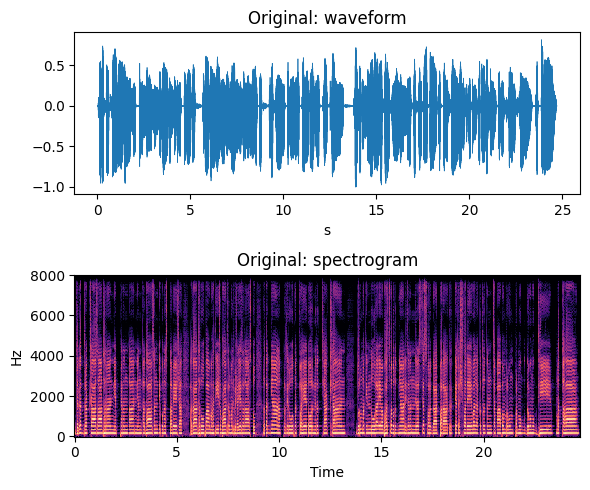

Language evidence
Table 1


language_resolution_source,acoustic_language_hint,sarvam_language_candidate,routing_dominant_script,language_routing_warning
acoustic_lid_script_consistent,sa,en,Devanagari,"Language evidence disagreement: hosted=en, acoustic=sa, script=Devanagari; routed to sa. Review against the recording; script alone is not proof."


Transcripts
Table 2


model_key,status,latency_s,rtf,wer,wer_norm,hypothesis
sarvam-saaras-v3,ok,1.626593,0.065827,1.000000,1.000000,जगद्रक्षासाधनान्यप्यनंतान्यन्तधासन्ति पुनस्तवेष अगाधरूपामहती शुभाचर्मद्विषयेसदास्तु हृतज्ञानप्रतिरूपत्वहेतोर्निरुथ्याख्यान् दुर्मतिन्दूरएवभस्वदुर्ज्ञानिजनन्निरस्यस्वर्गात्पराकृत्यचश्वदेवदकृतृतञ्चपापंप्रमुग्धिमत्तः
whisper-large-v3-turbo,ok,1.493805,0.060453,0.888889,0.888889,जगद्रक्षासाधनान्यप्यनंतान्यंतधासंति पुनस्तवेष अगाधरूपा महतीशु भाचर्मद्विषये सदास्तु रतज्ञान प्रतिरूपत्वहेतुर निरत्याक्षान दुर्मतिंदूर एवभस्व दुर्ध्यानिजननिरस्यस्वर्गात्परा कृत्या चश्वदेवद्दकृत्रतंच पापं प्रमुप्रमुग्रमुग्धि मत्तः
indic-conformer-600m-ctc,ok,0.913104,0.036953,0.703704,0.703704,जगद्रक्षासाधनान्यप्यनन्तान्यन्तधा सन्ति पुनस्तवेष अगाधरूपा महती शुभाचर्मद्विषये सदास्तु ऋतज्ञानप्रतिरूपत्वहेतोर्निरुत्याख्यान् दुर्मतिन्दूर एव भस्वदुर्ज्ञानिजनन्निरस्य स्वर्गात् पराकृत्य चश्वदेवदकृत्रतं च पापं प्रमुं प्रमुग्रमुमुग्धी मत्तः
indic-conformer-600m-rnnt,ok,1.335944,0.054065,0.814815,0.814815,जगद्रक्षासाधनान्यप्यनन्तान्यन्तधा सन्ति पुनस्तवेष अगाधरूपा महती शुभाचर्मद्विषये सदास्तु ऋतज्ञानप्रतिरूपत्वहेतोर्निरुत्याख्यान् दुर्मतिन्दूर एव भस्वदुर्ज्ञानिजनन्निरस्य स्वर्गात्पराकृत्य चश्वदेवदकृत्रञ्च पापं प्रमुं प्रमुग्रमुग्धी मत्तः
koyal-hi-120m,unsupported,,,,,
sravaani-1.0,ok,1.561922,0.063210,0.777778,0.777778,जगद्रक्षासाधनान्यप्यनन्तान्यन्तधा सन्ति पुनस्तवेष अगाधरूपा महतीशुभाचर्मद्विषये सदास्तु ऋतज्ञानप्रतिरूपत्वहेतोर्निरुथ्याख्यान् दुर्मतिन्दूर एव भस्वदुर्ज्ञा निजनन्निरस्य स्वर्गात् पराकृत्य चश्वदेव दकृतृतञ्च पापं प्रमु प्रमुग् गृमुमुग्धी मत्तः


Dropdown(description='ASR source', options=(('sarvam-saaras-v3', 'जगद्रक्षासाधनान्यप्यनंतान्यन्तधासन्ति पुनस्त…

Textarea(value='जगद्रक्षासाधनान्यप्यनंतान्यन्तधासन्ति पुनस्तवेष अगाधरूपामहती शुभाचर्मद्विषयेसदास्तु हृतज्ञानप्…

... (2 outputs left out)

Reference: जगद्रक्षासाधनान्यप्यनन्तान्यनन्तधा सन्ति पुनस्तवेश अगाधरूपा महती शुभा च मतिर्मम त्वद्विषये सदा स्तु ऋतज्ञानप्रतिरूपत्वहेतोर्निर्ऋत्याख्यां दुर्मतिं दूर एव बाधस्व दुर्ज्ञानिजनं निरस्य स्वर्गात् पराकृत्य च शश्वदेव कृतं च पापं प्रमुमुग्धि मत्तः
Table 3


engine_key,status,source_text_type,source_chars,comparison_chars,truncated_to_limit,duration_s,latency_s,rtf,error
sarvam-bulbul-v3,unsupported,gold_reference,241,241,False,,,,No configured support for Sanskrit in Sarvam Bulbul v3 [priya]
indic-parler-tts,ok,gold_reference,241,241,False,23.857574,49.606972,2.079297,
meta-mms-tts,unsupported,gold_reference,241,241,False,,,,No validated Sanskrit MMS checkpoint configured; use Indic Parler Aryan


TTS sarvam-bulbul-v3: unsupported
TTS indic-parler-tts: ok
TTS indic-parler-tts: 20261022T053451317230Z_4d78a709_tts_indic_parler.wav — full audio, 23.9s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T053451317230Z_4d78a709_tts_indic_parler.wav


TTS meta-mms-tts: unsupported
File 2/3: script_03_hinglish.mp3 | language: hi
Denoising: not_needed | reason: Measured quality/SNR above enhancement thresholds | snr_scope=n/a, snr_before_db=69.0, snr_after_db=69.0, denoise_candidate_snr_db=n/a, candidate_snr_improvement_db=n/a, accepted_snr_improvement_db=0.0, denoise_snr_threshold_db=20.0, min_noise_seconds_for_snr=0.5
Original
Original: 20261022T053817295084Z_ea4615bb_original_decoded.wav — full audio, 17.2s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T053817295084Z_ea4615bb_original_decoded.wav


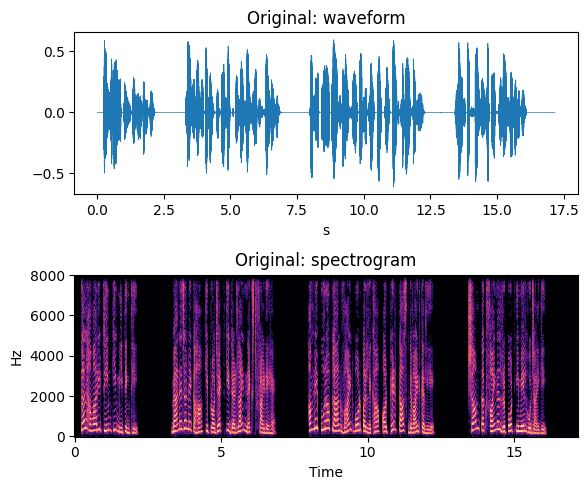

Language evidence
Table 4


language_resolution_source,acoustic_language_hint,sarvam_language_candidate,routing_dominant_script,language_routing_warning
acoustic_lid_script_consistent,hi,hi,Devanagari,


Transcripts
Table 5


model_key,status,latency_s,rtf,wer,wer_norm,hypothesis
sarvam-saaras-v3,ok,1.507711,0.087785,0.057143,0.057143,कल हमारी टीम की मीटिंग थी। मैनेजर ने कहा कि प्रोजेक्ट की डेडलाइन नेक्स्ट फ्राइडे है। हमने पूरा प्लान वाइट बोर्ड पर लिखा और फिर टास्क डिवाइड कर लिए। शाम तक फाइनल रिपोर्ट ईमेल हो जाएगी।
whisper-large-v3-turbo,ok,1.080512,0.062912,0.085714,0.085714,कल हमारी टीम की मीटिंग थी. मैनेजर ने कहा कि प्रोजेक्ट की डेडलाइन नेक्स्ट फ्राइडे है. हमने पूरा प्लान वाइट बोर्ड पर लिखा और फिर टास्क डिवाइड कर लिए. शाम तक फाइनल रिपोर्ट इमेल हो जाएगी.
indic-conformer-600m-ctc,ok,0.877308,0.051081,0.057143,0.057143,कल हमारी टीम की मीटिंग थी मैनेजर ने कहा कि प्रोजेक्ट की डेडलाइन नेक्स्ट फ्राइडे है हमने पूरा प्लान व्हाइट बोर्ड पर लिखा और फिर टास्क डिवाइड कर लिए शाम तक फाइनल रिपोर्ट ईमेल हो जाएगी
indic-conformer-600m-rnnt,ok,1.251322,0.072857,0.057143,0.057143,कल हमारी टीम की मीटिंग थी मैनेजर ने कहा कि प्रोजेक्ट की डेडलाइन नेक्स्ट फ्राइडे है हमने पूरा प्लान व्हाइट बोर्ड पर लिखा और फिर टास्क डिवाइड कर लिए शाम तक फाइनल रिपोर्ट ईमेल हो जाएगी
koyal-hi-120m,ok,0.748988,0.043609,0.028571,0.028571,कल हमारी टीम की मीटिंग थी। मैनेजर ने कहा कि प्रोजेक्ट की डेडलाइन नेक्स्ट फ्राइडे है। हमने पूरा प्लान व्हाइटबोर्ड पर लिखा और फिर टास्क डिवाइड कर लिए। शाम तक फाइनल रिपोर्ट ईमेल हो जाएगी।
sravaani-1.0,ok,1.412290,0.082229,0.057143,0.057143,कल हमारी टीम की मीटिंग थी मैनेजर ने कहा कि प्रोजेक्ट की डेडलाइन नेक्स्ट फ़्राइडे है हमने पूरा प्लान व्हाइट बोर्ड पर लिखा और फिर टास्क डिवाइड कर लिए शाम तक फ़ाइनल रिपोर्ट ईमेल हो जाएगी


Dropdown(description='ASR source', options=(('sarvam-saaras-v3', 'कल हमारी टीम की मीटिंग थी। मैनेजर ने कहा कि …

Textarea(value='कल हमारी टीम की मीटिंग थी। मैनेजर ने कहा कि प्रोजेक्ट की डेडलाइन नेक्स्ट फ्राइडे है। हमने पूरा…

... (4 outputs left out)

TTS sarvam-bulbul-v3: ok
TTS sarvam-bulbul-v3: 20261022T053817295084Z_ea4615bb_tts_sarvam_bulbul.wav — full audio, 14.2s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T053817295084Z_ea4615bb_tts_sarvam_bulbul.wav


TTS indic-parler-tts: ok
TTS indic-parler-tts: 20261022T053817295084Z_ea4615bb_tts_indic_parler.wav — full audio, 16.0s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T053817295084Z_ea4615bb_tts_indic_parler.wav


TTS meta-mms-tts: ok
TTS meta-mms-tts: 20261022T053817295084Z_ea4615bb_tts_meta_mms.wav — full audio, 13.8s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T053817295084Z_ea4615bb_tts_meta_mms.wav


File 3/3: common_voice_hi_23795247.mp3 | language: hi
Denoising: not_needed | reason: Measured quality/SNR above enhancement thresholds | snr_scope=n/a, snr_before_db=51.3, snr_after_db=51.3, denoise_candidate_snr_db=n/a, candidate_snr_improvement_db=n/a, accepted_snr_improvement_db=0.0, denoise_snr_threshold_db=20.0, min_noise_seconds_for_snr=0.5
Original
Original: 20261022T054451810507Z_8f37805d_original_decoded.wav — full audio, 3.0s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T054451810507Z_8f37805d_original_decoded.wav


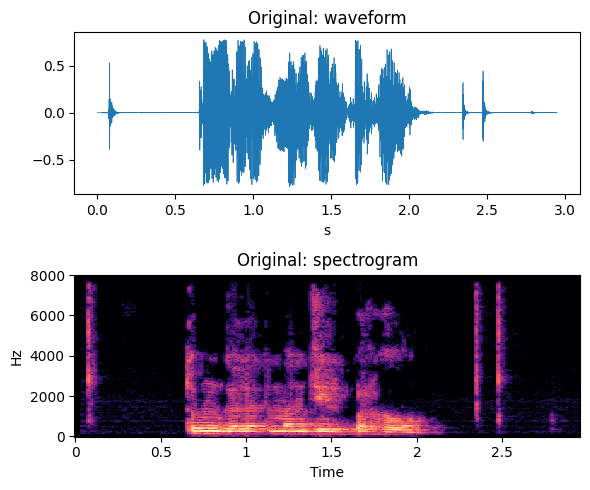

Language evidence
Table 7


language_resolution_source,acoustic_language_hint,sarvam_language_candidate,routing_dominant_script,language_routing_warning
hosted_label_script_consistent,,hi,Devanagari,


Transcripts
Table 8


model_key,status,latency_s,rtf,wer,wer_norm,hypothesis
sarvam-saaras-v3,ok,1.177484,0.398877,0.0,0.0,तुम गलत मंजिल पर हो
whisper-large-v3-turbo,ok,0.166792,0.056501,0.2,0.2,तुम गलत मन्जील पर हो
indic-conformer-600m-ctc,ok,0.901917,0.305527,0.0,0.0,तुम गलत मंजिल पर हो
indic-conformer-600m-rnnt,ok,0.936368,0.317198,0.0,0.0,तुम गलत मंजिल पर हो
koyal-hi-120m,ok,0.625945,0.212041,0.0,0.0,तुम ग़लत मंज़िल पर हो।
sravaani-1.0,ok,1.341191,0.454333,0.0,0.0,तुम ग़लत मंज़िल पर हो


Dropdown(description='ASR source', options=(('sarvam-saaras-v3', 'तुम गलत मंजिल पर हो'), ('whisper-large-v3-tu…

Textarea(value='तुम गलत मंजिल पर हो', description='TTS text', layout=Layout(height='150px', width='100%'))

... (3 outputs left out)

engine_key,status,source_text_type,source_chars,comparison_chars,truncated_to_limit,duration_s,latency_s,rtf,error
sarvam-bulbul-v3,ok,gold_reference,20,20,False,1.706667,1.376924,0.806792,
indic-parler-tts,ok,gold_reference,20,20,False,2.066576,4.714552,2.281335,
meta-mms-tts,ok,gold_reference,20,20,False,2.048000,0.157742,0.077023,


TTS sarvam-bulbul-v3: ok
TTS sarvam-bulbul-v3: 20261022T054451810507Z_8f37805d_tts_sarvam_bulbul.wav — full audio, 1.7s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T054451810507Z_8f37805d_tts_sarvam_bulbul.wav


TTS indic-parler-tts: ok
TTS indic-parler-tts: 20261022T054451810507Z_8f37805d_tts_indic_parler.wav — full audio, 2.1s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T054451810507Z_8f37805d_tts_indic_parler.wav


TTS meta-mms-tts: ok
TTS meta-mms-tts: 20261022T054451810507Z_8f37805d_tts_meta_mms.wav — full audio, 2.0s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T054451810507Z_8f37805d_tts_meta_mms.wav


In [ ]:
"""Per-file view: audio, waveform, spectrogram, language evidence, transcripts and generated speech."""
import librosa
import librosa.display
import matplotlib.pyplot as plt
from IPython.display import Audio

FILE_TO_VIEW = None


def render_v13_file_view(contexts, manifest):
    runs = [(run, Path(directory)) for _, run, directory in contexts]
    if not runs:
        print('No saved runs.')
        return
    for index, (run, directory) in enumerate(runs):
        print(f"File {index + 1}/{len(runs)}: {run.get('file')} | language: {run.get('language_effective', '')}")
        paths = run.get('audio_paths') or {}
        bundle = directory / 'v13_clean_bundle.json'
        clean_report = json.loads(bundle.read_text(encoding='utf-8')) if bundle.exists() else {}
        clean = clean_report.get('clean_audio')
        # The denoising decision is recorded in preprocess_metrics.csv for every run. The clean-export bundle is
        # optional (and off for thesis runs), so it must not be the source of this line.
        pre = _read_csv_if_exists(directory / 'preprocess_metrics.csv')
        reason = ''
        if len(pre) and 'denoise_reason' in pre.columns and pd.notna(pre['denoise_reason'].iloc[0]):
            reason = str(pre['denoise_reason'].iloc[0])
        snr = ''
        snr_cols = [c for c in pre.columns if 'snr' in c.lower()] if len(pre) else []
        if snr_cols:
            snr = ' | ' + ', '.join(f"{c}={pre[c].iloc[0]:.1f}" if isinstance(pre[c].iloc[0], (int, float, np.number)) and pd.notna(pre[c].iloc[0])
                                    else f'{c}=n/a' for c in snr_cols)
        print('Denoising:', _denoise_decision(directory), f'| reason: {reason or "not recorded"}{snr}')
        if clean_report:
            print('Clean-export bundle:', clean_report.get('source_selection', ''), '| enhancement applied:',
                  clean_report.get('enhancement_applied', ''))
        if clean_report.get('transcript'):
            print('Delivered-audio transcript:', clean_report['transcript'])
        signals = [(label, path) for label, path in (('Original', paths.get('original')), ('Delivered clean', clean))
                   if path and Path(path).exists()]
        for label, path in signals:
            print(label)
            _show_audio_path(label, path)
        if len(signals) == 2:
            first, first_sr = load_audio_any(signals[0][1], 16000)
            second, second_sr = load_audio_any(signals[1][1], 16000)
            if first.shape == second.shape and np.array_equal(first, second):
                signals = [('Original / processed (identical samples)', signals[0][1])]
            del first, second
        if signals:
            fig, axes = plt.subplots(2, len(signals), figsize=(6 * len(signals), 5), squeeze=False)
            for column, (label, path) in enumerate(signals):
                y, sr = load_audio_any(path, 16000)
                t = np.arange(len(y)) / sr
                axes[0, column].plot(t, y, linewidth=0.5)
                axes[0, column].set(title=f'{label}: waveform', xlabel='s')
                spec = librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=512, hop_length=160)), ref=np.max)
                librosa.display.specshow(spec, sr=sr, hop_length=160, x_axis='time', y_axis='hz', ax=axes[1, column])
                axes[1, column].set(title=f'{label}: spectrogram')
            plt.tight_layout()
            plt.show()
            plt.close(fig)
        asr = _read_csv_if_exists(directory / 'asr_results.csv')
        if len(asr):
            evidence = [c for c in ('language_resolution_source', 'acoustic_language_hint', 'sarvam_language_candidate',
                                    'routing_dominant_script', 'language_routing_warning') if c in asr]
            print('Language evidence')
            _display_static_table(asr[evidence].head(1), index=False)
            columns = [c for c in ('model_key', 'status', 'latency_s', 'rtf', 'wer', 'wer_norm', 'hypothesis') if c in asr]
            print('Transcripts')
            _display_static_table(asr[columns], index=False)
        if len(asr) and 'hypothesis' in asr:
            import ipywidgets as widgets
            successful = asr[asr.status.eq('ok') & asr.hypothesis.fillna('').astype(str).str.strip().ne('')]
            if len(successful):
                options = [(str(row.get('model_key')), str(row.get('hypothesis'))) for row in successful.to_dict('records')]
                selector = widgets.Dropdown(options=options, description='ASR source')
                editor = widgets.Textarea(value=selector.value, description='TTS text', layout=widgets.Layout(width='100%', height='150px'))
                selector.observe(lambda change, target=editor: setattr(target, 'value', change['new']), names='value')
                button = widgets.Button(description='Speak edited text')
                result_panel = widgets.Output()
                def regenerate(_, editor=editor, run=run, directory=directory, button=button, panel=result_panel):
                    with panel:
                        panel.clear_output(wait=True)
                        button.disabled = True
                        try:
                            language = run.get('language_effective')
                            meta = choose_tts_comparison_text(editor.value, '', False, language, SAARAS_MODE)
                            rows, paths = run_tts_comparison(meta, str(run.get('run_id')) + '_edited', language)
                            _display_static_table(rows[[c for c in ['engine_key','status','duration_s','latency_s','comparison_chars','error'] if c in rows]], index=False)
                            for item in rows.to_dict('records'):
                                if item.get('status') == 'ok' and Path(str(item.get('wav_path', ''))).is_file():
                                    display(Audio(filename=item['wav_path']))
                        except Exception as exc:
                            print('Synthesis failed:', type(exc).__name__, str(exc))
                        finally:
                            button.disabled = False
                button.on_click(regenerate)
                display(selector, editor, button, result_panel)
        reference = directory / 'reference.txt'
        if reference.exists():
            print('Reference:', reference.read_text(encoding='utf-8'))
        tts = _read_csv_if_exists(directory / 'tts_comparison.csv')
        if len(tts):
            _display_static_table(tts[[c for c in ['engine_key','status','source_text_type','source_chars','comparison_chars','truncated_to_limit','duration_s','latency_s','rtf','error'] if c in tts]], index=False)
        for row in tts.to_dict('records'):
            path = str(row.get('wav_path', ''))
            print(f"TTS {row.get('engine_key')}: {row.get('status')}")
            if row.get('status') == 'ok' and path and Path(path).exists():
                _show_audio_path(f"TTS {row.get('engine_key')}", path)


run_visible_section('render_v13_file_view')


### Section 1 — Original audio and normalization


In [ ]:
"""Displays original and normalized audio metrics, previews, and diagnostic figures."""

def render_section_01_input_audio(contexts=None, manifest=None):
    manifest, contexts = _resolve_contexts(contexts, manifest)
    _show_csv_for_runs(contexts, 'input_metrics.csv', transpose_single=True)
    _show_audio_for_runs(
        contexts, 'Original audio',
        lambda run: (run.get('audio_paths') or {}).get('original'),
    )
    _show_audio_for_runs(
        contexts, 'Normalized audio',
        lambda run: (run.get('audio_paths') or {}).get('normalized'),
    )
    _show_figures_for_runs(contexts, ['waveform_vad', 'logmel_before_after'])


run_visible_section('render_section_01_input_audio')


Using newest attempted batch: batch_20261022T053451067322Z
Table 1


file_index,file,duration_s,sample_rate_hz,original_rms_dbfs,normalized_rms_dbfs,original_peak_dbfs,normalized_peak_dbfs,language_requested,sarvam_mode,whisper_code_mix_mode,local_neural_inference_device,cuda_device_name,audio_lid_internal_code,language_effective
1,480a8c8b8def90b4.wav,24.710,16000,-14.528419,-20.0,0.158520,-5.313061,auto,codemix,True,cuda,NVIDIA A100-SXM4-80GB,sa,sa
2,script_03_hinglish.mp3,17.175,16000,-21.314599,-20.0,-4.291585,-2.976986,auto,codemix,True,cuda,NVIDIA A100-SXM4-80GB,hi,hi
3,common_voice_hi_23795247.mp3,2.952,16000,-14.989786,-20.0,-2.044572,-7.054785,auto,codemix,True,cuda,NVIDIA A100-SXM4-80GB,,hi



FILE 1: 480a8c8b8def90b4.wav
Original audio: 20261022T053451317230Z_4d78a709_original_decoded.wav — full audio, 24.7s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T053451317230Z_4d78a709_original_decoded.wav



FILE 2: script_03_hinglish.mp3
Original audio: 20261022T053817295084Z_ea4615bb_original_decoded.wav — full audio, 17.2s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T053817295084Z_ea4615bb_original_decoded.wav



FILE 3: common_voice_hi_23795247.mp3
Original audio: 20261022T054451810507Z_8f37805d_original_decoded.wav — full audio, 3.0s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T054451810507Z_8f37805d_original_decoded.wav



FILE 1: 480a8c8b8def90b4.wav
Normalized audio: 20261022T053451317230Z_4d78a709_normalized.wav — full audio, 24.7s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T053451317230Z_4d78a709_normalized.wav



FILE 2: script_03_hinglish.mp3
Normalized audio: 20261022T053817295084Z_ea4615bb_normalized.wav — full audio, 17.2s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T053817295084Z_ea4615bb_normalized.wav



FILE 3: common_voice_hi_23795247.mp3
Normalized audio: 20261022T054451810507Z_8f37805d_normalized.wav — full audio, 3.0s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T054451810507Z_8f37805d_normalized.wav



FILE 1: 480a8c8b8def90b4.wav
Inline figures are rendered in the per-file/audio sections. This notebook does not save plot-image files.

FILE 2: script_03_hinglish.mp3
Inline figures are rendered in the per-file/audio sections. This notebook does not save plot-image files.

FILE 3: common_voice_hi_23795247.mp3
Inline figures are rendered in the per-file/audio sections. This notebook does not save plot-image files.


### Section 2 — VAD and adaptive denoising


In [ ]:
"""Displays VAD, denoising decisions, SNR changes, and processed audio."""

def render_section_02_vad_denoise(contexts=None, manifest=None):
    manifest, contexts = _resolve_contexts(contexts, manifest)
    _show_csv_for_runs(contexts, 'preprocess_metrics.csv', transpose_single=True)

    changed = [c for c in contexts if _denoise_changed_audio(c[2])]
    if contexts and not changed:
        print(
            '\nDenoising altered no file in this batch, so every "processed" '
            'waveform below is the original waveform with level normalization '
            'only. The denoise_decision and denoise_reason columns above give '
            'the per-file reason.'
        )
    elif contexts and len(changed) < len(contexts):
        print(
            f'\nDenoising altered {len(changed)} of {len(contexts)} file(s). '
            'For the remainder the processed waveform equals the original.'
        )

    _show_audio_for_runs(
        contexts, 'Denoised / processed audio',
        lambda run: (run.get('audio_paths') or {}).get('denoised'),
    )


run_visible_section('render_section_02_vad_denoise')


Using newest attempted batch: batch_20261022T053451067322Z
Table 1


file_index,file,output_label,enhancement_wall_s,snr_scope,vad_segments,speech_s,silence_s,snr_before_db,snr_after_db,denoise_candidate_snr_db,candidate_snr_improvement_db,accepted_snr_improvement_db,noise_available_s,denoise_snr_threshold_db,denoise_strength,denoise_min_required_improvement_db,min_noise_seconds_for_snr,selected_rms_before_output_normalization_dbfs,selected_peak_before_output_normalization_dbfs,output_rms_dbfs,output_peak_dbfs,output_level_gain_db,output_level_normalization_applied,denoise_decision,denoise_reason
1,480a8c8b8def90b4.wav,normalized—enhancement not needed,2.653486,VAD/frame power estimate; not clean-reference SNR,2,24.598,0.112,,,,,,0.112,20.0,0.6,1.0,0.5,-20.0,-5.313061,-20.0,-5.313061,0.0,False,not_needed,Measured quality/SNR above enhancement thresholds
2,script_03_hinglish.mp3,normalized—enhancement not needed,1.320588,VAD/frame power estimate; not clean-reference SNR,4,13.600,3.575,69.030710,69.030710,,,0.0,3.575,20.0,0.6,1.0,0.5,-20.0,-2.976986,-20.0,-2.976986,0.0,False,not_needed,Measured quality/SNR above enhancement thresholds
3,common_voice_hi_23795247.mp3,normalized—enhancement not needed,0.525950,VAD/frame power estimate; not clean-reference SNR,1,1.712,1.240,51.282344,51.282344,,,0.0,1.240,20.0,0.6,1.0,0.5,-20.0,-7.054785,-20.0,-7.054785,0.0,False,not_needed,Measured quality/SNR above enhancement thresholds



Denoising altered no file in this batch, so every "processed" waveform below is the original waveform with level normalization only. The denoise_decision and denoise_reason columns above give the per-file reason.

FILE 1: 480a8c8b8def90b4.wav
Denoised / processed audio: 20261022T053451317230Z_4d78a709_denoised_asr_input.wav — full audio, 24.7s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T053451317230Z_4d78a709_denoised_asr_input.wav



FILE 2: script_03_hinglish.mp3
Denoised / processed audio: 20261022T053817295084Z_ea4615bb_denoised_asr_input.wav — full audio, 17.2s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T053817295084Z_ea4615bb_denoised_asr_input.wav



FILE 3: common_voice_hi_23795247.mp3
Denoised / processed audio: 20261022T054451810507Z_8f37805d_denoised_asr_input.wav — full audio, 3.0s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T054451810507Z_8f37805d_denoised_asr_input.wav


### Section 3 — Language ID and acoustic features


In [ ]:
"""Displays language-identification diagnostics and cross-file acoustic features."""

def render_section_03_language_acoustics(contexts=None, manifest=None):
    manifest, contexts = _resolve_contexts(contexts, manifest)
    print('Acoustic language-ID diagnostic — one row per uploaded audio file')
    _show_compact_section_for_runs(contexts, '03_language_id')
    print('\nAcoustic features — direct cross-file comparison')
    return _show_csv_for_runs(contexts, 'audio_features.csv', transpose_single=True)


run_visible_section('render_section_03_language_acoustics')


Using newest attempted batch: batch_20261022T053451067322Z
Acoustic language-ID diagnostic — one row per uploaded audio file
Table 1


file_index,file,audio_lid,primary_language,languages_present,code_mix_detected,code_mix_policy,audio_lid_score,audio_lid_score_type,audio_lid_device,audio_lid_total_s,audio_lid_probe_s,audio_lid_coverage_ratio,audio_lid_scope,status,audio_lid_internal_code
1,480a8c8b8def90b4.wav,sa,sa,[sa],False,evidence only; routing runs every supported model and flags,0.5,fraction of accepted windows; not probability,cuda,24.710,24.710,1.0,"overlapping windows; coarse evidence, not exact word boundaries",provisional,sa
2,script_03_hinglish.mp3,hi,hi,[hi],False,evidence only; routing runs every supported model and flags,1.0,fraction of accepted windows; not probability,cuda,17.175,17.175,1.0,"overlapping windows; coarse evidence, not exact word boundaries",provisional,hi
3,common_voice_hi_23795247.mp3,unknown,unknown,[],False,evidence only; routing runs every supported model and flags,0.0,fraction of accepted windows; not probability,cuda,2.952,2.952,1.0,"overlapping windows; coarse evidence, not exact word boundaries",needs_review,


Language evidence by audio segment
Table 2


file,start_s,end_s,language,whisper_language,text,warning,acoustic_language,model_score,score_margin,score_type
480a8c8b8def90b4.wav,0.000,4.000,sa,unknown,,confident acoustic window; Whisper probe skipped,sa,0.999869,0.999753,softmax score; Hindi+Urdu merged
480a8c8b8def90b4.wav,2.000,6.000,sa,unknown,,confident acoustic window; Whisper probe skipped,sa,0.999231,0.998597,softmax score; Hindi+Urdu merged
480a8c8b8def90b4.wav,4.000,8.000,sa,unknown,,confident acoustic window; Whisper probe skipped,sa,0.972277,0.953129,softmax score; Hindi+Urdu merged
480a8c8b8def90b4.wav,6.000,10.000,sa,unknown,,confident acoustic window; Whisper probe skipped,sa,0.976804,0.958506,softmax score; Hindi+Urdu merged
480a8c8b8def90b4.wav,8.000,12.000,unknown,id,Sadaastu Ratak Dhyana Pratirupat Vahetor Nirat,Acoustic/ASR language disagreement; review required,sa,0.801189,0.726757,softmax score; Hindi+Urdu merged
480a8c8b8def90b4.wav,10.000,14.000,unknown,id,Pertirupatwa hetor niradhyak khan Durmajara,Acoustic/ASR language disagreement; review required,hi,0.602258,0.411508,softmax score; Hindi+Urdu merged
480a8c8b8def90b4.wav,12.000,16.000,unknown,en,Durmatindura eva bhaswadurjnayamadha,Acoustic/ASR language disagreement; review required,sa,0.857552,0.735954,softmax score; Hindi+Urdu merged
480a8c8b8def90b4.wav,14.000,18.000,sa,unknown,,confident acoustic window; Whisper probe skipped,sa,0.992091,0.988946,softmax score; Hindi+Urdu merged
480a8c8b8def90b4.wav,16.000,20.000,sa,unknown,,confident acoustic window; Whisper probe skipped,sa,0.993870,0.989997,softmax score; Hindi+Urdu merged
480a8c8b8def90b4.wav,18.000,22.000,unknown,id,Kretya Chashwadeva da Kretel Tanca Papam Pramogulamaya,Acoustic/ASR language disagreement; review required,sa,0.665076,0.527468,softmax score; Hindi+Urdu merged



Acoustic features — direct cross-file comparison
Table 3


file_index,file,duration_s,acoustic_feature_scope,rhythm_reliability,raw_f0_cross_speaker_note,speech_s,silence_s,speech_ratio,pause_ratio,vad_segments,rms_dbfs,peak_dbfs,clipping_ratio,snr_before_db,snr_after_db,zcr_mean,spectral_centroid_hz,spectral_bandwidth_hz,spectral_rolloff_hz,f0_mean_hz,f0_std_hz,f0_source
1,480a8c8b8def90b4.wav,24.710,descriptive_only,descriptive_only: short recording or fewer than 3 VAD segments,speaker-dependent; use semitone-normalized prosody metrics for cross-speaker comparison,24.598,0.112,0.995467,0.004533,2,-20.0,-5.313061,0.0,,,0.088932,1244.901319,1254.098371,2355.582524,168.292134,10.330622,dedicated_prosody_pyin
2,script_03_hinglish.mp3,17.175,descriptive,descriptive_multi-segment_recording,speaker-dependent; use semitone-normalized prosody metrics for cross-speaker comparison,13.600,3.575,0.791849,0.208151,4,-20.0,-2.976986,0.0,69.030710,69.030710,0.135555,1717.328435,1439.816517,3071.249272,266.638479,67.680670,dedicated_prosody_pyin
3,common_voice_hi_23795247.mp3,2.952,descriptive_only,descriptive_only: short recording or fewer than 3 VAD segments,speaker-dependent; use semitone-normalized prosody metrics for cross-speaker comparison,1.712,1.240,0.579946,0.420054,1,-20.0,-7.054785,0.0,51.282344,51.282344,0.150693,1629.760753,1344.638679,2975.506757,121.685969,10.049569,dedicated_prosody_pyin


### Section 4 — Prosody, pitch, rhythm and voice quality


Research output enabled; availability depends on the uploaded data and model access.


In [ ]:
"""Displays original and processed prosody, preservation metrics, and contours."""

PROSODY_DISPLAY_COLUMNS = [
    'f0_mean_hz','f0_median_hz','f0_std_hz','f0_range_semitones',
    'voiced_frame_ratio_speech','energy_std_db','energy_dynamic_range_db',
    'internal_pause_ratio','speech_segment_npvi','speaking_rate_wps',
    'articulation_rate_wps','jitter_local_pct','shimmer_local_pct','hnr_mean_db',
    'voice_quality_method'
]

def render_section_04_prosody(contexts=None, manifest=None):
    manifest, contexts = _resolve_contexts(contexts, manifest)
    changed = [c for c in contexts if _denoise_changed_audio(c[2])]
    hide_duplicates = bool(HIDE_REDUNDANT_DENOISE_OUTPUT)

    frames = []
    for file_index, run, run_dir in contexts:
        original = _read_csv_if_exists(run_dir / 'prosody_metrics_original.csv')
        processed = _read_csv_if_exists(run_dir / 'prosody_metrics_denoised.csv')
        if len(original):
            original['source'] = 'Original/natural'
        if len(processed):
            if _denoise_changed_audio(run_dir):
                processed['source'] = 'Denoised/processed'
            elif hide_duplicates:
                processed = processed.iloc[0:0]
            else:
                processed['source'] = 'Processed (unchanged — denoising skipped)'
        frame = pd.concat([original, processed], ignore_index=True)
        if len(frame):
            frame.insert(0, 'file', run.get('file', ''))
            frame.insert(0, 'file_index', file_index + 1)
            frames.append(frame)

    prosody = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    if len(prosody):
        _display_static_table(
            prosody[[
                c for c in ['file_index', 'file', 'source'] + PROSODY_DISPLAY_COLUMNS
                if c in prosody.columns
            ]],
            index=False,
        )
        if contexts and not changed:
            print(
                '   note: processed pitch/timing may match the original, but normalization can change energy — '
                'denoising altered no file in this batch.'
            )
    else:
        print('No saved prosody rows across files.')

    preservation_contexts = contexts if not hide_duplicates else changed
    if preservation_contexts:
        print('\nProsody preservation after preprocessing')
        _show_csv_for_runs(
            preservation_contexts,
            'prosody_preservation_original_vs_processed.csv',
            transpose_single=True,
        )
        if not changed:
            print(
                '   note: unchanged pitch/timing does not imply unchanged energy; inspect normalization level shifts, '
                'because denoising was not applied to any file.'
            )
    else:
        print(
            '\nProsody preservation table hidden by HIDE_REDUNDANT_DENOISE_OUTPUT: '
            'denoising altered no file, so every ratio is exactly 1.0.'
        )

    _show_figures_for_runs(contexts, [
        'original_f0', 'original_energy', 'original_combined',
    ])
    contour_contexts = contexts if not hide_duplicates else changed
    if contour_contexts:
        print('\nProcessed-audio contours')
        if not changed:
            print(
                '   note: these plot the same waveform as the original contours '
                'above — denoising was not applied to any file.'
            )
        _show_figures_for_runs(contour_contexts, [
            'denoised_f0', 'denoised_energy', 'denoised_combined',
        ])
    else:
        print(
            '\nProcessed-audio contours hidden by HIDE_REDUNDANT_DENOISE_OUTPUT: '
            'they plot the same waveform as the original contours above.'
        )
    return prosody


run_visible_section('render_section_04_prosody')


Using newest attempted batch: batch_20261022T053451067322Z
Table 1


file_index,file,source,f0_mean_hz,f0_median_hz,f0_std_hz,f0_range_semitones,voiced_frame_ratio_speech,energy_std_db,energy_dynamic_range_db,internal_pause_ratio,speech_segment_npvi,speaking_rate_wps,articulation_rate_wps,jitter_local_pct,shimmer_local_pct,hnr_mean_db,voice_quality_method
1,480a8c8b8def90b4.wav,Original/natural,168.292134,169.625383,10.330622,3.416383,0.787052,11.210738,37.279214,0.000000,20.505732,1.092675,1.097650,2.064428,6.513944,16.088817,Praat/Parselmouth
1,480a8c8b8def90b4.wav,Processed (unchanged — denoising skipped),168.292134,169.625383,10.330622,3.416383,0.787052,11.210738,37.279209,0.000000,20.505732,1.092675,1.097650,2.064428,6.513944,16.088817,Praat/Parselmouth
2,script_03_hinglish.mp3,Original/natural,266.638479,258.989003,67.680670,14.602549,0.710294,19.053820,73.167165,0.149985,37.229797,2.037846,2.573529,1.966862,6.904340,14.904981,Praat/Parselmouth
2,script_03_hinglish.mp3,Processed (unchanged — denoising skipped),266.638479,258.989003,67.680670,14.602549,0.710294,19.053820,73.167167,0.149985,37.229797,2.037846,2.573529,1.966862,6.904340,14.904981,Praat/Parselmouth
3,common_voice_hi_23795247.mp3,Original/natural,121.685969,123.471571,10.049569,4.034388,0.784884,16.921865,57.956803,0.000000,,1.693767,2.920561,1.924447,13.507330,9.582474,Praat/Parselmouth
3,common_voice_hi_23795247.mp3,Processed (unchanged — denoising skipped),121.685969,123.471571,10.049569,4.034388,0.784884,16.921865,57.956805,0.000000,,1.693767,2.920561,1.924447,13.507329,9.582474,Praat/Parselmouth


   note: processed pitch/timing may match the original, but normalization can change energy — denoising altered no file in this batch.

Prosody preservation after preprocessing
Table 2


file_index,file,normalized_f0_shape_corr,normalized_energy_contour_corr,pitch_range_ratio,pause_ratio_abs_diff,voiced_ratio_abs_diff,duration_ratio,contour_comparison_valid,comparison_scope,f0_median_shift_semitones,energy_mean_shift_db
1,480a8c8b8def90b4.wav,1.0,1.000000,1.0,0.0,0.0,1.0,True,same-speaker preprocessing preservation,-1.231117e-09,-5.471579
2,script_03_hinglish.mp3,1.0,0.999995,1.0,0.0,0.0,1.0,True,same-speaker preprocessing preservation,1.022941e-09,1.314598
3,common_voice_hi_23795247.mp3,1.0,1.000000,1.0,0.0,0.0,1.0,True,same-speaker preprocessing preservation,-2.114069e-10,-5.010216


   note: unchanged pitch/timing does not imply unchanged energy; inspect normalization level shifts, because denoising was not applied to any file.

FILE 1: 480a8c8b8def90b4.wav
Inline figures are rendered in the per-file/audio sections. This notebook does not save plot-image files.

FILE 2: script_03_hinglish.mp3
Inline figures are rendered in the per-file/audio sections. This notebook does not save plot-image files.

FILE 3: common_voice_hi_23795247.mp3
Inline figures are rendered in the per-file/audio sections. This notebook does not save plot-image files.

Processed-audio contours
   note: these plot the same waveform as the original contours above — denoising was not applied to any file.

FILE 1: 480a8c8b8def90b4.wav
Inline figures are rendered in the per-file/audio sections. This notebook does not save plot-image files.

FILE 2: script_03_hinglish.mp3
Inline figures are rendered in the per-file/audio sections. This notebook does not save plot-image files.

FILE 3: common_voice_hi

### Section 5A — ASR model status


In [ ]:
"""Displays compact ASR status, device, routing, latency, and failure information."""

def render_section_05a_asr_status(contexts=None, manifest=None):
    manifest, contexts = _resolve_contexts(contexts, manifest)
    asr_saved = _show_csv_for_runs(contexts, 'asr_results.csv', [
        'model_label', 'model_role', 'decoder', 'status', 'inference_device',
        'language_effective', 'language_resolution_source',
        'sarvam_language_candidate', 'acoustic_language_hint',
        'routing_dominant_script', 'language_routing_warning',
        'latency_s', 'latency_scope', 'rtf', 'error_type', 'error',
        'model_key','hosted','selected_for_tts','tts_selection_reason',
    ])
    if len(asr_saved):
        print('Per-file ASR execution evidence')
        _display_static_table(model_execution_evidence(asr_saved, 'model_label'), index=False)
        ok_count = int((asr_saved['status'] == 'ok').sum()) if 'status' in asr_saved else 0
        file_count = int(asr_saved['file'].nunique())
        print(f'Model-file rows completed: {ok_count}/{len(asr_saved)} across {file_count} file(s).')
        status_counts = asr_saved['status'].value_counts(dropna=False).to_dict()
        print('ASR row status counts:', status_counts)
        if status_counts.get('unsupported_gpu_only_graph', 0):
            print(
                'IndicConformer was excluded by the strict GPU-only capability '
                'preflight; this is not a CUDA installation failure.'
            )
        print('Transcripts and unavailable/failure details are grouped by file in Section 5B.')
    return asr_saved


run_visible_section('render_section_05a_asr_status')


Using newest attempted batch: batch_20261022T053451067322Z
Table 1


file_index,file,model_label,model_role,decoder,status,inference_device,language_effective,language_resolution_source,sarvam_language_candidate,acoustic_language_hint,routing_dominant_script,language_routing_warning,latency_s,latency_scope,rtf,error_type,error,model_key,hosted,selected_for_tts,tts_selection_reason
1,480a8c8b8def90b4.wav,Sarvam Saaras v3 (codemix),comparison_baseline,,ok,hosted,sa,acoustic_lid_script_consistent,en,sa,Devanagari,"Language evidence disagreement: hosted=en, acoustic=sa, script=Devanagari; routed to sa. Review against the recording; script alone is not proof.",1.626593,hosted end-to-end request latency,0.065827,,,sarvam-saaras-v3,True,False,Language-supported priority for sa; no reference scores used
1,480a8c8b8def90b4.wav,OpenAI Whisper Large-v3-Turbo,comparison_baseline,seq2seq,ok,cuda,sa,acoustic_lid_script_consistent,en,sa,Devanagari,"Language evidence disagreement: hosted=en, acoustic=sa, script=Devanagari; routed to sa. Review against the recording; script alone is not proof.",1.493805,local inference latency; model loading excluded,0.060453,,,whisper-large-v3-turbo,False,False,Language-supported priority for sa; no reference scores used
1,480a8c8b8def90b4.wav,AI4Bharat IndicConformer 600M (CTC),primary_indic,ctc,ok,"cuda:onnxruntime(cuda-first, 483 cpu nodes, 99.6% kernel time on CUDA)",sa,acoustic_lid_script_consistent,en,sa,Devanagari,"Language evidence disagreement: hosted=en, acoustic=sa, script=Devanagari; routed to sa. Review against the recording; script alone is not proof.",0.913104,local inference latency; model loading excluded,0.036953,,,indic-conformer-600m-ctc,False,True,Language-supported priority for sa; no reference scores used
1,480a8c8b8def90b4.wav,AI4Bharat IndicConformer 600M (RNNT),primary_indic,rnnt,ok,"cuda:onnxruntime(cuda-first, 483 cpu nodes, 99.4% kernel time on CUDA)",sa,acoustic_lid_script_consistent,en,sa,Devanagari,"Language evidence disagreement: hosted=en, acoustic=sa, script=Devanagari; routed to sa. Review against the recording; script alone is not proof.",1.335944,local inference latency; model loading excluded,0.054065,,,indic-conformer-600m-rnnt,False,False,Language-supported priority for sa; no reference scores used
1,480a8c8b8def90b4.wav,Adalat AI Koyal Hindi 120M,comparison_baseline,TDT,unsupported,cuda,sa,acoustic_lid_script_consistent,en,sa,Devanagari,"Language evidence disagreement: hosted=en, acoustic=sa, script=Devanagari; routed to sa. Review against the recording; script alone is not proof.",,local inference latency; model loading excluded,,UnsupportedLanguage,Koyal Hindi is monolingual; requires resolved Hindi without detected code mixing.,koyal-hi-120m,False,False,Language-supported priority for sa; no reference scores used
1,480a8c8b8def90b4.wav,ARTPARK-IISc SraVaani-1.0 (TDT),comparison_baseline,TDT (auto language),ok,cuda,sa,acoustic_lid_script_consistent,en,sa,Devanagari,"Language evidence disagreement: hosted=en, acoustic=sa, script=Devanagari; routed to sa. Review against the recording; script alone is not proof.",1.561922,local inference latency; model loading excluded,0.063210,,,sravaani-1.0,False,False,Language-supported priority for sa; no reference scores used
2,script_03_hinglish.mp3,Sarvam Saaras v3 (codemix),comparison_baseline,,ok,hosted,hi,acoustic_lid_script_consistent,hi,hi,Devanagari,,1.507711,hosted end-to-end request latency,0.087785,,,sarvam-saaras-v3,True,True,Configured source or first available transcript; no reference scores used
2,script_03_hinglish.mp3,OpenAI Whisper Large-v3-Turbo,comparison_baseline,seq2seq,ok,cuda,hi,acoustic_lid_script_consistent,hi,hi,Devanagari,,1.080512,local inference latency; model loading excluded,0.062912,,,whisper-large-v3-turbo,False,False,Configured source or first available transcript; no reference scores used
2,script_03_hinglish.mp3,AI4Bharat IndicConformer 600M (CTC),primary_indic,ctc,ok,"cuda:onnxruntime(cuda-first, 483 cpu nodes, 99.5% kernel time on CUDA)",hi,acoustic_lid_script

Per-file ASR execution evidence
Table 2


file,model,enabled,status,access_verified,loaded_successfully,inference_succeeded,selected_for_tts,selection_reason,result_reason
480a8c8b8def90b4.wav,Sarvam Saaras v3 (codemix),requested in this batch,ok,successful request,not applicable: hosted,True,False,Language-supported priority for sa; no reference scores used,Inference succeeded; inspect accuracy and quality separately
480a8c8b8def90b4.wav,OpenAI Whisper Large-v3-Turbo,requested in this batch,ok,checkpoint usable,yes: successful inference evidence,True,False,Language-supported priority for sa; no reference scores used,Inference succeeded; inspect accuracy and quality separately
480a8c8b8def90b4.wav,AI4Bharat IndicConformer 600M (CTC),requested in this batch,ok,checkpoint usable,yes: successful inference evidence,True,True,Language-supported priority for sa; no reference scores used,Inference succeeded; inspect accuracy and quality separately
480a8c8b8def90b4.wav,AI4Bharat IndicConformer 600M (RNNT),requested in this batch,ok,checkpoint usable,yes: successful inference evidence,True,False,Language-supported priority for sa; no reference scores used,Inference succeeded; inspect accuracy and quality separately
480a8c8b8def90b4.wav,Adalat AI Koyal Hindi 120M,requested in this batch,unsupported,not established by this result,not established by this result,False,False,Language-supported priority for sa; no reference scores used,Koyal Hindi is monolingual; requires resolved Hindi without detected code mixing.
480a8c8b8def90b4.wav,ARTPARK-IISc SraVaani-1.0 (TDT),requested in this batch,ok,checkpoint usable,yes: successful inference evidence,True,False,Language-supported priority for sa; no reference scores used,Inference succeeded; inspect accuracy and quality separately
script_03_hinglish.mp3,Sarvam Saaras v3 (codemix),requested in this batch,ok,successful request,not applicable: hosted,True,True,Configured source or first available transcript; no reference scores used,Inference succeeded; inspect accuracy and quality separately
script_03_hinglish.mp3,OpenAI Whisper Large-v3-Turbo,requested in this batch,ok,checkpoint usable,yes: successful inference evidence,True,False,Configured source or first available transcript; no reference scores used,Inference succeeded; inspect accuracy and quality separately
script_03_hinglish.mp3,AI4Bharat IndicConformer 600M (CTC),requested in this batch,ok,checkpoint usable,yes: successful inference evidence,True,False,Configured source or first available transcript; no reference scores used,Inference succeeded; inspect accuracy and quality separately
script_03_hinglish.mp3,AI4Bharat IndicConformer 600M (RNNT),requested in this batch,ok,checkpoint usable,yes: successful inference evidence,True,False,Configured source or first available transcript; no reference scores used,Inference succeeded; inspect accuracy and quality separately


Model-file rows completed: 17/18 across 3 file(s).
ASR row status counts: {'ok': 17, 'unsupported': 1}
Transcripts and unavailable/failure details are grouped by file in Section 5B.


### Section 5B — ASR transcripts and complete errors (one model at a time)


In [ ]:
"""Displays each saved ASR transcript or complete model failure diagnostic."""

def _saved_text(value):
    if value is None:
        return ''
    try:
        if pd.isna(value):
            return ''
    except Exception:
        pass
    return str(value).strip()

def render_section_05b_transcripts(contexts=None, manifest=None):
    manifest, contexts = _resolve_contexts(contexts, manifest)
    for file_index, run, run_dir in contexts:
        asr_saved = _read_csv_if_exists(run_dir / 'asr_results.csv')
        print('\n' + '#' * 96)
        print(f"FILE {file_index + 1}: {run.get('file', '<unknown>')}")
        print('#' * 96)
        if not len(asr_saved):
            print('No saved ASR rows for this file.')
            continue
        for model_number, (_, row) in enumerate(asr_saved.iterrows(), start=1):
            label = _saved_text(row.get('model_label')) or f'Model {model_number}'
            status = _saved_text(row.get('status')) or 'unknown'
            role = _saved_text(row.get('model_role')) or 'unspecified'
            decoder = _saved_text(row.get('decoder')) or 'default'
            language = _saved_text(row.get('language_effective')) or 'unknown'
            print('\n' + '=' * 96)
            print(f'{model_number}. {label}')
            print('=' * 96)
            print(f'Status: {status} | Role: {role} | Decoder: {decoder} | Language: {language}')
            raw_hypothesis = _saved_text(row.get('hypothesis'))
            hypothesis = (
                _saved_text(row.get('hypothesis_display'))
                or devanagari_only_projection(raw_hypothesis, language)['text']
            )
            if status == 'ok':
                print('\nTranscript — original scripts preserved:')
                print(hypothesis or '[empty after strict script projection]')
                removed = int(float(row.get('latin_tokens_removed_from_display', 0) or 0))
                if removed:
                    print(
                        f'Latin-script tokens omitted from this display: {removed}. '
                        'Raw hypothesis remains in CSV for WER/CER audit.'
                    )
            else:
                error_type = _saved_text(row.get('error_type')) or 'UnspecifiedError'
                error = _saved_text(row.get('error')) or '[no saved error message]'
                traceback_tail = _saved_text(row.get('traceback_tail'))
                detail_label = (
                    'GPU-only exclusion' if status == 'unsupported_gpu_only_graph'
                    else 'Failure'
                )
                print(f'\n{detail_label} type: {error_type}')
                print('Complete saved diagnostic:')
                print(error)
                if traceback_tail and traceback_tail not in error:
                    print('\nSaved traceback tail:')
                    print(traceback_tail)
    print('\nEvery block above is loaded from saved CSV files; no ASR model was rerun.')


run_visible_section('render_section_05b_transcripts')


Using newest attempted batch: batch_20261022T053451067322Z

################################################################################################
FILE 1: 480a8c8b8def90b4.wav
################################################################################################

1. Sarvam Saaras v3 (codemix)
Status: ok | Role: comparison_baseline | Decoder: default | Language: sa

Transcript — original scripts preserved:
जगद्रक्षासाधनान्यप्यनंतान्यन्तधासन्ति पुनस्तवेष अगाधरूपामहती शुभाचर्मद्विषयेसदास्तु हृतज्ञानप्रतिरूपत्वहेतोर्निरुथ्याख्यान् दुर्मतिन्दूरएवभस्वदुर्ज्ञानिजनन्निरस्यस्वर्गात्पराकृत्यचश्वदेवदकृतृतञ्चपापंप्रमुग्धिमत्तः

2. OpenAI Whisper Large-v3-Turbo
Status: ok | Role: comparison_baseline | Decoder: seq2seq | Language: sa

Transcript — original scripts preserved:
जगद्रक्षासाधनान्यप्यनंतान्यंतधासंति पुनस्तवेष अगाधरूपा महतीशु भाचर्मद्विषये सदास्तु रतज्ञान प्रतिरूपत्वहेतुर निरत्याक्षान दुर्मतिंदूर एवभस्व दुर्ध्यानिजननिरस्यस्वर्गात्परा कृत्या चश्वदेवद्दकृत्रतंच पापं प्रमु

### Section 6 — ASR accuracy and error breakdown


In [ ]:
"""Displays per-file ASR accuracy, error counts, disagreement, and charts."""

def render_section_06_asr_accuracy(contexts=None, manifest=None):
    manifest, contexts = _resolve_contexts(contexts, manifest)
    _show_csv_for_runs(contexts, 'asr_results.csv', [
        'model_label','decoder','status','reference_words','hyp_words','wer','cer',
        'hits','substitutions','deletions','insertions','reference_chars',
        'char_substitutions','char_deletions','char_insertions','metric_note','error'
    ])
    print('\nCross-model disagreement — file identity retained')
    _show_csv_for_runs(contexts, 'cross_model_disagreement.csv')
    _show_figures_for_runs(contexts, ['asr_wer_cer', 'asr_sdi'])


run_visible_section('render_section_06_asr_accuracy')


Using newest attempted batch: batch_20261022T053451067322Z
Table 1


file_index,file,model_label,decoder,status,reference_words,hyp_words,wer,cer,hits,substitutions,deletions,insertions,reference_chars,char_substitutions,char_deletions,char_insertions,metric_note,error
1,480a8c8b8def90b4.wav,Sarvam Saaras v3 (codemix),,ok,27.0,6,1.000000,0.119048,0.0,6.0,21.0,0.0,210.0,6.0,14.0,5.0,True WER/CER against gold reference; language=Sanskrit.,
1,480a8c8b8def90b4.wav,OpenAI Whisper Large-v3-Turbo,seq2seq,ok,27.0,17,0.888889,0.185714,3.0,14.0,10.0,0.0,210.0,9.0,15.0,15.0,True WER/CER against gold reference; language=Sanskrit.,
1,480a8c8b8def90b4.wav,AI4Bharat IndicConformer 600M (CTC),ctc,ok,27.0,19,0.703704,0.157143,9.0,9.0,9.0,1.0,210.0,5.0,12.0,16.0,True WER/CER against gold reference; language=Sanskrit.,
1,480a8c8b8def90b4.wav,AI4Bharat IndicConformer 600M (RNNT),rnnt,ok,27.0,17,0.814815,0.142857,5.0,12.0,10.0,0.0,210.0,5.0,12.0,13.0,True WER/CER against gold reference; language=Sanskrit.,
1,480a8c8b8def90b4.wav,Adalat AI Koyal Hindi 120M,TDT,unsupported,,0,,,,,,,,,,,Language unsupported by this engine.,Koyal Hindi is monolingual; requires resolved Hindi without detected code mixing.
1,480a8c8b8def90b4.wav,ARTPARK-IISc SraVaani-1.0 (TDT),TDT (auto language),ok,27.0,20,0.777778,0.157143,6.0,14.0,7.0,0.0,210.0,6.0,12.0,15.0,True WER/CER against gold reference; language=Sanskrit.,
2,script_03_hinglish.mp3,Sarvam Saaras v3 (codemix),,ok,35.0,36,0.057143,0.000000,34.0,1.0,0.0,1.0,144.0,0.0,0.0,0.0,True WER/CER against gold reference; language=Hindi.,
2,script_03_hinglish.mp3,OpenAI Whisper Large-v3-Turbo,seq2seq,ok,35.0,36,0.085714,0.006944,33.0,2.0,0.0,1.0,144.0,1.0,0.0,0.0,True WER/CER against gold reference; language=Hindi.,
2,script_03_hinglish.mp3,AI4Bharat IndicConformer 600M (CTC),ctc,ok,35.0,36,0.057143,0.013889,34.0,1.0,0.0,1.0,144.0,0.0,0.0,2.0,True WER/CER against gold reference; language=Hindi.,
2,script_03_hinglish.mp3,AI4Bharat IndicConformer 600M (RNNT),rnnt,ok,35.0,36,0.057143,0.013889,34.0,1.0,0.0,1.0,144.0,0.0,0.0,2.0,True WER/CER against gold reference; language=Hindi.,



Cross-model disagreement — file identity retained
Table 2


file_index,file,model_a,model_b,language,word_disagreement_rate,character_disagreement_rate
1,480a8c8b8def90b4.wav,Sarvam Saaras v3 (codemix),OpenAI Whisper Large-v3-Turbo,sa,1.691176,0.131450
1,480a8c8b8def90b4.wav,Sarvam Saaras v3 (codemix),AI4Bharat IndicConformer 600M (CTC),sa,1.973684,0.091656
1,480a8c8b8def90b4.wav,Sarvam Saaras v3 (codemix),AI4Bharat IndicConformer 600M (RNNT),sa,1.803922,0.082573
1,480a8c8b8def90b4.wav,Sarvam Saaras v3 (codemix),ARTPARK-IISc SraVaani-1.0 (TDT),sa,2.058333,0.077360
1,480a8c8b8def90b4.wav,OpenAI Whisper Large-v3-Turbo,AI4Bharat IndicConformer 600M (CTC),sa,0.780186,0.080196
1,480a8c8b8def90b4.wav,OpenAI Whisper Large-v3-Turbo,AI4Bharat IndicConformer 600M (RNNT),sa,0.764706,0.076010
1,480a8c8b8def90b4.wav,OpenAI Whisper Large-v3-Turbo,ARTPARK-IISc SraVaani-1.0 (TDT),sa,0.870588,0.099296
1,480a8c8b8def90b4.wav,AI4Bharat IndicConformer 600M (CTC),AI4Bharat IndicConformer 600M (RNNT),sa,0.278638,0.014118
1,480a8c8b8def90b4.wav,AI4Bharat IndicConformer 600M (CTC),ARTPARK-IISc SraVaani-1.0 (TDT),sa,0.513158,0.028103
1,480a8c8b8def90b4.wav,AI4Bharat IndicConformer 600M (RNNT),ARTPARK-IISc SraVaani-1.0 (TDT),sa,0.652941,0.037737



FILE 1: 480a8c8b8def90b4.wav
Inline figures are rendered in the per-file/audio sections. This notebook does not save plot-image files.

FILE 2: script_03_hinglish.mp3
Inline figures are rendered in the per-file/audio sections. This notebook does not save plot-image files.

FILE 3: common_voice_hi_23795247.mp3
Inline figures are rendered in the per-file/audio sections. This notebook does not save plot-image files.


### Section 7 — ASR efficiency and code-mix behavior


In [ ]:
"""Displays ASR efficiency, coverage, script behavior, and RTF figures."""

def render_section_07_asr_efficiency(contexts=None, manifest=None):
    manifest, contexts = _resolve_contexts(contexts, manifest)
    _show_csv_for_runs(contexts, 'asr_results.csv', [
        'model_label','decoder','status','inference_device','latency_s','latency_scope','rtf','coverage_ratio',
        'windows_succeeded','windows_total','confidence','confidence_type',
        'dominant_script','script_mix','latin_ratio','language_mix_status','language_mix_evidence',
        'selected_for_tts','tts_selection_reason',
        'sarvam_transport','sarvam_logical_asr_calls','known_rest_http_requests','error'
    ])
    _show_figures_for_runs(contexts, ['asr_rtf', 'asr_confidence'])


run_visible_section('render_section_07_asr_efficiency')


Using newest attempted batch: batch_20261022T053451067322Z
Table 1


file_index,file,model_label,decoder,status,inference_device,latency_s,latency_scope,rtf,coverage_ratio,windows_succeeded,windows_total,confidence,confidence_type,dominant_script,script_mix,latin_ratio,language_mix_status,language_mix_evidence,selected_for_tts,tts_selection_reason,sarvam_transport,sarvam_logical_asr_calls,known_rest_http_requests,error
1,480a8c8b8def90b4.wav,Sarvam Saaras v3 (codemix),,ok,hosted,1.626593,hosted end-to-end request latency,0.065827,1.0,1,1,,N/A — Saaras does not expose token/acoustic confidence,Devanagari,Devanagari,0.0,undetermined,,False,Language-supported priority for sa; no reference scores used,rest-single-request,1,1,
1,480a8c8b8def90b4.wav,OpenAI Whisper Large-v3-Turbo,seq2seq,ok,cuda,1.493805,local inference latency; model loading excluded,0.060453,1.0,1,1,,N/A — confidence is not calibrated in this Whisper adapter,Devanagari,Devanagari,0.0,undetermined,,False,Language-supported priority for sa; no reference scores used,,0,0,
1,480a8c8b8def90b4.wav,AI4Bharat IndicConformer 600M (CTC),ctc,ok,"cuda:onnxruntime(cuda-first, 483 cpu nodes, 99.6% kernel time on CUDA)",0.913104,local inference latency; model loading excluded,0.036953,1.0,1,1,,not exposed by IndicConformer adapter,Devanagari,Devanagari,0.0,undetermined,,True,Language-supported priority for sa; no reference scores used,,0,0,
1,480a8c8b8def90b4.wav,AI4Bharat IndicConformer 600M (RNNT),rnnt,ok,"cuda:onnxruntime(cuda-first, 483 cpu nodes, 99.4% kernel time on CUDA)",1.335944,local inference latency; model loading excluded,0.054065,1.0,1,1,,not exposed by IndicConformer adapter,Devanagari,Devanagari,0.0,undetermined,,False,Language-supported priority for sa; no reference scores used,,0,0,
1,480a8c8b8def90b4.wav,Adalat AI Koyal Hindi 120M,TDT,unsupported,cuda,,local inference latency; model loading excluded,,,0,0,,unavailable,Unknown,Unknown,0.0,undetermined,,False,Language-supported priority for sa; no reference scores used,,0,0,Koyal Hindi is monolingual; requires resolved Hindi without detected code mixing.
1,480a8c8b8def90b4.wav,ARTPARK-IISc SraVaani-1.0 (TDT),TDT (auto language),ok,cuda,1.561922,local inference latency; model loading excluded,0.063210,1.0,1,1,,not exposed; model detects language internally,Devanagari,Devanagari,0.0,undetermined,,False,Language-supported priority for sa; no reference scores used,,0,0,
2,script_03_hinglish.mp3,Sarvam Saaras v3 (codemix),,ok,hosted,1.507711,hosted end-to-end request latency,0.087785,1.0,1,1,,N/A — Saaras does not expose token/acoustic confidence,Devanagari,Devanagari,0.0,possible; review required,"ईमेल, टास्क, टीम, डिवाइड, डेडलाइन, नेक्स्ट, प्रोजेक्ट, प्लान, फ्राइडे, बोर्ड, मीटिंग, मैनेजर, रिपोर्ट",True,Configured source or first available transcript; no reference scores used,rest-single-request,1,1,
2,script_03_hinglish.mp3,OpenAI Whisper Large-v3-Turbo,seq2seq,ok,cuda,1.080512,local inference latency; model loading excluded,0.062912,1.0,1,1,,N/A — confidence is not calibrated in this Whisper adapter,Devanagari,Devanagari,0.0,possible; review required,"टास्क, टीम, डिवाइड, डेडलाइन, नेक्स्ट, प्रोजेक्ट, प्लान, फ्राइडे, बोर्ड, मीटिंग, मैनेजर, रिपोर्ट",False,Configured source or first available transcript; no reference scores used,,0,0,
2,script_03_hinglish.mp3,AI4Bharat IndicConformer 600M (CTC),ctc,ok,"cuda:onnxruntime(cuda-first, 483 cpu nodes, 99.5% kernel time on CUDA)",0.877308,local inference latency; model loading excluded,0.051081,1.0,1,1,,not exposed by IndicConformer adapter,Devanagari,Devanagari,0.0,possible; review required,"ईमेल, टास्क, टीम, डिवाइड, डेडलाइन, नेक्स्ट, प्रोजेक्ट, प्लान, फ्राइडे, बोर्ड, मीटिंग, मैनेजर, रिपोर्ट",False,Configured source or first available transcript; no reference scores used,,0,0,
2,script_03_hinglish.mp3,AI4Bharat IndicConformer 600M (RNNT),rnnt,ok,"cuda:onnxruntime(cuda-first, 483 cpu nodes, 99.4% kernel time on CUDA)",1.251322,local inference latency; model loading excluded,0.072857,1.0,1,1,,not exposed by IndicConformer adapter,Devanagari,De


FILE 1: 480a8c8b8def90b4.wav
Inline figures are rendered in the per-file/audio sections. This notebook does not save plot-image files.

FILE 2: script_03_hinglish.mp3
Inline figures are rendered in the per-file/audio sections. This notebook does not save plot-image files.

FILE 3: common_voice_hi_23795247.mp3
Inline figures are rendered in the per-file/audio sections. This notebook does not save plot-image files.


### Section 8 — Multilingual text analysis


Research output enabled; availability depends on the uploaded data and model access.


In [ ]:
"""Displays selected text sources and multilingual linguistic features."""

def render_section_08_text_analysis(contexts=None, manifest=None):
    manifest, contexts = _resolve_contexts(contexts, manifest)
    selected_sources = pd.DataFrame([{
        'file_index': file_index + 1,
        'file': run.get('file', ''),
        'selected_asr_model': run.get('selected_asr_model', ''),
        'linguistic_text_source': (
            'gold_reference_preserved'
            if run.get('mode') == 'evaluation'
            else 'selected_asr_preserved'
        ),
        'language_effective': run.get('language_effective', ''),
    } for file_index, run, _ in contexts])
    _display_static_table(selected_sources, index=False)
    for file_index, run, _ in contexts:
        meta = run.get('tts_text_meta') or {}
        print(f"\nTTS text audit — {run.get('file', file_index + 1)}")
        print('Original source:', meta.get('raw_text', meta.get('text', 'Unavailable')))
        print('Synthesis input:', meta.get('text', 'Unavailable'))
        print('Language mixing:', meta.get('language_mix_status', 'undetermined'),
              '| Evidence:', meta.get('language_mix_evidence', ''),
              '| Script mixing:', meta.get('mixed_script', 'unknown'))
        for key, heading in [('spoken_form_edits', 'Spoken-form changes'),
                             ('spoken_form_warnings', 'Needs review; kept unchanged unless noted')]:
            print(heading)
            rows = meta.get(key) or []
            if rows:
                _display_static_table(pd.DataFrame(rows), index=False)
            else:
                print('None recorded.')
    print('\nLinguistic features — direct cross-file comparison')
    return _show_csv_for_runs(contexts, 'linguistic_features.csv', transpose_single=True)


run_visible_section('render_section_08_text_analysis')


Using newest attempted batch: batch_20261022T053451067322Z
Table 1


file_index,file,selected_asr_model,linguistic_text_source,language_effective
1,480a8c8b8def90b4.wav,AI4Bharat IndicConformer 600M (CTC),gold_reference_preserved,sa
2,script_03_hinglish.mp3,Sarvam Saaras v3 (codemix),gold_reference_preserved,hi
3,common_voice_hi_23795247.mp3,Sarvam Saaras v3 (codemix),gold_reference_preserved,hi



TTS text audit — 480a8c8b8def90b4.wav
Original source: जगद्रक्षासाधनान्यप्यनन्तान्यनन्तधा सन्ति पुनस्तवेश अगाधरूपा महती शुभा च मतिर्मम त्वद्विषये सदा स्तु ऋतज्ञानप्रतिरूपत्वहेतोर्निर्ऋत्याख्यां दुर्मतिं दूर एव बाधस्व दुर्ज्ञानिजनं निरस्य स्वर्गात् पराकृत्य च शश्वदेव कृतं च पापं प्रमुमुग्धि मत्तः
Synthesis input: जगद्रक्षासाधनान्यप्यनन्तान्यनन्तधा सन्ति पुनस्तवेश अगाधरूपा महती शुभा च मतिर्मम त्वद्विषये सदा स्तु ऋतज्ञानप्रतिरूपत्वहेतोर्निर्ऋत्याख्यां दुर्मतिं दूर एव बाधस्व दुर्ज्ञानिजनं निरस्य स्वर्गात् पराकृत्य च शश्वदेव कृतं च पापं प्रमुमुग्धि मत्तः
Language mixing: undetermined | Evidence:  | Script mixing: False
Spoken-form changes
None recorded.
Needs review; kept unchanged unless noted
None recorded.

TTS text audit — script_03_hinglish.mp3
Original source: कल हमारी टीम की मीटिंग थी। मैनेजर ने कहा कि प्रोजेक्ट की डेडलाइन नेक्स्ट फ्राइडे है। हमने पूरा प्लान वाइटबोर्ड पर लिखा और फिर टास्क डिवाइड कर लिए। शाम तक फाइनल रिपोर्ट ईमेल हो जाएगी।
Synthesis input: कल हमारी टीम की मीटिंग थी। 

file_index,file,language,language_name,word_count,character_count,avg_word_chars,script_route,dominant_script,script_mix,mixed_script,code_mix_detected,language_mix_status,devanagari_ratio,latin_ratio,bengali_ratio,gurmukhi_ratio,gujarati_ratio,odia_ratio,tamil_ratio,telugu_ratio,kannada_ratio,malayalam_ratio,arabic_ratio,ol_chiki_ratio,meetei_mayek_ratio,language_mix_evidence,possible_language_mix,language_mix_method,retroflex_char_count,aspirated_char_count,nasal_char_count,hindi_g2p_phoneme_count,hindi_schwa_analysis_word_count,text_source,latin_tokens_removed,script_policy,sarvam_output_mode,speaking_rate_wps,articulation_rate_wps
1,480a8c8b8def90b4.wav,sa,Sanskrit,27,241,7.777778,devanagari-script,Devanagari,Devanagari,False,,undetermined,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,,False,lexical/script evidence only; loanwords and names do not prove language switching,,,,,,gold_reference_preserved,0,source text preserved,codemix,1.092675,1.097650
2,script_03_hinglish.mp3,hi,Hindi,35,182,4.114286,devanagari-script,Devanagari,Devanagari,False,,possible; review required,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"ईमेल, टास्क, टीम, डिवाइड, डेडलाइन, नेक्स्ट, प्रोजेक्ट, प्लान, फ्राइडे, मीटिंग, मैनेजर, रिपोर्ट",True,lexical/script evidence only; loanwords and names do not prove language switching,13.0,5.0,15.0,144.0,35.0,gold_reference_preserved,0,source text preserved,codemix,2.037846,2.573529
3,common_voice_hi_23795247.mp3,hi,Hindi,5,20,3.000000,devanagari-script,Devanagari,Devanagari,False,,undetermined,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,,False,lexical/script evidence only; loanwords and names do not prove language switching,0.0,0.0,3.0,19.0,5.0,gold_reference_preserved,0,source text preserved,codemix,1.693767,2.920561


### Section 9 — TTS audio and availability


In [ ]:
"""Displays TTS availability, input policy, and synthesized audio for every file."""

def render_section_09_tts_audio(contexts=None, manifest=None):
    manifest, contexts = _resolve_contexts(contexts, manifest)
    tts_saved = _show_csv_for_runs(contexts, 'tts_comparison.csv', [
        'engine','engine_key','hosted','model_role','model_id','status','inference_device','language_name','speaker','pace',
        'source_text_type','source_chars','projected_source_chars','comparison_chars',
        'truncated_to_limit','latin_tokens_removed','script_policy',
        'code_mix_detected','code_mix_native','code_mix_mode','error'
    ])
    if len(tts_saved):
        print('Per-file TTS execution evidence')
        _display_static_table(model_execution_evidence(tts_saved, 'engine'), index=False)
    shown, deferred = _media_contexts(contexts, 'Synthesized audio')
    for file_index, run, _ in shown:
        print('\n' + '#' * 96)
        print(f"FILE {file_index + 1}: {run.get('file', '<unknown>')}")
        print('#' * 96)
        for engine, value in (run.get('tts_audio_paths') or {}).items():
            candidates = [value] if isinstance(value, str) else (
                [v for v in value.values() if isinstance(v, str)]
                if isinstance(value, dict) else []
            )
            for candidate in candidates:
                _show_audio_path(f'Synthesized audio — {engine}', candidate)
    _report_deferred_media(deferred, 'Synthesized audio')


run_visible_section('render_section_09_tts_audio')


Using newest attempted batch: batch_20261022T053451067322Z
Table 1


file_index,file,engine,engine_key,hosted,model_role,model_id,status,inference_device,language_name,speaker,pace,source_text_type,source_chars,projected_source_chars,comparison_chars,truncated_to_limit,latin_tokens_removed,script_policy,code_mix_detected,code_mix_native,code_mix_mode,error
1,480a8c8b8def90b4.wav,Sarvam Bulbul v3 [priya],sarvam-bulbul-v3,True,,bulbul:v3,unsupported,,Sanskrit,priya,1.0,gold_reference,241,,241,False,,,,False,,No configured support for Sanskrit in Sarvam Bulbul v3 [priya]
1,480a8c8b8def90b4.wav,AI4Bharat Indic Parler-TTS [Sanskrit],indic-parler-tts,False,primary_indic,ai4bharat/indic-parler-tts,ok,cuda,Sanskrit,Divya,description-controlled,gold_reference,241,241.0,241,False,0.0,source text preserved,,True,direct multilingual prompt; no translation/transliteration,
1,480a8c8b8def90b4.wav,Meta MMS-TTS [Sanskrit],meta-mms-tts,False,,,unsupported,,Sanskrit,model-default,1.0,gold_reference,241,,241,False,,,,False,,No validated Sanskrit MMS checkpoint configured; use Indic Parler Aryan
2,script_03_hinglish.mp3,Sarvam Bulbul v3 [priya],sarvam-bulbul-v3,True,comparison_baseline,bulbul:v3,ok,hosted,Hindi,priya,1.0,gold_reference,182,182.0,182,False,0.0,source text preserved,,True,,
2,script_03_hinglish.mp3,AI4Bharat Indic Parler-TTS [Hindi],indic-parler-tts,False,primary_indic,ai4bharat/indic-parler-tts,ok,cuda,Hindi,Divya,description-controlled,gold_reference,182,182.0,182,False,0.0,source text preserved,,True,direct multilingual prompt; no translation/transliteration,
2,script_03_hinglish.mp3,Meta MMS-TTS [Hindi],meta-mms-tts,False,comparison_baseline,facebook/mms-tts-hin,ok,cuda,Hindi,model-default,1.0,gold_reference,182,182.0,182,False,0.0,source text preserved,,False,direct mixed-script baseline; MMS-TTS is language-specific,
3,common_voice_hi_23795247.mp3,Sarvam Bulbul v3 [priya],sarvam-bulbul-v3,True,comparison_baseline,bulbul:v3,ok,hosted,Hindi,priya,1.0,gold_reference,20,20.0,20,False,0.0,source text preserved,,True,,
3,common_voice_hi_23795247.mp3,AI4Bharat Indic Parler-TTS [Hindi],indic-parler-tts,False,primary_indic,ai4bharat/indic-parler-tts,ok,cuda,Hindi,Divya,description-controlled,gold_reference,20,20.0,20,False,0.0,source text preserved,,True,direct multilingual prompt; no translation/transliteration,
3,common_voice_hi_23795247.mp3,Meta MMS-TTS [Hindi],meta-mms-tts,False,comparison_baseline,facebook/mms-tts-hin,ok,cuda,Hindi,model-default,1.0,gold_reference,20,20.0,20,False,0.0,source text preserved,,False,direct mixed-script baseline; MMS-TTS is language-specific,


Per-file TTS execution evidence
Table 2


file,model,enabled,status,access_verified,loaded_successfully,inference_succeeded,selected_for_tts,selection_reason,result_reason
480a8c8b8def90b4.wav,Sarvam Bulbul v3 [priya],requested in this batch,unsupported,not established by this result,not applicable: hosted,False,not recorded,not applicable / not recorded,No configured support for Sanskrit in Sarvam Bulbul v3 [priya]
480a8c8b8def90b4.wav,AI4Bharat Indic Parler-TTS [Sanskrit],requested in this batch,ok,checkpoint usable,yes: successful inference evidence,True,not recorded,not applicable / not recorded,Inference succeeded; inspect accuracy and quality separately
480a8c8b8def90b4.wav,Meta MMS-TTS [Sanskrit],requested in this batch,unsupported,not established by this result,not established by this result,False,not recorded,not applicable / not recorded,No validated Sanskrit MMS checkpoint configured; use Indic Parler Aryan
script_03_hinglish.mp3,Sarvam Bulbul v3 [priya],requested in this batch,ok,successful request,not applicable: hosted,True,not recorded,not applicable / not recorded,Inference succeeded; inspect accuracy and quality separately
script_03_hinglish.mp3,AI4Bharat Indic Parler-TTS [Hindi],requested in this batch,ok,checkpoint usable,yes: successful inference evidence,True,not recorded,not applicable / not recorded,Inference succeeded; inspect accuracy and quality separately
script_03_hinglish.mp3,Meta MMS-TTS [Hindi],requested in this batch,ok,checkpoint usable,yes: successful inference evidence,True,not recorded,not applicable / not recorded,Inference succeeded; inspect accuracy and quality separately
common_voice_hi_23795247.mp3,Sarvam Bulbul v3 [priya],requested in this batch,ok,successful request,not applicable: hosted,True,not recorded,not applicable / not recorded,Inference succeeded; inspect accuracy and quality separately
common_voice_hi_23795247.mp3,AI4Bharat Indic Parler-TTS [Hindi],requested in this batch,ok,checkpoint usable,yes: successful inference evidence,True,not recorded,not applicable / not recorded,Inference succeeded; inspect accuracy and quality separately
common_voice_hi_23795247.mp3,Meta MMS-TTS [Hindi],requested in this batch,ok,checkpoint usable,yes: successful inference evidence,True,not recorded,not applicable / not recorded,Inference succeeded; inspect accuracy and quality separately



################################################################################################
FILE 1: 480a8c8b8def90b4.wav
################################################################################################
Synthesized audio — indic-parler-tts: 20261022T053451317230Z_4d78a709_tts_indic_parler.wav — full audio, 23.9s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T053451317230Z_4d78a709_tts_indic_parler.wav



################################################################################################
FILE 2: script_03_hinglish.mp3
################################################################################################
Synthesized audio — sarvam-bulbul-v3: 20261022T053817295084Z_ea4615bb_tts_sarvam_bulbul.wav — full audio, 14.2s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T053817295084Z_ea4615bb_tts_sarvam_bulbul.wav


Synthesized audio — indic-parler-tts: 20261022T053817295084Z_ea4615bb_tts_indic_parler.wav — full audio, 16.0s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T053817295084Z_ea4615bb_tts_indic_parler.wav


Synthesized audio — meta-mms-tts: 20261022T053817295084Z_ea4615bb_tts_meta_mms.wav — full audio, 13.8s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T053817295084Z_ea4615bb_tts_meta_mms.wav



################################################################################################
FILE 3: common_voice_hi_23795247.mp3
################################################################################################
Synthesized audio — sarvam-bulbul-v3: 20261022T054451810507Z_8f37805d_tts_sarvam_bulbul.wav — full audio, 1.7s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T054451810507Z_8f37805d_tts_sarvam_bulbul.wav


Synthesized audio — indic-parler-tts: 20261022T054451810507Z_8f37805d_tts_indic_parler.wav — full audio, 2.1s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T054451810507Z_8f37805d_tts_indic_parler.wav


Synthesized audio — meta-mms-tts: 20261022T054451810507Z_8f37805d_tts_meta_mms.wav — full audio, 2.0s
  Lossless file on disk: /content/indic-asr-tts-session/audio/20261022T054451810507Z_8f37805d_tts_meta_mms.wav


### Section 10 — TTS intelligibility, quality and efficiency


Research output enabled; availability depends on the uploaded data and model access.


In [ ]:
"""Displays TTS intelligibility, predicted quality, efficiency, and signal charts."""

def render_section_10_tts_quality(contexts=None, manifest=None):
    manifest, contexts = _resolve_contexts(contexts, manifest)
    backfill_batch_tts_diagnostics(contexts, manifest)
    _show_csv_for_runs(contexts, 'tts_comparison.csv', [
        'engine','status','inference_device','utmos_inference_device','loopback_inference_device','duration_s','latency_s','latency_scope','ttfa_s','ttfa_scope','rtf',
        'loopback_reference_words','loopback_substitutions','loopback_deletions','loopback_insertions','loopback_deletion_rate',
        'loopback_diagnostics_source','response_audio_count','chunks_completed',
        'parler_chunks','parler_token_cap_hits','memory_retries',
        'loopback_sravaani_wer','loopback_sravaani_cer','loopback_sravaani_deletion_rate','loopback_sravaani_error',
        'predicted_utmos','utmos_error','utmos_scope','loopback_wer','loopback_cer','loopback_asr_model',
        'loopback_language_policy','loopback_script_mix_detected','loopback_code_mix_evidence','tts_input_text',
        'loopback_hypothesis_display','loopback_latin_tokens_removed_from_display','error'
    ])
    _show_figures_for_runs(contexts, [
        'tts_loopback_wer','tts_utmos','tts_rtf','tts_latency',
        'sarvam-bulbul-v3_waveform','sarvam-bulbul-v3_logmel',
        'indic-parler-tts_waveform','indic-parler-tts_logmel',
        'meta-mms-tts_waveform','meta-mms-tts_logmel',
    ])


run_visible_section('render_section_10_tts_quality')


Using newest attempted batch: batch_20261022T053451067322Z
Table 1


file_index,file,engine,status,inference_device,utmos_inference_device,loopback_inference_device,duration_s,latency_s,latency_scope,ttfa_s,ttfa_scope,rtf,loopback_reference_words,loopback_substitutions,loopback_deletions,loopback_insertions,loopback_deletion_rate,loopback_diagnostics_source,response_audio_count,chunks_completed,parler_chunks,parler_token_cap_hits,memory_retries,loopback_sravaani_wer,loopback_sravaani_cer,loopback_sravaani_deletion_rate,loopback_sravaani_error,predicted_utmos,utmos_error,utmos_scope,loopback_wer,loopback_cer,loopback_asr_model,loopback_language_policy,loopback_script_mix_detected,loopback_code_mix_evidence,tts_input_text,loopback_hypothesis_display,loopback_latin_tokens_removed_from_display,error
1,480a8c8b8def90b4.wav,Sarvam Bulbul v3 [priya],unsupported,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,0,No configured support for Sanskrit in Sarvam Bulbul v3 [priya]
1,480a8c8b8def90b4.wav,AI4Bharat Indic Parler-TTS [Sanskrit],ok,cuda,cuda,cuda,23.857574,49.606972,local inference latency; model loading excluded,38.166251,first completed sentence chunk,2.079297,27.0,10.0,4.0,1.0,0.148148,computed at synthesis,,,2.0,0.0,0.0,,0.052381,0.111111,,,disabled in settings,Duration-weighted mean over consecutive 10s windows covering full audio; tails under 1s zero-padded. Not full-utterance MOS.,,0.057143,AI4Bharat IndicConformer 600M (CTC),Model-dependent decoding; script-mix evidence is reported separately,False,No Latin/Devanagari script mixing in TTS input; spoken code-mixing not determined.,जगद्रक्षासाधनान्यप्यनन्तान्यनन्तधा सन्ति पुनस्तवेश अगाधरूपा महती शुभा च मतिर्मम त्वद्विषये सदा स्तु ऋतज्ञानप्रतिरूपत्वहेतोर्निर्ऋत्याख्यां दुर्मतिं दूर एव बाधस्व दुर्ज्ञानिजनं निरस्य स्वर्गात् पराकृत्य च शश्वदेव कृतं च पापं प्रमुमुग्धि मत्तः,जगद्रक्षासाधनान्यप्यनन्तान्यनन्तधाः सन्ति पुनस्तवेष अगाधरूपा महति शुभा चमतिर्ममत्वत्विचये सदास्तु ऋतज्ञानप्रतिरूपत्वहेतोर्निर्वृत्याख्यां दुर्मतिं दूर एव बाधस्व दुर्गानिजनं निरस य स्ववर्गात् पराकृत्य च शश्वदेव कृतं च पापं प्रमुमुग्धिमत्तः,0,
1,480a8c8b8def90b4.wav,Meta MMS-TTS [Sanskrit],unsupported,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,0,No validated Sanskrit MMS checkpoint configured; use Indic Parler Aryan
2,script_03_hinglish.mp3,Sarvam Bulbul v3 [priya],ok,hosted,cuda,cuda,14.165333,4.595625,hosted end-to-end request latency,4.575283,first completed hosted audio response; not streaming playback,0.324428,35.0,1.0,0.0,0.0,0.000000,computed at synthesis,1.0,1.0,,,,0.057143,0.013889,0.000000,,,disabled in settings,Duration-weighted mean over consecutive 10s windows covering full audio; tails under 1s zero-padded. Not full-utterance MOS.,0.028571,0.006944,AI4Bharat IndicConformer 600M (CTC),Model-dependent decoding; script-mix evidence is reported separately,False,No Latin/Devanagari script mixing in TTS input; spoken code-mixing not determined.,कल हमारी टीम की मीटिंग थी। मैनेजर ने कहा कि प्रोजेक्ट की डेडलाइन नेक्स्ट फ्राइडे है। हमने पूरा प्लान वाइटबोर्ड पर लिखा और फिर टास्क डिवाइड कर लिए। शाम तक फाइनल रिपोर्ट ईमेल हो जाएगी।,कल हमारी टीम की मीटिंग थी मैनेजर ने कहा कि प्रोजेक्ट की डेडलाइन नेक्स्ट फ्राइडे है हमने पूरा प्लान व्ाइटबोर्ड पर लिखा और फिर टास्क डिवाइड कर लिए शाम तक फाइनल रिपोर्ट ईमेल हो जाएगी,0,
2,script_03_hinglish.mp3,AI4Bharat Indic Parler-TTS [Hindi],ok,cuda,cuda,cuda,15.986009,33.843069,local inference latency; model loading excluded,25.425746,first completed sentence chunk,2.117043,35.0,1.0,0.0,0.0,0.000000,computed at synthesis,,,2.0,0.0,0.0,0.057143,0.013889,0.000000,,,disabled in settings,Duration-weighted mean over consecutive 10s windows covering full audio; tails under 1s zero-padded. Not full-utterance MOS.,0.028571,0.006944,AI4Bharat IndicConformer 600M (CTC),Model-dependent decoding; script-mix evidence is reported separately,False,No Latin/Devanagari script mixing in TTS input; spoken code-mixing not determined.,कल हमारी टीम की मीटिंग थी। मैनेजर ने कहा कि प्रोजेक्ट की डेडलाइन नेक्स्ट फ्राइडे है। हमने पूरा प्लान वाइटबोर्ड पर लिखा और फिर टास्क डिवाइड कर लिए। शाम तक फाइनल


FILE 1: 480a8c8b8def90b4.wav
Inline figures are rendered in the per-file/audio sections. This notebook does not save plot-image files.

FILE 2: script_03_hinglish.mp3
Inline figures are rendered in the per-file/audio sections. This notebook does not save plot-image files.

FILE 3: common_voice_hi_23795247.mp3
Inline figures are rendered in the per-file/audio sections. This notebook does not save plot-image files.


### Section 10B — Bulbul chunk-level loopback check

Diagnostic only; no Sarvam request is made. Each saved Bulbul chunk is cut from the saved WAV using the chunk audit, transcribed with the same local loopback judge using VAD-aware windows, and scored against that chunk's text.

Two independent signals are reported: characters per second of returned audio (ASR-free; a chunk far above the median is too short for its text) and chunk-level deletions. Omission is supported only when both point to the same chunks. If pooled chunk WER is far below the full-file loopback WER, the full-file windowing is the more likely cause.


In [ ]:
"""Bulbul chunk-level loopback check: per-chunk WER/CER/deletions and duration-per-character."""
import soundfile as sf

BULBUL_CHUNK_CHECK = True
BULBUL_CHUNK_CHECK_RECOMPUTE = False
BULBUL_CHARS_PER_S_FLAG_RATIO = 1.5   # chunk chars/s above 1.5 x the file median is flagged


def bulbul_chunk_loopback_check(run, run_dir, recompute=False):
    run_dir = Path(run_dir)
    tts = _read_csv_if_exists(run_dir / 'tts_comparison.csv')
    if not len(tts) or 'engine_key' not in tts:
        return pd.DataFrame(), 'no saved TTS table'
    hit = tts[tts.engine_key.eq('sarvam-bulbul-v3') & tts.status.eq('ok')]
    if not len(hit):
        return pd.DataFrame(), 'no successful Bulbul synthesis'
    wav_path = Path(str(hit.wav_path.iloc[0]))
    audit_path = wav_path.with_suffix('.chunks.csv')
    if not wav_path.exists():
        return pd.DataFrame(), f'saved WAV missing: {wav_path}'
    if not audit_path.exists():
        return pd.DataFrame(), 'no chunk audit (synthesized before chunk auditing); rerun Bulbul for this file'
    out_path = run_dir / 'bulbul_chunk_check.csv'
    if (out_path.exists() and not recompute
            and out_path.stat().st_mtime_ns >= wav_path.stat().st_mtime_ns):
        return pd.read_csv(out_path), 'cached'
    language = run.get('language_effective') or ACTIVE_LANGUAGE
    chunks = pd.read_csv(audit_path)
    y, sr = sf.read(str(wav_path), dtype='float32', always_2d=False)
    if np.ndim(y) > 1:
        y = y.mean(axis=1)
    engine = _local_loopback_engine(language)
    rows = []
    for item in chunks.to_dict('records'):
        a = int(round(float(item['start_s']) * sr))
        b = min(len(y), a + int(round(float(item['duration_s']) * sr)))
        seg = np.asarray(y[a:b], np.float32)
        seg16 = librosa.resample(seg, orig_sr=sr, target_sr=16000) if sr != 16000 else seg
        try:
            vad = run_vad(seg16, 16000)
        except Exception:
            vad = []
        windows = build_asr_windows(seg16, 16000, vad, config.max_asr_window_s)
        out = transcribe_engine(engine, seg16, 16000, windows, run_tag='bulbul_chunk_check')
        hyp = str(out.get('transcript', '') or '')
        text = str(item.get('text', '') or '')
        sc = TN.score_all(text, hyp, language)
        voiced = sum(s['end'] - s['start'] for s in vad) / 16000 if vad else float('nan')
        trailing = (len(seg16) - max(s['end'] for s in vad)) / 16000 if vad else float('nan')
        duration = len(seg16) / 16000
        rows.append({
            'chunk': int(item['chunk']), 'characters': int(item['characters']),
            'audio_parts': item.get('audio_parts'), 'start_s': float(item['start_s']),
            'duration_s': duration, 'voiced_s': voiced, 'trailing_silence_s': trailing,
            'chars_per_s': len(text) / duration if duration else float('nan'),
            'reference_words': sc['reference_words_norm'], 'wer_norm': sc['wer_norm'], 'cer_norm': sc['cer_norm'],
            'substitutions': sc['substitutions_norm'], 'deletions': sc['deletions_norm'],
            'insertions': sc['insertions_norm'],
            'deletion_rate': sc['deletions_norm'] / max(1, sc['reference_words_norm']),
            'window_mode': 'VAD-aware' if vad else 'fixed (no VAD speech found)',
            'text': text, 'hypothesis': hyp,
        })
    frame = pd.DataFrame(rows)
    median = frame.chars_per_s.median()
    frame['chars_per_s_vs_median'] = frame.chars_per_s / median if median else float('nan')
    frame['short_audio_flag'] = frame.chars_per_s_vs_median > BULBUL_CHARS_PER_S_FLAG_RATIO
    frame['loopback_judge'] = engine.get('label', '')
    frame.to_csv(out_path, index=False)
    return frame, 'computed'


def render_section_10b_bulbul_chunks(contexts=None, manifest=None):
    manifest, contexts = _resolve_contexts(contexts, manifest)
    if not BULBUL_CHUNK_CHECK:
        print('BULBUL_CHUNK_CHECK=False; skipped.')
        return
    for file_index, run, run_dir in contexts:
        print(f"\nFILE {file_index + 1}: {run.get('file', '<unknown>')}")
        frame, note = bulbul_chunk_loopback_check(run, run_dir, BULBUL_CHUNK_CHECK_RECOMPUTE)
        if not len(frame):
            print('Not available:', note)
            continue
        words = frame.reference_words.sum()
        errors = frame[['substitutions', 'deletions', 'insertions']].sum()
        pooled_wer = errors.sum() / words if words else float('nan')
        tts = _read_csv_if_exists(Path(run_dir) / 'tts_comparison.csv')
        full = tts[tts.engine_key.eq('sarvam-bulbul-v3')]
        full_wer = float(full.loopback_wer.iloc[0]) if len(full) and 'loopback_wer' in full else float('nan')
        dels = frame.deletions.sum()
        top = frame.sort_values('deletions', ascending=False).head(max(1, len(frame) // 5))
        summary = pd.DataFrame([{
            'chunks': len(frame), 'source': note,
            'full_file_loopback_wer': full_wer, 'pooled_chunk_wer': pooled_wer,
            'pooled_chunk_deletion_rate': dels / words if words else float('nan'),
            'substitutions': int(errors.substitutions), 'deletions': int(dels), 'insertions': int(errors.insertions),
            'deletion_share_in_top_20pct_chunks': top.deletions.sum() / dels if dels else float('nan'),
            'short_audio_chunks': int(frame.short_audio_flag.sum()),
            'corr_deletion_rate_vs_chars_per_s': (frame.deletion_rate.corr(frame.chars_per_s) if len(frame) >= 2 and frame.deletion_rate.nunique() > 1 and frame.chars_per_s.nunique() > 1 else float('nan')),
        }])
        _display_static_table(summary, index=False)
        _display_static_table(frame.drop(columns=['text', 'hypothesis']), index=False)
        flagged = frame[frame.short_audio_flag | (frame.deletion_rate > 0.2)]
        for item in flagged.to_dict('records'):
            print(f"\nChunk {item['chunk']}: deletion_rate={item['deletion_rate']:.1%}, "
                  f"chars/s ratio={item['chars_per_s_vs_median']:.2f}")
            align = alignment_rows(item['text'], item['hypothesis'], run.get('language_effective') or ACTIVE_LANGUAGE)
            if len(align) and 'operation' in align:
                align = align[align.operation.isin(['substitution', 'deletion', 'insertion'])]
            _display_static_table(align, index=False)



if importlib.util.find_spec('onnxruntime') is None:
    print('Bulbul chunk diagnostic unavailable: onnxruntime is not installed. TTS synthesis results remain available.')
else:
    run_visible_section('render_section_10b_bulbul_chunks')


Using newest attempted batch: batch_20261022T053451067322Z

FILE 1: 480a8c8b8def90b4.wav
Not available: no successful Bulbul synthesis

FILE 2: script_03_hinglish.mp3
Please check FRAME_DURATION_MS. The timestamps can be inaccurate
Please check FRAME_DURATION_MS. The timestamps can be inaccurate
Please check FRAME_DURATION_MS. The timestamps can be inaccurate
IndicConformer inference backend: cuda:onnxruntime(cuda-first, 483 cpu nodes, 99.4% kernel time on CUDA)
IndicConformer placement mode: cuda_first
IndicConformer active CUDA ONNX sessions: 7
Inactive language-specific sessions not used: 21
  measured node placement: 1759/2242 nodes on CUDA (78.5%), 99.45% of kernel time on CUDA
  CPU-assigned ops: [('Unsqueeze', 175), ('Gather', 150), ('Concat', 101), ('Slice', 24), ('Squeeze', 24), ('Sub', 2), ('Reshape', 1), ('Equal', 1), ('Where', 1), ('Tile', 1), ('Transpose', 1), ('And', 1)]
   model.models['encoder'] ['CUDAExecutionProvider', 'CPUExecutionProvider'] -> ['CUDAExecutionProvide

chunks,source,full_file_loopback_wer,pooled_chunk_wer,pooled_chunk_deletion_rate,substitutions,deletions,insertions,deletion_share_in_top_20pct_chunks,short_audio_chunks,corr_deletion_rate_vs_chars_per_s
1,computed,0.028571,0.028571,0.0,1,0,0,,0,


Table 2


chunk,characters,audio_parts,start_s,duration_s,voiced_s,trailing_silence_s,chars_per_s,reference_words,wer_norm,cer_norm,substitutions,deletions,insertions,deletion_rate,window_mode,chars_per_s_vs_median,short_audio_flag,loopback_judge
1,182,1,0.0,14.165375,13.728,0.093375,12.84823,35,0.028571,0.006944,1,0,0,0.0,VAD-aware,1.0,False,AI4Bharat IndicConformer 600M (CTC)



FILE 3: common_voice_hi_23795247.mp3
Please check FRAME_DURATION_MS. The timestamps can be inaccurate
Please check FRAME_DURATION_MS. The timestamps can be inaccurate
Please check FRAME_DURATION_MS. The timestamps can be inaccurate
IndicConformer inference backend: cuda:onnxruntime(cuda-first, 483 cpu nodes, 99.5% kernel time on CUDA)
IndicConformer placement mode: cuda_first
IndicConformer active CUDA ONNX sessions: 7
Inactive language-specific sessions not used: 21
  measured node placement: 1759/2242 nodes on CUDA (78.5%), 99.45% of kernel time on CUDA
  CPU-assigned ops: [('Unsqueeze', 175), ('Gather', 150), ('Concat', 101), ('Slice', 24), ('Squeeze', 24), ('Sub', 2), ('Reshape', 1), ('Equal', 1), ('Where', 1), ('Tile', 1), ('Transpose', 1), ('And', 1)]
   model.models['encoder'] ['CUDAExecutionProvider', 'CPUExecutionProvider'] -> ['CUDAExecutionProvider', 'CPUExecutionProvider']
   model.models['ctc_decoder'] ['CUDAExecutionProvider', 'CPUExecutionProvider'] -> ['CUDAExecutionPr

chunks,source,full_file_loopback_wer,pooled_chunk_wer,pooled_chunk_deletion_rate,substitutions,deletions,insertions,deletion_share_in_top_20pct_chunks,short_audio_chunks,corr_deletion_rate_vs_chars_per_s
1,computed,0.0,0.0,0.0,0,0,0,,0,


Table 4


chunk,characters,audio_parts,start_s,duration_s,voiced_s,trailing_silence_s,chars_per_s,reference_words,wer_norm,cer_norm,substitutions,deletions,insertions,deletion_rate,window_mode,chars_per_s_vs_median,short_audio_flag,loopback_judge
1,20,1,0.0,1.706687,1.706687,0.0,11.718607,5,0.0,0.0,0,0,0,0.0,VAD-aware,1.0,False,AI4Bharat IndicConformer 600M (CTC)


### Section 10C — SraVaani on the saved batch

Runs on the batch already on disk; nothing is re-synthesized and no Sarvam request is made.

- **ASR:** SraVaani transcribes the saved processed audio. Every saved transcript is then rescored with the same normalization.
- **TTS:** each saved generated WAV is judged again by SraVaani, beside the IndicConformer judge.


In [ ]:
"""Section 10C — SraVaani on the saved batch: no re-synthesis, no Sarvam calls.

ASR: SraVaani transcribes the same saved processed audio; every saved transcript is rescored with
identical normalization so the comparison is like for like.
TTS: each saved generated WAV is re-judged by SraVaani and shown beside the IndicConformer judge.
"""
SRAVAANI_POSTHOC = True
SRAVAANI_POSTHOC_RECOMPUTE = False
SRAVAANI_BACKFILL_MISSING = False


def _clean_text(value):
    return '' if value is None or (isinstance(value, float) and np.isnan(value)) else str(value)


def _score_row(reference, hypothesis, language):
    sc = TN.score_all(reference, hypothesis, language)
    return {'wer_norm': np.nan if language in TN.CER_PRIMARY_LANGUAGES else sc['wer_norm'],
            'cer_norm': sc['cer_norm'], 'wer_script_tolerant': sc['wer_script_tolerant'],
            'substitutions': sc['substitutions_norm'], 'deletions': sc['deletions_norm'],
            'insertions': sc['insertions_norm'], 'reference_words': sc['reference_words_norm'],
            'deletion_rate': sc['deletions_norm'] / max(1, sc['reference_words_norm'])}


def sravaani_posthoc_asr(run, run_dir, recompute=False):
    run_dir = Path(run_dir)
    out_path = run_dir / 'sravaani_posthoc_asr.csv'
    language = run.get('language_effective') or ACTIVE_LANGUAGE
    saved = _read_csv_if_exists(run_dir / 'asr_results.csv')
    rows = [{'model_key': item.get('model_key'), 'status': item.get('status'),
             'hypothesis': _clean_text(item.get('hypothesis')), 'latency_s': item.get('latency_s'),
             'rtf': item.get('rtf'), 'transcript_source': 'saved batch transcript',
             'error': _clean_text(item.get('error'))} for item in saved.to_dict('records')]
    have = any(r['model_key'] == 'sravaani-1.0' for r in rows)
    if not have and not recompute and out_path.exists():
        previous = pd.read_csv(out_path)
        rows.extend(r for r in previous.to_dict('records') if r.get('model_key') == 'sravaani-1.0')
        have = any(r['model_key'] == 'sravaani-1.0' for r in rows)
    if recompute or (not have and SRAVAANI_BACKFILL_MISSING):
        paths = run.get('audio_paths') or {}
        source = next((paths[k] for k in ('denoised', 'normalized', 'original')
                       if paths.get(k) and Path(paths[k]).exists()), None)
        rows = [r for r in rows if r['model_key'] != 'sravaani-1.0']
        try:
            if source is None:
                raise ValueError('No saved audio available')
            y, _ = load_audio_any(source, 16000)
            windows = build_asr_windows(y, 16000, run_vad(y, 16000), config.max_asr_window_s)
            res = transcribe_engine(sravaani_engine(language), y, 16000, windows, run_tag='sravaani_posthoc')
            rows.append(dict(model_key='sravaani-1.0', status='ok', hypothesis=res['transcript'],
                             latency_s=res['latency_s'], rtf=res['rtf'], transcript_source='explicit backfill', error=''))
        except Exception as exc:
            rows.append(dict(model_key='sravaani-1.0', status='failed', hypothesis='', error=str(exc)))
    rows = list({r['model_key']: r for r in rows}.values())
    frame = pd.DataFrame(rows)
    reference_path = run_dir / 'reference.txt'
    reference = reference_path.read_text(encoding='utf-8').strip() if reference_path.exists() else ''
    if reference:
        scored = [(_score_row(reference, r['hypothesis'], language)
                   if r['status'] == 'ok' and r['hypothesis'].strip() else {}) for r in rows]
        frame = pd.concat([frame, pd.DataFrame(scored, index=frame.index)], axis=1)
    frame['language'] = language
    frame['scoring'] = 'identical TN.score_all normalization for every model' if reference else 'no reference; transcripts only'
    frame.to_csv(out_path, index=False)
    return frame, 'saved results reused; backfill only when explicitly requested'


def sravaani_posthoc_tts(run, run_dir, recompute=False):
    path = Path(run_dir) / 'tts_comparison.csv'
    frame = _read_csv_if_exists(path)
    if not len(frame) or 'engine_key' not in frame:
        return frame, 'no saved TTS table'
    if not recompute and not SRAVAANI_BACKFILL_MISSING:
        return frame, 'saved batch scores; missing scores require explicit backfill'
    language = run.get('language_effective') or ACTIVE_LANGUAGE
    for key in SRAVAANI_LOOPBACK_KEYS:
        if key not in frame:
            frame[key] = '' if key in _TTS_TEXT_DIAGNOSTICS else np.nan
        if key in _TTS_TEXT_DIAGNOSTICS:
            frame[key] = frame[key].fillna('').astype(object)
    for idx, item in frame.iterrows():
        if not recompute and pd.notna(pd.to_numeric(item.get('loopback_sravaani_cer'), errors='coerce')):
            continue
        wav = _clean_text(item.get('wav_path'))
        if str(item.get('status')) != 'ok' or not wav or not Path(wav).exists():
            continue
        audio, sr = sf.read(wav, dtype='float32', always_2d=False)
        if np.ndim(audio) > 1:
            audio = audio.mean(axis=1)
        print(f"  judging {item.get('engine_key')} ({len(audio) / sr:.0f}s)")
        for key, value in sravaani_loopback(_clean_text(item.get('tts_input_text')), audio, sr, language).items():
            frame.at[idx, key] = value
    tmp = path.with_suffix('.tmp.csv')
    frame.to_csv(tmp, index=False)
    tmp.replace(path)
    return frame, 'saved results reused; backfill only when explicitly requested'


def _sync_batch_tts(contexts, manifest, per_run):
    batch_dir = (manifest or {}).get('batch_dir')
    target = Path(batch_dir) / 'all_files_tts_results.csv' if batch_dir else None
    if target is None or not target.exists():
        return
    batch = pd.read_csv(target)
    if not {'file', 'engine_key'} <= set(batch.columns):
        return
    for key in SRAVAANI_LOOPBACK_KEYS:
        if key not in batch:
            batch[key] = '' if key in _TTS_TEXT_DIAGNOSTICS else np.nan
        if key in _TTS_TEXT_DIAGNOSTICS:
            batch[key] = batch[key].fillna('').astype(object)
    for file_name, frame in per_run:
        for item in frame.to_dict('records'):
            mask = batch.file.astype(str).eq(str(file_name)) & batch.engine_key.astype(str).eq(str(item.get('engine_key')))
            for key in SRAVAANI_LOOPBACK_KEYS:
                if key in item:
                    batch.loc[mask, key] = item[key]
    tmp = target.with_suffix('.tmp.csv')
    batch.to_csv(tmp, index=False)
    tmp.replace(target)


def render_section_10c_sravaani(contexts=None, manifest=None):
    manifest, contexts = _resolve_contexts(contexts, manifest)
    if not SRAVAANI_POSTHOC:
        print('SRAVAANI_POSTHOC=False; skipped.')
        return
    per_run = []
    for file_index, run, run_dir in contexts:
        print(f"\nFILE {file_index + 1}: {run.get('file', '<unknown>')} | language: {run.get('language_effective')}")
        asr, note = sravaani_posthoc_asr(run, run_dir, SRAVAANI_POSTHOC_RECOMPUTE)
        if len(asr):
            print(f'ASR, rescored identically ({note})')
            _display_static_table(asr.drop(columns=['hypothesis'], errors='ignore'), index=False)
        else:
            print('ASR not available:', note)
        tts, note = sravaani_posthoc_tts(run, run_dir, SRAVAANI_POSTHOC_RECOMPUTE)
        if len(tts):
            per_run.append((run.get('file'), tts))
            view = tts[[c for c in ['engine_key', 'status', 'loopback_wer', 'loopback_sravaani_wer',
                                    'loopback_cer', 'loopback_sravaani_cer', 'loopback_deletion_rate',
                                    'loopback_sravaani_deletion_rate', 'loopback_sravaani_error'] if c in tts]].copy()
            if {'loopback_wer', 'loopback_sravaani_wer'} <= set(view.columns):
                view['judge_gap_wer'] = (pd.to_numeric(view.loopback_wer, errors='coerce')
                                         - pd.to_numeric(view.loopback_sravaani_wer, errors='coerce'))
            print(f'TTS loopback — IndicConformer judge vs SraVaani judge ({note})')
            _display_static_table(view, index=False)
    _sync_batch_tts(contexts, manifest, per_run)
    print('\nReading the judges: agreement between judges warrants listening checks; '
          'both judges can share recognition errors. Loopback errors are not verified synthesis errors. '
          'A positive judge_gap_wer means IndicConformer scored the audio worse than SraVaani.')


run_visible_section('render_section_10c_sravaani')


### Section 11 — TTS prosody and voice quality


Research output enabled; availability depends on the uploaded data and model access.


In [ ]:
"""Displays TTS prosody, voice-quality measurements, and contour figures."""

def render_section_11_tts_prosody(contexts=None, manifest=None):
    manifest, contexts = _resolve_contexts(contexts, manifest)
    table = _show_csv_for_runs(contexts, 'tts_comparison.csv', [
        'engine','status','inference_device','f0_median_hz','f0_range_semitones','f0_std_semitones',
        'energy_std_db','internal_pause_ratio','speaking_rate_wps','articulation_rate_wps',
        'normalized_f0_shape_corr','normalized_energy_contour_corr',
        'pitch_range_ratio_to_natural','pause_ratio_abs_diff_from_natural',
        'duration_ratio_to_natural','jitter_local_pct','shimmer_local_pct','hnr_mean_db',
        'error'
    ])
    _show_figures_for_runs(contexts, [
        'sarvam-bulbul-v3_f0_contour','sarvam-bulbul-v3_energy_contour',
        'sarvam-bulbul-v3_combined_prosody',
        'indic-parler-tts_f0_contour','indic-parler-tts_energy_contour',
        'indic-parler-tts_combined_prosody',
        'meta-mms-tts_f0_contour','meta-mms-tts_energy_contour',
        'meta-mms-tts_combined_prosody',
    ])
    return table


run_visible_section('render_section_11_tts_prosody')


### Section 11B — Voice control

Checks that every TTS engine used the controlled (female) voice.

- **Status:** each engine is marked from its declared voice, then checked against measured F0. F0 is only a proxy, so record what you hear in `VOICE_GENDER_CONFIRMED_BY_LISTENING` (cell 14A).
- **MMS-TTS:** it has one fixed voice, so it is "not controlled" unless that voice is female.


In [ ]:
"""Section 11B — Voice control: is every TTS engine speaking in the controlled (female) voice?"""

CONTROLLED_VOICE_GENDER = globals().get('CONTROLLED_VOICE_GENDER', 'female')
# Adult F0 medians: female voices typically sit above ~165 Hz, male below ~155 Hz.
# F0 is a proxy, not proof: confirm by listening and record it below.
FEMALE_F0_MIN_HZ = 165.0
# Fill after listening, e.g. {'indic-parler-tts': True, 'meta-mms-tts': False}
VOICE_GENDER_CONFIRMED_BY_LISTENING = globals().get('VOICE_GENDER_CONFIRMED_BY_LISTENING', {})

def _declared_voice(engine_key, language):
    if engine_key == 'sarvam-bulbul-v3':
        voice = str(globals().get('BULBUL_VOICE', config.sarvam_tts_speaker)).lower()
        return voice, 'female' if voice in BULBUL_V3_FEMALE else 'male'
    if engine_key == 'indic-parler-tts':
        voice = PARLER_LANGUAGE_SPEAKERS.get(language, config.indic_parler_speaker)
        return voice, PARLER_VOICE_GENDER.get(voice, 'unknown')
    if engine_key == 'meta-mms-tts':
        return 'model default (single speaker)', 'not selectable'
    return 'unknown', 'unknown'


def voice_control_table(contexts):
    rows = []
    for _, run, run_dir in contexts:
        tts = _read_csv_if_exists(Path(run_dir) / 'tts_comparison.csv')
        original = _read_csv_if_exists(Path(run_dir) / 'prosody_metrics_original.csv')
        original_f0 = (float(pd.to_numeric(original['f0_median_hz'], errors='coerce').iloc[0])
                       if len(original) and 'f0_median_hz' in original else np.nan)
        for item in tts.to_dict('records'):
            key = str(item.get('engine_key'))
            voice, declared = _declared_voice(key, run.get('language_effective'))
            f0 = pd.to_numeric(pd.Series([item.get('f0_median_hz')]), errors='coerce').iloc[0]
            confirmed = VOICE_GENDER_CONFIRMED_BY_LISTENING.get((str(run.get('file')), key))
            if str(item.get('status')) != 'ok':
                status = 'no audio'
            elif declared != CONTROLLED_VOICE_GENDER:
                status = 'not controlled'
            elif confirmed is True:
                status = 'controlled (confirmed by listening)'
            elif confirmed is False:
                status = 'not controlled (listening says otherwise)'
            else:
                status = 'awaiting listening confirmation; pitch is descriptive only'
            rows.append({'file': run.get('file'), 'language': run.get('language_effective'),
                         'engine_key': key, 'voice': voice, 'declared_gender': declared,
                         'generated_f0_median_hz': f0, 'original_f0_median_hz': original_f0,
                         'voice_control': status})
    return pd.DataFrame(rows)


def render_section_11b_voice_control(contexts=None, manifest=None):
    manifest, contexts = _resolve_contexts(contexts, manifest)
    table = voice_control_table(contexts)
    if not len(table):
        print('No saved TTS rows.')
        return table
    print(f'Controlled voice: {CONTROLLED_VOICE_GENDER}. All rows are displayed; only listening-confirmed rows qualify for controlled comparisons.')
    _display_static_table(table, index=False)
    batch_dir = (manifest or {}).get('batch_dir')
    if batch_dir:
        table.to_csv(Path(batch_dir) / 'voice_control.csv', index=False)
    return table


run_visible_section('render_section_11b_voice_control')

def show_voice_review_controls():
    import ipywidgets as widgets
    manifest, contexts = _resolve_contexts(None, None)
    controls = []
    for _, run, run_dir in contexts:
        for item in _read_csv_if_exists(Path(run_dir) / 'tts_comparison.csv').to_dict('records'):
            if item.get('status') != 'ok':
                continue
            key = (str(run.get('file')), str(item.get('engine_key')))
            choice = widgets.Dropdown(options=[('Not reviewed', None), ('Matches requested voice category', True),
                ('Does not match', False)], value=VOICE_GENDER_CONFIRMED_BY_LISTENING.get(key), description='Listening')
            controls.append((key, choice))
            display(widgets.VBox([widgets.HTML(value=__import__('html').escape(' | '.join(key))), choice]))
    button = widgets.Button(description='Apply listening review')
    output = widgets.Output()
    def apply(_):
        for key, choice in controls:
            VOICE_GENDER_CONFIRMED_BY_LISTENING[key] = choice.value
        with output:
            output.clear_output()
            render_section_11b_voice_control(contexts, manifest)
            print('Rerun Section 12B for updated comparisons. No synthesis required.')
    button.on_click(apply)
    display(button, output)

show_voice_review_controls()


Using newest attempted batch: batch_20261022T053451067322Z
Controlled voice: not_inferred. All rows are displayed; only listening-confirmed rows qualify for controlled comparisons.
Table 1


file,language,engine_key,voice,declared_gender,generated_f0_median_hz,original_f0_median_hz,voice_control
480a8c8b8def90b4.wav,sa,sarvam-bulbul-v3,priya,female,,169.625383,no audio
480a8c8b8def90b4.wav,sa,indic-parler-tts,Aryan,male,129.553601,169.625383,not controlled
480a8c8b8def90b4.wav,sa,meta-mms-tts,model default (single speaker),not selectable,,169.625383,no audio
script_03_hinglish.mp3,hi,sarvam-bulbul-v3,priya,female,204.624658,258.989003,not controlled
script_03_hinglish.mp3,hi,indic-parler-tts,Divya,female,152.497918,258.989003,not controlled
script_03_hinglish.mp3,hi,meta-mms-tts,model default (single speaker),not selectable,157.108201,258.989003,not controlled
common_voice_hi_23795247.mp3,hi,sarvam-bulbul-v3,priya,female,191.467095,123.471571,not controlled
common_voice_hi_23795247.mp3,hi,indic-parler-tts,Divya,female,154.849571,123.471571,not controlled
common_voice_hi_23795247.mp3,hi,meta-mms-tts,model default (single speaker),not selectable,140.166208,123.471571,not controlled


Using newest attempted batch: batch_20261022T053451067322Z


Button(description='Apply listening review', style=ButtonStyle())

Output()

### Section 12 — Final side-by-side comparison


Research output enabled; availability depends on the uploaded data and model access.


Using newest attempted batch: batch_20261022T053451067322Z
Aggregate model comparison across the complete upload batch
Table 1


batch_id,pipeline_version,modality,model,hosted,result_status,completed_files,expected_files,primary_metric,primary_value,secondary_metric,secondary_value,speed_metric,speed_value,latency_s,n,dominant_reference_file,dominant_reference_word_share,exclusion_reason,notes,loopback_substitutions,loopback_deletions,loopback_insertions,loopback_reference_words,loopback_deletion_rate,loopback_sravaani_wer_pooled,loopback_sravaani_deletion_rate
batch_20261022T053451067322Z,13.5,ASR,AI4Bharat IndicConformer 600M (CTC),False,complete,2,2,Corpus WER,0.050000,Corpus CER,0.012579,Aggregate RTF,0.088400,0.889612,2,script_03_hinglish.mp3,0.875,,True WER/CER where gold references exist. Corpus metric dominated by script_03_hinglish.mp3 (87.5% of reference words).,,,,,,,
batch_20261022T053451067322Z,13.5,ASR,AI4Bharat IndicConformer 600M (RNNT),False,complete,2,2,Corpus WER,0.050000,Corpus CER,0.012579,Aggregate RTF,0.108694,1.093845,2,script_03_hinglish.mp3,0.875,,True WER/CER where gold references exist. Corpus metric dominated by script_03_hinglish.mp3 (87.5% of reference words).,,,,,,,
batch_20261022T053451067322Z,13.5,ASR,ARTPARK-IISc SraVaani-1.0 (TDT),False,complete,2,2,Corpus WER,0.050000,Corpus CER,0.012579,Aggregate RTF,0.136805,1.376741,2,script_03_hinglish.mp3,0.875,,True WER/CER where gold references exist. Corpus metric dominated by script_03_hinglish.mp3 (87.5% of reference words).,,,,,,,
batch_20261022T053451067322Z,13.5,ASR,Adalat AI Koyal Hindi 120M,False,complete,2,2,Corpus WER,0.025000,Corpus CER,0.012579,Aggregate RTF,0.068313,0.687466,2,script_03_hinglish.mp3,0.875,,True WER/CER where gold references exist. Corpus metric dominated by script_03_hinglish.mp3 (87.5% of reference words).,,,,,,,
batch_20261022T053451067322Z,13.5,ASR,OpenAI Whisper Large-v3-Turbo,False,complete,2,2,Corpus WER,0.100000,Corpus CER,0.012579,Aggregate RTF,0.061972,0.623652,2,script_03_hinglish.mp3,0.875,,True WER/CER where gold references exist. Corpus metric dominated by script_03_hinglish.mp3 (87.5% of reference words).,,,,,,,
batch_20261022T053451067322Z,13.5,ASR,Sarvam Saaras v3 (codemix),True,complete,2,2,Corpus WER,0.050000,Corpus CER,0.000000,Aggregate RTF,0.133413,1.342597,2,script_03_hinglish.mp3,0.875,,True WER/CER where gold references exist. Corpus metric dominated by script_03_hinglish.mp3 (87.5% of reference words).,,,,,,,
batch_20261022T053451067322Z,13.5,TTS,AI4Bharat Indic Parler-TTS [Hindi],False,complete,2,2,loopback WER,0.014286,UTMOS predicted,,Aggregate RTF,2.135850,19.278810,2,,,,"speaker=Divya, pace=description-controlled",1.0,0.0,0.0,40.0,0.000000,0.05000,0.000000
batch_20261022T053451067322Z,13.5,TTS,AI4Bharat Indic Parler-TTS [Sanskrit],False,complete,1,1,loopback WER,,UTMOS predicted,,Aggregate RTF,2.079297,49.606972,1,,,,"speaker=Divya, pace=description-controlled",10.0,4.0,1.0,27.0,0.148148,0.37037,0.111111
batch_20261022T053451067322Z,13.5,TTS,Meta MMS-TTS [Hindi],False,complete,2,2,loopback WER,0.200000,UTMOS predicted,,Aggregate RTF,0.021853,0.173074,2,,,,"speaker=model-default, pace=1.0",7.0,0.0,1.0,40.0,0.000000,0.15000,0.000000
batch_20261022T053451067322Z,13.5,TTS,Meta MMS-TTS [Sanskrit],False,unavailable,0,1,loopback WER,,UTMOS predicted,,Aggregate RTF,,,0,,,No validated Sanskrit MMS checkpoint configured; use Indic Parler Aryan,,,,,,,,



Aggregate TTS prosody summary
Table 2


engine,n_rows,n_f0_range_semitones,mean_f0_range_semitones,n_f0_std_semitones,mean_f0_std_semitones,n_voiced_frame_ratio_speech,mean_voiced_frame_ratio_speech,n_energy_std_db,mean_energy_std_db,n_energy_dynamic_range_db,mean_energy_dynamic_range_db,n_internal_pause_ratio,mean_internal_pause_ratio,n_speaking_rate_wps,mean_speaking_rate_wps,n_articulation_rate_wps,mean_articulation_rate_wps,n_normalized_f0_shape_corr,mean_normalized_f0_shape_corr,n_normalized_energy_contour_corr,mean_normalized_energy_contour_corr,n_pitch_range_ratio_to_natural,mean_pitch_range_ratio_to_natural,n_pause_ratio_abs_diff_from_natural,mean_pause_ratio_abs_diff_from_natural,n_duration_ratio_to_natural,mean_duration_ratio_to_natural,n_jitter_local_pct,mean_jitter_local_pct,n_shimmer_local_pct,mean_shimmer_local_pct,n_hnr_mean_db,mean_hnr_mean_db
AI4Bharat Indic Parler-TTS [Hindi],2,2,13.681653,2,4.236894,2,0.537664,2,18.681870,2,53.512881,2,0.054548,2,2.304405,2,2.818976,0,,0,,2,2.352120,2,0.020445,0,,2,2.959206,2,9.953308,2,13.140304
AI4Bharat Indic Parler-TTS [Sanskrit],1,1,13.778413,1,4.648226,1,0.594234,1,16.450720,1,46.556652,1,0.017437,1,1.131714,1,1.160111,0,,0,,1,4.033041,1,0.017437,0,,1,2.986052,1,12.624828,1,8.779310
Meta MMS-TTS [Hindi],2,2,13.145611,2,3.896217,2,0.653969,2,32.367569,2,111.341178,2,0.026102,2,2.489555,2,2.906762,0,,0,,2,2.104169,2,0.048891,0,,2,2.416762,2,10.590879,2,12.517579
Sarvam Bulbul v3 [priya],2,2,10.162742,2,3.632731,2,0.743283,2,26.863234,2,55.294049,2,0.000000,2,2.700233,2,2.739593,0,,0,,2,1.752727,2,0.074993,0,,2,1.511375,2,7.362194,2,14.069844



Every file × ASR model
Table 3


file,model_label,decoder,status,wer,cer,reference_chars,char_substitutions,char_deletions,char_insertions,latency_s,latency_scope,rtf,coverage_ratio,error
script_03_hinglish.mp3,Sarvam Saaras v3 (codemix),,ok,0.057143,0.000000,144.0,0.0,0.0,0.0,1.507711,hosted end-to-end request latency,0.087785,1.0,
script_03_hinglish.mp3,OpenAI Whisper Large-v3-Turbo,seq2seq,ok,0.085714,0.006944,144.0,1.0,0.0,0.0,1.080512,local inference latency; model loading excluded,0.062912,1.0,
script_03_hinglish.mp3,AI4Bharat IndicConformer 600M (CTC),ctc,ok,0.057143,0.013889,144.0,0.0,0.0,2.0,0.877308,local inference latency; model loading excluded,0.051081,1.0,
script_03_hinglish.mp3,AI4Bharat IndicConformer 600M (RNNT),rnnt,ok,0.057143,0.013889,144.0,0.0,0.0,2.0,1.251322,local inference latency; model loading excluded,0.072857,1.0,
script_03_hinglish.mp3,Adalat AI Koyal Hindi 120M,checkpoint default (TDT),ok,0.028571,0.013889,144.0,0.0,0.0,2.0,0.748988,local inference latency; model loading excluded,0.043609,1.0,
script_03_hinglish.mp3,ARTPARK-IISc SraVaani-1.0 (TDT),TDT (auto language),ok,0.057143,0.013889,144.0,0.0,0.0,2.0,1.412290,local inference latency; model loading excluded,0.082229,1.0,
common_voice_hi_23795247.mp3,Sarvam Saaras v3 (codemix),,ok,0.000000,0.000000,15.0,0.0,0.0,0.0,1.177484,hosted end-to-end request latency,0.398877,1.0,
common_voice_hi_23795247.mp3,OpenAI Whisper Large-v3-Turbo,seq2seq,ok,0.200000,0.066667,15.0,1.0,0.0,0.0,0.166792,local inference latency; model loading excluded,0.056501,1.0,
common_voice_hi_23795247.mp3,AI4Bharat IndicConformer 600M (CTC),ctc,ok,0.000000,0.000000,15.0,0.0,0.0,0.0,0.901917,local inference latency; model loading excluded,0.305527,1.0,
common_voice_hi_23795247.mp3,AI4Bharat IndicConformer 600M (RNNT),rnnt,ok,0.000000,0.000000,15.0,0.0,0.0,0.0,0.936368,local inference latency; model loading excluded,0.317198,1.0,



Every file × TTS engine
Table 4


file,engine,status,loopback_wer,loopback_cer,loopback_reference_words,loopback_substitutions,loopback_deletions,loopback_insertions,loopback_deletion_rate,loopback_diagnostics_source,loopback_sravaani_wer,loopback_sravaani_cer,loopback_sravaani_deletion_rate,predicted_utmos,latency_s,latency_scope,rtf,parler_chunks,parler_token_cap_hits,memory_retries,error
480a8c8b8def90b4.wav,Sarvam Bulbul v3 [priya],unsupported,,,,,,,,,,,,,,,,,,,No configured support for Sanskrit in Sarvam Bulbul v3 [priya]
480a8c8b8def90b4.wav,AI4Bharat Indic Parler-TTS [Sanskrit],ok,,0.057143,27.0,10.0,4.0,1.0,0.148148,computed at synthesis,,0.052381,0.111111,,49.606972,local inference latency; model loading excluded,2.079297,2.0,0.0,0.0,
480a8c8b8def90b4.wav,Meta MMS-TTS [Sanskrit],unsupported,,,,,,,,,,,,,,,,,,,No validated Sanskrit MMS checkpoint configured; use Indic Parler Aryan
script_03_hinglish.mp3,Sarvam Bulbul v3 [priya],ok,0.028571,0.006944,35.0,1.0,0.0,0.0,0.000000,computed at synthesis,0.057143,0.013889,0.000000,,4.595625,hosted end-to-end request latency,0.324428,,,,
script_03_hinglish.mp3,AI4Bharat Indic Parler-TTS [Hindi],ok,0.028571,0.006944,35.0,1.0,0.0,0.0,0.000000,computed at synthesis,0.057143,0.013889,0.000000,,33.843069,local inference latency; model loading excluded,2.117043,2.0,0.0,0.0,
script_03_hinglish.mp3,Meta MMS-TTS [Hindi],ok,0.200000,0.076389,35.0,6.0,0.0,1.0,0.000000,computed at synthesis,0.142857,0.055556,0.000000,,0.188405,local inference latency; model loading excluded,0.013660,,,,
common_voice_hi_23795247.mp3,Sarvam Bulbul v3 [priya],ok,0.000000,0.000000,5.0,0.0,0.0,0.0,0.000000,computed at synthesis,0.000000,0.000000,0.000000,,1.376924,hosted end-to-end request latency,0.806792,,,,
common_voice_hi_23795247.mp3,AI4Bharat Indic Parler-TTS [Hindi],ok,0.000000,0.000000,5.0,0.0,0.0,0.0,0.000000,computed at synthesis,0.000000,0.000000,0.000000,,4.714552,local inference latency; model loading excluded,2.281335,1.0,0.0,0.0,
common_voice_hi_23795247.mp3,Meta MMS-TTS [Hindi],ok,0.200000,0.066667,5.0,1.0,0.0,0.0,0.000000,computed at synthesis,0.200000,0.066667,0.000000,,0.157742,local inference latency; model loading excluded,0.077023,,,,



Every file × natural/processed prosody source
Table 5


file,run_id,mode,reference_present,source,source_label,duration_s,f0_method,f0_mean_hz,f0_median_hz,f0_std_hz,f0_min_hz,f0_max_hz,f0_p05_hz,f0_p25_hz,f0_p75_hz,f0_p95_hz,f0_range_hz,f0_iqr_hz,f0_std_semitones,f0_range_semitones,f0_slope_semitones_per_s,pitch_change_rate_st_per_s,pitch_change_median_abs_st_per_s,rising_transition_fraction,falling_transition_fraction,level_transition_fraction,voiced_frame_ratio_all,voiced_frame_ratio_speech,unvoiced_frame_ratio_speech,voiced_probability_mean,energy_mean_dbfs,energy_std_db,energy_min_dbfs,energy_max_dbfs,energy_p05_dbfs,energy_p95_dbfs,energy_dynamic_range_db,energy_slope_db_per_s,speech_segment_count,speech_segment_mean_s,speech_segment_std_s,speech_segment_cv,speech_segment_npvi,speech_duration_s,silence_duration_s,silence_ratio,pause_count,pause_total_s,pause_mean_s,pause_median_s,pause_max_s,pause_std_s,pause_cv,internal_pause_ratio,jitter_local_pct,shimmer_local_pct,shimmer_local_db,hnr_mean_db,voice_quality_scope_start_s,voice_quality_scope_end_s,voice_quality_scope_s,voice_quality_method,voice_quality_note,analysis_status,timing_word_count,speaking_rate_wps,speaking_rate_wpm,articulation_rate_wps,articulation_rate_wpm,normalized_f0_shape_corr,normalized_energy_contour_corr,pitch_range_ratio,pause_ratio_abs_diff,voiced_ratio_abs_diff,duration_ratio,contour_comparison_valid,comparison_scope,f0_median_shift_semitones,energy_mean_shift_db
480a8c8b8def90b4.wav,20261022T053451317230Z_4d78a709,evaluation,True,original,Original/natural audio,24.710,Praat autocorrelation; full recording; CPU acoustic analysis,168.292134,169.625383,10.330622,119.441805,218.151027,150.477145,164.041759,172.956958,183.304597,32.827452,8.915199,1.095463,3.416383,0.003350,18.971169,7.479528,0.069386,0.140890,0.789725,0.783543,0.787052,0.212948,,-19.456800,11.210738,-78.397293,-8.126141,-47.594494,-10.315280,37.279214,-0.046717,2.0,12.299,1.261000,0.102529,20.505732,24.598,0.112,0.004533,0.0,0.000,0.000000,0.000,0.00,0.000000,,0.000000,2.064428,6.513944,0.718889,16.088817,4.280,9.280,5.000,Praat/Parselmouth,Exploratory continuous-speech estimate; not a clinical measurement.,ok,27.0,1.092675,65.560502,1.097650,65.859013,,,,,,,,,,
480a8c8b8def90b4.wav,20261022T053451317230Z_4d78a709,evaluation,True,denoised,Denoised/processed audio,24.710,Praat autocorrelation; full recording; CPU acoustic analysis,168.292134,169.625383,10.330622,119.441804,218.151027,150.477145,164.041759,172.956958,183.304597,32.827452,8.915199,1.095463,3.416383,0.003350,18.971169,7.479528,0.069386,0.140890,0.789725,0.783543,0.787052,0.212948,,-24.928379,11.210738,-83.868874,-13.597722,-53.066071,-15.786861,37.279209,-0.046717,2.0,12.299,1.261000,0.102529,20.505732,24.598,0.112,0.004533,0.0,0.000,0.000000,0.000,0.00,0.000000,,0.000000,2.064428,6.513944,0.718889,16.088817,4.280,9.280,5.000,Praat/Parselmouth,Exploratory continuous-speech estimate; not a clinical measurement.,ok,27.0,1.092675,65.560502,1.097650,65.859013,,,,,,,,,,
480a8c8b8def90b4.wav,20261022T053451317230Z_4d78a709,evaluation,True,original_vs_processed_preservation,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,1.0,1.000000,1.0,0.0,0.0,1.0,True,same-speaker preprocessing preservation,-1.231117e-09,-5.471579
script_03_hinglish.mp3,20261022T053817295084Z_ea4615bb,evaluation,True,original,Original/natural audio,17.175,Praat autocorrelation; full recording; CPU acoustic analysis,266.638479,258.989003,67.680670,149.199728,453.675099,167.565430,212.449293,313.202912,389.494689,221.929258,100.753619,4.412240,14.602549,-0.181373,37.084499,26.348460,0.226738,0.288770,0.484492,0.563923,0.710294,0.289706,,-29.388636,19.053820,-96.593750,-12.892458,-88.385409,-15.218244,73.167165,0.023559,4.0,3.400,0.870016,0.255887,37.229797,13.600,3.575,0.208151,3.0,2.576,0.858667,0.848,0.88,0.015085,0.017568,0.149985,1.966862,6.904340,0.718756,14.904981,7.880,12.440,4.560,Praat/Parselmouth,Exploratory continuous-speech estimate; not a clinical measurement.,ok,35.0,2.037846,122.270

final_asr_wer.png


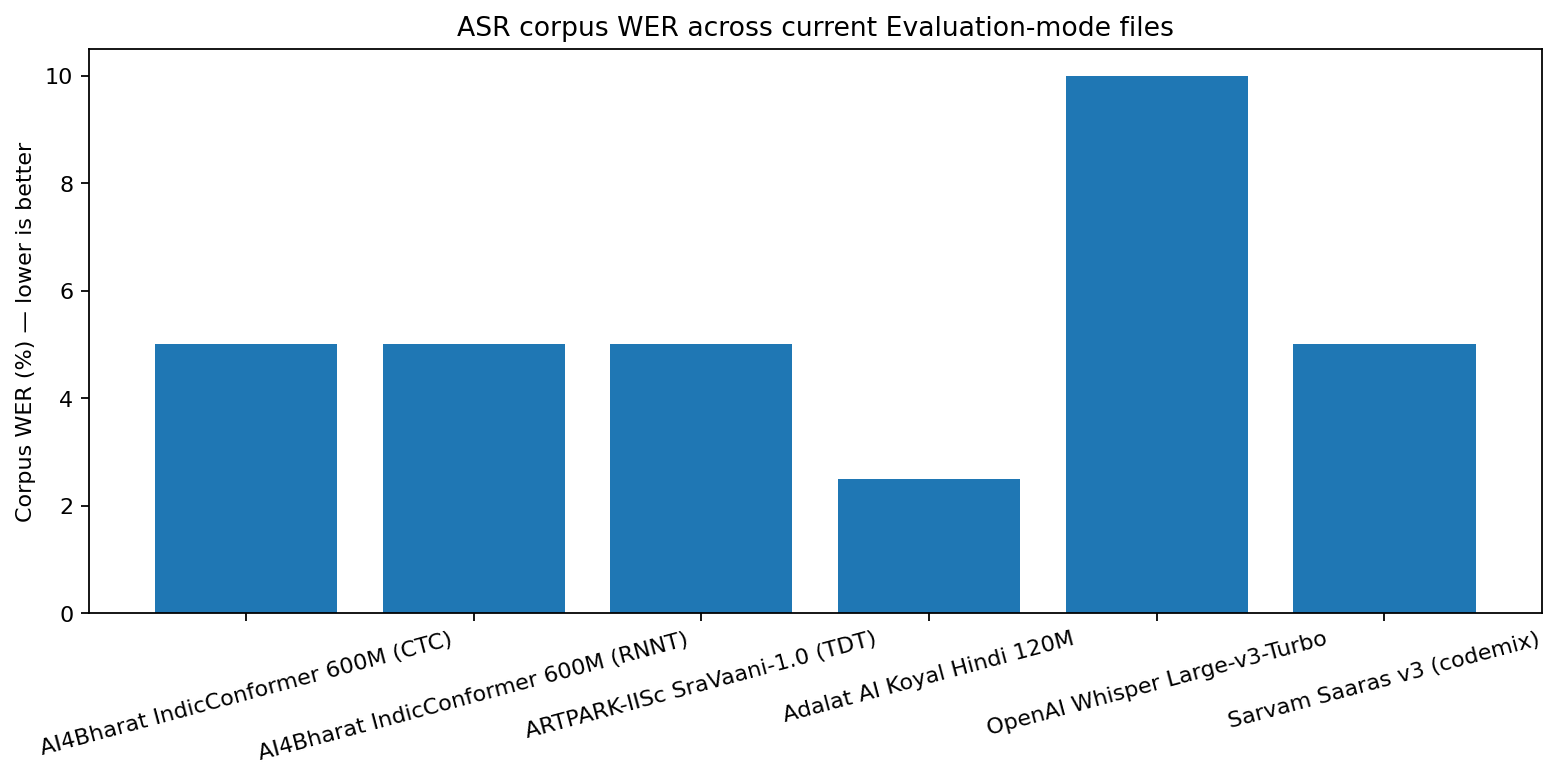

final_tts_loopback_wer.png


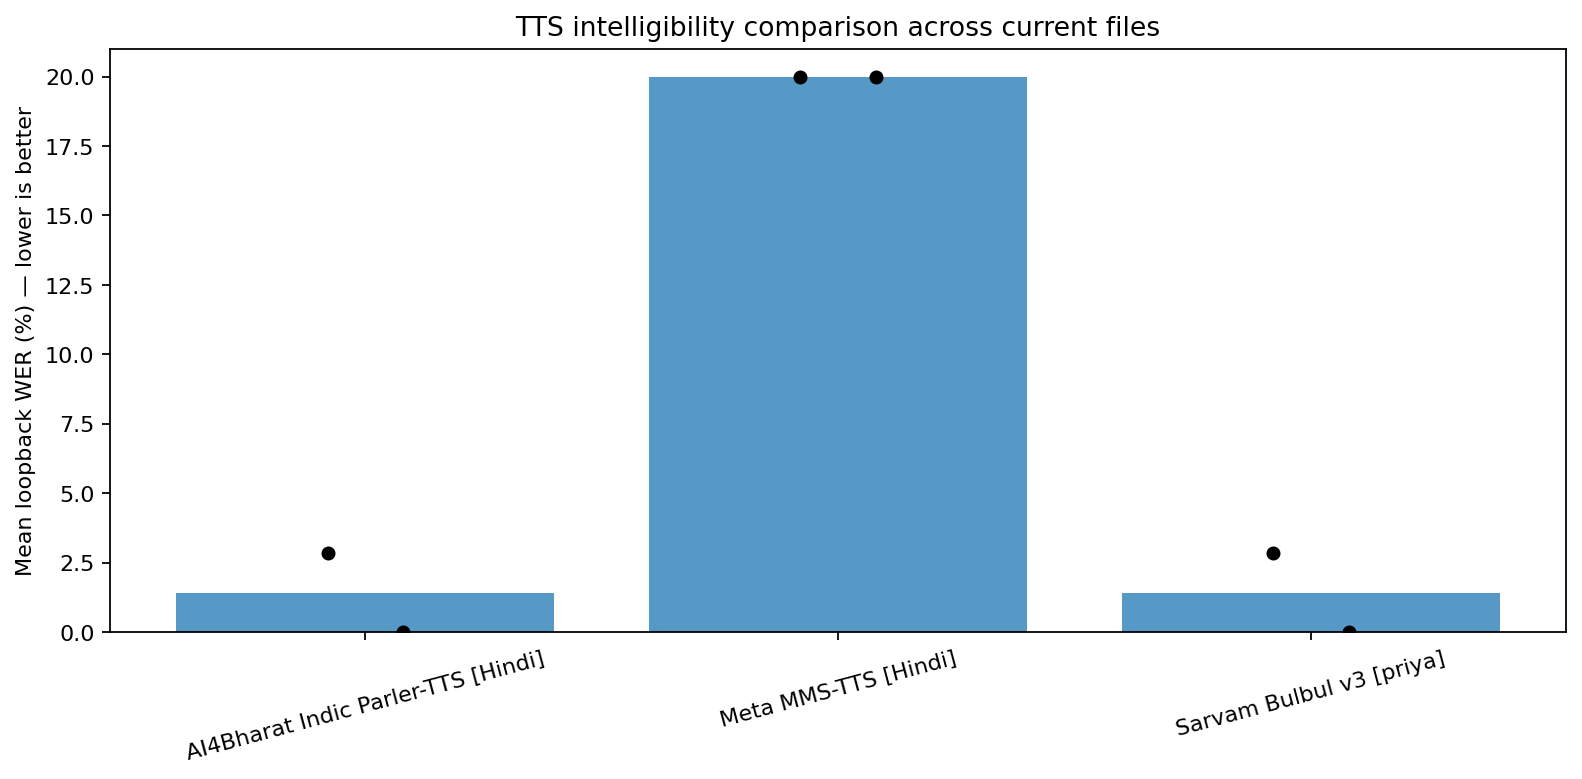

In [ ]:
"""Displays final batch-level ASR, TTS, and prosody comparisons."""

def render_section_12_final_comparison(contexts=None, manifest=None):
    manifest, contexts = _resolve_contexts(contexts, manifest)
    batch_dir = Path(manifest['batch_dir'])
    backfill_batch_tts_diagnostics(contexts, manifest)
    print('Aggregate model comparison across the complete upload batch')
    _show_csv(batch_dir, 'final_model_comparison.csv')
    print('\nAggregate TTS prosody summary')
    _show_csv(batch_dir, 'final_tts_prosody_comparison.csv')
    print('\nEvery file × ASR model')
    _show_csv(batch_dir, 'all_files_asr_results.csv', [
        'file','model_label','decoder','status','wer','cer','reference_chars',
        'char_substitutions','char_deletions','char_insertions','latency_s',
        'latency_scope','rtf','coverage_ratio','error'
    ])
    print('\nEvery file × TTS engine')
    _show_csv(batch_dir, 'all_files_tts_results.csv', [
        'file','engine','status','loopback_wer','loopback_cer',
        'loopback_reference_words','loopback_substitutions','loopback_deletions',
        'loopback_insertions','loopback_deletion_rate','loopback_diagnostics_source',
        'loopback_sravaani_wer','loopback_sravaani_cer','loopback_sravaani_deletion_rate',
        'predicted_utmos','latency_s','latency_scope','rtf',
        'parler_chunks','parler_token_cap_hits','memory_retries','error'
    ])
    print('\nEvery file × natural/processed prosody source')
    _show_csv(batch_dir, 'all_files_prosody_results.csv')
    failed = _read_csv_if_exists(batch_dir / 'failed_files.csv')
    if len(failed):
        print('\nFailed inputs — excluded from successful metric tables but not hidden')
        _display_static_table(failed, index=False)
    for figure in sorted(batch_dir.glob('*.png')):
        print(figure.name)
        display(Image(filename=str(figure)))
    return batch_dir


run_visible_section('render_section_12_final_comparison')


### Section 12B — Headline thesis results

This section produces the tables the thesis reports, one block per variety: Hindi, Hindi-English and Sanskrit. Varieties are never pooled.

- **Rescoring:** every transcript is rescored with the same normalization. Each variety uses its own primary metric: normalized WER for Hindi, script-tolerant WER for Hindi-English, CER for Sanskrit.
- **ASR:** only files with gold references count. The ASR model that drafted a file's reference (if any) is left out for that file.
- **TTS:** only voice-controlled engines are ranked.

Everything left out is listed with the reason. Declare each file's variety in `FILE_VARIETY` (cell 14A).


In [ ]:
"""Section 12B — Headline thesis results, reported separately for Hindi, Hindi-English and Sanskrit.

Every transcript is rescored here with one normalization (TN.score_all) so models are compared like for like.
Primary metric per variety:
  hi    -> normalized WER
  hi-en -> script-tolerant WER (an English word in Latin or Devanagari script counts as the same word)
  sa    -> normalized CER (Sanskrit compounds make word boundaries unreliable)
"""
import json
import re

THESIS_VARIETIES = globals().get('THESIS_VARIETIES', {'hi', 'hi-en', 'sa'})
VARIETY_NAMES = {'hi': 'Hindi', 'hi-en': 'Hindi-English (code-mixed)', 'sa': 'Sanskrit'}
PRIMARY_METRIC = {'hi': 'wer_norm', 'hi-en': 'wer_script_tolerant', 'sa': 'cer_norm'}
GOLD_PRODUCERS = {'human_from_scratch', 'machine_draft_human_corrected', 'published_text'}


def _saved_json(name):
    path = ROOT / name
    return json.loads(path.read_text(encoding='utf-8')) if path.exists() else {}


def load_reference_provenance():
    return {**_saved_json('reference_provenance.json'), **globals().get('REFERENCE_PROVENANCE', {})}


def load_file_variety():
    return {**_saved_json('file_variety.json'), **globals().get('FILE_VARIETY', {})}


def reference_status(entry):
    """Classify reference eligibility without silently excluding uploaded golden references."""
    if not entry:
        return 'undocumented', 'no reference declaration for this file'
    if entry.get('gold_reference') is True:
        return 'gold', 'user-declared full golden reference'
    missing = [k for k in ('produced_by', 'checked_by') if not str(entry.get(k, '')).strip()]
    if missing:
        return 'undocumented', 'missing: ' + ', '.join(missing)
    if entry.get('produced_by') not in GOLD_PRODUCERS:
        return 'silver', f"produced_by={entry.get('produced_by')} is not a gold method"
    if not entry.get('checked_against_audio'):
        return 'silver', 'not checked against the audio'
    if entry.get('coverage') != 'full':
        return 'silver', 'reference does not cover the full recording'
    return 'gold', 'human-checked against the full audio'

def _reference(run_dir):
    path = Path(run_dir) / 'reference.txt'
    return path.read_text(encoding='utf-8').strip() if path.exists() else ''


def file_variety(run, run_dir):
    """Declared variety wins; otherwise sa -> Sanskrit, Latin words in the reference -> Hindi-English."""
    declared = load_file_variety().get(str(run.get('file')))
    if declared:
        return declared, 'declared'
    language = run.get('language_effective')
    if language == 'sa':
        return 'sa', 'detected language'
    if language == 'hi':
        latin = re.findall(r'[A-Za-z]{2,}', _reference(run_dir))
        if len(latin) >= 2:
            return 'hi-en', f'auto: {len(latin)} Latin-script words in the reference; declare to confirm'
        return 'hi', 'detected language (declare hi-en if the speech is code-mixed in Devanagari)'
    return 'out of scope', f'language={language}'


def provenance_table(contexts):
    prov = load_reference_provenance()
    rows = []
    for _, run, run_dir in contexts:
        entry = prov.get(str(run.get('file')), {})
        status, reason = reference_status(entry)
        variety, variety_source = file_variety(run, run_dir)
        rows.append({'file': run.get('file'), 'variety': variety, 'variety_source': variety_source,
                     'in_thesis_scope': variety in THESIS_VARIETIES,
                     'reference_status': status, 'reason': reason,
                     'produced_by': entry.get('produced_by', ''), 'source': entry.get('source', ''),
                     'seed_model': entry.get('seed_model', ''), 'checked_by': entry.get('checked_by', ''),
                     'check_method': entry.get('check_method', ''), 'coverage': entry.get('coverage', '')})
    return pd.DataFrame(rows)


def _transcripts(run_dir):
    saved = _read_csv_if_exists(Path(run_dir) / 'asr_results.csv')
    rows = [(r.get('model_key'), r.get('status'), r.get('hypothesis')) for r in saved.to_dict('records')]
    posthoc = _read_csv_if_exists(Path(run_dir) / 'sravaani_posthoc_asr.csv')
    have = {key for key, _, _ in rows}
    for r in posthoc.to_dict('records'):
        if r.get('model_key') not in have:
            rows.append((r.get('model_key'), r.get('status'), r.get('hypothesis')))
    return rows


def headline_asr(contexts, prov):
    scored, excluded = [], []
    for _, run, run_dir in contexts:
        info = prov[prov.file.eq(run.get('file'))].iloc[0]
        reference = _reference(run_dir)
        language = 'sa' if info.variety == 'sa' else 'hi'
        for key, status, hyp in _transcripts(run_dir):
            hyp = '' if hyp is None or (isinstance(hyp, float) and np.isnan(hyp)) else str(hyp)
            reason = ('out of thesis scope' if not info.in_thesis_scope else
                      f'reference {info.reference_status}' if info.reference_status != 'gold' else
                      'model produced the reference draft' if key == info.seed_model else
                      'no reference text' if not reference else
                      'no successful transcript' if status != 'ok' or not hyp.strip() else '')
            if reason:
                excluded.append({'file': run.get('file'), 'variety': info.variety, 'model_key': key, 'reason': reason})
                continue
            sc = TN.score_all(reference, hyp, language)
            scored.append({'variety': info.variety, 'file': run.get('file'), 'model_key': key, **sc})
    frame = pd.DataFrame(scored)
    tables = {}
    for variety, v in (frame.groupby('variety') if len(frame) else []):
        out = []
        for key, g in v.groupby('model_key'):
            words, chars = g.reference_words_norm.sum(), g.reference_chars_norm.sum()
            per_file = g.groupby('file').reference_words_norm.sum()
            out.append({'model_key': key, 'files': g.file.nunique(), 'reference_words': int(words),
                        'wer_norm': g.errors_norm.sum() / words if words else np.nan,
                        'wer_script_tolerant': g.errors_script_tolerant.sum() / words if words else np.nan,
                        'cer_norm': g.char_errors_norm.sum() / chars if chars else np.nan,
                        'deletion_rate': g.deletions_norm.sum() / words if words else np.nan,
                        'largest_file_word_share': per_file.max() / words if words else np.nan})
        table = pd.DataFrame(out)
        primary = PRIMARY_METRIC[variety]
        table.insert(1, 'primary_metric', primary)
        tables[variety] = table.sort_values(primary)
    return tables, pd.DataFrame(excluded)


def headline_tts(contexts, prov, voices):
    rows = []
    for _, run, run_dir in contexts:
        info = prov[prov.file.eq(run.get('file'))].iloc[0]
        if not info.in_thesis_scope:
            continue
        tts = _read_csv_if_exists(Path(run_dir) / 'tts_comparison.csv')
        for item in tts.to_dict('records'):
            match = voices[voices.file.eq(run.get('file')) & voices.engine_key.eq(item.get('engine_key'))]
            rows.append({'variety': info.variety, 'file': run.get('file'), 'engine_key': item.get('engine_key'),
                         'status': item.get('status'),
                         'voice_control': match.voice_control.iloc[0] if len(match) else 'unknown',
                         **{c: item.get(c) for c in ('loopback_wer', 'loopback_sravaani_wer', 'loopback_cer',
                                                      'loopback_sravaani_cer', 'loopback_deletion_rate',
                                                      'predicted_utmos', 'rtf')}})
    frame = pd.DataFrame(rows)
    tables = {}
    if not len(frame):
        return tables
    for variety, v in frame[frame.status.eq('ok')].groupby('variety'):
        out = []
        for key, g in v.groupby('engine_key'):
            means = {c: pd.to_numeric(g[c], errors='coerce').mean() for c in g.columns
                     if c not in ('variety', 'file', 'engine_key', 'status', 'voice_control')}
            out.append({'engine_key': key, 'files': g.file.nunique(),
                        'voice_controlled': g.voice_control.astype(str).str.startswith('controlled').all(), **means})
        tables[variety] = pd.DataFrame(out).sort_values(['voice_controlled', 'loopback_cer'], ascending=[False, True])
    return tables


def render_section_12b_headline(contexts=None, manifest=None):
    manifest, contexts = _resolve_contexts(contexts, manifest)
    prov = provenance_table(contexts)
    print('Files, variety and reference provenance — only gold references enter the headline ASR tables')
    _display_static_table(prov, index=False)
    asr, excluded = headline_asr(contexts, prov)
    voices = voice_control_table(contexts)
    tts = headline_tts(contexts, prov, voices)
    batch_dir = Path(manifest['batch_dir']) if (manifest or {}).get('batch_dir') else None
    for variety in ('hi', 'hi-en', 'sa'):
        print('\n' + '=' * 96)
        print(f'{VARIETY_NAMES[variety].upper()} — primary metric: {PRIMARY_METRIC[variety]}')
        print('=' * 96)
        if variety in asr:
            print('ASR (gold references; the model that drafted a reference is excluded for that file)')
            _display_static_table(asr[variety], index=False)
            if asr[variety].largest_file_word_share.max() > 0.5:
                print('Warning: one file supplies most of the words; these numbers mostly describe that recording.')
        else:
            print('ASR: no file qualifies yet (needs a gold reference in REFERENCE_PROVENANCE).')
        if variety in tts:
            print('TTS (voice_controlled=False rows are reported but not ranked)')
            _display_static_table(tts[variety], index=False)
            if len(tts[variety]) == 1:
                print('Only one engine supports this variety, so this is a description, not a comparison.')
        else:
            print('TTS: no generated audio for this variety.')
        if batch_dir is not None:
            if variety in asr:
                asr[variety].to_csv(batch_dir / f'headline_asr_{variety}.csv', index=False)
            if variety in tts:
                tts[variety].to_csv(batch_dir / f'headline_tts_{variety}.csv', index=False)
    if len(excluded):
        print('\nExcluded file-model pairs and why')
        _display_static_table(excluded, index=False)
    if batch_dir is not None:
        prov.to_csv(batch_dir / 'reference_provenance.csv', index=False)


run_visible_section('render_section_12b_headline')


Using newest attempted batch: batch_20261022T053451067322Z
Files, variety and reference provenance — only gold references enter the headline ASR tables
Table 1


file,variety,variety_source,in_thesis_scope,reference_status,reason,produced_by,source,seed_model,checked_by,check_method,coverage
480a8c8b8def90b4.wav,sa,detected language,True,gold,user-declared full golden reference,human_from_scratch,user_supplied,,user,,full
script_03_hinglish.mp3,hi,detected language (declare hi-en if the speech is code-mixed in Devanagari),True,gold,user-declared full golden reference,human_from_scratch,user_supplied,,user,,full
common_voice_hi_23795247.mp3,hi,detected language (declare hi-en if the speech is code-mixed in Devanagari),True,gold,user-declared full golden reference,human_from_scratch,user_supplied,,user,,full



HINDI — primary metric: wer_norm
ASR (gold references; the model that drafted a reference is excluded for that file)
Table 2


model_key,primary_metric,files,reference_words,wer_norm,wer_script_tolerant,cer_norm,deletion_rate,largest_file_word_share
koyal-hi-120m,wer_norm,2,40,0.025,0.025,0.012579,0.0,0.875
indic-conformer-600m-ctc,wer_norm,2,40,0.050,0.050,0.012579,0.0,0.875
indic-conformer-600m-rnnt,wer_norm,2,40,0.050,0.050,0.012579,0.0,0.875
sarvam-saaras-v3,wer_norm,2,40,0.050,0.050,0.000000,0.0,0.875
sravaani-1.0,wer_norm,2,40,0.050,0.050,0.012579,0.0,0.875
whisper-large-v3-turbo,wer_norm,2,40,0.100,0.100,0.012579,0.0,0.875


TTS (voice_controlled=False rows are reported but not ranked)
Table 3


engine_key,files,voice_controlled,loopback_wer,loopback_sravaani_wer,loopback_cer,loopback_sravaani_cer,loopback_deletion_rate,predicted_utmos,rtf
indic-parler-tts,2,False,0.014286,0.028571,0.003472,0.006944,0.0,,2.199189
sarvam-bulbul-v3,2,False,0.014286,0.028571,0.003472,0.006944,0.0,,0.565610
meta-mms-tts,2,False,0.200000,0.171429,0.071528,0.061111,0.0,,0.045341


... (2 outputs left out)

TTS (voice_controlled=False rows are reported but not ranked)
Table 5


engine_key,files,voice_controlled,loopback_wer,loopback_sravaani_wer,loopback_cer,loopback_sravaani_cer,loopback_deletion_rate,predicted_utmos,rtf
indic-parler-tts,1,False,,,0.057143,0.052381,0.148148,,2.079297


Only one engine supports this variety, so this is a description, not a comparison.

Excluded file-model pairs and why
Table 6


file,variety,model_key,reason
480a8c8b8def90b4.wav,sa,koyal-hi-120m,no successful transcript


### Section 12C — Synthetic speech (deepfake) detection

Asks whether public detectors can tell the generated Hindi speech from the original recordings.

- **Detectors:** pretrained, used zero-shot: one trained on Indic data, one on English data.
- **Codec control:** every recording passes through the same MP3 round-trip, so codec differences cannot give the answer away.
- **Output:** AUC and EER (equal error rate) per TTS engine and per variety.
- **Small-sample warning:** with only a few real recordings, the results are indicative only. Add real Hindi recordings to strengthen them.


In [ ]:
RUN_DEEPFAKE_DETECTION = False
print("Source-model analysis is deferred. This evaluation revision does not label uploaded audio as human or synthetic.")


Source-model analysis is deferred. This evaluation revision does not label uploaded audio as human or synthetic.


### Section 13 — Saved files, API budget and execution log


Research output enabled; availability depends on the uploaded data and model access.


In [ ]:
"""Displays saved artifacts, Sarvam usage, and the execution-log summary."""

def _flatten_saved_path_values(value):
    if isinstance(value, str):
        return [value]
    if isinstance(value, dict):
        paths = []
        for nested in value.values():
            paths.extend(_flatten_saved_path_values(nested))
        return paths
    if isinstance(value, (list, tuple, set)):
        paths = []
        for nested in value:
            paths.extend(_flatten_saved_path_values(nested))
        return paths
    return []

def render_section_13_artifacts_log(contexts=None, manifest=None):
    manifest, contexts = _resolve_contexts(contexts, manifest)
    batch_dir = Path(manifest['batch_dir'])
    print('Sarvam API budget — one row per successfully processed file')
    _show_csv_for_runs(contexts, 'sarvam_api_budget.csv', transpose_single=True)

    saved_rows = []
    seen_artifact_paths = set()

    def append_saved_artifact(scope, file_index, input_file, value):
        path = _existing_path(value)
        if path is None:
            return
        key = str(path.resolve())
        if key in seen_artifact_paths:
            return
        seen_artifact_paths.add(key)
        saved_rows.append({
            'scope': scope,
            'file_index': file_index,
            'input_file': input_file,
            'artifact': path.name,
            'size_bytes': path.stat().st_size,
            'path': str(path),
        })

    for file_index, run, run_dir in contexts:
        input_file = run.get('file', '')
        for path in sorted(run_dir.iterdir()):
            if path.is_file():
                append_saved_artifact('run', file_index + 1, input_file, path)
        for value in _flatten_saved_path_values(run.get('audio_paths') or {}):
            append_saved_artifact('audio', file_index + 1, input_file, value)
        for value in _flatten_saved_path_values(run.get('tts_audio_paths') or {}):
            append_saved_artifact('tts_audio', file_index + 1, input_file, value)
        for value in _saved_run_figure_paths(run.get('run_id')):
            append_saved_artifact('figure', file_index + 1, input_file, value)

    for path in sorted(batch_dir.iterdir()):
        if path.is_file():
            append_saved_artifact('batch', '', 'ALL FILES', path)

    _display_static_table(pd.DataFrame(saved_rows), index=False)

    log_path = batch_dir / 'pipeline_execution.log'
    if log_path.exists():
        log_lines = log_path.read_text(encoding='utf-8', errors='replace').splitlines()
        print(f'\nExecution log saved: {log_path} ({len(log_lines)} lines)')
        import html
        display(HTML('<details' + (' open' if SHOW_LOGS else '') + '><summary>Detailed execution log</summary><pre>' + html.escape('\n'.join(log_lines)) + '</pre></details>'))
    else:
        print('No pipeline_execution.log found for this batch.')
    print(
        '\nAll tables, audio and figures are loaded from saved files. '
        'Rerunning this cell does not rerun models.'
    )
    return pd.DataFrame(saved_rows)


run_visible_section('render_section_13_artifacts_log')


Using newest attempted batch: batch_20261022T053451067322Z
Sarvam API budget — one row per successfully processed file
Table 1


file_index,file,logical_asr_jobs,logical_tts_calls,tts_chunk_requests,known_rest_http_requests,batch_jobs,audio_seconds,tts_characters,failures
1,480a8c8b8def90b4.wav,1,0,0,1,0,24.710,0,0
2,script_03_hinglish.mp3,1,1,1,2,0,17.175,182,0
3,common_voice_hi_23795247.mp3,1,1,1,2,0,2.952,20,0


Table 2


scope,file_index,input_file,artifact,size_bytes,path
run,1,480a8c8b8def90b4.wav,alignment_indic-conformer-600m-ctc.csv,1639,/content/indic-asr-tts-session/results/20261022T053451317230Z_4d78a709/alignment_indic-conformer-600m-ctc.csv
run,1,480a8c8b8def90b4.wav,alignment_indic-conformer-600m-rnnt.csv,1634,/content/indic-asr-tts-session/results/20261022T053451317230Z_4d78a709/alignment_indic-conformer-600m-rnnt.csv
run,1,480a8c8b8def90b4.wav,alignment_sarvam-saaras-v3.csv,1585,/content/indic-asr-tts-session/results/20261022T053451317230Z_4d78a709/alignment_sarvam-saaras-v3.csv
run,1,480a8c8b8def90b4.wav,alignment_sravaani-1.0.csv,1647,/content/indic-asr-tts-session/results/20261022T053451317230Z_4d78a709/alignment_sravaani-1.0.csv
run,1,480a8c8b8def90b4.wav,alignment_whisper-large-v3-turbo.csv,1641,/content/indic-asr-tts-session/results/20261022T053451317230Z_4d78a709/alignment_whisper-large-v3-turbo.csv
run,1,480a8c8b8def90b4.wav,asr_results.csv,24810,/content/indic-asr-tts-session/results/20261022T053451317230Z_4d78a709/asr_results.csv
run,1,480a8c8b8def90b4.wav,audio_condition.csv,357,/content/indic-asr-tts-session/results/20261022T053451317230Z_4d78a709/audio_condition.csv
run,1,480a8c8b8def90b4.wav,audio_features.csv,725,/content/indic-asr-tts-session/results/20261022T053451317230Z_4d78a709/audio_features.csv
run,1,480a8c8b8def90b4.wav,compact_result.json,82403,/content/indic-asr-tts-session/results/20261022T053451317230Z_4d78a709/compact_result.json
run,1,480a8c8b8def90b4.wav,cross_model_disagreement.csv,1143,/content/indic-asr-tts-session/results/20261022T053451317230Z_4d78a709/cross_model_disagreement.csv


All 160 rows retained. Scroll within the visible table.
No pipeline_execution.log found for this batch.

All tables, audio and figures are loaded from saved files. Rerunning this cell does not rerun models.


## research results

These sections read the files saved by the batch. Each section can be rerun on its own. (voice clone) and (noise benchmark) run additional local models; their flags are at the top of each cell.


### ) Fair ASR comparison

Research output enabled; availability depends on the uploaded data and model access.


Using newest attempted batch: batch_20261022T053451067322Z
Scoring language per file (Sanskrit and other CER-primary languages are kept out of WER aggregates):
Table 1


file,language
480a8c8b8def90b4.wav,sa
common_voice_hi_23795247.mp3,hi
script_03_hinglish.mp3,hi



Normalized WER (numbers→words, nukta/nasal folding, acronyms, loanword lexicon)
Table 2


model,files,reference_words,corpus_wer,corpus_ci_low,corpus_ci_high,macro_wer,macro_ci_low,macro_ci_high,largest_file_word_share
koyal-hi-120m,2,40,0.025,0.0000,0.0286,0.0143,0.0000,0.0286,0.875
indic-conformer-600m-ctc,2,40,0.050,0.0000,0.0571,0.0286,0.0000,0.0571,0.875
indic-conformer-600m-rnnt,2,40,0.050,0.0000,0.0571,0.0286,0.0000,0.0571,0.875
sarvam-saaras-v3,2,40,0.050,0.0000,0.0571,0.0286,0.0000,0.0571,0.875
sravaani-1.0,2,40,0.050,0.0000,0.0571,0.0286,0.0000,0.0571,0.875
whisper-large-v3-turbo,2,40,0.100,0.0857,0.2000,0.1429,0.0857,0.2000,0.875


Paired file-bootstrap differences (negative delta = model_a better):
Table 3


model_a,model_b,files,delta,ci_low,ci_high,p_a_better
koyal-hi-120m,indic-conformer-600m-ctc,2,-0.025,-0.0286,0.0000,0.748
koyal-hi-120m,indic-conformer-600m-rnnt,2,-0.025,-0.0286,0.0000,0.748
koyal-hi-120m,sarvam-saaras-v3,2,-0.025,-0.0286,0.0000,0.748
koyal-hi-120m,sravaani-1.0,2,-0.025,-0.0286,0.0000,0.748
koyal-hi-120m,whisper-large-v3-turbo,2,-0.075,-0.2000,-0.0571,1.000
indic-conformer-600m-ctc,indic-conformer-600m-rnnt,2,0.000,0.0000,0.0000,0.000
indic-conformer-600m-ctc,sarvam-saaras-v3,2,0.000,0.0000,0.0000,0.000
indic-conformer-600m-ctc,sravaani-1.0,2,0.000,0.0000,0.0000,0.000
indic-conformer-600m-ctc,whisper-large-v3-turbo,2,-0.050,-0.2000,-0.0286,1.000
indic-conformer-600m-rnnt,sarvam-saaras-v3,2,0.000,0.0000,0.0000,0.000


Excluded from the common set (reason shown, nothing silently dropped):
Table 4


file,reason
480a8c8b8def90b4.wav,language sa != hi


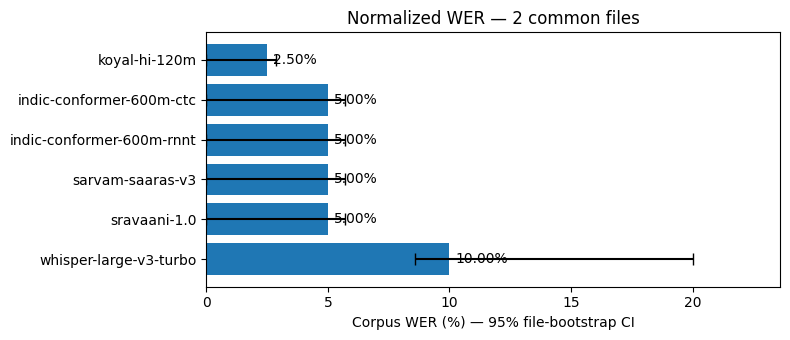


Script-tolerant WER (cross-script words matched by phonetic key): identical to the Normalized WER table (no cross-script matches in this batch).

Mean per-file WER under each scoring policy (shows how much is orthography, not recognition):
Table 5


model_key,wer,wer_norm,wer_script_tolerant
indic-conformer-600m-ctc,0.2536,0.2536,0.2536
indic-conformer-600m-rnnt,0.2907,0.2907,0.2907
koyal-hi-120m,0.0143,0.0143,0.0143
sarvam-saaras-v3,0.3524,0.3524,0.3524
sravaani-1.0,0.2783,0.2783,0.2783
whisper-large-v3-turbo,0.3915,0.3915,0.3915



CER-primary languages (e.g. Sanskrit) — CER is the headline metric; WER shown for reference only:
Table 6


file,language,model_key,cer_norm,wer_norm
480a8c8b8def90b4.wav,sa,sarvam-saaras-v3,0.1190,1.0000
480a8c8b8def90b4.wav,sa,whisper-large-v3-turbo,0.1857,0.8889
480a8c8b8def90b4.wav,sa,indic-conformer-600m-ctc,0.1571,0.7037
480a8c8b8def90b4.wav,sa,indic-conformer-600m-rnnt,0.1429,0.8148
480a8c8b8def90b4.wav,sa,sravaani-1.0,0.1571,0.7778


In [ ]:
"""Fair ASR comparison: identical file set per model, normalized scoring, file-level 95% CIs."""
import matplotlib.pyplot as plt


def render_v13_fair_asr(contexts, manifest):
    batch_dir = Path(manifest['batch_dir'])
    frame = _comparison_frame_for_runs(contexts, 'asr_results.csv')
    if frame.empty or 'errors_norm' not in frame:
        print('Accuracy not calculated: live-mode uploads need matching verified reference transcripts. ASR/TTS results remain available. Use evaluation mode for CER/WER scoring.')
        return
    frame['language'] = frame.get('scoring_language', frame.get('language_effective', 'unknown')).fillna('unknown')
    print('Scoring language per file (Sanskrit and other CER-primary languages are kept out of WER aggregates):')
    _display_static_table(frame.groupby('file').language.first().reset_index(), index=False)
    shown_tables = {}
    for label, error_col in (('Normalized WER (numbers→words, nukta/nasal folding, acronyms, loanword lexicon)', 'errors_norm'),
                             ('Script-tolerant WER (cross-script words matched by phonetic key)', 'errors_script_tolerant')):
        summary, per_file, pairs, excluded = ST.fair_asr_comparison(
            frame, 'hi', error_col, 'reference_words_norm', model_col='model_key')
        signature = summary.round(6).to_json() if len(summary) else ''
        if signature and signature in shown_tables:
            print('\n' + label + f': identical to the {shown_tables[signature]} table (no cross-script matches in this batch).')
            continue
        shown_tables[signature] = label.split(' (')[0]
        print('\n' + label)
        if summary.empty:
            print('No Hindi files in this batch; Sanskrit CER appears below.' if not frame.language.eq('hi').any() else 'No common successfully scored Hindi file set across the selected models.')
            continue
        _display_static_table(summary.round(4), index=False)
        print('Paired file-bootstrap differences (negative delta = model_a better):')
        _display_static_table(pairs.round(4), index=False)
        if len(excluded):
            print('Excluded from the common set (reason shown, nothing silently dropped):')
            _display_static_table(excluded, index=False)
        tag = error_col.replace('errors_', '')
        summary.to_csv(batch_dir / f'v13_fair_asr_{tag}.csv', index=False)
        pairs.to_csv(batch_dir / f'v13_fair_asr_pairs_{tag}.csv', index=False)
        per_file.to_csv(batch_dir / f'v13_fair_asr_per_file_{tag}.csv', index=False)
        fig, ax = plt.subplots(figsize=(8, 3.5))
        err = [summary.corpus_wer - summary.corpus_ci_low, summary.corpus_ci_high - summary.corpus_wer]
        ax.barh(summary.model, summary.corpus_wer * 100, xerr=np.maximum(0, np.asarray(err)*100) if int(summary.files.min()) > 1 else None, capsize=4)
        for i, value in enumerate(summary.corpus_wer):
            ax.annotate(f'{value*100:.2f}%', (value*100, i), xytext=(4,0), textcoords='offset points', va='center')
        ax.margins(x=.18)
        ax.set(xlabel='Corpus WER (%)' + (' — 95% file-bootstrap CI' if int(summary.files.min()) > 1 else ' — one file; CI not estimated'), title=f'{label.split(" (")[0]} — {int(summary.files.iloc[0])} common files')
        ax.invert_yaxis(); plt.tight_layout()
        if SAVE_FIGURES:
            fig.savefig(batch_dir / f'v13_fair_asr_{tag}.png', dpi=150)
        plt.show(); plt.close(fig)
    ok = frame[frame.status.eq('ok')]
    delta = ok.groupby('model_key')[['wer', 'wer_norm', 'wer_script_tolerant']].mean().round(4)
    print('\nMean per-file WER under each scoring policy (shows how much is orthography, not recognition):')
    _display_static_table(delta.reset_index(), index=False)
    cer_files = ok[ok.language.isin(TN.CER_PRIMARY_LANGUAGES)]
    if len(cer_files):
        print('\nCER-primary languages (e.g. Sanskrit) — CER is the headline metric; WER shown for reference only:')
        _display_static_table(cer_files[['file', 'language', 'model_key', 'cer_norm', 'wer_norm']].round(4), index=False)


run_visible_section('render_v13_fair_asr')


### ) Clean output bundle

Research output enabled; availability depends on the uploaded data and model access.


In [ ]:
""""Upload a file, get a clean file": clean audio, transcripts, subtitles and quality report."""
from IPython.display import Audio

DOWNLOAD_CLEAN_BUNDLES = False


def render_v13_clean_bundle(contexts, manifest):
    rows = []
    for _, run, directory in contexts:
        path = Path(directory) / 'v13_clean_bundle.json'
        if not path.exists():
            error = Path(directory) / 'v13_clean_bundle_error.txt'
            skip = Path(directory) / 'v13_clean_bundle_skipped.txt'
            rows.append({'file': run.get('file'), 'status': 'failed' if error.exists() else 'not produced',
                         'reason': error.read_text()[-500:] if error.exists() else skip.read_text() if skip.exists() else 'No bundle saved; inspect run configuration'})
            continue
        report = json.loads(path.read_text(encoding='utf-8'))
        qo, qc = report.get('quality_original', {}), report.get('quality_clean', {})
        rows.append({'file': report.get('file'), 'status': 'ready', 'source': report.get('source_selection'),
                     'transcript_model': report.get('transcript_model'), 'timestamps': report.get('timestamp_precision'),
                     'input_lufs': report.get('input_lufs'), 'target_lufs': report.get('target_lufs'),
                     'dnsmos_ovrl_before': qo.get('dnsmos_ovrl'), 'dnsmos_ovrl_after': qc.get('dnsmos_ovrl'),
                     'dnsmos_bak_before': qo.get('dnsmos_bak'), 'dnsmos_bak_after': qc.get('dnsmos_bak'),
                     'squim_sisdr_before': qo.get('squim_si_sdr_db'), 'squim_sisdr_after': qc.get('squim_si_sdr_db'),
                     'do_no_harm_wer_original': report.get('do_no_harm_wer_original'),
                     'do_no_harm_wer_processed': report.get('do_no_harm_wer_processed'),
                     'bundle': report.get('bundle_zip')})
        print(f"\n{report.get('file')} — {report.get('source_selection')}")
        display(Audio(filename=report['clean_audio']))
        if DOWNLOAD_CLEAN_BUNDLES:
            try:
                from google.colab import files
                print('Display-only mode: no download requested.')
            except Exception as exc:
                print('Download unavailable:', exc)
    table = pd.DataFrame(rows)
    _display_static_table(table.round(3) if len(table) else table, index=False)
    table.to_csv(Path(manifest['batch_dir']) / 'v13_clean_bundles.csv', index=False)
    if not any(row.get('status') == 'ready' for row in rows):
        print('No export bundle produced. Processed audio and plots remain available in the main output sections.')
        return table
    print('Each bundle: <name>_clean.wav (−23 LUFS), transcript (raw / spoken-form / romanized), .srt, '
          'word timestamps (≤180 s files), quality_report.json. DNSMOS/SQUIM are reference-free estimates.')


run_visible_section('render_v13_clean_bundle')


Using newest attempted batch: batch_20261022T053451067322Z
Table 1


file,status,reason
480a8c8b8def90b4.wav,not produced,clean_bundle=False for this run
script_03_hinglish.mp3,not produced,clean_bundle=False for this run
common_voice_hi_23795247.mp3,not produced,clean_bundle=False for this run


No export bundle produced. Processed audio and plots remain available in the main output sections.


### ) Original vs generated speech

Research output enabled; availability depends on the uploaded data and model access.


Using newest attempted batch: batch_20261022T053451067322Z
Table 1


file,engine_key,protocol,status,matched_text_verified,comparison_action,original_duration_s,generated_duration_s,passage_scope,dnsmos_ovrl,dnsmos_sig,squim_stoi,f0_corr_semitones,f0_rmse_semitones,vuv_error_rate,energy_corr,speech_duration_ratio,pause_ratio_abs_diff,f0_range_ratio,mcd_dtw_db,alignment_status
480a8c8b8def90b4.wav,indic-parler-tts,tts_only,ok,True,Matched acoustic comparison,24.710,23.858,whole recording (text identical to gold reference),3.348,3.577,0.996,0.240,4.553,0.233,0.543,0.858,0.103,4.039,,ok
script_03_hinglish.mp3,sarvam-bulbul-v3,tts_only,ok,True,Matched acoustic comparison,17.175,14.165,whole recording (text identical to gold reference),3.168,3.453,0.997,0.797,2.783,0.056,0.780,0.977,0.082,0.585,,ok
script_03_hinglish.mp3,indic-parler-tts,tts_only,ok,True,Matched acoustic comparison,17.175,15.986,whole recording (text identical to gold reference),3.264,3.504,0.997,0.550,3.912,0.121,0.763,0.833,0.111,0.794,,ok
script_03_hinglish.mp3,meta-mms-tts,tts_only,ok,True,Matched acoustic comparison,17.175,13.792,whole recording (text identical to gold reference),3.150,3.372,0.996,0.569,3.775,0.096,0.779,0.882,0.024,0.882,,ok
common_voice_hi_23795247.mp3,sarvam-bulbul-v3,tts_only,ok,True,Matched acoustic comparison,2.952,1.707,whole recording (text identical to gold reference),3.402,3.642,0.988,0.773,4.157,0.185,0.812,1.020,0.023,2.910,,ok
common_voice_hi_23795247.mp3,indic-parler-tts,tts_only,ok,True,Matched acoustic comparison,2.952,2.067,whole recording (text identical to gold reference),3.043,3.297,0.996,0.547,4.368,0.332,0.505,0.760,0.321,3.897,,ok
common_voice_hi_23795247.mp3,meta-mms-tts,tts_only,ok,True,Matched acoustic comparison,2.952,2.048,whole recording (text identical to gold reference),3.071,3.262,0.991,0.482,3.815,0.152,0.885,0.860,0.243,3.315,,ok


Descriptive voice signatures for all available recordings; these do not require matched text.
Table 2


file_index,file,system,comparison_scope,f0_median_hz,f0_iqr_semitones,voiced_fraction,cpp_db,spectral_tilt_db_per_octave,f1_mean_hz,f2_mean_hz,f3_mean_hz,dnsmos_ovrl,dnsmos_sig,dnsmos_bak,dnsmos_p808,squim_stoi,squim_pesq,squim_si_sdr_db,dnsmos_note
1,480a8c8b8def90b4.wav,original_full_recording,descriptive only; no text alignment implied,169.625583,0.916199,0.782274,2.585933,-3.532105,515.871357,1505.824444,2644.947442,,,,,,,,
1,480a8c8b8def90b4.wav,original,,169.625583,0.916199,0.782274,2.585933,-3.532105,515.871357,1505.824444,2644.947442,3.345307,3.605090,4.135135,3.582213,0.996759,3.522420,21.497705,
1,480a8c8b8def90b4.wav,indic-parler-tts,,129.354588,6.831160,0.579631,1.041538,-6.269579,456.243138,1561.889674,2777.069020,,,,,,,,
2,script_03_hinglish.mp3,original_full_recording,descriptive only; no text alignment implied,258.988975,6.719748,0.562282,2.225779,-0.653650,541.487865,1791.114355,2861.916881,,,,,,,,
2,script_03_hinglish.mp3,original,,258.975774,6.707260,0.595179,2.225190,-0.656960,535.275432,1789.399607,2846.915069,3.208955,3.474076,4.069601,3.744197,0.988828,3.626517,26.122683,
2,script_03_hinglish.mp3,sarvam-bulbul-v3,,204.624658,4.180896,0.664079,1.917775,-0.568243,508.014572,1908.512256,2738.464534,,,,,,,,
2,script_03_hinglish.mp3,indic-parler-tts,,152.497918,5.656308,0.423390,1.292334,-6.398832,495.732035,1890.488302,3115.454569,,,,,,,,
2,script_03_hinglish.mp3,meta-mms-tts,,157.108148,5.055895,0.580435,1.486890,-5.597754,481.909093,1629.480656,2545.341437,,,,,,,,
3,common_voice_hi_23795247.mp3,original_full_recording,descriptive only; no text alignment implied,123.471555,1.278248,0.456081,0.876970,-4.596692,414.008147,1357.854709,2719.540774,,,,,,,,
3,common_voice_hi_23795247.mp3,original,,123.476089,1.209903,0.779070,0.968115,-4.153875,413.679663,1355.731426,2742.844618,2.522339,2.972499,3.619418,3.610936,0.520688,1.164448,-10.033031,clip shorter than 9 s: DNSMOS tiles the audio; treat as approximate


Per-engine means (count = files). Higher is closer to the original for correlations, speaker similarity; lower is closer for RMSE, V/UV error, MCD and |deltas|. DNSMOS is predicted quality, not original-voice similarity.
Table 3


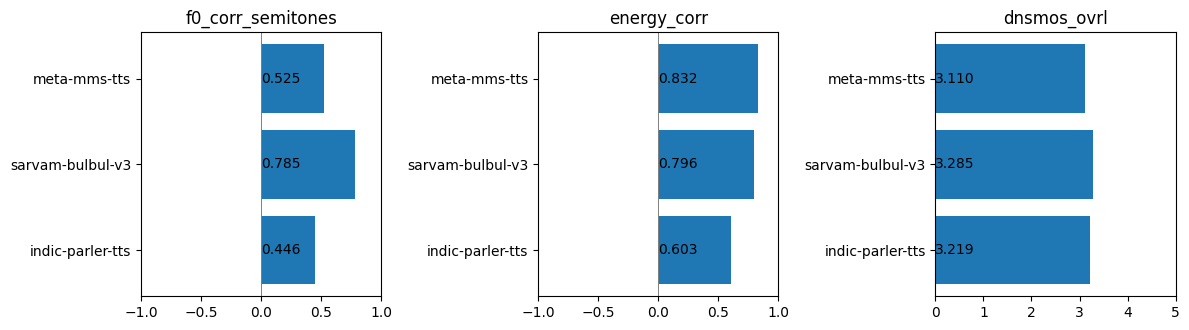

MCD is reported only for same-speaker pairs (IndicF5 voice clone). Cross-speaker spectral distance is in the CSV as mcd_dtw_db_cross_speaker and is not a quality score. Phonetic probes are exploratory.
Using newest attempted batch: batch_20261022T053451067322Z
Reference text → TTS
Loopback scores compare recognised generated speech with the text supplied to TTS; they include recognizer errors.
Table 1


file,engine_key,status,source_text_type,loopback_wer,loopback_cer
480a8c8b8def90b4.wav,sarvam-bulbul-v3,unsupported,gold_reference,,
480a8c8b8def90b4.wav,indic-parler-tts,ok,gold_reference,,0.057143
480a8c8b8def90b4.wav,meta-mms-tts,unsupported,gold_reference,,
script_03_hinglish.mp3,sarvam-bulbul-v3,ok,gold_reference,0.028571,0.006944
script_03_hinglish.mp3,indic-parler-tts,ok,gold_reference,0.028571,0.006944
script_03_hinglish.mp3,meta-mms-tts,ok,gold_reference,0.200000,0.076389
common_voice_hi_23795247.mp3,sarvam-bulbul-v3,ok,gold_reference,0.000000,0.000000
common_voice_hi_23795247.mp3,indic-parler-tts,ok,gold_reference,0.000000,0.000000
common_voice_hi_23795247.mp3,meta-mms-tts,ok,gold_reference,0.200000,0.066667


Uploaded audio → ASR text → TTS: not requested in this run.
WER may exceed 1.0 when insertions exceed the number of reference words. Inspect the transcript and CER alongside WER.


In [ ]:
"""Original vs generated speech: DTW-aligned prosody, speaker similarity, quality and phonetic probes."""
import matplotlib.pyplot as plt

V13_TTS_COLUMNS = ['file', 'engine_key', 'protocol', 'status', 'matched_text_verified', 'comparison_action', 'original_duration_s', 'generated_duration_s', 'passage_scope', 'dnsmos_ovrl', 'dnsmos_sig',
                   'squim_stoi', 'f0_corr_semitones', 'f0_rmse_semitones', 'vuv_error_rate', 'energy_corr',
                   'speech_duration_ratio', 'pause_ratio_abs_diff', 'f0_range_ratio', 'mcd_dtw_db',
                   'speaker_similarity', 'speaker_sim_ecapa', 'speaker_sim_wavlm_sv', 'delta_f3_dental_minus_retroflex_hz',
                   'delta_aspiration_duration_ratio', 'delta_schwa_interval_ratio_retained_to_deleted', 'error']


def render_v13_tts_vs_original(contexts, manifest):
    frame = _comparison_frame_for_runs(contexts, 'v13_tts_vs_original.csv')
    if frame.empty:
        print('No original-vs-generated result saved. Check the per-file stage status; matched metrics also require a verified matching passage.')
        return
    _display_static_table(frame[[c for c in dict.fromkeys(V13_TTS_COLUMNS + [x for x in frame.columns if x.endswith(('_error', '_status'))]) if c in frame]].round(3), index=False)
    print('Descriptive voice signatures for all available recordings; these do not require matched text.')
    _show_csv_for_runs(contexts, 'v13_voice_signatures.csv')
    ok = frame.copy()
    if ok.empty:
        print('Matched speech metrics withheld: no verified matching original passage. Generated-audio quality remains shown where available.')
        return
    metrics = [c for c in V13_TTS_COLUMNS[5:-1] if c not in ('matched_text_verified', 'original_duration_s', 'generated_duration_s') and c in ok and pd.to_numeric(ok[c], errors='coerce').notna().any()]
    summary = ok.groupby('engine_key')[metrics].agg(['mean', 'count']).round(3)
    print('Per-engine means (count = files). Higher is closer to the original for correlations, '
          'speaker similarity; lower is closer for RMSE, V/UV error, MCD and |deltas|. DNSMOS is predicted quality, not original-voice similarity.')
    _display_static_table(summary.reset_index(), index=False)
    summary.to_csv(Path(manifest['batch_dir']) / 'v13_tts_vs_original_summary.csv')
    shown = [m for m in ('f0_corr_semitones', 'energy_corr', 'speaker_similarity', 'dnsmos_ovrl') if m in ok and pd.to_numeric(ok[m], errors='coerce').notna().any()]
    if shown:
        fig, axes = plt.subplots(1, len(shown), figsize=(4 * len(shown), 3.4))
        axes = np.atleast_1d(axes)
        for ax, m in zip(axes, shown):
            data = ok.groupby('engine_key')[m].mean().reindex(frame.engine_key.unique())
            ax.barh(data.index, data.fillna(0).values); ax.set_title(m)
            for pos, value in enumerate(data):
                ax.text(0, pos, 'N/A' if not np.isfinite(value) else f'{value:.3f}', va='center')
            if m in ('f0_corr_semitones', 'energy_corr', 'speaker_similarity'):
                ax.set_xlim(-1, 1)
                ax.axvline(0, color='gray', linewidth=.7)
            elif m == 'dnsmos_ovrl':
                ax.set_xlim(0, 5)
        plt.tight_layout()
        if SAVE_FIGURES:
            fig.savefig(Path(manifest['batch_dir']) / 'v13_tts_vs_original.png', dpi=150)
        plt.show(); plt.close(fig)
    print('MCD is reported only for same-speaker pairs (IndicF5 voice clone). Cross-speaker spectral distance is in '
          'the CSV as mcd_dtw_db_cross_speaker and is not a quality score. Phonetic probes are exploratory.')


def render_v13_tts_protocols(contexts, manifest):
    tts = pd.concat([_comparison_frame_for_runs(contexts, 'tts_comparison.csv'),
                     _comparison_frame_for_runs(contexts, 'v13_tts_reference_text.csv')], ignore_index=True)
    if tts.empty:
        print('No synthesis rows in this batch.')
        return
    for protocol, title in [('tts_only', 'Reference text → TTS'), ('end_to_end', 'Uploaded audio → ASR text → TTS')]:
        sources = tts.get('source_text_type', pd.Series('', index=tts.index)).fillna('').astype(str)
        mask = sources.str.startswith('gold') if protocol == 'tts_only' else sources.str.startswith(('selected_asr', 'asr:'))
        part = tts[mask].copy()
        if part.empty:
            print(title + ': not requested in this run.')
            continue
        print(title)
        print('Loopback scores compare recognised generated speech with the text supplied to TTS; they include recognizer errors.')
        columns = [c for c in ['file','engine_key','status','source_text_type','loopback_wer','loopback_cer'] if c in part]
        _display_static_table(part[columns], index=False)
    e2e = _comparison_frame_for_runs(contexts, 'v13_tts_end_to_end.csv')
    if len(e2e):
        columns = [c for c in ['file','engine_key','status','reference_scope','asr_wer_vs_reference',
                              'end_to_end_wer_vs_reference','end_to_end_cer_vs_reference','primary_metric'] if c in e2e]
        print('End-to-end scores against the uploaded reference (blank when no reference or loopback is available).')
        _display_static_table(e2e[columns], index=False)
    print('WER may exceed 1.0 when insertions exceed the number of reference words. Inspect the transcript and CER alongside WER.')


run_visible_section('render_v13_tts_vs_original')
run_visible_section('render_v13_tts_protocols')


## Validation scope
WER/CER require verified reference transcripts. Predicted quality scores and speaker similarity are diagnostic measurements, not human listening scores. GPU inference and long-file stability must be checked in Colab. Optional studies are available in the separate research notebook.


## 16. Optional speech-decision research

This is an evaluation extension inspired by Choice, Binary Probability and Score interfaces—not an implementation or reproduction of Qwen-Audio-Jev. No new large decision model is downloaded.

Run the normal research batch first. This section reuses its audio. Apply verified metadata, then select an experiment. Unknown recordings remain unknown; generated audio has known synthetic provenance but still needs a verified voice ID and leakage-safe split group.

- Detector: frozen WavLM embeddings, logistic classifier, separate group-disjoint training/calibration/test, raw and calibrated ROC/Brier/F1/FPR/FNR/reliability plots.
- Speaker verification: ECAPA cosine scores and calibration/test partitions with same- and different-speaker trials. Stock TTS voices are not assumed to be clones.
- Listening: random-order audio choices and actual 1–5 listener responses. No scores are fabricated. DNSMOS overall predictions can be compared with human overall MOS; other dimensions remain human-only unless aligned predictions are supplied to `decision_score_metrics`.
- Choice: CSV evaluation for verified language/noise/candidate labels. Preference votes are recorded separately, not called objective accuracy.
- Robustness: original, additive noise, compressed audio, short and longer crops. Runs only on button press and uses temporary files. Long crops do not manufacture new speech. Probabilities are exploratory outside the held-out detector set.
- Timing/signatures: reuse ASR/TTS speed and measured features. Unmeasured model-load time stays missing. This is research timing, not a live-streaming benchmark.

All added labels, ratings and results remain in session memory and disappear on runtime reset. No Drive exports. The original pipeline may still use its temporary session result files. The live application remains separate and is not changed here.

Six groups is only a minimum split guard, not a claim of reliable generalization. Collect substantially more independent speakers and hold out generators to test unseen synthesis systems. Acoustic features are descriptive, not validated measures of cognition or proof of authenticity.


In [ ]:
import hashlib
import io
import tempfile
import subprocess
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Audio
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix, roc_curve,
                             roc_auc_score, brier_score_loss, mean_absolute_error,
                             mean_squared_error)
from sklearn.calibration import calibration_curve
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DECISION_ENABLED = True
DECISION_SEED = 42
DECISION_LABELS = globals().get('DECISION_LABELS', {})
DECISION_RATINGS = globals().get('DECISION_RATINGS', [])
DECISION_CHOICES = globals().get('DECISION_CHOICES', [])
DECISION_BUNDLE = None
DECISION_RECORDS = pd.DataFrame()
DECISION_OUTPUTS = {}

def decision_records():
    rows = _payload_source_records(globals().get('RESULT') or {})
    out = []
    for row in rows:
        path = Path(row['audio_path'])
        if not path.is_file():
            continue
        rid = hashlib.sha256(str(path.resolve()).encode()).hexdigest()[:16]
        generated = row['source_model'] != 'uploaded_original'
        label = DECISION_LABELS.get(rid, {})
        out.append({**row, 'record_id': rid,
                    'source': 'synthetic' if generated else label.get('source', 'unknown'),
                    'confirmed': True if generated else bool(label.get('confirmed', False)),
                    'speaker_id': label.get('speaker_id', ''),
                    'split_group': label.get('split_group', ''),
                    'language_truth': label.get('language_truth', ''),
                    'noise_truth': label.get('noise_truth', '')})
    return pd.DataFrame(out)

def decision_binary_metrics(y, probability, threshold=0.5, title='Binary evaluation'):
    y, p = np.asarray(y, int), np.asarray(probability, float)
    if len(y) != len(p) or set(np.unique(y)) != {0, 1}:
        raise ValueError('Both verified classes are required on the held-out test split.')
    if not np.isfinite(p).all() or np.any((p < 0) | (p > 1)):
        raise ValueError('Probabilities must be finite and between zero and one.')
    fpr, tpr, thresholds = roc_curve(y, p)
    fnr = 1 - tpr
    k = int(np.argmin(np.abs(fpr - fnr)))
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    result = dict(n=len(y), accuracy=accuracy_score(y, pred), f1=f1_score(y, pred, zero_division=0),
                  roc_auc=roc_auc_score(y, p), eer_approx=(fpr[k] + fnr[k]) / 2,
                  brier=brier_score_loss(y, p), threshold=threshold,
                  fpr=fp / (fp + tn), fnr=fn / (fn + tp))
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].plot(fpr, tpr); axes[0].plot([0, 1], [0, 1], '--')
    axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title=title + ' ROC')
    observed, predicted = calibration_curve(y, p, n_bins=min(10, len(y)), strategy='uniform')
    axes[1].plot(predicted, observed, 'o-'); axes[1].plot([0, 1], [0, 1], '--')
    axes[1].set(xlabel='Mean predicted probability', ylabel='Observed positive fraction', title='Reliability')
    plt.tight_layout(); plt.show(); plt.close(fig)
    display(pd.DataFrame([result]))
    operating = []
    for cut in (0.1, 0.25, 0.5, 0.75, 0.9):
        tn, fp, fn, tp = confusion_matrix(y, p >= cut, labels=[0, 1]).ravel()
        operating.append(dict(threshold=cut, fpr=fp/(fp+tn), fnr=fn/(fn+tp)))
    display(pd.DataFrame(operating))
    return result

def decision_group_splits(frame):
    if frame.split_group.astype(str).str.strip().eq('').any():
        raise ValueError('Provide split_group for every training record; related speakers/passages must share a group.')
    if frame.split_group.nunique() < 6:
        raise ValueError('Need at least six independent groups for separate train, calibration and test splits. This is a guard, not evidence of sufficient statistical power.')
    y = frame.source.eq('synthetic').astype(int).to_numpy()
    for train_dev, test in GroupShuffleSplit(n_splits=50, test_size=.25, random_state=DECISION_SEED).split(frame, y, frame.split_group):
        sub = frame.iloc[train_dev]
        for a, b in GroupShuffleSplit(n_splits=10, test_size=.33, random_state=DECISION_SEED).split(sub, y[train_dev], sub.split_group):
            train, dev = train_dev[a], train_dev[b]
            if all(len(np.unique(y[ix])) == 2 for ix in (train, dev, test)):
                return train, dev, test
    raise ValueError('No group-disjoint train/calibration/test split has both classes.')

def train_decision_detector():
    global DECISION_BUNDLE
    DECISION_BUNDLE = None
    frame = decision_records()
    if frame.empty:
        raise ValueError('No current-batch audio records.')
    frame = frame[frame.confirmed & frame.source.isin(['human', 'synthetic'])].reset_index(drop=True)
    if frame.empty:
        raise ValueError('No verified detector labels. Uploaded originals are not automatically human.')
    if frame.speaker_id.astype(str).str.strip().eq('').any():
        raise ValueError('Verified speaker/voice IDs are required for detector evaluation.')
    if frame.groupby('speaker_id').split_group.nunique().gt(1).any():
        raise ValueError('A speaker/voice appears in multiple split groups. Merge those groups before training.')
    train, dev, test = decision_group_splits(frame)
    x = np.vstack([wavlm_embedding(p) for p in frame.audio_path])
    y = frame.source.eq('synthetic').astype(int).to_numpy()
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight='balanced', random_state=DECISION_SEED))
    model.fit(x[train], y[train])
    calibrator = LogisticRegression(random_state=DECISION_SEED)
    calibrator.fit(model.decision_function(x[dev]).reshape(-1, 1), y[dev])
    raw = model.predict_proba(x[test])[:, 1]
    calibrated = calibrator.predict_proba(model.decision_function(x[test]).reshape(-1, 1))[:, 1]
    decision_binary_metrics(y[test], raw, title='Raw detector')
    metrics = decision_binary_metrics(y[test], calibrated, title='Calibrated detector')
    frame['partition'] = ''
    for name, ix in [('train', train), ('calibration', dev), ('test', test)]:
        frame.loc[ix, 'partition'] = name
    display(frame[['record_id', 'source', 'speaker_id', 'split_group', 'partition']])
    DECISION_BUNDLE = dict(model=model, calibrator=calibrator, test_ids=set(frame.iloc[test].record_id), metrics=metrics)
    DECISION_OUTPUTS['detector_split'] = frame
    return metrics

def decision_probability(path):
    if DECISION_BUNDLE is None:
        return np.nan
    x = wavlm_embedding(path).reshape(1, -1)
    score = DECISION_BUNDLE['model'].decision_function(x).reshape(-1, 1)
    return float(DECISION_BUNDLE['calibrator'].predict_proba(score)[0, 1])

def decision_speaker_experiment():
    from cmhss.quality import speaker_embedding
    frame = decision_records()
    frame = frame[frame.confirmed & frame.speaker_id.astype(str).str.strip().ne('')].reset_index(drop=True)
    if frame.empty or frame.split_group.astype(str).str.strip().eq('').any():
        raise ValueError('Enter verified speaker IDs and split groups, including generated voice IDs. A default TTS voice is not the original speaker.')
    if frame.groupby('speaker_id').split_group.nunique().gt(1).any():
        raise ValueError('Merge split groups that contain the same speaker.')
    groups = sorted(frame.split_group.unique())
    if len(groups) < 4:
        raise ValueError('Need at least four independent groups to separate speaker calibration and test trials.')
    order = np.random.default_rng(DECISION_SEED).permutation(groups)
    dev_groups = set(order[:len(order)//2])
    vectors = []
    for path in frame.audio_path:
        y, sr = load_audio_any(path, 16000)
        vectors.append(speaker_embedding(y, sr, backend='ecapa', device=DEVICE))
    trials = []
    for i in range(len(frame)):
        for j in range(i+1, len(frame)):
            a, b = frame.iloc[i], frame.iloc[j]
            pa, pb = a.split_group in dev_groups, b.split_group in dev_groups
            if pa != pb:
                continue
            trials.append(dict(a=a.record_id, b=b.record_id, partition='calibration' if pa else 'test',
                               same=int(a.speaker_id == b.speaker_id), cosine=float(np.dot(vectors[i], vectors[j])),
                               pair_type=f'{a.source}/{b.source}'))
    trials = pd.DataFrame(trials)
    if trials.empty:
        raise ValueError('No speaker-disjoint trials available.')
    dev, test = trials[trials.partition.eq('calibration')], trials[trials.partition.eq('test')]
    if dev.same.nunique() != 2 or test.same.nunique() != 2:
        raise ValueError('Both same-speaker and different-speaker pairs are needed in calibration and test. Add repeated recordings per speaker.')
    calibration = LogisticRegression().fit(dev[['cosine']], dev.same)
    test = test.copy(); test['probability_same_speaker'] = calibration.predict_proba(test[['cosine']])[:, 1]
    display(test)
    result = decision_binary_metrics(test.same, test.probability_same_speaker, title='Speaker verification')
    DECISION_OUTPUTS['speaker_trials'] = trials
    DECISION_OUTPUTS['speaker_calibrator'] = calibration
    return result

def decision_choice_metrics(frame):
    required = {'task', 'truth', 'prediction'}
    if not required <= set(frame):
        raise ValueError('Choice rows require task, truth, prediction.')
    summaries = []
    for task, part in frame.groupby('task'):
        part = part.dropna(subset=['truth', 'prediction'])
        if part.empty:
            continue
        labels = sorted(set(part.truth.astype(str)) | set(part.prediction.astype(str)))
        y, p = part.truth.astype(str), part.prediction.astype(str)
        summaries.append(dict(task=task, n=len(part), accuracy=accuracy_score(y,p), macro_f1=f1_score(y,p,average='macro',zero_division=0)))
        fig, ax = plt.subplots(figsize=(6,4))
        ax.imshow(confusion_matrix(y,p,labels=labels), cmap='Blues')
        ax.set(xticks=range(len(labels)), yticks=range(len(labels)), xticklabels=labels, yticklabels=labels,
               xlabel='Predicted', ylabel='Verified label', title=str(task))
        plt.xticks(rotation=45); plt.tight_layout(); plt.show(); plt.close(fig)
    display(pd.DataFrame(summaries))
    return pd.DataFrame(summaries)

def decision_score_metrics(ratings, predictions):
    dimensions = ['naturalness', 'intelligibility', 'similarity', 'overall', 'noise', 'loudness']
    if ratings.empty:
        raise ValueError('No listener responses yet. Use the listening controls below.')
    ratings = ratings.drop_duplicates(['listener_id','record_id'], keep='last')
    long = ratings.melt(id_vars=['listener_id','record_id'], value_vars=dimensions, var_name='dimension',value_name='rating').dropna()
    mos = long.groupby(['record_id','dimension']).rating.agg(['mean','std','count']).reset_index()
    mos['se'] = mos['std'] / np.sqrt(mos['count'])
    display(mos)
    if predictions.empty:
        print('Human MOS collected. No aligned 1–5 predictions supplied; no prediction accuracy claimed.')
        return mos
    if predictions.duplicated(['record_id','dimension','model']).any():
        raise ValueError('Duplicate prediction keys.')
    joined = mos.merge(predictions, on=['record_id','dimension'], validate='one_to_many')
    rows=[]
    for (model, dimension), p in joined.groupby(['model','dimension']):
        p=p.dropna(subset=['mean','prediction'])
        if p.empty: continue
        if not p.prediction.between(1,5).all():
            raise ValueError('Score predictions must be on the declared 1–5 scale; do not treat cosine similarity as MOS.')
        valid=len(p)>=3 and p['mean'].nunique()>1 and p.prediction.nunique()>1
        rows.append(dict(model=model,dimension=dimension,n=len(p),mae=mean_absolute_error(p['mean'],p.prediction),
                         rmse=np.sqrt(mean_squared_error(p['mean'],p.prediction)),
                         pearson=p['mean'].corr(p.prediction) if valid else np.nan,
                         spearman=p['mean'].corr(p.prediction,method='spearman') if valid else np.nan))
        fig, ax=plt.subplots(); ax.scatter(p['mean'],p.prediction); ax.plot([1,5],[1,5],'--')
        ax.set(xlabel='Human MOS',ylabel='Predicted score',title=f'{model}: {dimension}')
        plt.show(); plt.close(fig)
    display(pd.DataFrame(rows))
    DECISION_OUTPUTS['mos']=mos
    return pd.DataFrame(rows)

def decision_variants(path, folder, seed=42):
    import soundfile as sf
    y,sr=load_audio_any(path,16000)
    if len(y)==0: raise ValueError('Empty recording')
    rng=np.random.default_rng(seed)
    noise=rng.standard_normal(len(y)); noise*=np.sqrt(np.mean(y*y)/(np.mean(noise*noise)+1e-12))*10**(-10/20)
    signals={'original': y, 'noise_10db': y+noise, 'short_3s': y[:3*sr], 'long_up_to_30s':y[:30*sr]}
    paths={}
    for name, values in signals.items():
        target=Path(folder)/f'{name}.wav'; sf.write(target,values,sr,subtype='FLOAT'); paths[name]=target
    mp3=Path(folder)/'compressed.mp3'
    result=subprocess.run(['ffmpeg','-v','error','-y','-i',str(paths['original']),'-b:a','32k',str(mp3)],capture_output=True,timeout=60)
    if result.returncode: raise RuntimeError('FFmpeg compression failed: '+result.stderr.decode(errors='replace')[-500:])
    paths['compressed_32kbps']=mp3
    return paths

def decision_robustness(record_id):
    from cmhss import quality as quality_module
    frame=decision_records(); record=frame[frame.record_id.eq(record_id)].iloc[0]
    baseline_y,sr=load_audio_any(record.audio_path,16000)
    baseline_emb=quality_module.speaker_embedding(baseline_y,sr,backend='ecapa',device=DEVICE)
    rows=[]
    with tempfile.TemporaryDirectory(prefix='decision_robustness_') as folder:
        for condition,path in decision_variants(record.audio_path,folder).items():
            row=dict(record_id=record_id,condition=condition,detector_test_eligible=DECISION_BUNDLE is not None and record_id in DECISION_BUNDLE['test_ids'])
            for name,fn in {
                'language': lambda: detect_audio_language_stage_56(path).get('primary_language','unknown'),
                'synthetic_probability': lambda: decision_probability(path),
                'speaker_cosine': lambda: float(np.dot(baseline_emb, quality_module.speaker_embedding(*load_audio_any(path,16000),backend='ecapa',device=DEVICE))),
                'quality': lambda: quality_module.dnsmos(*load_audio_any(path,16000))
            }.items():
                try:
                    value=fn()
                    if isinstance(value,dict): row.update({name+'_'+k:v for k,v in value.items() if np.isscalar(v)})
                    else: row[name]=value
                except Exception as exc: row[name+'_status']=str(exc)[:250]
            rows.append(row)
    result=pd.DataFrame(rows)
    for col in ['synthetic_probability','speaker_cosine']:
        if col in result: result[col+'_delta']=pd.to_numeric(result[col],errors='coerce')-pd.to_numeric(result[col],errors='coerce').iloc[0]
    display(result)
    numeric=[c for c in ['synthetic_probability','speaker_cosine','quality_dnsmos_ovrl'] if c in result and pd.to_numeric(result[c],errors='coerce').notna().any()]
    if numeric:
        axes=result.set_index('condition')[numeric].plot.bar(subplots=True,figsize=(9,3*len(numeric)),legend=False)
        plt.tight_layout(); plt.show(); plt.close('all')
    print('Stability is not accuracy. Short/long crops change evidence. Long crops are not padded; short originals cannot test long-form behavior.')
    DECISION_OUTPUTS['robustness']=result
    return result

def decision_saved_tables():
    _,contexts=_resolve_contexts()
    collected={}
    for _,run,directory in contexts:
        for name in ['asr_results','tts_comparison','v13_voice_signatures','v13_original_vs_generated']:
            p=Path(directory)/(name+'.csv')
            if p.is_file():
                f=pd.read_csv(p); f['file']=run.get('file',Path(directory).name)
                collected.setdefault(name,[]).append(f)
    return {k:pd.concat(v,ignore_index=True) for k,v in collected.items()}

def decision_latency_and_signatures():
    tables=decision_saved_tables()
    timing=[]
    for kind,name in [('ASR','asr_results'),('TTS','tts_comparison')]:
        for r in tables.get(name,pd.DataFrame()).to_dict('records'):
            timing.append(dict(file=r.get('file'),stage=kind,model=r.get('model_key',r.get('engine_key')),
                               status=r.get('status'),inference_or_reported_latency_s=r.get('latency_s'),
                               rtf=r.get('rtf'),model_load_s=r.get('model_load_s',np.nan),
                               throughput_audio_s_per_wall_s=1/float(r['rtf']) if pd.notna(r.get('rtf')) and float(r['rtf'])>0 else np.nan))
    display(pd.DataFrame(timing))
    print('Missing loading time is not zero. Hosted latency includes network/service time; RTF denominators differ for ASR input and TTS output.')
    if 'SIGNATURE_TABLE' in globals() and len(SIGNATURE_TABLE): display(SIGNATURE_TABLE)
    if 'v13_voice_signatures' in tables: display(tables['v13_voice_signatures'])
    if 'DECISION_BATCH_WALL_S' in globals(): display(pd.DataFrame([{'batch_wall_s':DECISION_BATCH_WALL_S,'scope':'full research runner including extensions; not live latency'}]))
    DECISION_OUTPUTS['latency']=pd.DataFrame(timing)
    return tables

def decision_quality_predictions():
    from cmhss.quality import dnsmos
    rows=[]
    for record in decision_records().to_dict('records'):
        scores=dnsmos(*load_audio_any(record['audio_path'],16000))
        score=scores.get('dnsmos_ovrl',np.nan)
        if np.isfinite(score): rows.append(dict(record_id=record['record_id'],dimension='overall',model='DNSMOS',prediction=score))
        else: print(record['record_id'],scores.get('dnsmos_error','quality unavailable'))
    DECISION_OUTPUTS['quality_predictions']=pd.DataFrame(rows)
    return DECISION_OUTPUTS['quality_predictions']

def decision_language_choices():
    frame=decision_records()
    rows=[]
    for r in frame.to_dict('records'):
        if not r['language_truth'] or r['source_model']!='uploaded_original': continue
        result=detect_audio_language_stage_56(r['audio_path'])
        rows.append(dict(task='language',truth=r['language_truth'],prediction=result.get('primary_language','unknown'),record_id=r['record_id']))
    if not rows: raise ValueError('Supply verified language labels for original recordings first.')
    return decision_choice_metrics(pd.DataFrame(rows))

def decision_ui():
    import ipywidgets as w
    frame=decision_records()
    if frame.empty:
        print('Not evaluated: run the audio batch first. No previous-batch fallback is used here.')
        return
    display(frame.drop(columns=['embedding'],errors='ignore'))
    output=w.Output()
    def action(fn):
        def call(_):
            with output:
                output.clear_output(wait=True)
                try: fn()
                except Exception as exc: print('Not evaluated:',type(exc).__name__,str(exc))
        return call
    record=w.Dropdown(options=[(f'{r.file} | {r.source_model}',r.record_id) for r in frame.itertuples()],description='Record')
    source=w.Dropdown(options=['unknown','human','synthetic'],description='Source')
    speaker=w.Text(description='Voice ID')
    group=w.Text(description='Split group')
    lang=w.Text(description='Language')
    noise=w.Text(description='Noise label')
    confirmed=w.Checkbox(description='I verified this provenance/voice identity',value=False)
    def load_label(*_):
        r=decision_records().set_index('record_id').loc[record.value]
        source.value=r.source; speaker.value=r.speaker_id; group.value=r.split_group
        lang.value=r.language_truth; noise.value=r.noise_truth; confirmed.value=r.confirmed
    record.observe(load_label,names='value'); load_label()
    def save_label():
        DECISION_LABELS[record.value]=dict(source=source.value,speaker_id=speaker.value.strip(),split_group=group.value.strip(),
                                          language_truth=lang.value.strip(),noise_truth=noise.value.strip(),confirmed=confirmed.value)
        print('Metadata saved in session memory. Model estimates never overwrite these labels.')
    save=w.Button(description='Apply metadata'); save.on_click(action(save_label))
    print('Use the same split group for connected speakers, passages, clones and derived audio. Reused TTS voices must not cross groups.')
    display(w.VBox([record,source,speaker,group,lang,noise,confirmed,save]))
    buttons=[]
    for title,fn in [('Train + calibrate detector',train_decision_detector),('Speaker verification',decision_speaker_experiment),
                     ('Language choice accuracy',decision_language_choices),
                     ('Robustness (selected)',lambda:decision_robustness(record.value)),
                     ('Quality predictions',decision_quality_predictions),
                     ('MOS analysis',lambda:decision_score_metrics(pd.DataFrame(DECISION_RATINGS),DECISION_OUTPUTS.get('quality_predictions',pd.DataFrame()))),
                     ('Timings + signatures',decision_latency_and_signatures)]:
        b=w.Button(description=title,layout=w.Layout(width='220px')); b.on_click(action(fn)); buttons.append(b)
    display(w.VBox(buttons))
    listener=w.Text(description='Listener ID')
    scales={name:w.Dropdown(options=[('Not rated',None)]+[(str(i),i) for i in range(1,6)],description=name)
            for name in ['naturalness','intelligibility','similarity','overall','noise','loudness']}
    rating_record=w.Dropdown(options=[] ,description='Blind clip')
    trial_output=w.Output()
    blind_map={}
    def new_trial(_):
        candidates=decision_records()
        candidates=candidates[candidates.source_model.ne('uploaded_original') & candidates.file.eq(frame.set_index('record_id').loc[record.value,'file'])]
        order=np.random.default_rng().permutation(len(candidates))
        blind_map.clear()
        with trial_output:
            trial_output.clear_output()
            for j,idx in enumerate(order):
                r=candidates.iloc[idx]; key=f'Option {j+1}'; blind_map[key]=r.record_id
                print(key); display(Audio(filename=r.audio_path))
            originals=frame[frame.file.eq(frame.set_index('record_id').loc[record.value,'file']) & frame.source_model.eq('uploaded_original')]
            if len(originals):
                print('Reference for similarity only'); display(Audio(filename=originals.iloc[0].audio_path))
        rating_record.options=list(blind_map)
    new=w.Button(description='Randomized listening trial'); new.on_click(new_trial)
    def submit_rating():
        if not listener.value.strip() or rating_record.value not in blind_map: raise ValueError('Enter listener ID and start a trial.')
        values={k:v.value for k,v in scales.items()}
        if all(v is None for v in values.values()): raise ValueError('Provide at least one rating.')
        DECISION_RATINGS.append(dict(listener_id=listener.value.strip(),record_id=blind_map[rating_record.value],**values))
        print('Response recorded. Repeat with independent listeners; repeated responses are deduplicated in analysis.')
    submit=w.Button(description='Save ratings'); submit.on_click(action(submit_rating))
    preferred=w.Button(description='Save preferred option')
    def preference():
        if not listener.value.strip() or rating_record.value not in blind_map: raise ValueError('Listener and trial required.')
        DECISION_CHOICES.append(dict(listener_id=listener.value.strip(),selected=blind_map[rating_record.value],order=dict(blind_map)))
        print('Preference recorded; preference is not an objective correctness label.')
    preferred.on_click(action(preference))
    print('Rate 1=worst to 5=best. Noise: 5=no intrusive noise; loudness: 5=comfortable. Similarity: compare against reference, not speaker identity proof.')
    display(w.VBox([listener,new,trial_output,rating_record,*scales.values(),submit,preferred]))
    choice_upload=w.FileUpload(accept='.csv',multiple=False,description='Choice CSV')
    def score_choices(_):
        with output:
            try:
                entries=choice_upload.value
                item=next(iter(entries.values())) if isinstance(entries,dict) else entries[0]
                decision_choice_metrics(pd.read_csv(io.BytesIO(bytes(item['content']))))
            except Exception as exc: print('Choice CSV:',str(exc))
    choice_upload.observe(score_choices,names='value')
    print('Optional Choice CSV columns: task,truth,prediction. Use independently verified labels, not the selected model output as truth.')
    display(choice_upload,output)

if DECISION_ENABLED:
    decision_ui()
